In [ ]:
import json
import webbrowser
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib as mpl
import matplotlib.patches as mpatches
from pathlib import Path
from sklearn.preprocessing import StandardScaler, MinMaxScaler
from sklearn.neighbors import kneighbors_graph
import igraph as ig
import leidenalg
import umap
import pickle

%matplotlib inline
#%matplotlib qt

# ── Fichiers CSV
SMOOTH_FILES = {
    1:  r"C:\Users\nonoh\Documents\01Travail\02_CREC\cuttle_strike\cut_cuttlefish_with_features_smooth_1.csv",
   # 5:  r"C:\Users\nonoh\Documents\01Travail\02_CREC\cuttle_strike\cut_cuttlefish_with_features_smooth_5.csv",
    #10: r"C:\Users\nonoh\Documents\01Travail\02_CREC\cuttle_strike\cut_cuttlefish_with_features_smooth_10.csv",
    #20: r"C:\Users\nonoh\Documents\01Travail\02_CREC\cuttle_strike\cut_cuttlefish_with_features_smooth_20.csv",
    #50: r"C:\Users\nonoh\Documents\01Travail\02_CREC\cuttle_strike\cut_cuttlefish_with_features_smooth_50.csv",
}

FEATURES = ["distance_to_shrimp", "approach_angle", "speed_cuttle",
            "rotation_net", "jerk_cuttle"]

# FEATURES = [
#     "distance_to_shrimp", "approach_angle", "orientation_variation",
#     "speed_cuttle_smooth", "accel_cuttle" ,"jerk_cuttle", "head_turn", "eye_convergence"
# ]

OUT_DIR = Path(r"C:\Users\nonoh\Documents\01Travail\02_CREC\cuttle_strike\analysis_results")
OUT_DIR.mkdir(parents=True, exist_ok=True)

# ── Paramètres Leiden
LEIDEN_K    = 1000
LEIDEN_RES  = 1.0
LEIDEN_K2   = 3
LEIDEN_RES2 = 5.0

# ── Palettes
PALETTE = [
    "#FF4FB8","#C97E48","#8C6BB1","#9C9C9C","#F5E21E",
    "#3A8891","#E45756","#4CAF50","#1F77B4","#FF9F1C",
    "#A05195","#2CB1BC","#7F7F7F","#BCBD22","#17BECF",
    "#D62728","#9467BD","#8C564B","#E377C2","#AEC7E8",
]
SUPER_PAL = [
    "#FF4444","#44AAFF","#44FF88","#FFD700","#FF44FF",
    "#FF8844","#44FFFF","#FF44AA","#88FF44","#AA44FF",
]
# ── Alias sémantiques ─────────────────────────────────
CLUSTER_PALETTE  = PALETTE    # états comportementaux C0, C1, ...
STRATEGY_PALETTE = SUPER_PAL  # stratégies A, B, C, ... (et groupes Ward)

# Colormaps fixes — source de vérité unique
CMAP_CLUSTER = mpl.colors.ListedColormap(PALETTE)
NORM_CLUSTER = mpl.colors.BoundaryNorm(range(len(PALETTE) + 1), ncolors=len(PALETTE))

print(f"[OK] Config — {len(SMOOTH_FILES)} fichiers | résultats → {OUT_DIR}")

[OK] Config — 1 fichiers | résultats → C:\Users\nonoh\Documents\01Travail\02_CREC\cuttle_strike\analysis_results


In [2]:
def run_leiden(df, features, k=100, res=1.0, k2=3, res2=5.0, seed=42,
               feature_weights=None):
    """
    Leiden niveau 1 (clusters) + niveau 2 (superclusters).

    feature_weights : dict {feature_name: weight} optionnel
        Le poids est appliqué APRÈS StandardScaler pour être réellement
        efficace — multiplier par W donne W fois plus d'importance dans
        la distance euclidienne entre frames.
        Ex : {"orientation_variation": 3.0} → cette feature compte
             3× plus que les autres dans le clustering.
    """

    # ── Niveau 1 — clusters sur les frames ───────────────────
    X_raw = df[features].values.copy().astype(float)

    # StandardScaler EN PREMIER — toutes les features à std=1
    X = StandardScaler().fit_transform(X_raw)

    # Poids APRÈS StandardScaler
    # Avant scaling : std différentes → multiplier n'a pas d'effet uniforme
    # Après scaling : std=1 pour toutes → multiplier par W donne exactement
    #                 W fois plus d'importance dans la distance euclidienne
    if feature_weights:
        for i, feat in enumerate(features):
            w = feature_weights.get(feat, 1.0)
            if w != 1.0:
                X[:, i] *= w
                print(f"  [WEIGHT] {feat} × {w}  (std : 1.0 → {w:.1f})")

    A         = kneighbors_graph(X, n_neighbors=k, mode='distance')
    s, t      = A.nonzero()
    dist_vals = np.array(A[s, t]).flatten()
    w_vals    = 1 - dist_vals / (dist_vals.max() + 1e-9)

    g = ig.Graph(n=len(X), edges=list(zip(s, t)), directed=False)
    g.es["weight"] = w_vals.tolist()

    p = leidenalg.find_partition(
        g, leidenalg.RBConfigurationVertexPartition,
        weights="weight",
        resolution_parameter=res, seed=seed
    )
    df            = df.copy()
    df["cluster"] = p.membership
    n_clusters    = df["cluster"].nunique()

    # ── Niveau 2 — superclusters sur les centroïdes ───────────
    mean_c  = df.groupby("cluster")[features].mean()
    mean_cs = StandardScaler().fit_transform(mean_c)

    A2      = kneighbors_graph(mean_cs,
                                n_neighbors=min(k2, len(mean_c) - 1),
                                mode='distance')
    s2, t2  = A2.nonzero()
    dist2   = np.array(A2[s2, t2]).flatten()
    w2      = 1 - dist2 / (dist2.max() + 1e-9)

    g2 = ig.Graph(n=len(mean_c), edges=list(zip(s2, t2)), directed=False)
    g2.es["weight"] = w2.tolist()

    p2   = leidenalg.find_partition(
        g2, leidenalg.RBConfigurationVertexPartition,
        weights="weight",
        resolution_parameter=res2, seed=seed
    )
    c2sc               = {cid: sl for cid, sl in zip(mean_c.index, p2.membership)}
    df["supercluster"] = df["cluster"].map(c2sc)
    n_super            = df["supercluster"].nunique()

    print(f"  → {n_clusters} clusters | {n_super} superclusters")
    return df, X, n_clusters, n_super


def run_umap(X, seed=42):
    return umap.UMAP(n_components=2, random_state=seed).fit_transform(X)


# ── Poids des features ────────────────────────────────────────
# Calibrés via la cellule de test des poids
# 1.0 = pas de pondération (comportement standard)
FEATURE_WEIGHTS = {
    "jerk_cuttle":           1.0,
    "rotation_net":          1.0,
    "rotation_oscillation":  1.0,
}

print("[OK] Fonctions définies")

[OK] Fonctions définies


In [3]:
results = {}

for window, fpath in SMOOTH_FILES.items():
    print(f"\n── Smooth window={window} ──")
    cache = OUT_DIR / f"smooth_{window}_results.pkl"

    df_w = pd.read_csv(fpath)
    print(f"  {len(df_w)} frames | {df_w['animal_id'].nunique()} individus")

    df_w, X_w, n_cl, n_su = run_leiden(
        df_w, FEATURES,
        k=LEIDEN_K, res=LEIDEN_RES,
        k2=LEIDEN_K2, res2=LEIDEN_RES2,
        feature_weights=FEATURE_WEIGHTS    # ← ajout
    )
    Z_w = run_umap(X_w)

    res_w = {"df": df_w, "X": X_w, "Z": Z_w,
             "n_clusters": n_cl, "n_superclusters": n_su, "window": window}
    results[window] = res_w

    df_w.to_csv(OUT_DIR / f"smooth_{window}_clustered.csv", index=False)
    with open(cache, "wb") as f:
        pickle.dump(res_w, f)
    print(f"  [OK] → smooth_{window}_clustered.csv")

print("\n[OK] Tous les fichiers traités")


── Smooth window=1 ──
  95772 frames | 202 individus
  → 11 clusters | 9 superclusters


c:\Users\nonoh\anaconda3\envs\cuttlestrike\Lib\site-packages\umap\umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


  [OK] → smooth_1_clustered.csv

[OK] Tous les fichiers traités


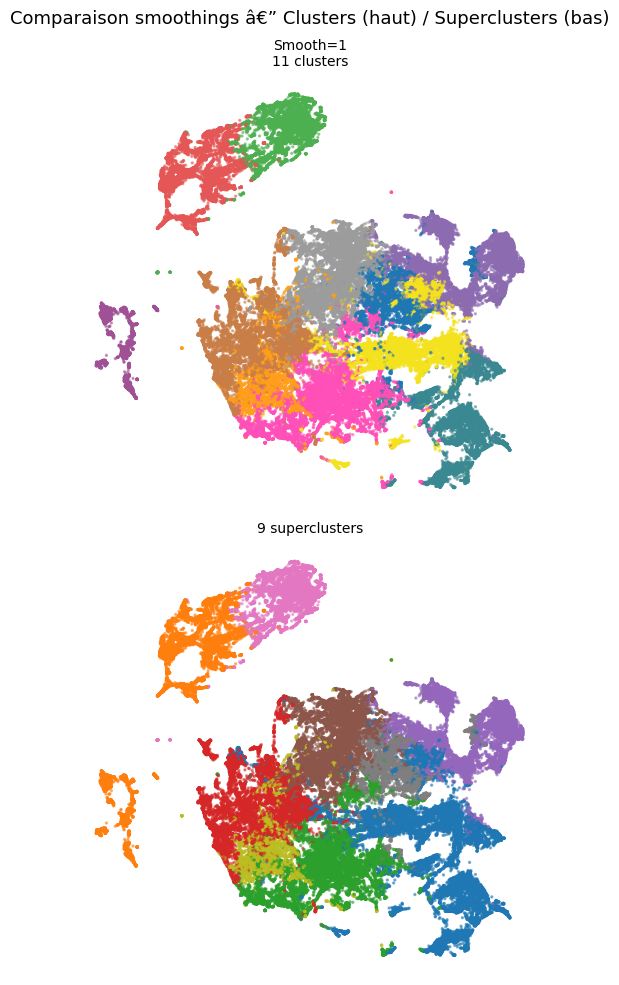

In [4]:
# graophiques de comparaison des smoothings

n_smooth = len(results)
fig, axes = plt.subplots(2, n_smooth, figsize=(5 * n_smooth, 10))
if n_smooth == 1:
    axes = axes.reshape(2, 1)

for col, (window, res_w) in enumerate(sorted(results.items())):
    Z_w  = res_w["Z"]
    df_w = res_w["df"]
    n_cl = res_w["n_clusters"]
    n_su = res_w["n_superclusters"]

    norm_su = mpl.colors.BoundaryNorm(range(n_su + 1), ncolors=n_su)

    axes[0, col].scatter(Z_w[:, 0], Z_w[:, 1], c=df_w["cluster"],
                         cmap=CMAP_CLUSTER, norm=NORM_CLUSTER, s=2, alpha=0.5)
    axes[0, col].set_title(f"Smooth={window}\n{n_cl} clusters", fontsize=10)
    axes[0, col].axis("off")

    axes[1, col].scatter(Z_w[:, 0], Z_w[:, 1], c=df_w["supercluster"],
                         cmap="tab10", norm=norm_su, s=2, alpha=0.5)
    axes[1, col].set_title(f"{n_su} superclusters", fontsize=10)
    axes[1, col].axis("off")

fig.suptitle("Comparaison smoothings â€” Clusters (haut) / Superclusters (bas)", fontsize=13)
plt.tight_layout()
plt.savefig(OUT_DIR / "comparison_smoothings.png", dpi=150, bbox_inches="tight")
plt.show()

In [5]:
SELECTED_WINDOW = 1

[OK] X calculé : (95772, 6) | calcul UMAP...


c:\Users\nonoh\anaconda3\envs\cuttlestrike\Lib\site-packages\umap\umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


[OK] UMAP calculée


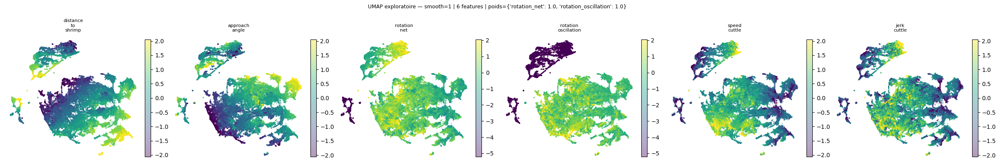


Pour reproduire l'UMAP du pipeline :
  FEATURES_EXPLORE = FEATURES = ['distance_to_shrimp', 'approach_angle', 'speed_cuttle', 'rotation_net', 'rotation_oscillation', 'jerk_cuttle']
  WEIGHTS_EXPLORE  = FEATURE_WEIGHTS = {'jerk_cuttle': 1.0, 'rotation_net': 1.0, 'rotation_oscillation': 1.0}


In [7]:
# ── UMAP exploratoire — change FEATURES_EXPLORE pour tester ──
# Utilise le même pipeline que run_leiden (StandardScaler + poids)
# pour que les UMAPs soient comparables

SMOOTH_EXPLORE   = 1
FEATURES_EXPLORE = [          # ← change ici pour explorer
    "distance_to_shrimp",
    "approach_angle",
    "rotation_net", 
    "rotation_oscillation",
    "speed_cuttle",
    #"accel_cuttle",
    "jerk_cuttle",           # ← commenter/décommenter pour tester
    # "head_turn",
    # "eye_convergence",
]
WEIGHTS_EXPLORE = {            # ← même logique que FEATURE_WEIGHTS
    "rotation_net":          1.0,
    "rotation_oscillation":  1.0,
}

# ── Calcul ────────────────────────────────────────────────────
df_exp = results[SMOOTH_EXPLORE]["df"].copy()

X_raw = df_exp[FEATURES_EXPLORE].values.copy().astype(float)
X_exp = StandardScaler().fit_transform(X_raw)

# Poids après StandardScaler — même logique que run_leiden
for i, feat in enumerate(FEATURES_EXPLORE):
    w = WEIGHTS_EXPLORE.get(feat, 1.0)
    if w != 1.0:
        X_exp[:, i] *= w
        print(f"  [WEIGHT] {feat} × {w}")

print(f"[OK] X calculé : {X_exp.shape} | calcul UMAP...")
Z_exp = run_umap(X_exp)
print(f"[OK] UMAP calculée")

# ── Plot ──────────────────────────────────────────────────────
n_feats = len(FEATURES_EXPLORE)
fig, axes = plt.subplots(1, n_feats, figsize=(4 * n_feats, 4))
if n_feats == 1: axes = [axes]

for ax, feat in zip(axes, FEATURES_EXPLORE):
    vals = df_exp[feat].values
    sc   = ax.scatter(Z_exp[:, 0], Z_exp[:, 1],
                      c=vals, cmap="viridis",
                      s=1, alpha=0.4,
                      vmin=np.percentile(vals, 2),
                      vmax=np.percentile(vals, 98))
    plt.colorbar(sc, ax=ax, fraction=0.04, pad=0.02)
    ax.set_title(feat.replace("_", "\n"), fontsize=8)
    ax.axis("off")

fig.suptitle(
    f"UMAP exploratoire — smooth={SMOOTH_EXPLORE} | "
    f"{len(FEATURES_EXPLORE)} features | poids={WEIGHTS_EXPLORE}",
    fontsize=9)
plt.tight_layout()
plt.show()

# ── Vérification : si FEATURES_EXPLORE == FEATURES
#    et WEIGHTS_EXPLORE == FEATURE_WEIGHTS
#    → UMAP identique à celle du pipeline
print(f"\nPour reproduire l'UMAP du pipeline :")
print(f"  FEATURES_EXPLORE = FEATURES = {FEATURES}")
print(f"  WEIGHTS_EXPLORE  = FEATURE_WEIGHTS = {FEATURE_WEIGHTS}")

[DONNÉES] smooth=1 | 95772 lignes | 11 clusters | 9 superclusters | Z (95772, 2)
  cluster       : 11 labels présents — OK
  supercluster  : 9 labels présents — OK
[COULEURS] + 202 individus enregistrés dans le référentiel.


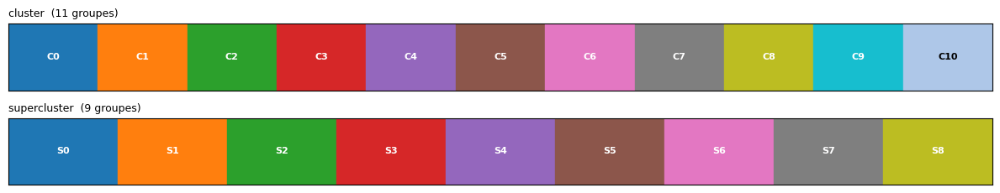

[COULEURS] 11 clusters, 9 superclusters — référentiel unique installé.


In [8]:
# ===============================================================
#  CELLULE 0 — RÉFÉRENTIEL COULEURS (source unique de vérité)
#  À exécuter AVANT tous les plots.
# ===============================================================
import numpy as np
import matplotlib as mpl
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors
from matplotlib.lines import Line2D
from matplotlib.patches import Patch

# ===============================================================
#  CELLULE A — Extraction des résultats de la fenêtre sélectionnée
#  ⚠ DOIT s'exécuter AVANT la CELLULE 0 (qui a besoin de n_clusters)
# ===============================================================
import numpy as np
import pandas as pd
import matplotlib as mpl
import matplotlib.pyplot as plt

df              = results[SELECTED_WINDOW]["df"].copy()
X_scaled        = results[SELECTED_WINDOW]["X"]
Z               = results[SELECTED_WINDOW]["Z"]
n_clusters      = results[SELECTED_WINDOW]["n_clusters"]
n_superclusters = results[SELECTED_WINDOW]["n_superclusters"]

print(f"[DONNÉES] smooth={SELECTED_WINDOW} | {len(df)} lignes | "
      f"{n_clusters} clusters | {n_superclusters} superclusters | "
      f"Z {Z.shape}")

# Contrôle : les labels doivent couvrir 0..n-1 sans trou, sinon les
# couleurs (indexées par label) et les compteurs se décalent.
for col, n in [("cluster", n_clusters), ("supercluster", n_superclusters)]:
    if col in df.columns:
        vus = sorted(pd.to_numeric(df[col], errors="coerce").dropna().unique().astype(int))
        manque = sorted(set(range(n)) - set(vus))
        extra  = sorted(set(vus) - set(range(n)))
        etat = "OK" if not (manque or extra) else f"manquants={manque} hors_plage={extra}"
        print(f"  {col:<13} : {len(vus)} labels présents — {etat}")

def build_color_registry(n_clusters, n_superclusters):
    """
    Construit UNE table de couleurs, puis en dérive tout le reste
    (cmap, norm, liste hex). Impossible que les deux divergent :
    la cmap est littéralement fabriquée à partir de la liste.
    """
    # 20 couleurs bien séparées : les 10 de tab10 en premier
    # (les plus distinctes), puis les 10 variantes claires de tab20.
    tab10 = [mcolors.to_hex(plt.get_cmap("tab10")(i)) for i in range(10)]
    tab20 = plt.get_cmap("tab20")
    clairs = [mcolors.to_hex(tab20(i)) for i in range(1, 20, 2)]
    BASE = tab10 + clairs                      # 20 couleurs, ordre optimal

    def _liste(n):
        return [BASE[i % len(BASE)] for i in range(max(1, int(n)))]

    def _cmap_norm(colors):
        cmap = mcolors.ListedColormap(colors)
        # bornes à -0.5, 0.5, 1.5… -> chaque entier tombe au CENTRE de sa case
        norm = mcolors.BoundaryNorm(np.arange(len(colors) + 1) - 0.5,
                                    ncolors=len(colors))
        return cmap, norm

    reg = {}
    for key, n, pfx in [("cluster", n_clusters, "C"),
                        ("supercluster", n_superclusters, "S")]:
        cols = _liste(n)
        cmap, norm = _cmap_norm(cols)
        reg[key] = {"colors": cols, "cmap": cmap, "norm": norm, "prefix": pfx}
    return reg


COLOR_REG = build_color_registry(n_clusters, n_superclusters)

# ── Alias rétro-compatibles : ton ancien code continue de marcher ────────
CMAP_CLUSTER = COLOR_REG["cluster"]["cmap"]
NORM_CLUSTER = COLOR_REG["cluster"]["norm"]
CMAP_SUPER   = COLOR_REG["supercluster"]["cmap"]
NORM_SUPER   = COLOR_REG["supercluster"]["norm"]
PALETTE      = COLOR_REG["cluster"]["colors"]        # utilisé par le viewer
SUPER_PAL    = COLOR_REG["supercluster"]["colors"]   # utilisé par le viewer


# ── LES 4 SEULES FONCTIONS À UTILISER DANS LES PLOTS ────────────────────
def group_color(label, group_col="cluster"):
    """Couleur hex d'un label. À utiliser PARTOUT, sans exception."""
    d = COLOR_REG[group_col]
    return d["colors"][int(label) % len(d["colors"])]


def group_prefix(group_col="cluster"):
    return COLOR_REG[group_col]["prefix"]


def group_cmap_norm(group_col="cluster"):
    d = COLOR_REG[group_col]
    return d["cmap"], d["norm"]


def group_handles(labels, group_col="cluster", lw=3, style="line"):
    """Handles prêts à passer à ax.legend(handles=...)."""
    uniq = sorted({int(x) for x in np.asarray(labels).ravel()})
    pfx  = group_prefix(group_col)
    if style == "patch":
        return [Patch(color=group_color(l, group_col), label=f"{pfx}{l}") for l in uniq]
    return [Line2D([0], [0], color=group_color(l, group_col), lw=lw, label=f"{pfx}{l}")
            for l in uniq]


def apercu_couleurs():
    """Nuancier de contrôle : à regarder une fois pour valider visuellement."""
    fig, axes = plt.subplots(2, 1, figsize=(12, 2.4))
    for ax, key in zip(axes, ["cluster", "supercluster"]):
        cols = COLOR_REG[key]["colors"]
        for i, c in enumerate(cols):
            ax.add_patch(mpl.patches.Rectangle((i, 0), 1, 1, color=c))
            ax.text(i + 0.5, 0.5, f"{COLOR_REG[key]['prefix']}{i}",
                    ha="center", va="center", fontsize=8,
                    color="white" if i % 20 < 10 else "black", fontweight="bold")
        ax.set_xlim(0, len(cols)); ax.set_ylim(0, 1)
        ax.set_yticks([]); ax.set_xticks([])
        ax.set_title(f"{key}  ({len(cols)} groupes)", fontsize=9, loc="left")
    plt.tight_layout(); plt.show()

def build_animal_colors(animal_ids, cmap_name="hsv"):
    """
    Couleur stable par individu. Le tri garantit que la couleur d'un
    animal ne dépend PAS de l'ordre dans lequel les IDs arrivent :
    même résultat d'une exécution à l'autre.
    """
    ids = sorted({str(a).strip() for a in animal_ids}, key=cle_naturelle)
    cm  = plt.get_cmap(cmap_name)
    COLOR_REG["animal"] = {
        "colors": {a: mcolors.to_hex(cm(i / max(1, len(ids))))
                   for i, a in enumerate(ids)},
        "prefix": "",
    }
    return COLOR_REG["animal"]["colors"]


def animal_color(aid):
    """Couleur d'un individu — tolère str/int/zéros de tête."""
    return COLOR_REG.get("animal", {}).get("colors", {}) \
                    .get(str(aid).strip(), "#888888")


def text_on(bg_color):
    """
    Noir ou blanc selon la luminance perçue du fond (ITU-R BT.601).
    Évite le texte blanc illisible sur les teintes claires de tab20.
    """
    r, g, b = mcolors.to_rgb(bg_color)
    return "black" if (0.299 * r + 0.587 * g + 0.114 * b) > 0.55 else "white"


def resolve_animal_id(df, raw, id_col="animal_id"):
    """
    Saisie -> valeur EXACTE présente dans df[id_col].
    Centralisé ici car utilisé par le viewer, la trajectoire ET l'UMAP.
    """
    vals = df[id_col].dropna().unique()
    s    = str(raw).strip()
    for v in vals:
        if str(v).strip() == s:
            return v
    try:
        num = float(s)
        for v in vals:
            try:
                if float(str(v).strip()) == num:
                    return v
            except ValueError:
                pass
    except ValueError:
        pass
    return None


def cle_naturelle(a):
    """
    Trie 2 avant 10 (et pas l'inverse), tolère les IDs textuels.
    Le tuple évite le TypeError sur des types mixtes : les numériques
    passent d'abord (rang 0), les autres ensuite par ordre alphabétique.
    """
    s = str(a).strip()
    try:
        return (0, float(s), "")
    except ValueError:
        return (1, 0.0, s)


build_animal_colors(df["animal_id"].dropna().unique())
animal_ids = sorted(df["animal_id"].dropna().unique(), key=cle_naturelle)
n_animals  = len(animal_ids)
animal_colors_per_point = df["animal_id"].map(animal_color).to_numpy()
print(f"[COULEURS] + {n_animals} individus enregistrés dans le référentiel.")

apercu_couleurs()
print(f"[COULEURS] {n_clusters} clusters, {n_superclusters} superclusters — "
      f"référentiel unique installé.")

In [9]:
SELECTED_WINDOW = 1

In [10]:
# ===============================================================
#  CELLULE B — Analyse des groupes : radars, heatmap, dendrogramme
#  PRÉREQUIS : CELLULE A puis CELLULE 0 (référentiel couleurs).
#
#  Corrections vs version précédente :
#   [A] tab10 codé en dur -> group_cmap_norm() (S1 n'était pas de la
#       même couleur ici et dans l'UMAP)
#   [B] BoundaryNorm construite sur len(unique_g) -> décalage des
#       couleurs si un groupe est vide. Le référentiel indexe par LABEL.
#   [C] titres de radar assombris : les teintes claires étaient
#       illisibles sur fond blanc
#   [D] dendrogramme et heatmap : étiquettes colorées par groupe
#   [E] radar superposé (comparaison directe de tous les groupes)
#   [F] garde-fous : <2 groupes, features absentes, feature constante
# ===============================================================

import seaborn as sns
import matplotlib.colors as mcolors
from matplotlib.lines import Line2D
from scipy.spatial.distance import pdist, squareform
from scipy.cluster.hierarchy import dendrogram, linkage


def _fonce(couleur, f=0.62):
    """
    Assombrit une couleur pour l'écrire en texte sur fond blanc.
    Les variantes claires de tab20 (#aec7e8, #ffbb78…) sont illisibles
    telles quelles ; on multiplie les canaux RGB par f < 1.
    """
    r, g, b = mcolors.to_rgb(couleur)
    return mcolors.to_hex((r * f, g * f, b * f))


def _colorer_ticks(ax, labels_ordonnes, group_col, axis="x"):
    """
    Colorie les étiquettes d'axe selon le groupe qu'elles désignent.
    labels_ordonnes : liste de textes déjà posés sur l'axe, ex ["C3","C0",…]
    """
    pfx    = group_prefix(group_col)
    getter = ax.get_xticklabels if axis == "x" else ax.get_yticklabels
    for tick in getter():
        txt = tick.get_text().strip()
        if not txt.startswith(pfx):
            continue
        try:
            g = int(txt[len(pfx):])
        except ValueError:
            continue
        tick.set_color(_fonce(group_color(g, group_col), 0.75))
        tick.set_fontweight("bold")


def plot_cluster_analysis(df, features, group_col="cluster", n_cols_radar=4,
                          save=True):
    """
    Pour un groupe donné (cluster ou supercluster) :
      1. Radars individuels + radar superposé
      2. Heatmap des distances inter-groupes (profils normalisés min-max)
      3. Dendrogramme hiérarchique

    Toutes les couleurs viennent de group_color() : identiques à
    plot_umap, plot_animal_trajectory et au viewer interactif.
    """
    if "group_color" not in globals():
        raise RuntimeError("Exécute d'abord la CELLULE 0 (référentiel couleurs).")
    if group_col not in df.columns:
        raise KeyError(f"Colonne '{group_col}' absente de df.")

    # [F] on ne garde que les features réellement présentes et numériques
    feats = [f for f in features
             if f in df.columns and pd.api.types.is_numeric_dtype(df[f])]
    if not feats:
        raise ValueError("Aucune feature numérique exploitable.")
    if len(feats) < len(features):
        print(f"[WARN] features ignorées : {sorted(set(features) - set(feats))}")

    grp      = pd.to_numeric(df[group_col], errors="coerce")
    dat      = df.loc[grp.notna()].copy()
    dat[group_col] = grp.dropna().astype(int)

    mean_g   = dat.groupby(group_col)[feats].mean()
    counts_g = dat[group_col].value_counts().sort_index()
    unique_g = mean_g.index.to_numpy()
    pfx      = group_prefix(group_col)

    if len(unique_g) == 0:
        print("[WARN] aucun groupe.")
        return None, None

    # ── Normalisation min-max PAR FEATURE, à travers les groupes ───────
    # Objectif : rendre les axes du radar comparables entre eux. Une
    # feature constante d'un groupe à l'autre est mise à 0.5 (au centre)
    # plutôt qu'à 0, ce qui serait interprété comme "valeur minimale".
    g_min = mean_g.min(axis=0)
    g_max = mean_g.max(axis=0)
    etendue = (g_max - g_min)
    mean_g_norm = mean_g.copy()
    for f in feats:
        mean_g_norm[f] = (0.5 if etendue[f] <= 0
                          else (mean_g[f] - g_min[f]) / etendue[f])

    # [A][B] couleurs : indexées par LABEL, jamais par position
    cols_g = {int(c): group_color(int(c), group_col) for c in unique_g}

    angles   = np.linspace(0, 2 * np.pi, len(feats), endpoint=False)
    ang_full = np.concatenate([angles, [angles[0]]])
    etiq_ax  = [f.replace("_", "\n") for f in feats]

    # ══ FIGURE 1 — radars individuels ══════════════════════════════════
    n_cols = min(n_cols_radar, len(unique_g))
    n_rows = int(np.ceil(len(unique_g) / n_cols))
    fig1   = plt.figure(figsize=(n_cols * 4, n_rows * 4.2))

    for i, c in enumerate(unique_g):
        c   = int(c)
        ax  = fig1.add_subplot(n_rows, n_cols, i + 1, polar=True)
        v   = mean_g_norm.loc[c].to_numpy()
        vals = np.concatenate([v, [v[0]]])
        col  = cols_g[c]

        ax.plot(ang_full, vals, linewidth=2.2, color=col, zorder=3)
        ax.fill(ang_full, vals, alpha=0.28, color=col, zorder=2)
        # Silhouette grise de la moyenne générale, pour situer le groupe
        ref = mean_g_norm.mean(axis=0).to_numpy()
        ax.plot(ang_full, np.concatenate([ref, [ref[0]]]),
                lw=1, ls="--", color="#999999", alpha=0.8, zorder=1)

        ax.set_xticks(angles)
        ax.set_xticklabels(etiq_ax, fontsize=7)
        ax.set_ylim(0, 1)
        ax.set_yticks([0.25, 0.5, 0.75])
        ax.set_yticklabels([], fontsize=6)
        ax.grid(color="#dddddd", lw=0.6)
        ax.set_title(f"{pfx}{c}  (n={counts_g.get(c, 0)})",
                     fontsize=11, pad=14,
                     color=_fonce(col), fontweight="bold")   # [C]

    fig1.suptitle(f"Profils radar — {group_col} (smooth={SELECTED_WINDOW})\n"
                  f"min-max par feature entre groupes · pointillé = moyenne générale",
                  fontsize=12, y=1.005)
    plt.tight_layout()
    if save:
        plt.savefig(OUT_DIR / f"radar_smooth{SELECTED_WINDOW}_{group_col}.png",
                    dpi=150, bbox_inches="tight")
    plt.show()

    # ══ FIGURE 2 — [E] radar superposé + effectifs ═════════════════════
    fig2 = plt.figure(figsize=(13, 5.6))
    axr  = fig2.add_subplot(1, 2, 1, polar=True)
    for c in unique_g:
        c = int(c)
        v = mean_g_norm.loc[c].to_numpy()
        axr.plot(ang_full, np.concatenate([v, [v[0]]]),
                 lw=2, color=cols_g[c], label=f"{pfx}{c}", alpha=0.9)
    axr.set_xticks(angles); axr.set_xticklabels(etiq_ax, fontsize=7)
    axr.set_ylim(0, 1); axr.set_yticklabels([])
    axr.grid(color="#dddddd", lw=0.6)
    axr.set_title("Superposition des profils", fontsize=11, pad=16)
    axr.legend(loc="upper right", bbox_to_anchor=(1.28, 1.10),
               fontsize=7, ncol=1 if len(unique_g) <= 10 else 2,
               frameon=True, framealpha=0.9)

    axb = fig2.add_subplot(1, 2, 2)
    labs_g = [f"{pfx}{int(c)}" for c in unique_g]
    vals_n = [counts_g.get(int(c), 0) for c in unique_g]
    axb.bar(labs_g, vals_n, color=[cols_g[int(c)] for c in unique_g],
            edgecolor="black", linewidth=0.5)
    for x, v in zip(labs_g, vals_n):
        axb.text(x, v, f"{v}", ha="center", va="bottom", fontsize=7)
    axb.set_ylabel("nombre de frames"); axb.set_title("Effectifs", fontsize=11)
    axb.tick_params(axis="x", labelrotation=45)
    _colorer_ticks(axb, labs_g, group_col, axis="x")           # [D]
    for sp in ("top", "right"):
        axb.spines[sp].set_visible(False)

    fig2.suptitle(f"Comparaison des {group_col}s (smooth={SELECTED_WINDOW})",
                  fontsize=12)
    plt.tight_layout()
    if save:
        plt.savefig(OUT_DIR / f"overlay_smooth{SELECTED_WINDOW}_{group_col}.png",
                    dpi=150, bbox_inches="tight")
    plt.show()

    # ══ FIGURE 3 — heatmap + dendrogramme ══════════════════════════════
    labels = [f"{pfx}{int(c)}" for c in unique_g]

    if len(unique_g) < 2:
        print("[INFO] moins de 2 groupes : heatmap/dendrogramme non calculables.")
        return mean_g, mean_g_norm                              # [F]

    D_mat = squareform(pdist(mean_g_norm.to_numpy()))
    Z_lnk = linkage(mean_g_norm.to_numpy(), method="ward")

    fig3, axes = plt.subplots(1, 2, figsize=(15, 5.5))

    sns.heatmap(D_mat, cmap="viridis", ax=axes[0], square=True,
                xticklabels=labels, yticklabels=labels,
                annot=len(unique_g) <= 15, fmt=".2f",
                annot_kws={"fontsize": 6},
                cbar_kws={"label": "distance euclidienne", "shrink": 0.8})
    axes[0].set_title(f"Distance entre profils de {group_col}s", fontsize=11)
    _colorer_ticks(axes[0], labels, group_col, axis="x")        # [D]
    _colorer_ticks(axes[0], labels, group_col, axis="y")

    # color_threshold=0 -> on neutralise le coloriage automatique de scipy
    # (qui code les sous-arbres, pas les groupes) pour ne garder QUE notre
    # code couleur, porté par les étiquettes de feuilles.
    dendrogram(Z_lnk, ax=axes[1], labels=labels, leaf_rotation=45,
               color_threshold=0, above_threshold_color="#999999")
    axes[1].set_title(f"Dendrogramme hiérarchique (Ward)", fontsize=11)
    axes[1].set_ylabel("distance de fusion")
    _colorer_ticks(axes[1], labels, group_col, axis="x")        # [D]
    for sp in ("top", "right"):
        axes[1].spines[sp].set_visible(False)

    # Pastilles de rappel sous les feuilles
    axes[1].legend(handles=[Line2D([0], [0], marker="s", color="none",
                                   markerfacecolor=cols_g[int(c)],
                                   markeredgecolor="black", markersize=7,
                                   label=f"{pfx}{int(c)}")
                            for c in unique_g],
                   fontsize=6, ncol=max(1, len(unique_g) // 8),
                   loc="upper right", framealpha=0.9, title=group_col,
                   title_fontsize=7)

    plt.suptitle(f"Structure des {group_col}s (smooth={SELECTED_WINDOW})",
                 fontsize=12)
    plt.tight_layout()
    if save:
        plt.savefig(OUT_DIR / f"dist_dendro_smooth{SELECTED_WINDOW}_{group_col}.png",
                    dpi=150, bbox_inches="tight")
    plt.show()

    # ── Résumé terminal ────────────────────────────────────────────────
    print(f"\n{group_col} — {len(unique_g)} groupes, {len(feats)} features")
    plus_proches = np.unravel_index(
        np.argmin(D_mat + np.eye(len(D_mat)) * D_mat.max() * 2), D_mat.shape)
    print(f"  paire la plus proche : {labels[plus_proches[0]]} / "
          f"{labels[plus_proches[1]]}  (d={D_mat[plus_proches]:.3f})")
    plus_loin = np.unravel_index(np.argmax(D_mat), D_mat.shape)
    print(f"  paire la plus loin   : {labels[plus_loin[0]]} / "
          f"{labels[plus_loin[1]]}  (d={D_mat[plus_loin]:.3f})")

    return mean_g, mean_g_norm


print("[OK] plot_cluster_analysis définie — usage :")
print("     mean_c, mean_c_n = plot_cluster_analysis(df, FEATURES, 'cluster')")
print("     mean_s, mean_s_n = plot_cluster_analysis(df, FEATURES, 'supercluster')")

[OK] plot_cluster_analysis définie — usage :
     mean_c, mean_c_n = plot_cluster_analysis(df, FEATURES, 'cluster')
     mean_s, mean_s_n = plot_cluster_analysis(df, FEATURES, 'supercluster')


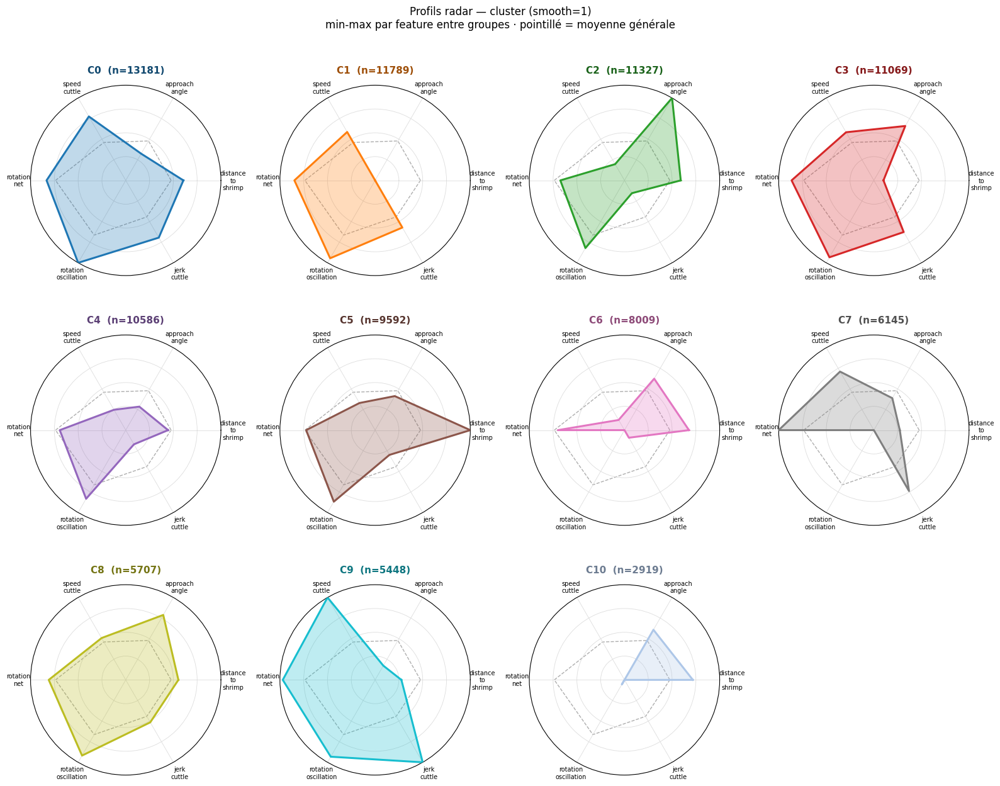

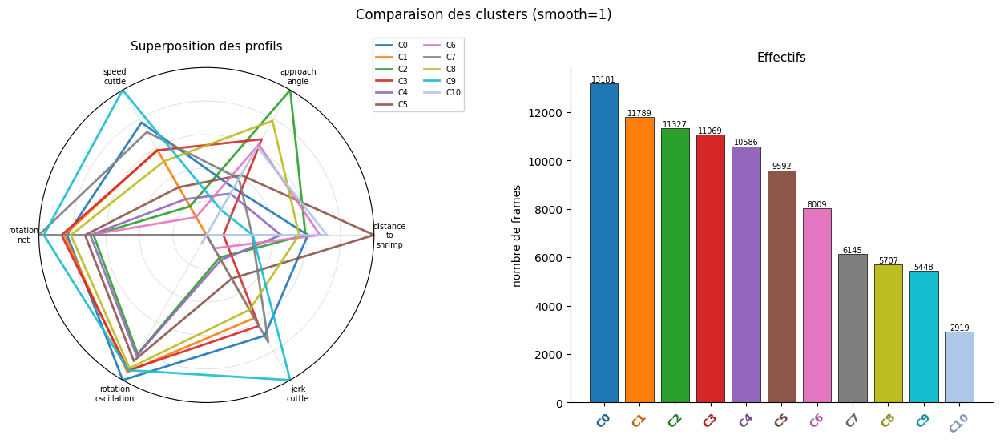

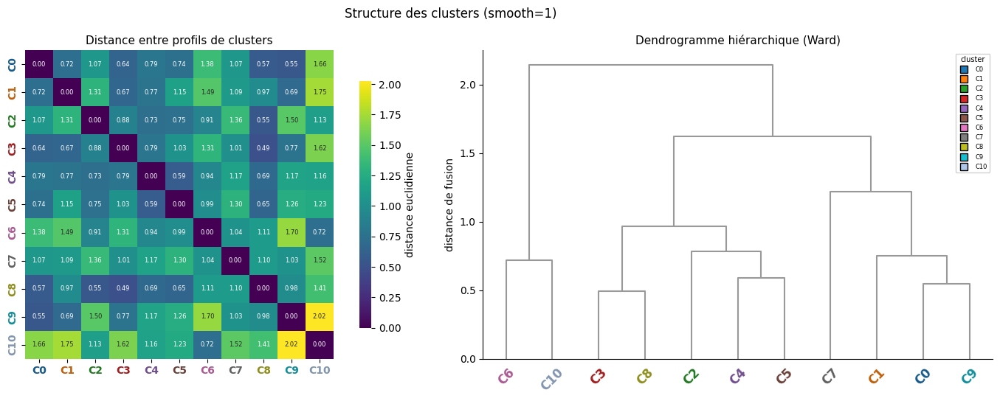


cluster — 11 groupes, 6 features
  paire la plus proche : C3 / C8  (d=0.492)
  paire la plus loin   : C9 / C10  (d=2.024)


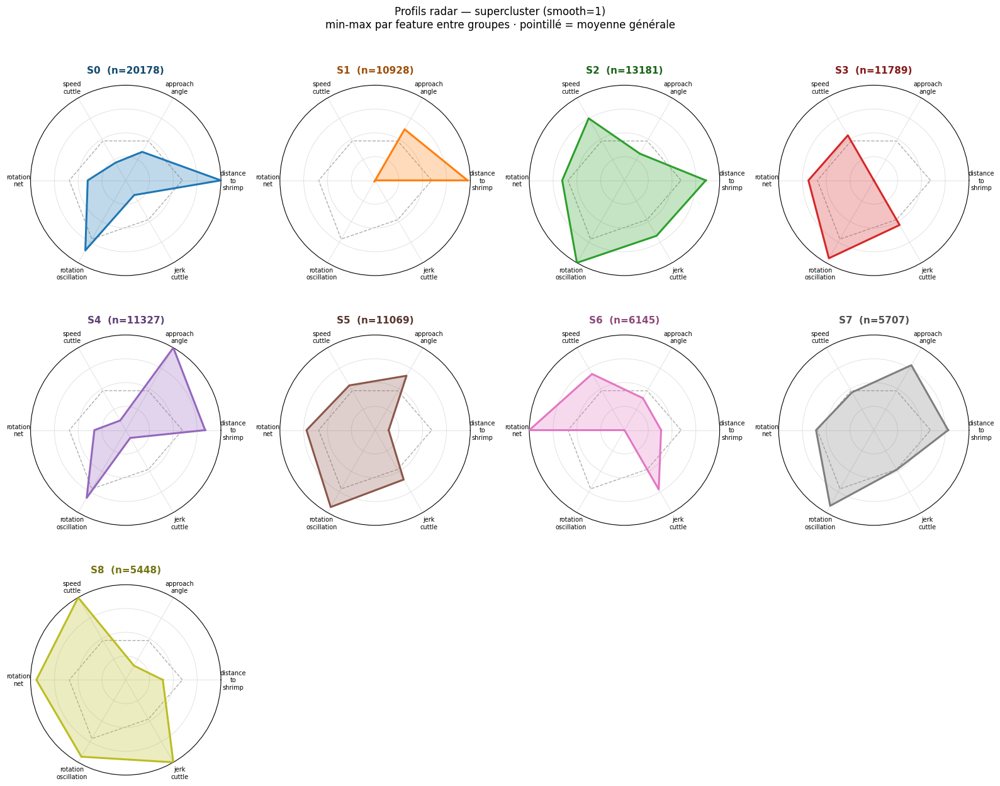

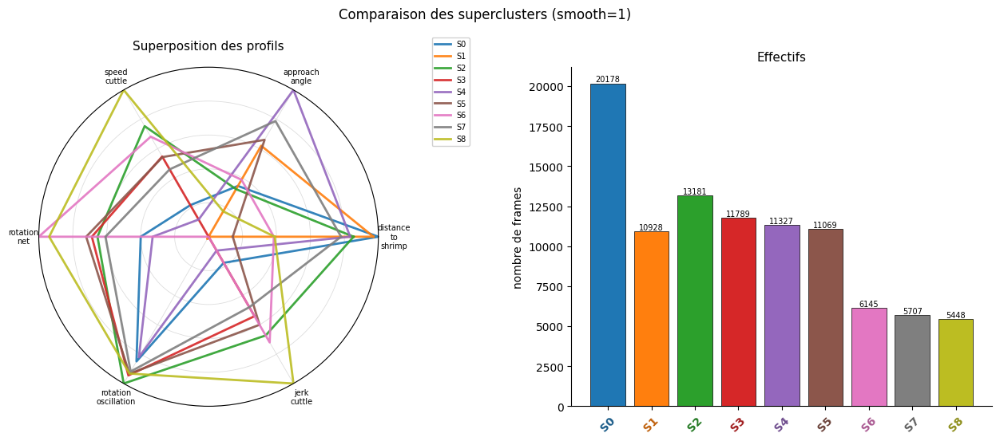

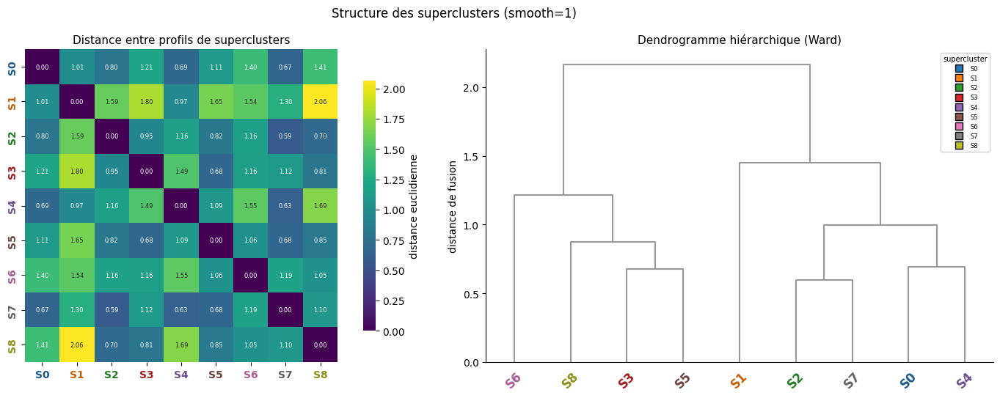


supercluster — 9 groupes, 6 features
  paire la plus proche : S2 / S7  (d=0.594)
  paire la plus loin   : S1 / S8  (d=2.064)


In [11]:
#plot cluster fenetres

import os
import seaborn as sns
from scipy.spatial.distance import pdist, squareform
from scipy.cluster.hierarchy import dendrogram, linkage

# ── Appel ──────────────────────────────────────────────────────
%matplotlib inline

plot_cluster_analysis(df, FEATURES, "cluster")
plot_cluster_analysis(df, FEATURES, "supercluster")

# Ouvrir en grand dans la visionneuse Windows
os.startfile(str(OUT_DIR / f"radar_smooth{SELECTED_WINDOW}_cluster.png"))
os.startfile(str(OUT_DIR / f"radar_smooth{SELECTED_WINDOW}_supercluster.png"))

In [12]:

df              = results[SELECTED_WINDOW]["df"].copy()
X_scaled        = results[SELECTED_WINDOW]["X"]
Z               = results[SELECTED_WINDOW]["Z"]
n_clusters      = results[SELECTED_WINDOW]["n_clusters"]
n_superclusters = results[SELECTED_WINDOW]["n_superclusters"]

animal_ids  = sorted(df["animal_id"].unique())
n_animals   = len(animal_ids)
id_to_idx   = {aid: i for i, aid in enumerate(animal_ids)}

def animal_color(aid):
    return plt.cm.hsv(id_to_idx[aid] / n_animals)

animal_colors_per_point = [animal_color(aid) for aid in df["animal_id"]]

norm_cl = NORM_CLUSTER
norm_su = mpl.colors.BoundaryNorm(range(n_superclusters + 1), ncolors=n_superclusters)

print(f"[OK] Smoothing={SELECTED_WINDOW} | {n_clusters} clusters | {n_superclusters} superclusters")
print(f"     {n_animals} individus | {len(df)} frames")

[OK] Smoothing=1 | 11 clusters | 9 superclusters
     202 individus | 95772 frames


In [13]:
# ===============================================================
#  CELLULE — UMAP  (couleurs unifiées + légendes non écrasées)
#  PRÉREQUIS : CELLULE 0 (référentiel couleurs).
#
#  Correctifs vs version précédente :
#   [A] supercluster : tab20 -> référentiel (S1 était orange dans le
#       radar et bleu clair ici)
#   [B] animal_color vient du référentiel, plus d'une source externe
#   [C] les deux légendes coexistent (add_artist) au lieu de s'écraser
#   [D] marqueur "fin" rouge, plus blanc-sur-blanc invisible
#   [E] highlight_animal résolu par ID (str/int) + masque .to_numpy()
#   [F] chemin rainbow en LineCollection (1 artiste au lieu de N)
#   [G] colorbar discrète avec labels C0/C1… au lieu d'une échelle continue
#   [H] étiquettes placées sur la MÉDIANE (robuste aux nuages en croissant)
# ===============================================================

import numpy as np
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors
import matplotlib.patches as mpatches
from matplotlib.lines import Line2D
from matplotlib.collections import LineCollection


def _colorbar_discrete(sc, ax, n, prefix, label):
    """
    Colorbar à cases discrètes, une par groupe, avec les vrais noms.
    Une colorbar continue sur des labels entiers est trompeuse :
    elle suggère un ordre/une distance entre clusters qui n'existe pas.
    """
    cb = plt.colorbar(sc, ax=ax, ticks=np.arange(n), fraction=0.046, pad=0.02)
    cb.ax.set_yticklabels([f"{prefix}{i}" for i in range(n)], fontsize=7)
    cb.set_label(label, fontsize=8)
    cb.outline.set_linewidth(0.5)
    return cb


def _annoter_groupes(ax, emb, labels, n, group_col):
    """Badge coloré au centre de chaque groupe, texte lisible garanti."""
    pfx = group_prefix(group_col)
    for c in range(n):
        m = (np.asarray(labels) == c)
        if not m.any():
            continue
        # [H] médiane, pas moyenne : le centre reste DANS le nuage même
        #     si celui-ci est allongé, coudé ou bimodal.
        cx, cy = np.median(emb[m, 0]), np.median(emb[m, 1])
        bg = group_color(c, group_col)
        ax.text(cx, cy, f"{pfx}{c}",
                fontsize=8, fontweight="bold", ha="center", va="center",
                color=text_on(bg), zorder=8,
                bbox=dict(facecolor=bg, alpha=0.88, edgecolor="black",
                          linewidth=0.5, boxstyle="round,pad=0.28"))


def plot_umap(color_by="cluster", highlight_animal=None, overlay_animal=False,
              save=True, data=None, emb=None, s=3, figsize=(11, 8.5)):
    """
    color_by         : "cluster" | "supercluster" | "animal"
    highlight_animal : animal_id à mettre en surbrillance (chemin rainbow)
    overlay_animal   : True -> clusters en fond + individus par-dessus

    Toutes les couleurs proviennent de group_color() / animal_color() :
    strictement identiques à plot_cluster_analysis, plot_animal_trajectory
    et au viewer interactif.
    """
    if "group_color" not in globals():
        raise RuntimeError("Exécute d'abord la CELLULE 0 (référentiel couleurs).")

    data = df if data is None else data      # globals par défaut
    emb  = Z  if emb  is None else emb
    emb  = np.asarray(emb)

    if len(emb) != len(data):
        raise ValueError(f"Z ({len(emb)}) et df ({len(data)}) n'ont pas la "
                         f"même longueur — l'un des deux a été filtré.")

    fig, ax = plt.subplots(figsize=figsize)
    legendes = []          # [C] on empile, on n'écrase pas

    # ══ MODE 1 — overlay : clusters en fond + individus par-dessus ═════
    if overlay_animal:
        cmap_g, norm_g = group_cmap_norm("cluster")
        ax.scatter(emb[:, 0], emb[:, 1], c=data["cluster"],
                   cmap=cmap_g, norm=norm_g, s=s, alpha=0.22, zorder=1)
        for aid in animal_ids:
            m = (data["animal_id"] == aid).to_numpy()      # [E] .to_numpy()
            if m.any():
                ax.scatter(emb[m, 0], emb[m, 1], color=animal_color(aid),
                           s=s + 2, alpha=0.75, zorder=2, linewidths=0)

        legendes.append(ax.legend(
            handles=[mpatches.Patch(color=animal_color(a), label=str(a))
                     for a in animal_ids],
            fontsize=6, ncol=4, loc="upper right", title="animal_id",
            title_fontsize=7, framealpha=0.9))
        _annoter_groupes(ax, emb, data["cluster"].to_numpy(), n_clusters, "cluster")
        ax.set_title(f"UMAP overlay — clusters + {n_animals} individus "
                     f"(smooth={SELECTED_WINDOW})")

    # ══ MODE 2 — coloré par cluster ou supercluster ════════════════════
    elif color_by in ("cluster", "supercluster"):
        n_g = n_clusters if color_by == "cluster" else n_superclusters
        cmap_g, norm_g = group_cmap_norm(color_by)         # [A] référentiel

        sc = ax.scatter(emb[:, 0], emb[:, 1], c=data[color_by],
                        cmap=cmap_g, norm=norm_g, s=s, alpha=0.6, linewidths=0)

        _annoter_groupes(ax, emb, data[color_by].to_numpy(), n_g, color_by)
        _colorbar_discrete(sc, ax, n_g, group_prefix(color_by), color_by)  # [G]
        ax.set_title(f"UMAP — {n_g} {color_by}s (smooth={SELECTED_WINDOW})")

    # ══ MODE 3 — coloré par individu ═══════════════════════════════════
    elif color_by == "animal":
        cols = data["animal_id"].map(animal_color).to_numpy()   # [B]
        ax.scatter(emb[:, 0], emb[:, 1], c=cols, s=s, alpha=0.6, linewidths=0)
        legendes.append(ax.legend(
            handles=[mpatches.Patch(color=animal_color(a), label=str(a))
                     for a in animal_ids],
            fontsize=6, ncol=4, loc="upper right", title="animal_id",
            title_fontsize=7, framealpha=0.9))
        ax.set_title(f"UMAP — {n_animals} individus (smooth={SELECTED_WINDOW})")

    else:
        raise ValueError(f"color_by='{color_by}' inconnu — attendu "
                         f"'cluster', 'supercluster' ou 'animal'.")

    # ══ SURBRILLANCE D'UN INDIVIDU ═════════════════════════════════════
    if highlight_animal is not None:
        aid_h = resolve_animal_id(data, highlight_animal)       # [E]
        if aid_h is None:
            dispo = sorted(str(a) for a in data["animal_id"].dropna().unique())
            print(f"[UMAP] animal {highlight_animal!r} introuvable — "
                  f"pas de surbrillance. Dispo : {dispo[:15]}…")
        else:
            # .to_numpy() indispensable : emb est un array NumPy indexé par
            # POSITION, alors qu'une Series pandas porte un index. Si data a
            # été filtré sans reset_index, un masque pandas prendrait
            # silencieusement les mauvaises lignes de emb.
            m_h = (data["animal_id"] == aid_h).to_numpy()
            Z_h = emb[m_h]

            if len(Z_h) > 1:
                # [F] LineCollection : 1 artiste au lieu de N appels à plot()
                pts  = Z_h.reshape(-1, 1, 2)
                segs = np.concatenate([pts[:-1], pts[1:]], axis=1)
                ax.add_collection(LineCollection(
                    segs, colors=plt.cm.rainbow(np.linspace(0, 1, len(segs))),
                    linewidths=1.6, alpha=0.9, zorder=5))

                ax.scatter(Z_h[0, 0], Z_h[0, 1], marker="o", s=110,
                           facecolor="#00e676", edgecolor="black",
                           linewidth=1.4, zorder=7)
                ax.scatter(Z_h[-1, 0], Z_h[-1, 1], marker="s", s=110,
                           facecolor="#ff1744", edgecolor="black",   # [D]
                           linewidth=1.4, zorder=7)

                # [C] on épingle les légendes déjà posées avant d'en créer
                #     une nouvelle — sinon ax.legend() les remplace.
                for lg in legendes:
                    ax.add_artist(lg)
                ax.legend(handles=[
                    Line2D([0], [0], marker="o", color="none",
                           markerfacecolor="#00e676", markeredgecolor="black",
                           markersize=9, label="début"),
                    Line2D([0], [0], marker="s", color="none",
                           markerfacecolor="#ff1744", markeredgecolor="black",
                           markersize=9, label="fin"),
                    Line2D([0], [0], color="#b070d0", lw=2,
                           label="chemin (temps →)"),
                ], fontsize=8, loc="lower left", framealpha=0.9,
                   title=f"Animal {aid_h}", title_fontsize=8)

                ax.set_title(f"{ax.get_title()}\n→ Animal {aid_h} "
                             f"({len(Z_h)} frames)")
            else:
                print(f"[UMAP] animal {aid_h!r} : {len(Z_h)} point(s), "
                      f"chemin non traçable.")

    ax.set_xticks([]); ax.set_yticks([])
    for sp in ax.spines.values():
        sp.set_edgecolor("#cccccc")
    ax.set_xlabel("UMAP-1", fontsize=8); ax.set_ylabel("UMAP-2", fontsize=8)

    plt.tight_layout()

    if save:
        suffix = "_overlay" if overlay_animal else f"_{color_by}"
        if highlight_animal is not None:
            suffix += f"_animal{highlight_animal}"
        plt.savefig(OUT_DIR / f"umap_smooth{SELECTED_WINDOW}{suffix}.png",
                    dpi=150, bbox_inches="tight")
    plt.show()
    return fig, ax


# ═══════════════════════════════════════════════════════════════
#  TEST DE NON-RÉGRESSION COULEURS
# ═══════════════════════════════════════════════════════════════
def verifier_coherence_couleurs():
    """
    Compare la couleur que CHAQUE fonction attribuerait au même label.
    Si une ligne affiche DIVERGENT, une fonction contourne group_color().
    """
    print("=" * 58)
    print("COHÉRENCE DES COULEURS ENTRE GRAPHES")
    print("=" * 58)
    ok_global = True
    for gc, n in [("cluster", n_clusters), ("supercluster", n_superclusters)]:
        cmap_g, norm_g = group_cmap_norm(gc)
        print(f"\n{gc} :")
        for l in range(n):
            ref      = group_color(l, gc)                       # référence
            via_cmap = mcolors.to_hex(cmap_g(norm_g(l)))        # scatter/UMAP
            etat     = "OK" if ref == via_cmap else "DIVERGENT"
            ok_global &= (ref == via_cmap)
            print(f"  {group_prefix(gc)}{l:<3} {ref}  cmap(norm)={via_cmap}  {etat}")
    print("\n" + ("Tout est cohérent." if ok_global
                  else "⚠ Divergence détectée — vérifie la CELLULE 0."))
    print("=" * 58)


verifier_coherence_couleurs()
print("\n[OK] plot_umap définie — usage :")
print("     plot_umap('cluster')")
print("     plot_umap('supercluster', highlight_animal=12)")
print("     plot_umap(overlay_animal=True)")

COHÉRENCE DES COULEURS ENTRE GRAPHES

cluster :
  C0   #1f77b4  cmap(norm)=#1f77b4  OK
  C1   #ff7f0e  cmap(norm)=#ff7f0e  OK
  C2   #2ca02c  cmap(norm)=#2ca02c  OK
  C3   #d62728  cmap(norm)=#d62728  OK
  C4   #9467bd  cmap(norm)=#9467bd  OK
  C5   #8c564b  cmap(norm)=#8c564b  OK
  C6   #e377c2  cmap(norm)=#e377c2  OK
  C7   #7f7f7f  cmap(norm)=#7f7f7f  OK
  C8   #bcbd22  cmap(norm)=#bcbd22  OK
  C9   #17becf  cmap(norm)=#17becf  OK
  C10  #aec7e8  cmap(norm)=#aec7e8  OK

supercluster :
  S0   #1f77b4  cmap(norm)=#1f77b4  OK
  S1   #ff7f0e  cmap(norm)=#ff7f0e  OK
  S2   #2ca02c  cmap(norm)=#2ca02c  OK
  S3   #d62728  cmap(norm)=#d62728  OK
  S4   #9467bd  cmap(norm)=#9467bd  OK
  S5   #8c564b  cmap(norm)=#8c564b  OK
  S6   #e377c2  cmap(norm)=#e377c2  OK
  S7   #7f7f7f  cmap(norm)=#7f7f7f  OK
  S8   #bcbd22  cmap(norm)=#bcbd22  OK

Tout est cohérent.

[OK] plot_umap définie — usage :
     plot_umap('cluster')
     plot_umap('supercluster', highlight_animal=12)
     plot_umap(overlay_a

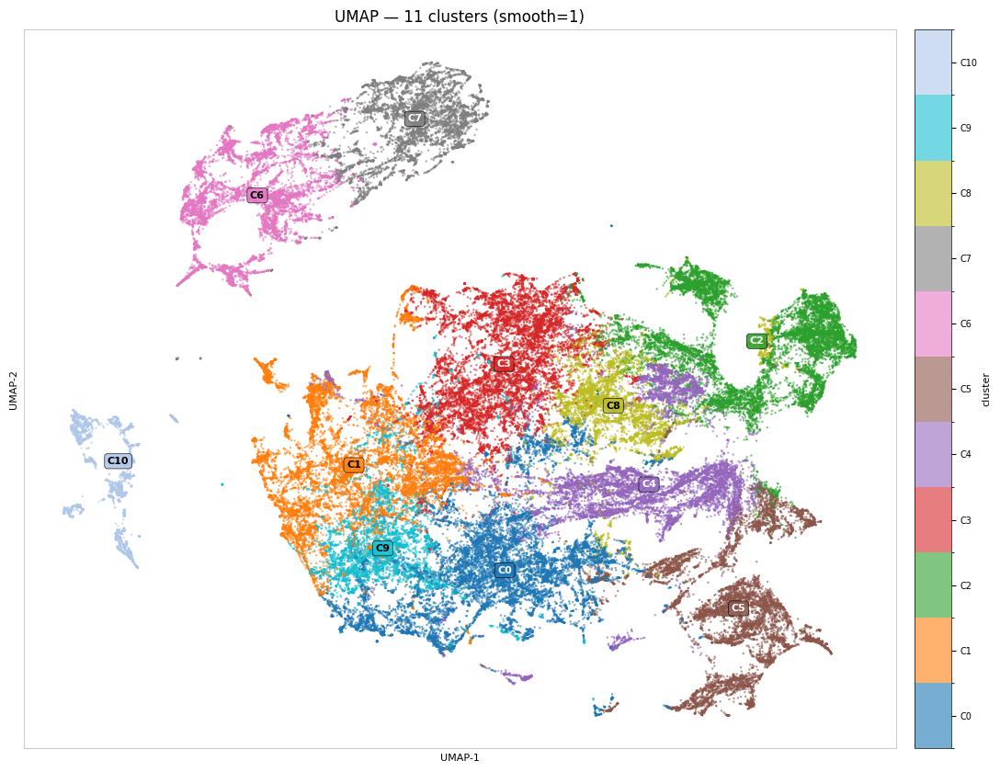

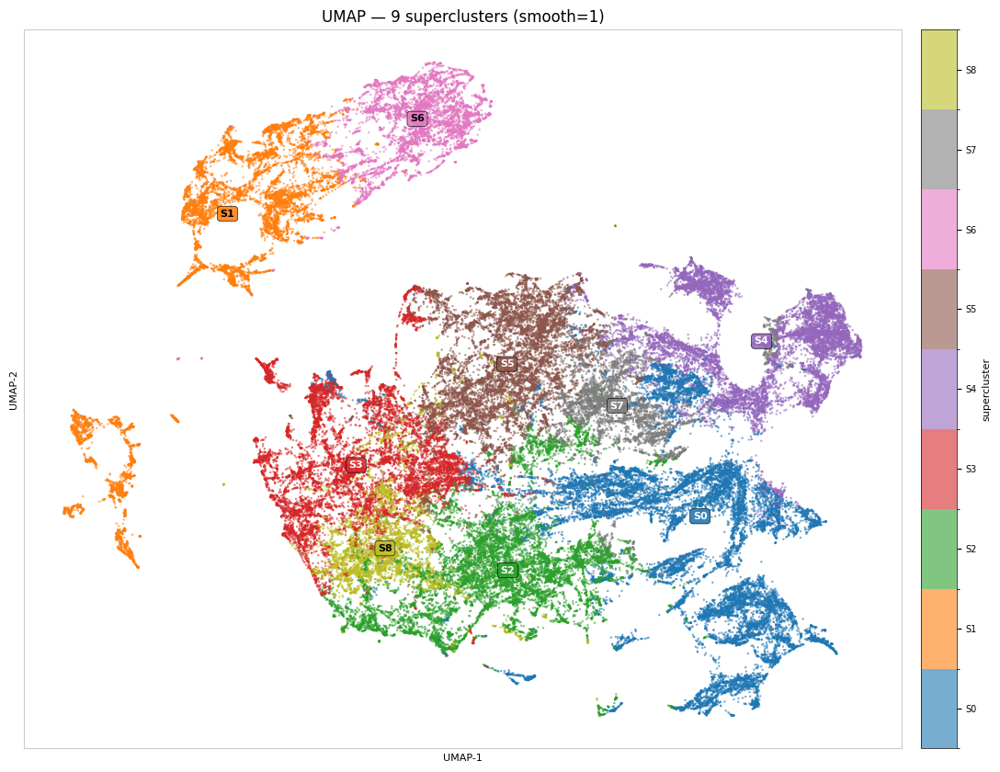

(<Figure size 1100x850 with 2 Axes>,
 <Axes: title={'center': 'UMAP — 9 superclusters (smooth=1)'}, xlabel='UMAP-1', ylabel='UMAP-2'>)

In [14]:
plot_umap(color_by="cluster")
plot_umap(color_by="supercluster")
# plot_umap(color_by="animal")
# plot_umap(overlay_animal=True)

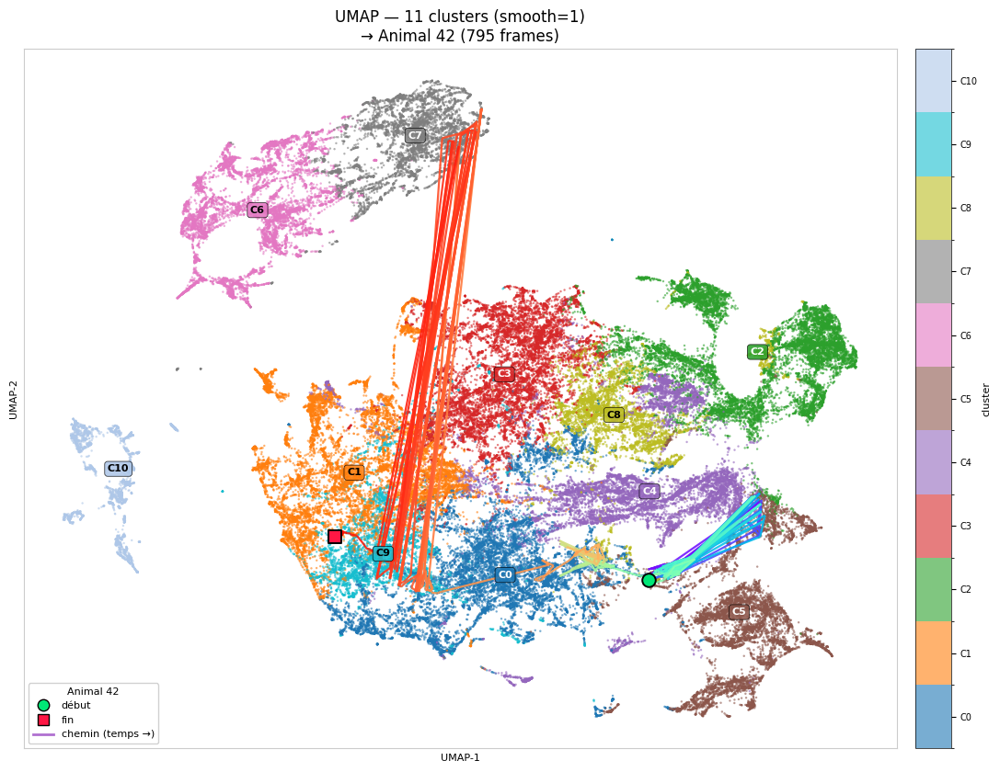

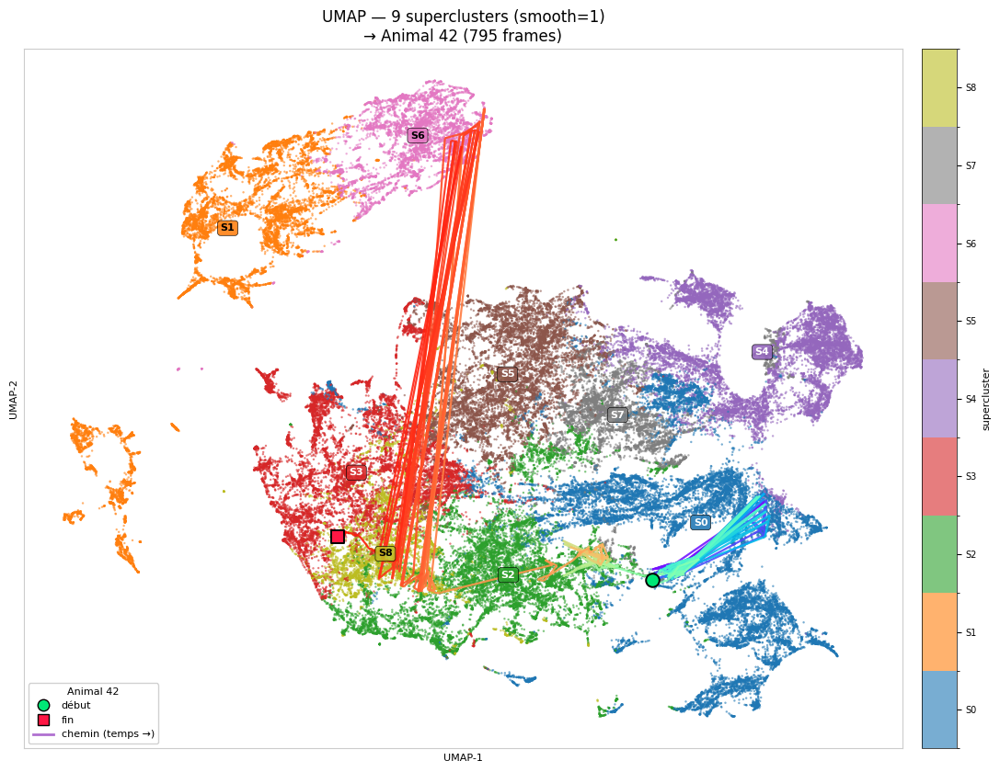

(<Figure size 1100x850 with 2 Axes>,
 <Axes: title={'center': 'UMAP — 9 superclusters (smooth=1)\n→ Animal 42 (795 frames)'}, xlabel='UMAP-1', ylabel='UMAP-2'>)

In [15]:
#specific animal
HIGHLIGHT_ANIMAL = resolve_animal_id(df, 42)

plot_umap(color_by="cluster",      highlight_animal=HIGHLIGHT_ANIMAL)
plot_umap(color_by="supercluster", highlight_animal=HIGHLIGHT_ANIMAL)

In [16]:
# ===============================================================
#  CELLULE — Trajectoire d'un individu
#  Seiche (traînée colorée par groupe) + CREVETTE + distance
#  Nécessite la CELLULE 0 (référentiel couleurs).
# ===============================================================
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.collections import LineCollection
from matplotlib.lines import Line2D

# ── Conventions de nommage des points de tracking ──────────────────────
_CUTTLE_CANDS = ["TopMantle", "MidCuttleHead", "MidMantle", "MidBody"]
_PREY_CANDS   = ["MidShrimp", "HeadShrimp", "Prey"]

PREY_COLOR  = "#ffb300"     # ambre — volontairement HORS du référentiel
LINK_COLOR  = "#9e9e9e"


def _pick_key(cands, cols):
    """Premier point de tracking disponible parmi les candidats."""
    xset = {c[:-2] for c in cols if c.endswith("_x")}
    for c in cands:
        if c in xset:
            return c
    return None


def _runs(labels):
    """
    Compresse une suite de labels en plages homogènes.
    [0,0,0,1,1,2] -> [(0,3,0), (3,5,1), (5,6,2)]
    Un axvspan par plage au lieu d'un par frame.
    """
    labels = np.asarray(labels)
    if len(labels) == 0:
        return []
    chg = np.flatnonzero(np.diff(labels)) + 1
    b   = np.concatenate([[0], chg, [len(labels)]])
    return [(int(b[k]), int(b[k + 1]), int(labels[b[k]])) for k in range(len(b) - 1)]


def _segments_valides(x, y):
    """
    Construit les segments UNIQUEMENT entre points consécutifs tous deux
    valides. Une LineCollection ne sait pas "sauter" un NaN : sans ce
    filtrage, une frame non trackée relie deux positions éloignées par un
    trait fantôme qui n'a jamais existé.

    Retourne (segments, masque_points_valides, masque_paires_valides).
    """
    x = np.asarray(x, float)
    y = np.asarray(y, float)
    ok = np.isfinite(x) & np.isfinite(y)
    if len(x) < 2:
        return np.empty((0, 2, 2)), ok, np.zeros(0, bool)
    paires = ok[:-1] & ok[1:]
    pts    = np.column_stack([x, y]).reshape(-1, 1, 2)
    segs   = np.concatenate([pts[:-1], pts[1:]], axis=1)
    return segs[paires], ok, paires


def _resolve_aid(df, raw, id_col="animal_id"):
    """Saisie -> valeur exacte présente dans la colonne (str/int/zéros)."""
    if "resolve_animal_id" in globals():
        return resolve_animal_id(df, raw, id_col)
    vals = df[id_col].dropna().unique()
    s = str(raw).strip()
    for v in vals:
        if str(v).strip() == s:
            return v
    try:
        num = float(s)
        for v in vals:
            try:
                if float(str(v).strip()) == num:
                    return v
            except ValueError:
                pass
    except ValueError:
        pass
    return None


def plot_animal_trajectory(animal_id, df, group_col="cluster", features=FEATURES,
                           point_key=None, prey_key=None,
                           show_prey=True, show_distance=True,
                           link_every=0, save=True, ax_legend_ncol=2):
    """
    Panneau gauche  : trajectoire 2D — seiche colorée par groupe,
                      crevette en ambre pointillé.
    Panneau droit   : features normalisées + distance seiche/crevette,
                      fond coloré par groupe.

    show_prey     : tracer la trajectoire de la crevette
    show_distance : ajouter la courbe de distance seiche–crevette
    link_every    : si > 0, relie seiche et crevette toutes les N frames
                    (visualise l'approche ; 0 = désactivé)
    """
    if "group_color" not in globals():
        raise RuntimeError("Exécute d'abord la CELLULE 0 (référentiel couleurs).")

    aid = _resolve_aid(df, animal_id)
    if aid is None:
        dispo = sorted(str(v) for v in df["animal_id"].dropna().unique())
        print(f"[ERREUR] Animal {animal_id!r} introuvable. Dispo : {dispo[:15]}…")
        return
    cf = df[df["animal_id"] == aid].sort_values("frame").reset_index(drop=True)
    if cf.empty:
        print(f"[ERREUR] Animal {aid!r} : aucune ligne.")
        return
    if group_col not in cf.columns:
        print(f"[ERREUR] Colonne '{group_col}' absente de df.")
        return

    cols = set(cf.columns)
    ckey = point_key or _pick_key(_CUTTLE_CANDS, cols)
    pkey = prey_key  or _pick_key(_PREY_CANDS,   cols)
    if ckey is None:
        print(f"[ERREUR] Aucun point seiche parmi {_CUTTLE_CANDS}.")
        return
    if show_prey and pkey is None:
        print(f"[INFO] Aucun point crevette parmi {_PREY_CANDS} "
              f"-> trajectoire proie non tracée.")

    labs = pd.to_numeric(cf[group_col], errors="coerce").fillna(0).to_numpy(int)
    x = cf[f"{ckey}_x"].to_numpy(float)
    y = cf[f"{ckey}_y"].to_numpy(float)
    pfx = group_prefix(group_col)

    has_prey = show_prey and pkey is not None
    if has_prey:
        px = cf[f"{pkey}_x"].to_numpy(float)
        py = cf[f"{pkey}_y"].to_numpy(float)
    else:
        px = py = None

    fig, axes = plt.subplots(1, 2, figsize=(16, 6))

    # ══ 1. TRAJECTOIRES ════════════════════════════════════════════════
    # ── Seiche : traînée colorée par groupe ─────────────────────────────
    segs_c, ok_c, paires_c = _segments_valides(x, y)
    if len(segs_c) == 0:
        print(f"[ERREUR] Animal {aid!r} : trajectoire seiche vide/NaN.")
        plt.close(fig)
        return
    cols_c = [group_color(l, group_col) for l in labs[:-1][paires_c]]
    axes[0].add_collection(LineCollection(segs_c, colors=cols_c, linewidths=2.2,
                                          capstyle="round", zorder=3))
    axes[0].scatter(x[ok_c], y[ok_c],
                    c=[group_color(l, group_col) for l in labs[ok_c]],
                    s=7, zorder=4, linewidths=0)

    i0c, i1c = np.flatnonzero(ok_c)[[0, -1]]
    axes[0].scatter(x[i0c], y[i0c], marker="o", s=130, facecolor="#00e676",
                    edgecolor="black", linewidth=1.5, zorder=8)
    axes[0].scatter(x[i1c], y[i1c], marker="s", s=130, facecolor="#ff1744",
                    edgecolor="black", linewidth=1.5, zorder=8)

    # ── Crevette : ambre, pointillé, HORS code couleur des groupes ──────
    # Choix délibéré : si la proie était colorée par cluster, on ne
    # distinguerait plus les deux trajectoires. L'ambre est réservé à
    # la proie dans tout le notebook (idem viewer interactif).
    couverture = np.nan
    if has_prey:
        segs_p, ok_p, _ = _segments_valides(px, py)
        couverture = 100 * ok_p.mean()
        if len(segs_p):
            axes[0].add_collection(LineCollection(
                segs_p, colors=PREY_COLOR, linewidths=1.6,
                linestyles=(0, (5, 2)), alpha=0.9, zorder=2))
            axes[0].scatter(px[ok_p], py[ok_p], s=5, c=PREY_COLOR,
                            alpha=0.55, zorder=2, linewidths=0)
            i0p, i1p = np.flatnonzero(ok_p)[[0, -1]]
            axes[0].scatter(px[i0p], py[i0p], marker="^", s=110,
                            facecolor=PREY_COLOR, edgecolor="black",
                            linewidth=1.3, zorder=7)
            axes[0].scatter(px[i1p], py[i1p], marker="v", s=110,
                            facecolor="#b26a00", edgecolor="black",
                            linewidth=1.3, zorder=7)
        else:
            print(f"[INFO] Crevette jamais trackée pour l'animal {aid}.")
            has_prey = False

    # ── Liens seiche–crevette (visualise l'approche) ────────────────────
    if has_prey and link_every > 0:
        k = np.arange(0, len(x), link_every)
        k = k[np.isfinite(x[k]) & np.isfinite(px[k])]
        if len(k):
            liens = np.stack([np.column_stack([x[k], y[k]]),
                              np.column_stack([px[k], py[k]])], axis=1)
            axes[0].add_collection(LineCollection(
                liens, colors=LINK_COLOR, linewidths=0.6, alpha=0.45, zorder=1))

    # ── Distance et frame de rapprochement maximal ──────────────────────
    dist = i_min = d_min = None
    if has_prey:
        dist = np.hypot(x - px, y - py)
        if np.isfinite(dist).any():
            i_min = int(np.nanargmin(dist))
            d_min = float(dist[i_min])
            axes[0].scatter(x[i_min], y[i_min], marker="*", s=320,
                            facecolor="#ffffff", edgecolor="black",
                            linewidth=1.4, zorder=9)

    # add_collection ne recalcule PAS les limites -> on les pose à la main,
    # sur l'union des deux trajectoires.
    xs_all = np.concatenate([x[ok_c]] + ([px[np.isfinite(px)]] if has_prey else []))
    ys_all = np.concatenate([y[ok_c]] + ([py[np.isfinite(py)]] if has_prey else []))
    etendue = max(np.ptp(xs_all), np.ptp(ys_all), 1.0)
    m = 0.06 * etendue
    axes[0].set_xlim(xs_all.min() - m, xs_all.max() + m)
    axes[0].set_ylim(ys_all.min() - m, ys_all.max() + m)
    axes[0].invert_yaxis()                       # repère image : y vers le bas
    axes[0].set_aspect("equal", adjustable="datalim")
    axes[0].set_title(f"Animal {aid} — Trajectoires ({group_col})", fontsize=11)
    axes[0].set_xlabel("X (px)"); axes[0].set_ylabel("Y (px)")

    # ── Légende ─────────────────────────────────────────────────────────
    h_grp = group_handles(labs[ok_c], group_col, lw=3)
    leg_g = axes[0].legend(handles=h_grp, fontsize=7.5, loc="upper left",
                           ncol=ax_legend_ncol, framealpha=0.92,
                           title=f"seiche — {group_col}", title_fontsize=8)
    axes[0].add_artist(leg_g)          # sinon le legend() suivant l'écrase

    h_mrk = [
        Line2D([0], [0], marker="o", color="none", markerfacecolor="#00e676",
               markeredgecolor="black", markersize=9, label="seiche : début"),
        Line2D([0], [0], marker="s", color="none", markerfacecolor="#ff1744",
               markeredgecolor="black", markersize=9, label="seiche : fin"),
    ]
    if has_prey:
        h_mrk += [
            Line2D([0], [0], color=PREY_COLOR, lw=2, ls="--",
                   label=f"crevette ({couverture:.0f}% trackée)"),
            Line2D([0], [0], marker="^", color="none", markerfacecolor=PREY_COLOR,
                   markeredgecolor="black", markersize=9, label="crevette : début"),
            Line2D([0], [0], marker="v", color="none", markerfacecolor="#b26a00",
                   markeredgecolor="black", markersize=9, label="crevette : fin"),
        ]
        if d_min is not None:
            h_mrk.append(Line2D([0], [0], marker="*", color="none",
                                markerfacecolor="white", markeredgecolor="black",
                                markersize=13,
                                label=f"dist. min : {d_min:.0f} px (f{i_min})"))
    axes[0].legend(handles=h_mrk, fontsize=7.5, loc="lower right",
                   framealpha=0.92, title="repères", title_fontsize=8)

    # ══ 2. SÉRIES TEMPORELLES ══════════════════════════════════════════
    plages = _runs(labs)
    for a, b, lab in plages:
        axes[1].axvspan(a, b, color=group_color(lab, group_col),
                        alpha=0.20, lw=0, zorder=0)

    def _minmax(v):
        """Normalisation min-max, robuste aux NaN et aux séries constantes."""
        v = np.asarray(v, float)
        lo, hi = np.nanmin(v), np.nanmax(v)
        return (v - lo) / (hi - lo) if hi > lo else np.full_like(v, 0.5)

    for var in features:
        if var not in cf.columns:
            continue
        v = pd.to_numeric(cf[var], errors="coerce").to_numpy(float)
        if not np.isfinite(v).any():
            continue
        axes[1].plot(_minmax(v), label=var, alpha=0.8, lw=1.2, zorder=2)

    # Distance seiche–crevette : tracée par-dessus, en noir épais
    if show_distance and dist is not None and np.isfinite(dist).any():
        axes[1].plot(_minmax(dist), color="black", lw=2.2, zorder=5,
                     label=f"distance seiche–crevette "
                           f"[{np.nanmin(dist):.0f}–{np.nanmax(dist):.0f} px]")
        axes[1].axvline(i_min, color="black", ls=":", lw=1.2, zorder=4)
        axes[1].annotate(f"min {d_min:.0f} px", xy=(i_min, 0),
                         xytext=(i_min, -0.045), ha="center", fontsize=7,
                         color="black")

    axes[1].set_xlim(0, len(cf))
    axes[1].set_ylim(-0.08, 1.05)
    axes[1].set_title(f"Animal {aid} — séries normalisées min-max ({group_col})",
                      fontsize=11)
    axes[1].set_xlabel("Frame (index dans la séquence)")
    axes[1].set_ylabel("valeur normalisée")

    leg_f = axes[1].legend(fontsize=6.5, loc="upper left", framealpha=0.92,
                           ncol=2, title="séries", title_fontsize=8)
    axes[1].add_artist(leg_f)
    axes[1].legend(handles=group_handles(labs[ok_c], group_col, style="patch"),
                   fontsize=7, loc="upper right", framealpha=0.92,
                   ncol=ax_legend_ncol, title=group_col, title_fontsize=8)

    sup = (f"Animal {aid} | smooth={SELECTED_WINDOW} | {group_col} | "
           f"{len(cf)} frames, {len(plages)} plages | seiche={ckey}")
    if has_prey:
        sup += f", crevette={pkey} ({couverture:.0f}%)"
    plt.suptitle(sup, fontsize=11)
    plt.tight_layout()

    if save:
        plt.savefig(OUT_DIR /
                    f"traj_smooth{SELECTED_WINDOW}_{group_col}_animal{aid}.png",
                    dpi=150, bbox_inches="tight")
    plt.show()

    if d_min is not None:
        print(f"[TRAJ] animal {aid} : distance min {d_min:.1f} px à la frame "
              f"{cf['frame'].iloc[i_min]} (index {i_min}) — "
              f"{group_col} {pfx}{labs[i_min]}")
    return cf


print("[OK] plot_animal_trajectory définie — usage :")
print("     plot_animal_trajectory(12, df, 'cluster')")
print("     plot_animal_trajectory(12, df, 'supercluster', link_every=15)")

[OK] plot_animal_trajectory définie — usage :
     plot_animal_trajectory(12, df, 'cluster')
     plot_animal_trajectory(12, df, 'supercluster', link_every=15)


In [56]:
ANIMAL_ID = animal_ids[103]-1   # â† ou un ID spécifique comme 42
ANIMAL_ID_2 = animal_ids[118]-1

plot_animal_trajectory(ANIMAL_ID, df, group_col="supercluster")
plot_animal_trajectory(ANIMAL_ID_2, df, group_col="supercluster")

Ignoring fixed x limits to fulfill fixed data aspect with adjustable data limits.
Ignoring fixed x limits to fulfill fixed data aspect with adjustable data limits.
Ignoring fixed x limits to fulfill fixed data aspect with adjustable data limits.
Ignoring fixed x limits to fulfill fixed data aspect with adjustable data limits.


[TRAJ] animal 103 : distance min 62.0 px à la frame 747 (index 747) — supercluster S6
[TRAJ] animal 118 : distance min 86.4 px à la frame 2224 (index 2224) — supercluster S8


,frame,Leye_x,Leye_y,Leye_l,LeyeSide_x,LeyeSide_y,LeyeSide_l,LeyeBack_x,LeyeBack_y,LeyeBack_l,...,_dtheta_deg,_speed_2pts,distance_to_shrimp_brut,approach_angle_brut,speed_cuttle_brut,rotation_net_brut,rotation_oscillation_brut,jerk_cuttle_brut,cluster,supercluster
0,0,1431.5273,759.24220,1.000000,1436.8716,767.17380,1.000000,1446.8633,766.90625,0.968262,...,0.000000,0.068405,736.929334,140.600442,0.063288,0.089070,0.158441,0.001941,5,0
1,1,1431.5312,759.28906,1.000000,1436.9766,767.26370,1.000000,1447.1895,766.90430,0.959473,...,-0.247512,0.019710,735.690247,141.362786,0.060837,0.089070,0.158441,0.001861,5,0
2,2,1431.5156,759.32810,1.000000,1436.8633,767.22850,1.000000,1446.8301,766.93164,0.965332,...,0.077236,0.023168,734.058338,142.819191,0.057644,0.089070,0.158441,0.001781,5,0
3,3,1431.5352,759.32030,1.000000,1436.9190,767.22850,1.000000,1446.9727,766.89650,0.964844,...,-0.025625,0.059097,733.640458,144.054836,0.053671,0.089070,0.352532,0.001701,5,0
4,4,1431.5469,759.32030,1.000000,1437.0225,767.28516,1.000000,1447.2285,766.86720,0.964844,...,-0.023207,0.088727,731.371802,144.591297,0.048886,0.089070,0.352532,0.001621,5,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2220,2220,1242.9434,764.66210,1.000000,1249.2949,773.10450,1.000000,1258.5859,770.89160,1.000000,...,-0.355187,6.821138,104.559047,8.967953,6.662477,0.820155,4.982719,0.000306,1,3
2221,2221,1236.6001,765.69920,0.995605,1242.0000,773.18066,1.000000,1251.9758,771.63210,1.000000,...,0.310843,6.712646,100.726871,9.245657,6.561671,0.820155,4.302459,0.004071,9,8
2222,2222,1229.4727,765.30273,1.000000,1235.6958,773.96780,1.000000,1245.2979,771.64260,1.000000,...,-0.483785,6.585208,95.921623,8.185963,6.445179,0.820155,3.493692,0.008448,9,8
2223,2223,1222.9766,765.69434,1.000000,1228.8081,773.70215,0.974121,1238.8672,772.21060,0.980957,...,0.301787,6.439062,91.127891,8.958538,6.313336,0.820155,3.365182,0.012825,9,8


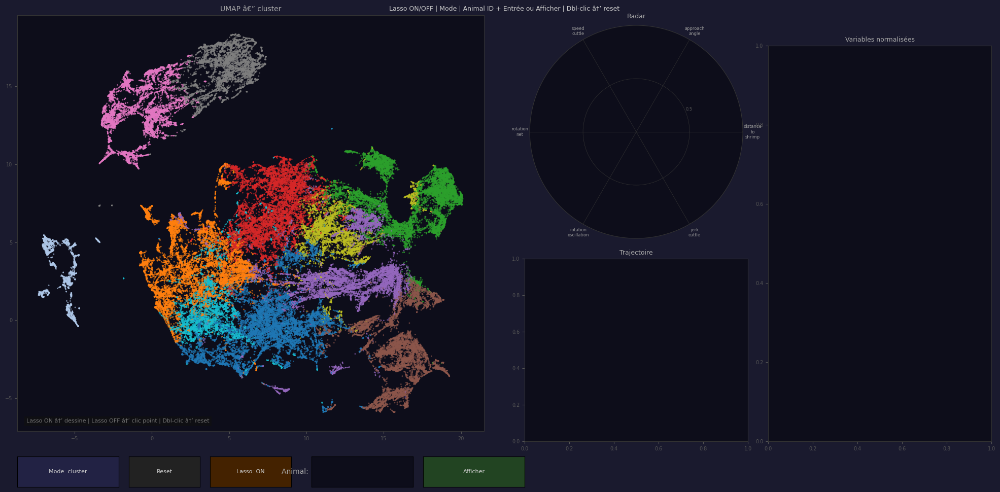

In [18]:
#plot interactif umap

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib as mpl
from matplotlib.widgets import LassoSelector, Button, TextBox
from matplotlib.path import Path

%matplotlib qt

def plot_umap_interactive_radar(df, Z, features, n_clusters, n_superclusters,
                                 color_by="cluster"):

    state = {"color_by": color_by, "lasso_active": True}

    global_min = df[features].min().values
    global_max = df[features].max().values
    angles     = np.linspace(0, 2 * np.pi, len(features), endpoint=False)
    ang_full   = np.concatenate([angles, [angles[0]]])
    Z_pts      = np.column_stack([Z[:, 0], Z[:, 1]])

    # Tout en str pour éviter les mismatch de type
    df = df.copy()
    df["animal_id"] = df["animal_id"].astype(str)
    animal_ids = sorted(df["animal_id"].unique())
    n_animals  = len(animal_ids)
    id_to_idx  = {aid: i for i, aid in enumerate(animal_ids)}

    def get_col_data(cb):
        if cb == "supercluster":
            return (df["supercluster"].values, plt.cm.tab10,
                    mpl.colors.BoundaryNorm(range(n_superclusters+1), ncolors=n_superclusters), "S")
        elif cb == "cluster":
            return (df["cluster"].values, CMAP_CLUSTER, NORM_CLUSTER, "C")
        else:
            col = np.array([id_to_idx[a] for a in df["animal_id"]])
            return (col, plt.cm.hsv,
                    mpl.colors.Normalize(vmin=0, vmax=n_animals), "A")

    # â”€â”€ Figure â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€
    fig = plt.figure(figsize=(20, 10))
    fig.patch.set_facecolor("#1a1a2e")

    ax_umap  = fig.add_axes([0.02, 0.14, 0.46, 0.82])
    ax_radar = fig.add_axes([0.52, 0.52, 0.22, 0.42], polar=True)
    ax_traj  = fig.add_axes([0.52, 0.12, 0.22, 0.36])
    ax_feats = fig.add_axes([0.76, 0.12, 0.22, 0.78])

    for ax in [ax_umap, ax_radar, ax_traj, ax_feats]:
        ax.set_facecolor("#0d0d1a")
        for spine in ax.spines.values():
            spine.set_edgecolor("#333333")
        ax.tick_params(colors="#555555", labelsize=7)

    # â”€â”€ Widgets â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€
    ax_btn_mode   = fig.add_axes([0.02, 0.03, 0.10, 0.06])
    ax_btn_reset  = fig.add_axes([0.13, 0.03, 0.07, 0.06])
    ax_btn_lasso  = fig.add_axes([0.21, 0.03, 0.08, 0.06])
    ax_textbox    = fig.add_axes([0.31, 0.03, 0.10, 0.06])
    ax_btn_animal = fig.add_axes([0.42, 0.03, 0.10, 0.06])

    btn_mode   = Button(ax_btn_mode,  f"Mode: {color_by}", color="#222244", hovercolor="#333366")
    btn_reset  = Button(ax_btn_reset, "Reset",             color="#222222", hovercolor="#333333")
    btn_lasso  = Button(ax_btn_lasso, "Lasso: ON",         color="#442200", hovercolor="#663300")
    textbox    = TextBox(ax_textbox,  "Animal: ",          initial="",
                         color="#0d0d1a", hovercolor="#1a1a2e")
    btn_animal = Button(ax_btn_animal,"Afficher",          color="#224422", hovercolor="#336633")

    for btn in [btn_mode, btn_reset, btn_lasso, btn_animal]:
        btn.label.set_color("#cccccc")
        btn.label.set_fontsize(8)
    textbox.label.set_color("#aaaaaa")
    textbox.text_disp.set_color("#ffffff")

    # â”€â”€ Scatter â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€
    col_data, cmap, norm_g, _ = get_col_data(state["color_by"])
    sc        = ax_umap.scatter(Z_pts[:,0], Z_pts[:,1],
                                 c=[cmap(norm_g(c)) for c in col_data],
                                 s=4, alpha=0.7, linewidths=0, zorder=2)
    hl_lasso  = ax_umap.scatter([], [], s=20, facecolors="none",
                                 edgecolors="white", linewidths=0.7, zorder=4)
    hl_animal = ax_umap.scatter([], [], s=15, zorder=5)
    hl_click  = ax_umap.scatter([], [], s=120, marker="*",
                                 facecolors="yellow", edgecolors="white",
                                 linewidths=0.7, zorder=6)

    ax_umap.set_facecolor("#0d0d1a")
    ax_umap.set_title(f"UMAP â€” {state['color_by']}", color="#aaaaaa", fontsize=10)
    for spine in ax_umap.spines.values():
        spine.set_edgecolor("#333333")

    info_text = ax_umap.text(
        0.02, 0.02,
        "Lasso ON â†’ dessine | Lasso OFF â†’ clic point | Dbl-clic â†’ reset",
        transform=ax_umap.transAxes, color="#777777", fontsize=8,
        bbox=dict(facecolor="#111111", alpha=0.7, edgecolor="none", pad=3)
    )

    # â”€â”€ Radar â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€
    def setup_radar():
        ax_radar.cla()
        ax_radar.set_facecolor("#0d0d1a")
        ax_radar.set_xticks(angles)
        ax_radar.set_xticklabels([f.replace("_", "\n") for f in features],
                                  color="#999999", fontsize=6)
        ax_radar.set_ylim(0, 1)
        ax_radar.set_yticks([0.5])
        ax_radar.set_yticklabels(["0.5"], color="#555555", fontsize=6)
        ax_radar.grid(color="#333333", linewidth=0.5)
        ax_radar.spines["polar"].set_color("#333333")
        ax_radar.set_title("Radar", color="#aaaaaa", fontsize=9, pad=10)

    def draw_radar(norm_vals, color, title):
        setup_radar()
        vf = np.concatenate([norm_vals, [norm_vals[0]]])
        ax_radar.plot(ang_full, vf, linewidth=2, color=color)
        ax_radar.fill(ang_full, vf, alpha=0.3, color=color)
        for a, vn in zip(angles, norm_vals):
            ax_radar.text(a, min(vn + 0.15, 1.1), f"{vn:.2f}",
                          ha="center", va="center", color="#dddddd", fontsize=6,
                          bbox=dict(facecolor="#111111", alpha=0.5, edgecolor="none", pad=1))
        ax_radar.set_title(title, color="#aaaaaa", fontsize=8, pad=10)
        fig.canvas.draw_idle()

    setup_radar()

    # â”€â”€ Traj + feats â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€
    def setup_traj():
        ax_traj.cla()
        ax_traj.set_facecolor("#0d0d1a")
        ax_traj.set_title("Trajectoire", color="#aaaaaa", fontsize=9)
        for spine in ax_traj.spines.values():
            spine.set_edgecolor("#333333")
        ax_traj.tick_params(colors="#555555", labelsize=7)

    def setup_feats():
        ax_feats.cla()
        ax_feats.set_facecolor("#0d0d1a")
        ax_feats.set_title("Variables normalisées", color="#aaaaaa", fontsize=9)
        for spine in ax_feats.spines.values():
            spine.set_edgecolor("#333333")
        ax_feats.tick_params(colors="#555555", labelsize=7)

    setup_traj()
    setup_feats()

    # â”€â”€ Lasso â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€
    def on_lasso(verts):
        if not state["lasso_active"]:
            return
        lasso_path   = Path(verts)
        inside       = lasso_path.contains_points(Z_pts)
        selected_idx = np.where(inside)[0]
        n_sel        = len(selected_idx)

        if n_sel == 0:
            info_text.set_text("Lasso vide")
            hl_lasso.set_offsets(np.empty((0, 2)))
            fig.canvas.draw_idle()
            return

        hl_lasso.set_offsets(Z_pts[selected_idx])
        raw_vals  = df[features].values[selected_idx].mean(axis=0)
        norm_vals = np.clip((raw_vals - global_min)/(global_max - global_min + 1e-9), 0, 1)

        cd, cm, ng, lpfx = get_col_data(state["color_by"])
        if state["color_by"] in ("cluster", "supercluster"):
            counts   = pd.Series(cd[selected_idx]).value_counts()
            dominant = counts.idxmax()
            color    = cm(ng(dominant))
            comp     = " | ".join([f"{lpfx}{g}:{n}" for g, n in counts.items()])
        else:
            color = "#44aaff"
            comp  = f"{pd.Series(df['animal_id'].values[selected_idx]).nunique()} individus"

        info_text.set_text(f"{n_sel} pts â€” {comp}")
        draw_radar(norm_vals, color, f"Lasso n={n_sel}")

    lasso_selector = LassoSelector(ax_umap, on_lasso,
                                    props=dict(color="#FFD700", linewidth=1.5),
                                    useblit=True, button=1)

    # â”€â”€ Clic â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€
    def on_click(event):
        if event.inaxes != ax_umap:
            return
        if event.dblclick:
            reset(None); return
        if state["lasso_active"]:
            return  # lasso gère les clics quand actif
        if event.button != 1 or event.xdata is None:
            return

        xy   = np.array([event.xdata, event.ydata])
        dist = np.linalg.norm(Z_pts - xy, axis=1)
        idx  = int(np.argmin(dist))
        xlim = ax_umap.get_xlim()
        if dist[idx] > (xlim[1] - xlim[0]) * 0.05:
            return

        hl_click.set_offsets([Z_pts[idx]])
        raw_vals  = df[features].values[idx]
        norm_vals = np.clip((raw_vals - global_min)/(global_max - global_min + 1e-9), 0, 1)
        cd, cm, ng, lpfx = get_col_data(state["color_by"])
        color = cm(ng(cd[idx]))
        label = f"{lpfx}{cd[idx]} | animal {df['animal_id'].iloc[idx]}"
        info_text.set_text(f"Point {idx} â€” {label}")
        draw_radar(norm_vals, color, f"Point {idx}\n{label}")

    fig.canvas.mpl_connect("button_press_event", on_click)

    # â”€â”€ Bouton lasso ON/OFF â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€
    # Désactiver le lasso libère les clics pour le TextBox et le clic point
    def toggle_lasso(event):
        state["lasso_active"] = not state["lasso_active"]
        if state["lasso_active"]:
            lasso_selector.set_active(True)
            btn_lasso.label.set_text("Lasso: ON")
            btn_lasso.ax.set_facecolor("#442200")
            info_text.set_text("Lasso ON â€” dessine une zone")
        else:
            lasso_selector.set_active(False)
            btn_lasso.label.set_text("Lasso: OFF")
            btn_lasso.ax.set_facecolor("#004422")
            info_text.set_text("Lasso OFF â€” clic point | écris animal_id")
        fig.canvas.draw_idle()

    btn_lasso.on_clicked(toggle_lasso)

    # â”€â”€ Bouton mode â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€
    modes = ["supercluster", "cluster", "animal"]

    def toggle_mode(event):
        idx = modes.index(state["color_by"])
        state["color_by"] = modes[(idx + 1) % len(modes)]
        btn_mode.label.set_text(f"Mode: {state['color_by']}")
        cd, cm, ng, _ = get_col_data(state["color_by"])
        sc.set_facecolors([cm(ng(c)) for c in cd])
        ax_umap.set_title(f"UMAP â€” {state['color_by']}", color="#aaaaaa", fontsize=10)
        fig.canvas.draw_idle()

    btn_mode.on_clicked(toggle_mode)

    # â”€â”€ Bouton reset â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€
    def reset(event):
        hl_lasso.set_offsets(np.empty((0, 2)))
        hl_animal.set_offsets(np.empty((0, 2)))
        hl_click.set_offsets(np.empty((0, 2)))
        info_text.set_text("Reset")
        setup_radar()
        ax_radar.set_title("Radar", color="#aaaaaa", fontsize=9, pad=10)
        setup_traj()
        setup_feats()
        fig.canvas.draw_idle()

    btn_reset.on_clicked(reset)

    # â”€â”€ Bouton animal â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€
    def show_animal(event):
        raw = textbox.text.strip()
        if not raw:
            info_text.set_text(f"Exemples d'IDs : {', '.join(animal_ids[:6])}")
            fig.canvas.draw_idle()
            return

        aid = str(raw)
        if aid not in df["animal_id"].values:
            sample = ", ".join(animal_ids[:8])
            info_text.set_text(f"'{aid}' introuvable. Exemples : {sample}")
            fig.canvas.draw_idle()
            return

        mask = df["animal_id"].values == aid
        idx  = np.where(mask)[0]
        n_a  = len(idx)

        # Surbrillance UMAP rainbow
        colors_r = plt.cm.rainbow(np.linspace(0, 1, n_a))
        hl_animal.set_offsets(Z_pts[idx])
        hl_animal.set_facecolors(colors_r)
        hl_animal.set_sizes([15] * n_a)

        # Radar moyen
        raw_vals  = df[features].values[mask].mean(axis=0)
        norm_vals = np.clip((raw_vals - global_min)/(global_max - global_min + 1e-9), 0, 1)
        draw_radar(norm_vals, "#44aaff", f"Animal {aid} (n={n_a})")

        # Trajectoire
        setup_traj()
        cf = df[mask].reset_index(drop=True)
        cl = df["cluster"].values[mask]
        _, cm_c, ng_c, _ = get_col_data("cluster")
        for i in range(len(cf) - 1):
            ax_traj.plot(cf["TopMantle_x"].iloc[i:i+2],
                         cf["TopMantle_y"].iloc[i:i+2],
                         "-o", color=cm_c(ng_c(cl[i])),
                         markersize=1.5, linewidth=0.8)
        ax_traj.scatter(cf["TopMantle_x"].iloc[0],  cf["TopMantle_y"].iloc[0],
                        color="lime", s=40, zorder=5)
        ax_traj.scatter(cf["TopMantle_x"].iloc[-1], cf["TopMantle_y"].iloc[-1],
                        color="white", s=40, zorder=5)
        ax_traj.invert_yaxis()
        ax_traj.set_title(f"Animal {aid}", color="#aaaaaa", fontsize=9)

        # Features temporelles
        setup_feats()
        t = np.arange(n_a)
        for feat in features:
            fmax = cf[feat].max()
            ax_feats.plot(t, cf[feat] / (fmax + 1e-9),
                          label=feat.replace("_"," "), alpha=0.8, linewidth=1)
        ax_feats.legend(fontsize=6, loc="upper right")
        ax_feats.set_xlabel("Frame", color="#555555", fontsize=7)
        ax_feats.set_title(f"Variables â€” animal {aid}", color="#aaaaaa", fontsize=9)

        info_text.set_text(f"Animal {aid} â€” {n_a} frames")
        fig.canvas.draw_idle()

    btn_animal.on_clicked(show_animal)

    # Appuyer sur Entrée dans le textbox = mÃªme effet que le bouton
    textbox.on_submit(lambda text: show_animal(None))

    plt.suptitle("Lasso ON/OFF | Mode | Animal ID + Entrée ou Afficher | Dbl-clic â†’ reset",
                 color="#cccccc", fontsize=9)
    plt.show()
    return fig


plot_umap_interactive_radar(df, Z, FEATURES, n_clusters, n_superclusters,
                             color_by="cluster")

In [19]:
%matplotlib inline

In [20]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
from matplotlib.widgets import Button, Slider, TextBox
from collections import Counter
from scipy.cluster.hierarchy import linkage, fcluster, dendrogram
from scipy.spatial.distance import pdist, squareform
from sklearn.preprocessing import StandardScaler


# ── Extraction des séquences ──────────────────────────────────
def _extract_sequences(df, cluster_col, seuil_min):
    sequences, mono_ids, multi_ids = {}, [], []
    for aid, group in df.groupby("animal_id"):
        raw = group.sort_values("frame")[cluster_col].values
        blocks, lengths = [], []
        cur, start = raw[0], 0
        for i in range(1, len(raw)):
            if raw[i] != cur:
                blocks.append(int(cur)); lengths.append(i - start)
                cur, start = raw[i], i
        blocks.append(int(cur)); lengths.append(len(raw) - start)
        fb, fl = [], []
        for b, l in zip(blocks, lengths):
            if l >= seuil_min:
                if fb and fb[-1] == b: fl[-1] += l
                else: fb.append(b); fl.append(l)
        sequences[aid] = {"seq": fb, "lengths": fl}
        (mono_ids if len(set(fb)) <= 1 else multi_ids).append(aid)
    return sequences, mono_ids, multi_ids


# ── SeqVec ────────────────────────────────────────────────────
def _seqvec(sequences, ids, n_cl,
            w_hist=1.0, w_trans=1.0, w_runlen=1.0, w_firstapp=1.0,
            w_temporal=1.0, w_context=1.0, w_global=1.0):

    def feat_hist(s, l, n):
        # Proportion de temps passé dans chaque cluster
        # log1p pour comprimer les dominances extrêmes
        t = sum(l)
        c = Counter()
        for cl, ln in zip(s, l):
            c[cl] += ln
        raw = np.array([c.get(i, 0) / t for i in range(n)])
        return np.log1p(raw * 10) / np.log1p(10)

    def feat_trans(s, n):
        # Matrice de transition normalisée + entropie par ligne
        # p[i,j] = probabilité d'aller de i vers j
        m = np.zeros((n, n))
        for a, b in zip(s[:-1], s[1:]):
            if 0 <= a < n and 0 <= b < n:
                m[a, b] += 1
        rs = m.sum(axis=1, keepdims=True)
        p  = np.where(rs > 0, m / rs, 0)
        ent = np.zeros(n)
        for i in range(n):
            row = p[i][p[i] > 0]
            if len(row) > 1:
                ent[i] = -np.sum(row * np.log(row)) / np.log(n)
        return np.concatenate([p.flatten(), ent])

    def feat_runlen(s, l, n):
        # Durée des runs par cluster : médiane, max, CV
        # CV = coefficient de variation = std/mean → mesure la régularité
        d = {i: [] for i in range(n)}
        for cl, ln in zip(s, l):
            if cl < n: d[cl].append(ln)
        med = np.array([np.median(d[i]) if d[i] else 0 for i in range(n)])
        mx  = np.array([max(d[i])       if d[i] else 0 for i in range(n)])
        cv  = np.array([np.std(d[i]) / (np.mean(d[i]) + 1e-9)
                        if len(d[i]) > 1 else 0 for i in range(n)])
        return np.concatenate([med, mx, cv])

    def feat_firstapp(s, n):
        # Pour chaque cluster : présence (0/1) + position normalisée
        # position = à quel moment de la séquence il apparaît pour la 1ère fois
        present  = np.zeros(n)
        position = np.full(n, 0.5)
        for i in range(n):
            try:
                idx = s.index(i)
                present[i]  = 1.0
                position[i] = idx / max(len(s) - 1, 1)
            except ValueError:
                pass
        return np.concatenate([present, position])

    def feat_temporal(s, l, n):
        # Proportion du temps dans chaque cluster
        # en 1ère moitié (t1) vs 2ème moitié (t2) + différence (t2-t1)
        # t2-t1 > 0 → cluster plus présent en fin de séquence (avant frappe)
        # t2-t1 < 0 → cluster plus présent en début de séquence
        total = sum(l)
        half  = total / 2
        h1    = np.zeros(n)
        h2    = np.zeros(n)
        cum   = 0
        for cl, ln in zip(s, l):
            if cl >= n: cum += ln; continue
            in_h1 = max(0, min(ln, half - cum))
            in_h2 = ln - in_h1
            h1[cl] += in_h1
            h2[cl] += in_h2
            cum += ln
        t1 = h1 / (total/2 + 1e-9)
        t2 = h2 / (total/2 + 1e-9)
        return np.concatenate([t1, t2, t2 - t1])

    def feat_context(s, n):
        # Contexte de début et de fin de séquence
        #
        # first_oh         : one-hot du 1er cluster (état initial)
        # last_oh          : one-hot du dernier cluster exact (← état avant frappe)
        # dom_start        : dominant sur les 10% premiers blocs
        # dom_end          : dominant sur les 10% derniers blocs
        # dom_end_weighted : dominant sur les 20% derniers blocs
        #
        # last_oh vs dom_end : complémentaires
        #   last_oh   = dernier état exact (peut être un pic isolé d'1 frame)
        #   dom_end   = état dominant en fin (plus robuste au bruit DLC)
        #   dom_end_weighted = idem sur une fenêtre plus large (20%)
        first_oh = np.zeros(n)
        last_oh  = np.zeros(n)
        if s:
            if 0 <= s[0]  < n: first_oh[s[0]]  = 1.0
            if 0 <= s[-1] < n: last_oh[s[-1]]  = 1.0

        n_start = max(1, len(s) // 10)
        dom_start = np.zeros(n)
        dom_end   = np.zeros(n)
        if s[:n_start]:
            c_s = Counter(s[:n_start]).most_common(1)[0][0]
            if 0 <= c_s < n: dom_start[c_s] = 1.0
        if s[-n_start:]:
            c_e = Counter(s[-n_start:]).most_common(1)[0][0]
            if 0 <= c_e < n: dom_end[c_e] = 1.0

        # 20% derniers blocs — fenêtre plus large pour dom_end_weighted
        n_end_blocks     = max(1, len(s) // 5)
        dom_end_weighted = np.zeros(n)
        if s[-n_end_blocks:]:
            c_ew = Counter(s[-n_end_blocks:]).most_common(1)[0][0]
            if 0 <= c_ew < n: dom_end_weighted[c_ew] = 1.0

        return np.concatenate([
            first_oh,          # n — état initial
            last_oh,           # n — dernier état exact (← avant frappe)
            dom_start,         # n — dominant 10% début
            dom_end,           # n — dominant 10% fin
            dom_end_weighted,  # n — dominant 20% fin (fenêtre plus robuste)
        ])
        # Total : 5×n features (était 4×n)

    def feat_global(s, l, n):
        # Métriques globales de la séquence
        #
        # richness          : proportion de clusters différents utilisés
        # entropy           : entropie de la distribution temporelle
        # inertia           : proportion du cluster dominant (max)
        # trans_rich        : richesse des transitions (paires uniques)
        # len(s)            : longueur de la séquence (nb de blocs)
        # last_cluster_norm : cluster final normalisé [0,1] ← NOUVEAU
        # prop_last         : proportion du temps dans le cluster final ← NOUVEAU
        #
        # last_cluster_norm vs last_oh dans feat_context :
        #   last_oh          = encodage one-hot (discret, sparse)
        #   last_cluster_norm = encodage scalaire continu [0,1]
        #   → les deux sont complémentaires dans StandardScaler
        #
        # prop_last : distingue
        #   "finit dans C3 sur 1 frame" (prop_last ≈ 0)
        #   "passe 60% du temps dans C3 avant frappe" (prop_last = 0.6)
        total    = sum(l)
        n_used   = len(set(s))
        richness = n_used / n

        c = Counter()
        for cl, ln in zip(s, l):
            c[cl] += ln
        hist_raw = np.array([c.get(i, 0) / total for i in range(n)])
        h_vals   = hist_raw[hist_raw > 0]
        entropy  = (-np.sum(h_vals * np.log(h_vals)) / np.log(n)
                    if len(h_vals) > 1 else 0.0)
        inertia  = hist_raw.max()

        pairs_dist = len({(a, b) for a, b in zip(s[:-1], s[1:]) if a != b})
        trans_rich = pairs_dist / (n * (n-1)) if n > 1 else 0.0

        last_cluster_norm = s[-1] / max(n-1, 1) if s else 0.5
        last_cl           = s[-1] if s else -1
        

        return np.array([
            richness,           # diversité des états
            entropy,            # entropie distribution
            inertia,            # dominance cluster principal
            trans_rich,         # richesse transitions
            len(s),             # longueur séquence
            last_cluster_norm,  # cluster final [0,1] ← NOUVEAU
            
        ])
        # Total : 7 scalaires (était 5)

    # ── Concaténation et normalisation ────────────────────────
    max_total = max(sum(sequences[aid]["lengths"]) for aid in ids)
    rows = []

    for aid in ids:
        s, l  = sequences[aid]["seq"], sequences[aid]["lengths"]
        total = sum(l)

        if not s:
            # Vecteur zéro si séquence vide
            # Taille : hist(n) + trans(n²+n) + runlen(3n) + firstapp(2n)
            #        + temporal(3n) + context(5n) + global(7+1)
            n_feat = (n_cl
                      + n_cl*n_cl + n_cl
                      + n_cl*3
                      + n_cl*2
                      + n_cl*3
                      + n_cl*5
                      + 8)
            rows.append(np.zeros(n_feat))
            continue

        norm_total = total / max_total

        rows.append(np.concatenate([
            feat_hist(s, l, n_cl)     * w_hist,
            feat_trans(s, n_cl)       * w_trans,
            feat_runlen(s, l, n_cl)   * w_runlen,
            feat_firstapp(s, n_cl)    * w_firstapp,
            feat_temporal(s, l, n_cl) * w_temporal,
            feat_context(s, n_cl)     * w_context,
            np.append(feat_global(s, l, n_cl), norm_total) * w_global,
        ]))

    X    = StandardScaler().fit_transform(np.array(rows))
    D    = squareform(pdist(X, "euclidean"))
    desc = f"SeqVec+ ({X.shape[1]} features)"
    print(f"[SEQVEC] {len(ids)} individus × {X.shape[1]} features")
    return X, D, desc
# ── Clustering hiérarchique ───────────────────────────────────
def _cluster_hier(D, ids, n_strat, linkage_method="ward"):
    Z      = linkage(squareform(np.clip(D, 0, None)), method=linkage_method)
    labels = fcluster(Z, n_strat, criterion="maxclust")
    n2l    = {n: str(i) for i, n in enumerate(sorted(set(labels)))}
    return {aid: n2l[lab] for aid, lab in zip(ids, labels)}, Z


# ── Leiden pour estimer K optimal ────────────────────────────
def _leiden_optimal_k(D, ids, resolution_range=None):
    try:
        import igraph as ig
        import leidenalg
    except ImportError:
        print("[WARN] igraph/leidenalg non disponibles")
        return None, {}
    n = len(ids)
    if n < 3: return None, {}
    D_max = D.max()
    if D_max == 0: return 1, {}
    sim       = 1 - D / D_max
    threshold = np.percentile(sim[sim > 0], 50)
    edges, weights = [], []
    for i in range(n):
        for j in range(i+1, n):
            if sim[i, j] > threshold:
                edges.append((i, j)); weights.append(float(sim[i, j]))
    if not edges: return 1, {}
    g = ig.Graph(n=n, edges=edges)
    g.es["weight"] = weights
    if resolution_range is None:
        resolution_range = [0.01, 0.1, 0.3, 0.5, 0.8, 1.0, 1.5, 2.0, 3.0]
    results = {}
    for res in resolution_range:
        part = leidenalg.find_partition(
            g, leidenalg.RBConfigurationVertexPartition,
            weights="weight", resolution_parameter=res, seed=42)
        results[res] = {"k": len(set(part.membership)),
                        "quality": part.quality()}
    best_res  = max(results, key=lambda r: results[r]["quality"])
    k_optimal = results[best_res]["k"]
    print(f"\n[LEIDEN] K optimal = {k_optimal} (résolution={best_res:.2f})")
    for res, r in results.items():
        print(f"  res={res:.1f} → K={r['k']} qualité={r['quality']:.3f}")
    return k_optimal, results


# ── Fenêtre principale ────────────────────────────────────────
def show_strategy_explorer(
    df,
    cluster_col    = "cluster",
    n_strategies   = 4,
    seuil_min      = 3,
    use_leiden_k   = False,
    linkage_method = "ward",
    w_hist     = 1.0,
    w_trans    = 1.0,
    w_runlen   = 1.0,
    w_firstapp = 1.0,
    w_temporal = 1.0,
    w_context  = 1.0,
    w_global   = 1.0,
):
    df = df.copy()
    df["animal_id"] = df["animal_id"].astype(str)

    def compute_all(col, n_s):
        n_cl = int(df[col].nunique())
        seqs, mono, multi = _extract_sequences(df, col, seuil_min)
        print(f"[INFO] {len(multi)} multi | {len(mono)} mono | n_cl={n_cl}")
        if len(multi) < 2:
            return seqs, mono, multi, None, None, {}, n_cl, "—", n_s
        X, D, desc = _seqvec(
            seqs, multi, n_cl,
            w_hist=w_hist, w_trans=w_trans,
            w_runlen=w_runlen, w_firstapp=w_firstapp,
            w_temporal=w_temporal, w_context=w_context,
            w_global=w_global,
        )
        if use_leiden_k:
            k_opt, _ = _leiden_optimal_k(D, multi)
            if k_opt is not None:
                n_s = k_opt
                print(f"[LEIDEN] K retenu : {n_s}")
        strat, Z = _cluster_hier(D, multi, n_s, linkage_method)
        print(f"[CLUSTER] {Counter(strat.values())} | {desc}")
        return seqs, mono, multi, D, Z, strat, n_cl, desc, n_s

    seqs, mono, multi, D, Z, strat, n_cl, desc, n_s_eff = compute_all(
        cluster_col, n_strategies)

    cur = {"col": cluster_col, "n_s": n_s_eff,
           "seqs": seqs, "mono": mono, "multi": multi,
           "D": D, "Z": Z, "strat": strat, "n_cl": n_cl, "desc": desc}

    # ── Figure ────────────────────────────────────────────────
    fig = plt.figure(figsize=(24, 12))
    fig.patch.set_facecolor("#1a1a2e")

    ax_dend = fig.add_axes([0.02, 0.22, 0.19, 0.72])
    ax_heat = fig.add_axes([0.23, 0.22, 0.19, 0.72])
    ax_seq  = fig.add_axes([0.45, 0.60, 0.53, 0.34])
    zone_r  = [0.45, 0.22, 0.53, 0.34]

    for ax in [ax_dend, ax_heat, ax_seq]:
        ax.set_facecolor("#0d0d1a")
        for sp in ax.spines.values(): sp.set_edgecolor("#333333")
        ax.tick_params(colors="#555555", labelsize=7)

    ax_s_k   = fig.add_axes([0.02, 0.11, 0.19, 0.03])
    ax_info  = fig.add_axes([0.02, 0.03, 0.60, 0.05])
    ax_tb    = fig.add_axes([0.66, 0.11, 0.14, 0.04])
    ax_bshow = fig.add_axes([0.81, 0.11, 0.08, 0.04])
    ax_bleid = fig.add_axes([0.66, 0.04, 0.23, 0.04])

    slider   = Slider(ax_s_k, "K groupes", 2,
                      max(3, min(12, len(multi)-1) if len(multi) > 2 else 12),
                      valinit=n_s_eff, valstep=1, color="#4466aa")
    textbox  = TextBox(ax_tb,    "Animal ID: ", initial="",
                       color="#111122", hovercolor="#1a1a2e")
    btn_show = Button(ax_bshow, "Afficher",  color="#224422", hovercolor="#336633")
    btn_leid = Button(ax_bleid, "Estimer K via Leiden",
                      color="#442244", hovercolor="#663366")

    for btn in [btn_show, btn_leid]:
        btn.label.set_color("#cccccc"); btn.label.set_fontsize(9)
    slider.label.set_color("white"); slider.valtext.set_color("white")
    textbox.label.set_color("#aaaaaa"); textbox.text_disp.set_color("#ffffff")

    ax_info.axis("off")
    info_txt = ax_info.text(
        0, 0.5,
        f"col={cluster_col} | seqvec | seuil_min={seuil_min} | "
        f"K={n_s_eff} | {len(multi)} multi + {len(mono)} MONO",
        color="#888888", fontsize=8, va="center",
        transform=ax_info.transAxes, fontfamily="monospace")

    radar_axes = []

    def remove_radars():
        for ax in radar_axes: ax.remove()
        radar_axes.clear()

    def update_info():
        info_txt.set_text(
            f"col={cur['col']} | seqvec | seuil_min={seuil_min} | "
            f"K={cur['n_s']} | {len(cur['multi'])} multi + {len(cur['mono'])} MONO")

    def draw():
        seqs  = cur["seqs"]; mono  = cur["mono"]; multi = cur["multi"]
        D     = cur["D"];    Z     = cur["Z"];    strat = cur["strat"]
        n_cl  = cur["n_cl"]; n_s   = cur["n_s"]

        strategy_list = sorted(set(strat.values())) if strat else []
        pal = {s: STRATEGY_PALETTE[i % len(STRATEGY_PALETTE)]
               for i, s in enumerate(strategy_list)}
        pal["MONO"] = "#666666"

        # ── Dendrogramme ──────────────────────────────────────
        ax_dend.cla(); ax_dend.set_facecolor("#0d0d1a")
        for sp in ax_dend.spines.values(): sp.set_edgecolor("#333333")
        ax_dend.tick_params(colors="#555555", labelsize=6)
        if Z is not None and len(multi) > 2:
            cut_h = Z[-(n_s-1), 2]*1.01 if len(Z) >= n_s else Z[-1, 2]
            dendrogram(Z, ax=ax_dend, no_labels=True,
                       color_threshold=cut_h,
                       above_threshold_color="#444455")
            ax_dend.axhline(cut_h, color="#FFD700", lw=1.2, ls="--",
                            label=f"K={n_s}")
            ax_dend.legend(fontsize=7, labelcolor="white",
                           loc="upper right").get_frame().set_facecolor("#111111")
        ax_dend.set_title(
            f"Dendrogramme\n{len(multi)} multi + {len(mono)} MONO",
            color="#aaaaaa", fontsize=8, pad=6)
        ax_dend.set_xlabel("Individus", color="#555555", fontsize=7)
        ax_dend.set_ylabel("Distance",  color="#555555", fontsize=7)

        # ── Heatmap ───────────────────────────────────────────
        ax_heat.cla(); ax_heat.set_facecolor("#0d0d1a")
        for sp in ax_heat.spines.values(): sp.set_edgecolor("#333333")
        if D is not None and len(multi) > 0:
            sorted_ids = sorted(multi, key=lambda x: strat.get(x, "?"))
            idx_map    = {aid: i for i, aid in enumerate(multi)}
            order      = [idx_map[aid] for aid in sorted_ids]
            Ds         = D[np.ix_(order, order)]
            im = ax_heat.imshow(Ds, cmap="viridis", aspect="auto")
            ax_heat.set_xticks([]); ax_heat.set_yticks([])
            prev_s, xp = None, 0
            for aid in sorted_ids:
                s = strat.get(aid, "?")
                if s != prev_s and prev_s is not None:
                    ax_heat.axhline(xp-.5, color="white", lw=0.8, alpha=0.5)
                    ax_heat.axvline(xp-.5, color="white", lw=0.8, alpha=0.5)
                prev_s = s; xp += 1
            plt.colorbar(im, ax=ax_heat, fraction=0.03, pad=0.02,
                         label="Dist.").ax.tick_params(colors="white", labelsize=5)
        patches = ([mpatches.Patch(color=pal[s],
                    label=f"{s} (n={sum(1 for v in strat.values() if v==s)})")
                    for s in strategy_list]
                   + [mpatches.Patch(color="#666666",
                      label=f"MONO (n={len(mono)})")])
        ax_heat.legend(handles=patches, fontsize=6, loc="lower right",
                       framealpha=0.5).get_frame().set_facecolor("#111111")
        ax_heat.set_title(f"Distances\n{cur['desc'][:35]}",
                          color="#aaaaaa", fontsize=8, pad=6)

        # ── Radars ────────────────────────────────────────────
        remove_radars()
        all_s = strategy_list + (["MONO"] if mono else [])
        nc = min(5, len(all_s)); nr = (len(all_s)+nc-1)//nc
        w_r = zone_r[2]/nc; h_r = zone_r[3]/nr

        for si, s in enumerate(all_s):
            members = mono if s == "MONO" else \
                      [aid for aid, lab in strat.items() if lab == s]
            profs = []
            for aid in members:
                sq = seqs[aid]["seq"]; lng = seqs[aid]["lengths"]
                total = sum(lng)
                if total == 0: continue
                h = np.zeros(n_cl)
                for cl, l in zip(sq, lng):
                    if cl < n_cl: h[cl] += l / total
                profs.append(h)
            if not profs: continue
            mp = np.mean(profs, axis=0)
            ci = si % nc; ri = si // nc
            rect = [zone_r[0]+ci*w_r, zone_r[1]+(nr-1-ri)*h_r,
                    w_r*0.90, h_r*0.88]
            ax_r = fig.add_axes(rect, polar=True)
            ax_r.set_facecolor("#0d0d1a"); radar_axes.append(ax_r)
            angs = np.linspace(0, 2*np.pi, n_cl, endpoint=False)
            af   = np.concatenate([angs, [angs[0]]])
            vf   = np.concatenate([mp, [mp[0]]])
            col  = pal.get(s, "#888888")
            ax_r.plot(af, vf, lw=2, color=col)
            ax_r.fill(af, vf, alpha=0.3, color=col)
            ax_r.set_xticks(angs)
            ax_r.set_xticklabels([f"C{c}" for c in range(n_cl)],
                                  fontsize=4, color="#aaaaaa")
            ax_r.set_ylim(0, max(mp.max()*1.2, 0.01))
            ax_r.set_yticks([])
            ax_r.grid(color="#333333", lw=0.5)
            ax_r.spines["polar"].set_color("#333333")
            ax_r.set_title(f"{s} n={len(members)}",
                           color=col, fontsize=7, pad=4)

        fig.suptitle(
            f"Stratégies | col={cur['col']} | SeqVec+ | "
            f"K={n_s} | {len(multi)} multi + {len(mono)} MONO",
            color="#cccccc", fontsize=10, y=0.99)
        update_info()
        fig.canvas.draw_idle()

    draw()

    # ── Timeline individu ─────────────────────────────────────
    def show_indiv(event=None):
        raw   = textbox.text.strip()
        seqs  = cur["seqs"]; strat = cur["strat"]
        strategy_list = sorted(set(strat.values())) if strat else []
        pal = {s: STRATEGY_PALETTE[i % len(STRATEGY_PALETTE)]
               for i, s in enumerate(strategy_list)}
        pal["MONO"] = "#666666"

        aid = str(raw) if raw in seqs else None
        if aid is None and raw.isdigit():
            aid_int = str(int(raw))
            if aid_int in seqs: aid = aid_int

        ax_seq.cla(); ax_seq.set_facecolor("#0d0d1a")
        for sp in ax_seq.spines.values(): sp.set_edgecolor("#333333")

        if aid is None:
            sample = list(seqs.keys())[:8]
            ax_seq.text(0.5, 0.5,
                f"'{raw}' introuvable\nExemples : {sample}",
                ha="center", va="center", color="#ff4444",
                transform=ax_seq.transAxes, fontsize=9)
            fig.canvas.draw_idle(); return

        sq  = seqs[aid]["seq"]; lng = seqs[aid]["lengths"]
        s   = strat.get(aid, "MONO"); col = pal.get(s, "#888888")
        ax_seq.set_title(
            f"Animal {aid}  —  Stratégie {s}  |  "
            f"{len(sq)} blocs, {sum(lng)} frames",
            color=col, fontsize=9)
        ax_seq.set_yticks([])
        ax_seq.tick_params(colors="#555555", labelsize=7)

        x = 0
        for cluster, length in zip(sq, lng):
            c = PALETTE[cluster % len(PALETTE)]
            ax_seq.barh(0, length, left=x, height=0.6,
                        color=c, edgecolor="#111122", lw=0.4)
            if length >= max(lng) * 0.06:
                ax_seq.text(x + length/2, 0, str(cluster),
                            ha="center", va="center",
                            fontsize=7, color="white", fontweight="bold")
            x += length

        ax_seq.set_xlim(0, x); ax_seq.set_ylim(-0.5, 0.5)
        ax_seq.set_xlabel("Frames", color="#555555", fontsize=7)
        ax_seq.grid(axis="x", alpha=0.15, color="#334455")
        patches = [mpatches.Patch(color=PALETTE[c % len(PALETTE)],
                   label=f"C{c}") for c in sorted(set(sq))]
        ax_seq.legend(handles=patches, fontsize=6, loc="upper right",
                      framealpha=0.5).get_frame().set_facecolor("#111111")
        fig.canvas.draw_idle()

    # ── Événements ────────────────────────────────────────────
    def on_leiden(event):
        if cur["D"] is None: return
        print("[LEIDEN] Calcul en cours...")
        k_opt, _ = _leiden_optimal_k(cur["D"], cur["multi"])
        if k_opt is None: return
        cur["n_s"] = k_opt
        slider.set_val(k_opt)
        strat, Z = _cluster_hier(cur["D"], cur["multi"], k_opt, linkage_method)
        cur.update({"strat": strat, "Z": Z})
        remove_radars(); draw()

    def on_slider(val):
        cur["n_s"] = int(val)
        if cur["D"] is not None:
            strat, Z = _cluster_hier(cur["D"], cur["multi"],
                                      cur["n_s"], linkage_method)
            cur.update({"strat": strat, "Z": Z})
        remove_radars(); draw()

    slider.on_changed(on_slider)
    btn_show.on_clicked(show_indiv)
    btn_leid.on_clicked(on_leiden)
    textbox.on_submit(lambda t: show_indiv())

    plt.show()

    # ── Retourner final_state ─────────────────────────────────
# ── Retourner final_state ─────────────────────────────────
    strat_final = cur["strat"] if cur["strat"] else {}
    mono_final  = cur["mono"]

    # Conversion numéros → lettres (A, B, C...)
    unique_groups   = sorted(set(v for v in strat_final.values()))
    num_to_letter   = {g: chr(65+i) for i, g in enumerate(unique_groups)}
    mapping_letters = {aid: num_to_letter.get(g, "MONO")
                       for aid, g in strat_final.items()}
    for m in mono_final:
        mapping_letters[str(m)] = "MONO"

    return {
        "seqs"           : cur["seqs"],
        "strat"          : strat_final,
        "mono"           : mono_final,
        "multi"          : cur["multi"],
        "n_cl"           : cur["n_cl"],
        "col"            : cur["col"],   # ← ajout
        "D"              : cur["D"],
        "Z"              : cur["Z"],
        "n_s"            : cur["n_s"],
        "desc"           : cur["desc"],
        "mapping_letters": mapping_letters,
        }




[INFO] 197 multi | 5 mono | n_cl=9
[SEQVEC] 197 individus × 223 features

[LEIDEN] K optimal = 8 (résolution=0.01)
  res=0.0 → K=8 qualité=9772.570
  res=0.1 → K=8 qualité=8884.155
  res=0.3 → K=8 qualité=6909.898
  res=0.5 → K=8 qualité=4935.641
  res=0.8 → K=9 qualité=2017.721
  res=1.0 → K=11 qualité=671.268
  res=1.5 → K=78 qualité=133.900
  res=2.0 → K=111 qualité=12.441
  res=3.0 → K=132 qualité=-112.403
[LEIDEN] K retenu : 8
[CLUSTER] Counter({'1': 44, '0': 41, '2': 35, '4': 22, '5': 20, '3': 15, '7': 11, '6': 9}) | SeqVec+ (223 features)


C:\Users\nonoh\AppData\Local\Temp\ipykernel_28408\3862112880.py:57: RuntimeWarning: invalid value encountered in divide
  p  = np.where(rs > 0, m / rs, 0)


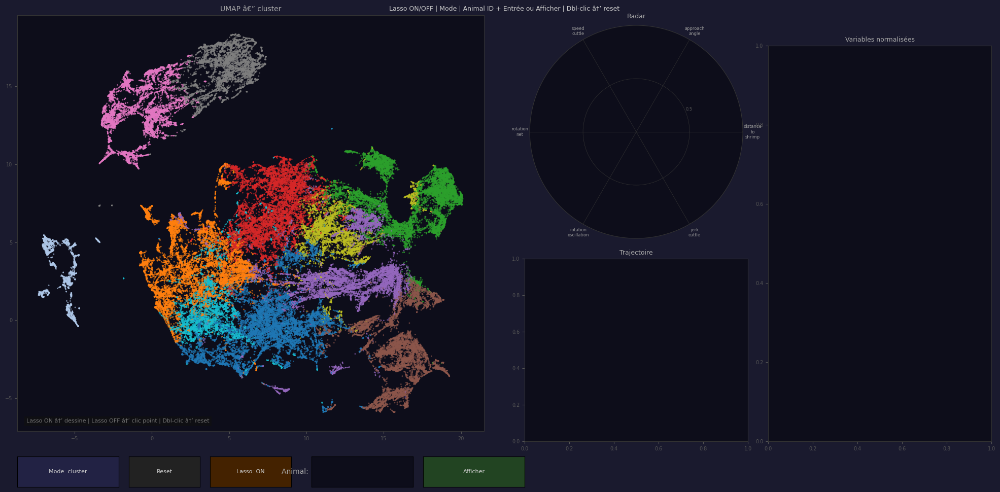

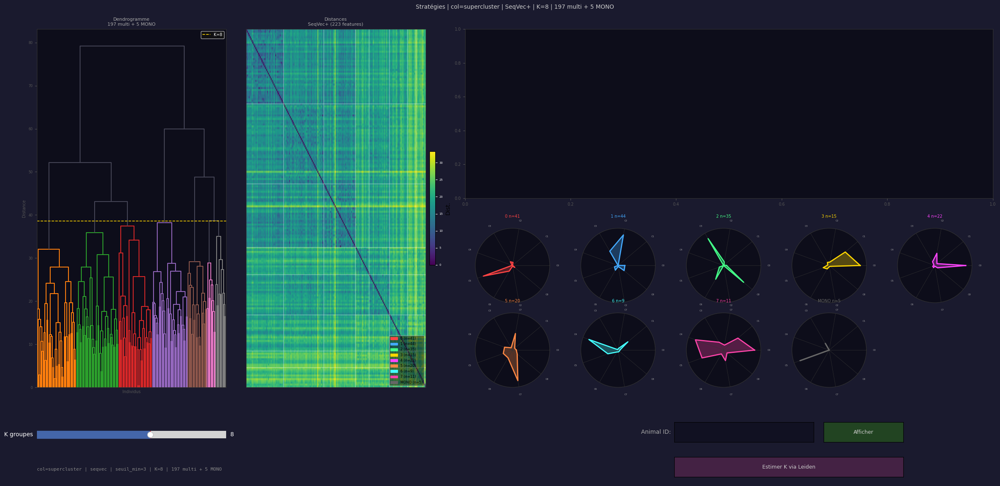

In [21]:
# ── Appel ─────────────────────────────────────────────────────
final_state = show_strategy_explorer(
    df             = df,
    cluster_col    = "supercluster",
    n_strategies   = 4,
    seuil_min      = 3,
    use_leiden_k   = True,
    linkage_method = "ward",
    w_hist         = 1.0,
    w_trans        = 1.0,
    w_runlen       = 1.0,
    w_firstapp     = 1.0,
    w_temporal     = 1.0,
    w_context      = 1.0,
    w_global       = 1.0,
)



In [22]:
# CELLULE — show_power_analysis + optimal_regroupement
#  Calculs sur les features SeqVec (cohérent avec le clustering)
# ══════════════════════════════════════════════════════════════

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
from scipy import stats
from scipy.stats import mannwhitneyu
from itertools import combinations
from collections import Counter


def build_seqvec_features_per_individual(final_state, normalize=False):
    """
    Reconstruit les features SeqVec pour chaque individu.
    Utilisé pour les tests statistiques → normalize=False (valeurs brutes).
    Cohérent avec _seqvec utilisé pour le clustering.
    """
    seqs  = final_state["seqs"]
    n_cl  = final_state["n_cl"]
    ids   = list(seqs.keys())
    rows  = []

    for aid in ids:
        sq, lg = seqs[aid]["seq"], seqs[aid]["lengths"]
        total  = sum(lg)
        if total == 0: continue

        # Proportions
        hist = np.zeros(n_cl)
        for c, l in zip(sq, lg):
            if c < n_cl: hist[c] += l / total

        # Transitions
        trans = np.zeros((n_cl, n_cl))
        for a, b in zip(sq[:-1], sq[1:]):
            if 0 <= a < n_cl and 0 <= b < n_cl:
                trans[a, b] += 1
        rs   = trans.sum(axis=1, keepdims=True)
        rs[rs == 0] = 1
        trans_norm = (trans / rs).flatten()

        # Durées médianes
        durees = {c: [] for c in range(n_cl)}
        for c, l in zip(sq, lg):
            if c < n_cl: durees[c].append(l)
        runlen = np.array([np.median(durees[c]) if durees[c] else 0
                           for c in range(n_cl)])

        # Première apparition
        firstapp = []
        for c in range(n_cl):
            try:    firstapp.append(sq.index(c) / len(sq))
            except: firstapp.append(1.0)
        firstapp = np.array(firstapp)

        # Métriques globales
        n_used   = len(set(sq))
        entropy  = 0.0
        h_vals   = hist[hist > 0]
        if len(h_vals) > 1:
            entropy = -np.sum(h_vals * np.log(h_vals)) / np.log(n_cl)

        row = {}
        for c in range(n_cl):
            row[f"hist_C{c}"]     = hist[c]
            row[f"runlen_C{c}"]   = runlen[c]
            row[f"firstapp_C{c}"] = firstapp[c]
        for i in range(n_cl):
            for j in range(n_cl):
                row[f"trans_{i}_{j}"] = trans_norm[i * n_cl + j]
        row["entropy"]      = entropy
        row["n_cl_used"]    = n_used / n_cl
        row["inertia"]      = hist.max()
        row["total_frames"] = total
        rows.append({"animal_id": str(aid), **row})

    df_seq = pd.DataFrame(rows).set_index("animal_id")
    df_seq = df_seq.fillna(0)

    if normalize:
        from sklearn.preprocessing import StandardScaler
        df_seq = pd.DataFrame(
            StandardScaler().fit_transform(df_seq.values),
            index=df_seq.index, columns=df_seq.columns)

    print(f"[SEQ FEATURES] {df_seq.shape[0]} individus × "
          f"{df_seq.shape[1]} features (brutes)")
    return df_seq


def _bh_correction(p_values, alpha=0.05):
    """
    Correction Benjamini-Hochberg (FDR).
    Retourne un array booléen : True = significatif après correction.
    """
    p   = np.array(p_values)
    n   = len(p)
    if n == 0: return np.array([], dtype=bool)
    ranked  = np.argsort(p)
    seuils  = (np.arange(1, n+1) / n) * alpha
    passed  = p[ranked] < seuils
    sig     = np.zeros(n, dtype=bool)
    if passed.any():
        last = np.where(passed)[0][-1]
        sig[ranked[:last+1]] = True
    return sig


def show_power_analysis(final_state, df,
                        features         = None,
                        use_raw_features = False,
                        top_pct_features = 1.0,    # 1.0 = garder toutes
                        alpha            = 0.05,
                        power_target     = 0.80):
    """
    Analyse de puissance statistique.

    use_raw_features : True  → Cohen's d sur features comportementales brutes
                               (distance, vitesse...) — plus interprétable
                       False → Cohen's d sur features SeqVec (défaut)

    top_pct_features : proportion des features les plus discriminantes
                       à garder pour le calcul du Cohen's d.
                       1.0 = toutes (défaut)
                       0.2 = top 20% les plus discriminantes
                       → utile pour réduire le bruit des features peu
                         informatives qui tirent la médiane vers le bas
    """
    strat = final_state["strat"]
    mono  = final_state["mono"]

    # ── Choix des features ────────────────────────────────────
    df_w = df.copy()
    df_w["animal_id"] = df_w["animal_id"].astype(str)

    if use_raw_features and features is not None:
        # Features comportementales brutes — moyenne par individu
        # Plus interprétable biologiquement, Cohen's d naturellement
        # plus grand car les features sont dans des échelles réelles
        df_indiv  = df_w.groupby("animal_id")[features].mean()
        feat_cols = list(features)
        feat_label = f"features brutes ({len(feat_cols)})"
    else:
        # Features SeqVec — 184 features abstraites
        df_indiv  = build_seqvec_features_per_individual(
                        final_state, normalize=False)
        feat_cols = list(df_indiv.columns)
        feat_label = f"SeqVec brutes ({len(feat_cols)} features)"

    df_indiv["groupe"] = [strat.get(str(aid), "MONO")
                          for aid in df_indiv.index]
    df_indiv = df_indiv.dropna(subset=feat_cols)

    strategy_list = sorted(set(strat.values()))
    all_groups    = strategy_list + (["MONO"] if mono else [])

    # ── Filtre features discriminantes ────────────────────────
    # Garde seulement les top_pct_features% les plus discriminantes
    # Critère : ratio variance inter-groupes / variance totale (η²)
    # → évite que les features non-discriminantes tirent Cohen's d
    #   vers le bas et sous-estiment la puissance
    if top_pct_features < 1.0 and len(feat_cols) > 5:
        scores = []
        grand_mean = df_indiv[feat_cols].mean()
        for feat in feat_cols:
            var_total = df_indiv[feat].var()
            if var_total < 1e-10:
                scores.append(0); continue
            var_inter = 0
            for g in strategy_list:
                mask = df_indiv["groupe"] == g
                if mask.sum() < 2: continue
                ng = mask.sum()
                mg = df_indiv.loc[mask, feat].mean()
                var_inter += ng * (mg - grand_mean[feat])**2
            var_inter /= max(len(df_indiv) - 1, 1)
            scores.append(var_inter / (var_total + 1e-10))

        threshold = np.percentile(scores, (1 - top_pct_features) * 100)
        feat_cols = [f for f, s in zip(feat_cols, scores)
                     if s >= threshold]
        feat_label += f" → top {int(top_pct_features*100)}%"
        print(f"[FILTER] {len(feat_cols)} features retenues "
              f"(top {int(top_pct_features*100)}% discriminantes)")

    pal         = {s: STRATEGY_PALETTE[i % len(STRATEGY_PALETTE)]
                   for i, s in enumerate(all_groups)}
    pal["MONO"] = "#666666"

    # ── N min théoriques ──────────────────────────────────────
    z_alpha = stats.norm.ppf(1 - alpha/2)
    z_beta  = stats.norm.ppf(power_target)

    def n_min_for_d(d):
        if d <= 0: return np.inf
        return int(np.ceil((z_alpha + z_beta)**2 / (2 * d**2)))

    n_min_large  = n_min_for_d(0.8)
    n_min_medium = n_min_for_d(0.5)
    n_min_small  = n_min_for_d(0.2)

    group_sizes = {g: int((df_indiv["groupe"] == g).sum())
                   for g in all_groups}

    # ── Calcul paires avec BH ─────────────────────────────────
    pairs        = list(combinations(strategy_list, 2))
    pair_results = []

    for g1, g2 in pairs:
        mask1    = df_indiv["groupe"] == g1
        mask2    = df_indiv["groupe"] == g2
        n1, n2   = mask1.sum(), mask2.sum()

        if n1 < 2 or n2 < 2:
            pair_results.append({
                "g1": g1, "g2": g2, "n1": n1, "n2": n2,
                "cohens_d": 0, "power_obs": 0,
                "p_value": 1.0, "significant": False,
                "n_min_needed": np.inf,
            }); continue

        ds, ps = [], []
        for feat in feat_cols:
            x1 = df_indiv.loc[mask1, feat].dropna().values
            x2 = df_indiv.loc[mask2, feat].dropna().values
            if len(x1) < 2 or len(x2) < 2: continue
            ps_std = np.sqrt((x1.std()**2 + x2.std()**2) / 2)
            ds.append(abs(x1.mean() - x2.mean()) / (ps_std + 1e-9))
            try:
                _, p = mannwhitneyu(x1, x2, alternative="two-sided")
                ps.append(p)
            except:
                ps.append(1.0)

        mean_d = float(np.median(ds)) if ds else 0.0
        p_min  = float(np.min(ps))    if ps else 1.0
        n_obs  = min(n1, n2)
        n_need = n_min_for_d(mean_d)

        if n_need > 0 and n_need < np.inf:
            ratio     = n_obs / n_need
            power_obs = float(np.clip(stats.norm.cdf(
                z_beta * np.sqrt(ratio)
                - z_alpha * (1/np.sqrt(ratio) - 1)), 0, 1))
        else:
            power_obs = 0.0

        pair_results.append({
            "g1": g1, "g2": g2, "n1": n1, "n2": n2,
            "cohens_d":    round(mean_d, 3),
            "power_obs":   round(power_obs, 3),
            "p_value":     round(p_min, 4),
            "significant": False,
            "n_min_needed": n_need,
        })

    df_pairs = pd.DataFrame(pair_results)

    # Correction BH
    if len(df_pairs) > 0:
        sig_bh = _bh_correction(df_pairs["p_value"].values, alpha)
        df_pairs["significant"] = sig_bh
        print(f"[BH] {sig_bh.sum()}/{len(sig_bh)} paires significatives "
              f"après correction Benjamini-Hochberg")

    # ── Scores ────────────────────────────────────────────────
    n_tot        = len(strategy_list)
    n_ok         = sum(1 for g, n in group_sizes.items()
                       if g != "MONO" and n >= n_min_medium)
    score_size   = n_ok / n_tot if n_tot > 0 else 0
    score_power  = df_pairs["power_obs"].mean()   if len(df_pairs) > 0 else 0
    score_sig    = df_pairs["significant"].mean() if len(df_pairs) > 0 else 0
    score_global = score_power * 0.5 + score_sig * 0.3 + score_size * 0.2

    pair_labels  = [f"{r.g1} ↔ {r.g2}" for r in df_pairs.itertuples()]

    # ════════════════════════════════════════════════════════
    # FIGURE 1 — Tailles des groupes
    # ════════════════════════════════════════════════════════
    groups_plot = [g for g in all_groups if g != "MONO"]
    sizes_plot  = [group_sizes[g] for g in groups_plot]

    fig1, ax = plt.subplots(figsize=(max(8, len(groups_plot)*0.6), 5))
    fig1.patch.set_facecolor("#1a1a2e"); ax.set_facecolor("#0d0d1a")
    bars = ax.bar(groups_plot, sizes_plot,
                  color=[pal[g] for g in groups_plot],
                  edgecolor="#222", linewidth=0.8, alpha=0.9)
    for bar, n in zip(bars, sizes_plot):
        ax.text(bar.get_x()+bar.get_width()/2, n+0.05, str(n),
                ha="center", va="bottom", color="white",
                fontsize=9, fontweight="bold")
    ymax = max(sizes_plot + [n_min_small]) * 1.25
    ax.axhline(n_min_large,  color="#44ff44", lw=1.5, ls="--",
               label=f"Grand effet d=0.8 → n≥{n_min_large}")
    ax.axhline(n_min_medium, color="#ffaa00", lw=1.5, ls="--",
               label=f"Effet moyen d=0.5 → n≥{n_min_medium}")
    ax.axhline(n_min_small,  color="#ff4444", lw=1.5, ls="--",
               label=f"Petit effet d=0.2 → n≥{n_min_small}")
    ax.axhspan(0,            n_min_large,  alpha=0.07, color="#ff4444")
    ax.axhspan(n_min_large,  n_min_medium, alpha=0.07, color="#ffaa00")
    ax.axhspan(n_min_medium, ymax,         alpha=0.04, color="#44ff44")
    ax.set_ylim(0, ymax)
    ax.set_title(f"Taille des groupes vs N minimal requis\n"
                 f"(α={alpha}, puissance cible={int(power_target*100)}%)",
                 color="#cccccc", fontsize=11)
    ax.set_ylabel("N individus", color="#aaaaaa")
    ax.tick_params(colors="#aaaaaa", axis="x", rotation=45)
    ax.tick_params(colors="#aaaaaa", axis="y")
    for sp in ax.spines.values(): sp.set_edgecolor("#333333")
    leg = ax.legend(fontsize=8, loc="upper right")
    leg.get_frame().set_facecolor("#111111")
    for t in leg.get_texts(): t.set_color("white")
    plt.tight_layout(); plt.show()

    # ════════════════════════════════════════════════════════
    # FIGURE 2 — Cohen's d
    # ════════════════════════════════════════════════════════
    if len(df_pairs) > 0:
        ds_vals  = df_pairs["cohens_d"].values
        d_colors = ["#44ff44" if d >= 0.8
                    else "#ffaa00" if d >= 0.5
                    else "#ff4444" for d in ds_vals]

        fig2, ax = plt.subplots(figsize=(8, max(4, len(pair_labels)*0.35)))
        fig2.patch.set_facecolor("#1a1a2e"); ax.set_facecolor("#0d0d1a")
        ax.barh(range(len(pair_labels)), ds_vals, color=d_colors,
                edgecolor="#222", linewidth=0.5, alpha=0.9)
        for i, d in enumerate(ds_vals):
            ax.text(d+0.01, i, f"{d:.2f}", va="center",
                    color="white", fontsize=7)
        ax.axvline(0.8, color="#44ff44", lw=1.5, ls="--",
                   label="Grand effet (0.8)")
        ax.axvline(0.5, color="#ffaa00", lw=1.5, ls="--",
                   label="Effet moyen (0.5)")
        ax.axvline(0.2, color="#ff4444", lw=1.5, ls="--",
                   label="Petit effet (0.2)")
        ax.set_yticks(range(len(pair_labels)))
        ax.set_yticklabels(pair_labels, fontsize=8, color="#cccccc")
        ax.set_xlabel(f"Cohen's d médian ({feat_label})",
                      color="#aaaaaa")
        ax.set_title("Taille d'effet entre chaque paire de groupes",
                     color="#cccccc", fontsize=11)
        ax.tick_params(colors="#aaaaaa")
        for sp in ax.spines.values(): sp.set_edgecolor("#333333")
        leg = ax.legend(fontsize=8, loc="lower right")
        leg.get_frame().set_facecolor("#111111")
        for t in leg.get_texts(): t.set_color("white")
        plt.tight_layout(); plt.show()

    # ════════════════════════════════════════════════════════
    # FIGURE 3 — Puissance
    # ════════════════════════════════════════════════════════
    if len(df_pairs) > 0:
        powers   = df_pairs["power_obs"].values
        p_colors = ["#44ff44" if p >= power_target
                    else "#ffaa00" if p >= 0.5
                    else "#ff4444" for p in powers]

        fig3, ax = plt.subplots(figsize=(8, max(4, len(pair_labels)*0.35)))
        fig3.patch.set_facecolor("#1a1a2e"); ax.set_facecolor("#0d0d1a")
        ax.barh(range(len(pair_labels)), powers, color=p_colors,
                edgecolor="#222", linewidth=0.5, alpha=0.9)
        for i, p in enumerate(powers):
            ax.text(p+0.01, i, f"{p:.0%}", va="center",
                    color="white", fontsize=7)
        ax.axvline(power_target, color="#FFD700", lw=2, ls="--",
                   label=f"Cible {int(power_target*100)}%")
        ax.axvline(0.5, color="#888888", lw=1, ls=":",
                   label="Seuil 50%")
        ax.set_xlim(0, 1.1)
        ax.set_yticks(range(len(pair_labels)))
        ax.set_yticklabels(pair_labels, fontsize=8, color="#cccccc")
        ax.set_xlabel("Puissance statistique estimée", color="#aaaaaa")
        ax.set_title(f"Puissance par paire — correction BH\n"
                     f"(vert ≥ {int(power_target*100)}%, orange ≥ 50%, rouge < 50%)",
                     color="#cccccc", fontsize=11)
        ax.tick_params(colors="#aaaaaa")
        for sp in ax.spines.values(): sp.set_edgecolor("#333333")
        leg = ax.legend(fontsize=8)
        leg.get_frame().set_facecolor("#111111")
        for t in leg.get_texts(): t.set_color("white")
        plt.tight_layout(); plt.show()

    # ════════════════════════════════════════════════════════
    # FIGURE 4 — Tableau
    # ════════════════════════════════════════════════════════
    if len(df_pairs) > 0:
        headers    = ["G1","G2","n1","n2","Cohen d",
                      "Puissance","p-val (BH)","Sig ?","N manquant"]
        table_data = []
        for r in df_pairs.itertuples():
            n_need   = r.n_min_needed
            n_manque = (max(0, n_need - min(r.n1, r.n2))
                        if n_need < np.inf else "∞")
            table_data.append([
                r.g1, r.g2, str(r.n1), str(r.n2),
                f"{r.cohens_d:.2f}",
                f"{r.power_obs:.0%}",
                f"{r.p_value:.4f}",
                "✓" if r.significant else "✗",
                str(int(n_manque)) if isinstance(n_manque, (int,float))
                else n_manque,
            ])

        fig4, ax = plt.subplots(
            figsize=(14, max(3, len(table_data)*0.4+1)))
        fig4.patch.set_facecolor("#1a1a2e")
        ax.set_facecolor("#0d0d1a"); ax.axis("off")
        tbl = ax.table(cellText=table_data, colLabels=headers,
                       loc="center", cellLoc="center")
        tbl.auto_set_font_size(False); tbl.set_fontsize(9); tbl.scale(1, 1.6)
        for (row, col), cell in tbl.get_celld().items():
            cell.set_edgecolor("#333333")
            if row == 0:
                cell.set_facecolor("#1a1a3e")
                cell.set_text_props(color="white", fontweight="bold")
            else:
                cell.set_facecolor("#0d0d1a")
                cell.set_text_props(color="#cccccc")
                if col == 5:
                    try:
                        p = float(table_data[row-1][5].strip("%"))/100
                        cell.set_facecolor(
                            "#1a3a1a" if p >= power_target
                            else "#3a2a00" if p >= 0.5 else "#3a0000")
                    except: pass
                if col == 7:
                    cell.set_facecolor(
                        "#1a3a1a" if table_data[row-1][7]=="✓"
                        else "#3a0000")
                if col == 8:
                    try:
                        nm = int(table_data[row-1][8])
                        cell.set_facecolor(
                            "#1a3a1a" if nm == 0
                            else "#3a2a00" if nm <= 5 else "#3a0000")
                    except: pass
        ax.set_title(
            "Tableau récapitulatif — correction Benjamini-Hochberg\n"
            "'N manquant' = individus supplémentaires pour la puissance cible",
            color="#cccccc", fontsize=11, pad=15)
        plt.tight_layout(); plt.show()

    # ════════════════════════════════════════════════════════
    # FIGURE 5 — Score global
    # ════════════════════════════════════════════════════════
    fig5, ax = plt.subplots(figsize=(7, 5))
    fig5.patch.set_facecolor("#1a1a2e")
    ax.set_facecolor("#0d0d1a"); ax.axis("off")
    for sp in ax.spines.values(): sp.set_edgecolor("#333333")

    score_color = ("#44ff44" if score_global >= 0.7
                   else "#ffaa00" if score_global >= 0.4 else "#ff4444")
    verdict = ("✅ Découpage statistiquement solide"        if score_global >= 0.7
               else "🟡 Découpage acceptable, à consolider" if score_global >= 0.4
               else "🔴 Puissance insuffisante — envisager de regrouper")

    ax.text(0.5, 0.92, f"Score global : {score_global:.0%}",
            ha="center", va="center", fontsize=24,
            color=score_color, fontweight="bold",
            transform=ax.transAxes)
    ax.text(0.5, 0.78, verdict, ha="center", va="center",
            fontsize=12, color=score_color, transform=ax.transAxes)

    for i, (label, val, col) in enumerate([
        ("Puissance moyenne entre paires (×0.5)",
         f"{score_power:.0%}",
         "#44ff44" if score_power >= 0.7 else "#ffaa00"
         if score_power >= 0.4 else "#ff4444"),
        ("Proportion paires significatives BH (×0.3)",
         f"{score_sig:.0%}",
         "#44ff44" if score_sig >= 0.7 else "#ffaa00"
         if score_sig >= 0.4 else "#ff4444"),
        ("Proportion groupes taille OK (×0.2)",
         f"{score_size:.0%}",
         "#44ff44" if score_size >= 0.7 else "#ffaa00"
         if score_size >= 0.4 else "#ff4444"),
    ]):
        y = 0.60 - i * 0.12
        ax.text(0.05, y, f"• {label}", ha="left", va="center",
                fontsize=9, color="#aaaaaa", transform=ax.transAxes)
        ax.text(0.95, y, val, ha="right", va="center",
                fontsize=11, color=col, fontweight="bold",
                transform=ax.transAxes)

    for i, line in enumerate([
        f"N min grand effet (d=0.8) : {n_min_large} individus/groupe",
        f"N min effet moyen (d=0.5) : {n_min_medium} individus/groupe",
        f"N min petit effet (d=0.2) : {n_min_small} individus/groupe",
        f"Correction : Benjamini-Hochberg  |  α={alpha}",
        f"Features : {feat_label}",
    ]):
        ax.text(0.5, 0.22 - i*0.07, line, ha="center", va="center",
                fontsize=8, color="#666666", transform=ax.transAxes,
                fontfamily="monospace")

    ax.set_title(f"Résumé — {n_tot} groupes | α={alpha} | "
                 f"puissance cible={int(power_target*100)}%",
                 color="#cccccc", fontsize=11)
    plt.tight_layout(); plt.show()

    print(f"\n{'='*55}")
    print(f"PUISSANCE — {n_tot} groupes | α={alpha} | "
          f"cible={int(power_target*100)}%")
    print(f"  Features  : {feat_label}")
    print(f"  Correction: Benjamini-Hochberg (FDR)")
    print(f"  N min (d=0.8): {n_min_large} | (d=0.5): {n_min_medium} "
          f"| (d=0.2): {n_min_small}")
    print(f"  Tailles   : { {g: n for g, n in group_sizes.items()} }")
    print(f"  Score     : {score_global:.0%}  ({verdict})")

    return df_pairs




# ══════════════════════════════════════════════════════════════

def optimal_regroupement(
    final_state,
    df,
    alpha         = 0.05,
    power_target  = 0.80,
    target_effect = 0.5,
    min_groups    = 2,
    d_max_fusion  = 0.8,
    verbose       = True,
):
    """
    Fusionne itérativement les groupes en utilisant la matrice D
    de SeqVec — cohérent avec le clustering initial.

    d_max_fusion : Cohen's d maximum pour autoriser une fusion forcée.
                   Si la paire la plus proche a d > d_max_fusion,
                   on arrête même si certains groupes sont trop petits.
                   Évite de fusionner des groupes très différents.
    """
    seqs = final_state["seqs"]
    D    = final_state["D"]
    ids  = final_state["multi"]   # liste dans le même ordre que D

    # N minimal pour l'effet cible
    z_alpha = stats.norm.ppf(1 - alpha/2)
    z_beta  = stats.norm.ppf(power_target)
    n_min   = int(np.ceil((z_alpha + z_beta)**2 / (2 * target_effect**2)))

    # Mapping courant
    mapping = {str(aid): g for aid, g in final_state["strat"].items()}
    for m in final_state["mono"]:
        mapping[str(m)] = "MONO"

    # Index des individus dans la matrice D
    id_to_idx = {str(aid): i for i, aid in enumerate(ids)}

    history = []

    def get_sizes(mapping):
        return dict(Counter(v for v in mapping.values() if v != "MONO"))

    def get_distance_D(g1, g2):
        """
        Distance moyenne dans l'espace SeqVec entre les deux groupes.
        Utilise la matrice D déjà calculée → cohérent avec le clustering.
        """
        idx1 = [id_to_idx[aid] for aid in mapping
                if mapping[aid] == g1 and aid in id_to_idx]
        idx2 = [id_to_idx[aid] for aid in mapping
                if mapping[aid] == g2 and aid in id_to_idx]
        if not idx1 or not idx2: return np.inf
        sub = D[np.ix_(idx1, idx2)]
        return float(sub.mean())

    def all_ok(mapping, n_min, min_groups):
        sizes = get_sizes(mapping)
        if len(sizes) <= min_groups: return True
        return all(n >= n_min for n in sizes.values())

    if verbose:
        sizes_init = get_sizes(mapping)
        print(f"\n{'='*60}")
        print(f"REGROUPEMENT OPTIMAL")
        print(f"  features     : SeqVec (matrice D du clustering)")
        print(f"  n_min (d={target_effect}, puissance={int(power_target*100)}%) = {n_min}")
        print(f"  d_max_fusion : {d_max_fusion}")
        print(f"  Groupes initiaux : {sizes_init}")
        print(f"{'='*60}")

        # Afficher aussi les target_effect recommandés
        if len(final_state.get("D", [])) > 0:
            df_pairs_preview = []
            non_mono = sorted(set(v for v in mapping.values() if v != "MONO"))
            for g1, g2 in combinations(non_mono, 2):
                d = get_distance_D(g1, g2)
                df_pairs_preview.append(d)
            if df_pairs_preview:
                print(f"  target_effect_auto   : "
                      f"{np.mean(df_pairs_preview):.3f}")
                print(f"  target_effect_median : "
                      f"{np.median(df_pairs_preview):.3f}")
                print(f"  target_effect_p25    : "
                      f"{np.percentile(df_pairs_preview, 25):.3f}")

    iteration = 0
    while not all_ok(mapping, n_min, min_groups):
        sizes    = get_sizes(mapping)
        non_mono = sorted(sizes.keys())

        if len(non_mono) <= min_groups:
            if verbose: print(f"[STOP] Nb minimal de groupes atteint")
            break

        small_groups = {g for g in non_mono if sizes[g] < n_min}
        best_pair, best_score, best_d = None, np.inf, np.inf

        for g1, g2 in combinations(non_mono, 2):
            d            = get_distance_D(g1, g2)
            involves_sm  = g1 in small_groups or g2 in small_groups
            score        = d if involves_sm else d + 100
            if score < best_score:
                best_score = score
                best_pair  = (g1, g2)
                best_d     = d

        if best_pair is None: break

        # Vérifier si la fusion est raisonnable
        if best_d > d_max_fusion and not (best_pair[0] in small_groups
                                           or best_pair[1] in small_groups):
            if verbose:
                print(f"[STOP] Fusion suivante trop différente "
                      f"(d={best_d:.3f} > {d_max_fusion})")
            break

        g1, g2    = best_pair
        reason    = ("taille insuffisante" if g1 in small_groups
                     or g2 in small_groups else "groupes les plus similaires")
        # Nouveau label = label le plus petit (alphabétique)
        # évite de toujours absorber dans le grand groupe
        new_label = min(g1, g2)
        mapping   = {aid: (new_label if g in (g1, g2) else g)
                     for aid, g in mapping.items()}
        iteration += 1

        record = {
            "iteration": iteration, "g1": g1, "g2": g2,
            "new_label": new_label, "distance_D": round(best_d, 3),
            "n_g1": sizes[g1], "n_g2": sizes[g2],
            "n_merged": sizes[g1] + sizes[g2], "reason": reason,
        }
        history.append(record)

        if verbose:
            new_sizes = get_sizes(mapping)
            print(f"  [{iteration}] {g1}(n={sizes[g1]}) + "
                  f"{g2}(n={sizes[g2]}) → {new_label}"
                  f"(n={sizes[g1]+sizes[g2]})  "
                  f"d={best_d:.3f}  [{reason}]")
            print(f"       Restants : {new_sizes}")

    if verbose:
        final_sizes = get_sizes(mapping)
        n_ok = sum(1 for n in final_sizes.values() if n >= n_min)
        print(f"\n[RÉSULTAT] {len(final_sizes)} groupes | "
              f"{n_ok}/{len(final_sizes)} atteignent n≥{n_min}")
        print(f"  Tailles finales : {final_sizes}")

    # ════════════════════════════════════════════════════════
    # FIGURE 1 — Avant / Après
    # ════════════════════════════════════════════════════════
    sizes_avant = get_sizes({str(aid): g
                              for aid, g in final_state["strat"].items()})
    sizes_apres = get_sizes(mapping)

    fig, axes = plt.subplots(1, 2, figsize=(16, 5))
    fig.patch.set_facecolor("#1a1a2e")

    for ax, (sizes, title) in zip(axes, [
        (sizes_avant, f"Avant  ({len(sizes_avant)} groupes)"),
        (sizes_apres, f"Après  ({len(sizes_apres)} groupes)"),
    ]):
        ax.set_facecolor("#0d0d1a")
        for sp in ax.spines.values(): sp.set_edgecolor("#333333")
        ax.tick_params(colors="#aaaaaa")
        groups = sorted(sizes.keys())
        vals   = [sizes[g] for g in groups]
        colors = [STRATEGY_PALETTE[i % len(STRATEGY_PALETTE)]
                  for i in range(len(groups))]
        bars = ax.bar(groups, vals, color=colors,
                      edgecolor="#222", linewidth=0.8, alpha=0.9)
        for bar, n in zip(bars, vals):
            ax.text(bar.get_x()+bar.get_width()/2, n+0.05, str(n),
                    ha="center", va="bottom", color="white",
                    fontsize=9, fontweight="bold")
        ax.axhline(n_min, color="#FFD700", lw=2, ls="--",
                   label=f"n_min={n_min} (d={target_effect})")
        ax.axhspan(0, n_min, alpha=0.06, color="#ff4444")
        ax.axhspan(n_min, max(vals+[n_min])*1.3, alpha=0.04, color="#44ff44")
        ax.set_ylim(0, max(vals+[n_min])*1.3)
        ax.set_title(title, color="#cccccc", fontsize=11)
        ax.set_ylabel("N individus", color="#aaaaaa")
        ax.tick_params(axis="x", rotation=45)
        leg = ax.legend(fontsize=8)
        leg.get_frame().set_facecolor("#111111")
        for t in leg.get_texts(): t.set_color("white")

    fig.suptitle(
        f"Regroupement optimal | n_min={n_min} | "
        f"{len(history)} fusions | distance SeqVec",
        color="#cccccc", fontsize=12)
    plt.tight_layout(); plt.show()

    # ════════════════════════════════════════════════════════
    # FIGURE 2 — Log des fusions
    # ════════════════════════════════════════════════════════
    if history:
        df_hist = pd.DataFrame(history)
        fig2, axes2 = plt.subplots(1, 2,
                                    figsize=(14, max(3, len(history)*0.5+1)))
        fig2.patch.set_facecolor("#1a1a2e")

        labels_fus = [f"{r.g1}+{r.g2}→{r.new_label}"
                      for r in df_hist.itertuples()]

        # Distance SeqVec des fusions
        ax = axes2[0]
        ax.set_facecolor("#0d0d1a")
        for sp in ax.spines.values(): sp.set_edgecolor("#333333")
        d_colors = ["#44ff44" if d < 2 else "#ffaa00" if d < 5 else "#ff4444"
                    for d in df_hist["distance_D"]]
        ax.barh(range(len(labels_fus)), df_hist["distance_D"],
                color=d_colors, edgecolor="#222", alpha=0.9)
        for i, (d, r) in enumerate(zip(df_hist["distance_D"],
                                        df_hist.itertuples())):
            ax.text(d+0.05, i, f"d={d:.2f}  [{r.reason}]",
                    va="center", color="#cccccc", fontsize=8)
        ax.set_yticks(range(len(labels_fus)))
        ax.set_yticklabels(labels_fus, fontsize=8, color="#cccccc")
        ax.set_xlabel("Distance SeqVec moyenne entre les groupes",
                      color="#aaaaaa")
        ax.set_title("Ordre et raison des fusions\n"
                     "(vert=très proches, rouge=forcé par taille)",
                     color="#cccccc", fontsize=10)
        ax.tick_params(colors="#aaaaaa")

        # Tailles fusionnées
        ax2 = axes2[1]
        ax2.set_facecolor("#0d0d1a")
        for sp in ax2.spines.values(): sp.set_edgecolor("#333333")
        ax2.barh(range(len(df_hist)), df_hist["n_g1"],
                 color="#4466aa", alpha=0.8, label="n(G1)", edgecolor="#222")
        ax2.barh(range(len(df_hist)), df_hist["n_g2"],
                 left=df_hist["n_g1"],
                 color="#aa6644", alpha=0.8, label="n(G2)", edgecolor="#222")
        ax2.axvline(n_min, color="#FFD700", lw=2, ls="--",
                    label=f"n_min={n_min}")
        ax2.set_yticks(range(len(labels_fus)))
        ax2.set_yticklabels(labels_fus, fontsize=8, color="#cccccc")
        ax2.set_xlabel("Taille des groupes fusionnés", color="#aaaaaa")
        ax2.set_title("Taille des groupes avant fusion",
                      color="#cccccc", fontsize=10)
        ax2.tick_params(colors="#aaaaaa")
        leg2 = ax2.legend(fontsize=8)
        leg2.get_frame().set_facecolor("#111111")
        for t in leg2.get_texts(): t.set_color("white")

        fig2.suptitle("Détail des fusions", color="#cccccc", fontsize=11)
        plt.tight_layout(); plt.show()

    non_mono_groups = sorted(set(v for v in mapping.values() if v != "MONO"))
    num_to_letter   = {g: chr(65+i) for i, g in enumerate(non_mono_groups)}

    mapping_letters = {
        aid: (num_to_letter[g] if g != "MONO" else "MONO")
        for aid, g in mapping.items()
    }

    print(f"\n[LETTRES] {len(non_mono_groups)} groupes → "
          f"{list(num_to_letter.values())}")

    return mapping_letters, history 


In [23]:
final_state

{'seqs': {'1': {'seq': [6,
    5,
    0,
    5,
    8,
    5,
    3,
    0,
    3,
    8,
    3,
    0,
    3,
    6,
    3,
    6,
    8,
    3,
    8,
    3,
    8,
    3,
    0,
    3,
    8,
    3,
    8,
    3,
    8,
    3],
   'lengths': [5,
    9,
    38,
    16,
    6,
    13,
    13,
    20,
    6,
    18,
    23,
    12,
    29,
    3,
    18,
    13,
    21,
    4,
    6,
    25,
    28,
    185,
    7,
    25,
    7,
    83,
    19,
    8,
    4,
    166]},
  '10': {'seq': [5, 6, 5, 6], 'lengths': [11, 3, 27, 14]},
  '100': {'seq': [7, 4, 7, 6, 2, 6, 8, 2, 7, 2, 5, 7, 5, 2, 8, 2, 8, 5, 8, 6],
   'lengths': [9,
    3,
    28,
    13,
    33,
    3,
    64,
    22,
    4,
    3,
    4,
    9,
    4,
    19,
    8,
    3,
    24,
    6,
    3,
    3]},
  '101': {'seq': [5, 6, 5, 8], 'lengths': [69, 3, 143, 3]},
  '102': {'seq': [6, 2, 7, 0, 7, 2, 7, 0, 7, 5, 6],
   'lengths': [5, 126, 3, 14, 14, 9, 43, 3, 137, 95, 27]},
  '103': {'seq': [7,
    4,
    1,
    4,
    1,
    4,


[BH] 28/28 paires significatives après correction Benjamini-Hochberg


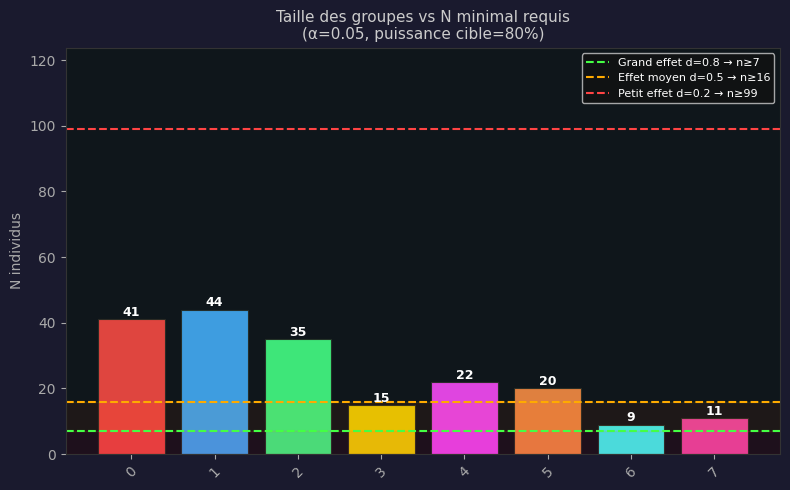

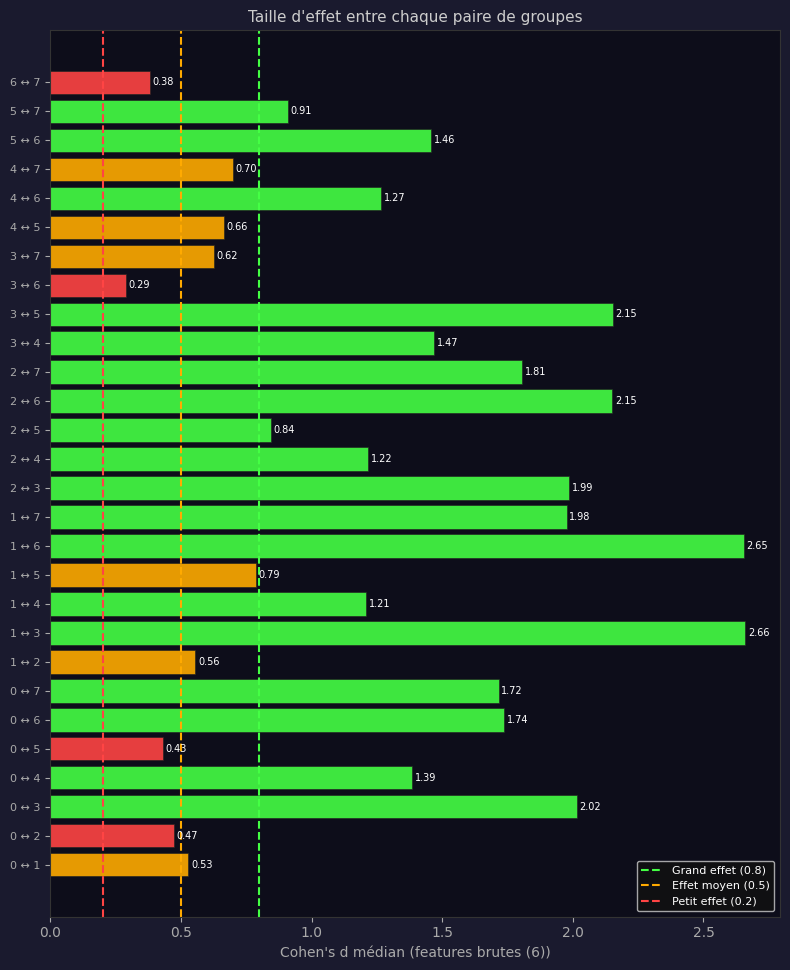

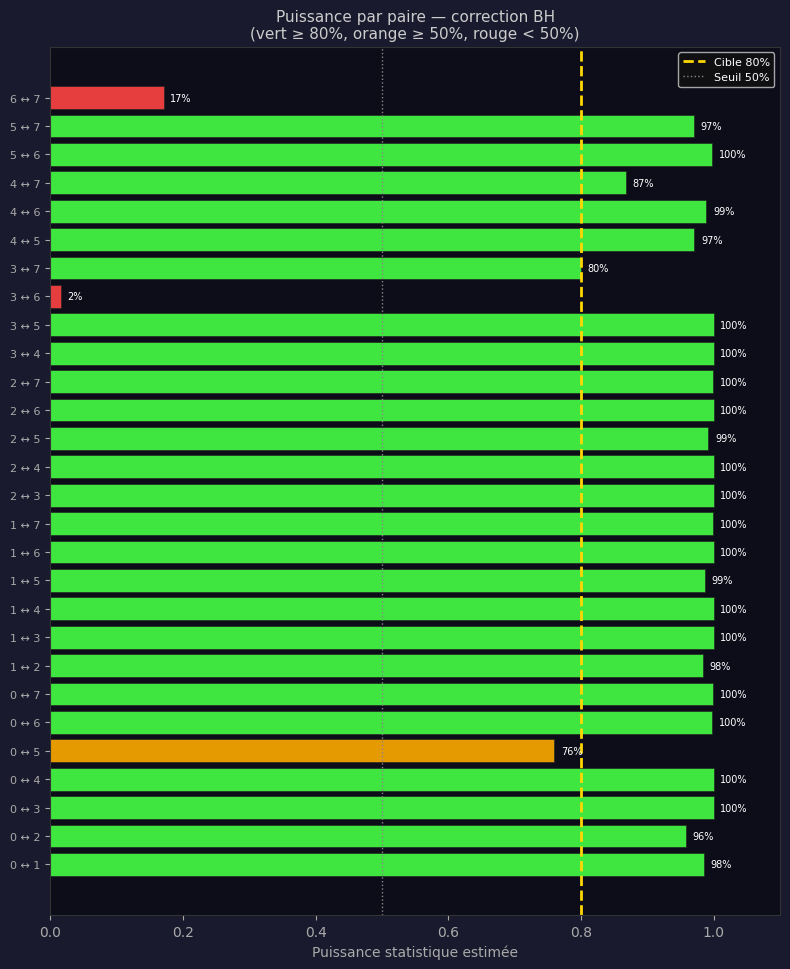

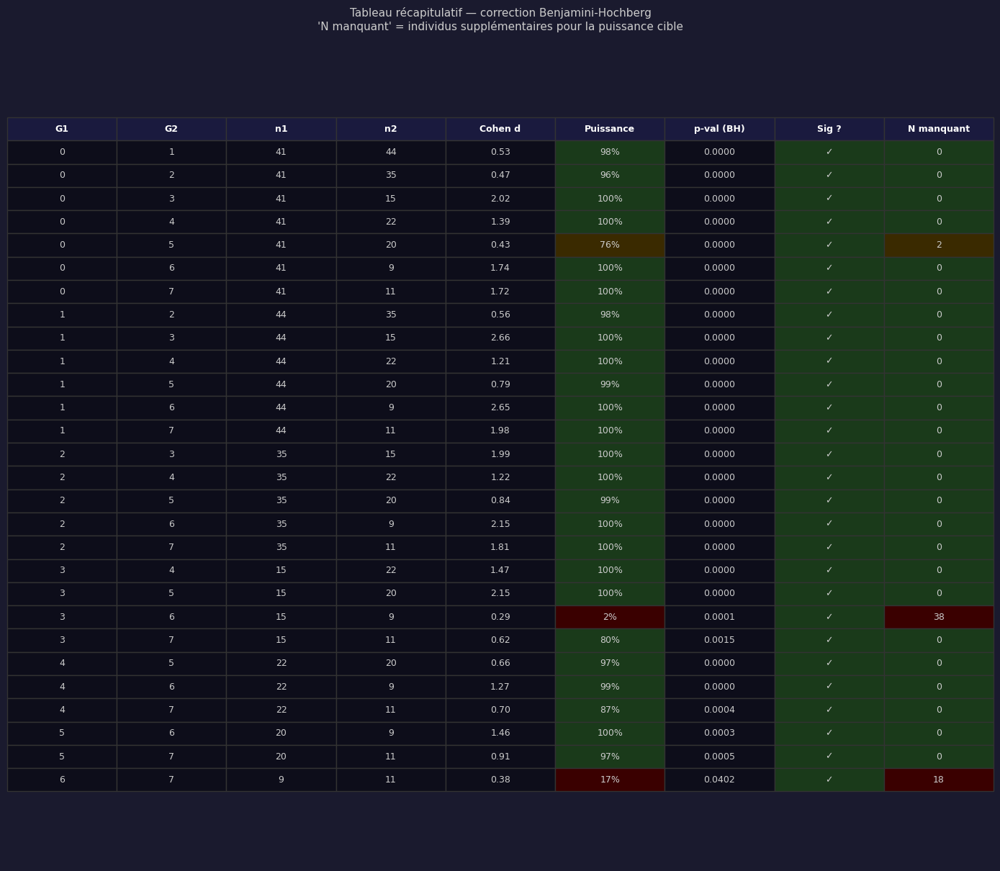

C:\Users\nonoh\AppData\Local\Temp\ipykernel_28408\1134909822.py:503: UserWarning: Glyph 9989 (\N{WHITE HEAVY CHECK MARK}) missing from font(s) DejaVu Sans.
  plt.tight_layout(); plt.show()
c:\Users\nonoh\anaconda3\envs\cuttlestrike\Lib\site-packages\IPython\core\pylabtools.py:170: UserWarning: Glyph 9989 (\N{WHITE HEAVY CHECK MARK}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)


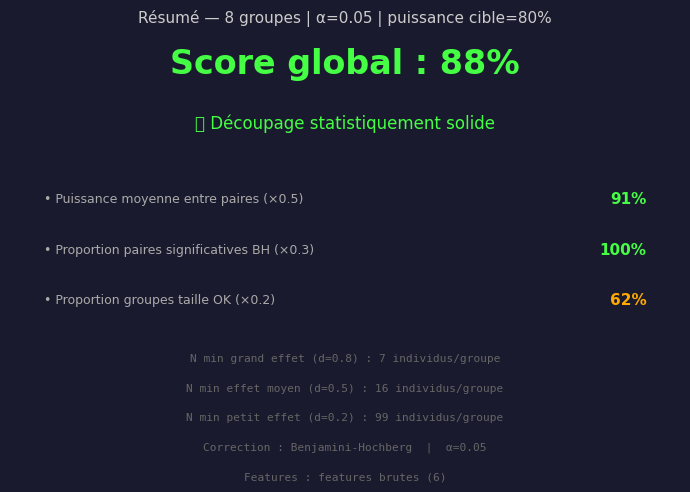


PUISSANCE — 8 groupes | α=0.05 | cible=80%
  Features  : features brutes (6)
  Correction: Benjamini-Hochberg (FDR)
  N min (d=0.8): 7 | (d=0.5): 16 | (d=0.2): 99
  Tailles   : {'0': 41, '1': 44, '2': 35, '3': 15, '4': 22, '5': 20, '6': 9, '7': 11, 'MONO': 5}
  Score     : 88%  (✅ Découpage statistiquement solide)


In [24]:
# ── Appels ────────────────────────────────────────────────────
# ── Appels ────────────────────────────────────────────────────

# Option A — features brutes (recommandé pour la puissance)
df_pairs = show_power_analysis(
    final_state, df,
    features         = FEATURES,
    use_raw_features = True,
    top_pct_features = 1.0,
    alpha            = 0.05,
    power_target     = 0.80,
)



REGROUPEMENT OPTIMAL
  features     : SeqVec (matrice D du clustering)
  n_min (d=0.75, puissance=95%) = 12
  d_max_fusion : 0.8
  Groupes initiaux : {'1': 44, '0': 41, '5': 20, '6': 9, '4': 22, '7': 11, '2': 35, '3': 15}
  target_effect_auto   : 21.568
  target_effect_median : 21.852
  target_effect_p25    : 19.775
  [1] 0(n=41) + 6(n=9) → 0(n=50)  d=22.989  [taille insuffisante]
       Restants : {'1': 44, '0': 50, '5': 20, '4': 22, '7': 11, '2': 35, '3': 15}
  [2] 4(n=22) + 7(n=11) → 4(n=33)  d=23.087  [taille insuffisante]
       Restants : {'1': 44, '0': 50, '5': 20, '4': 33, '2': 35, '3': 15}

[RÉSULTAT] 6 groupes | 6/6 atteignent n≥12
  Tailles finales : {'1': 44, '0': 50, '5': 20, '4': 33, '2': 35, '3': 15}


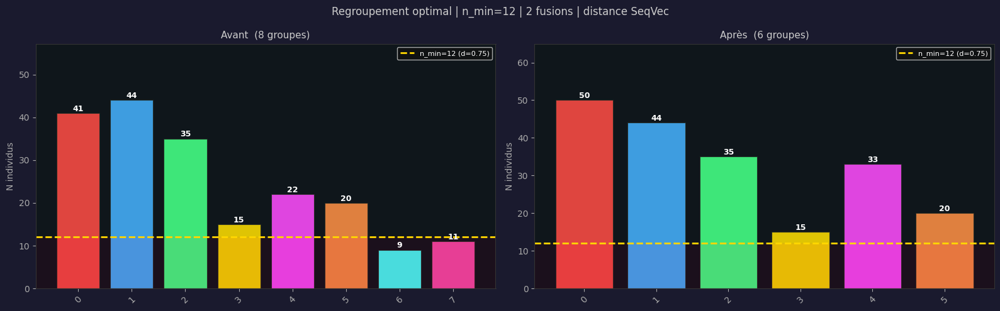

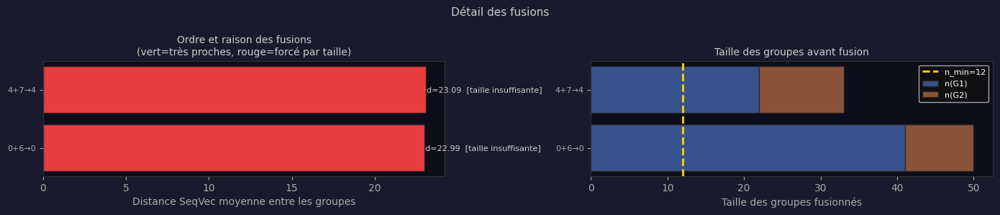


[LETTRES] 6 groupes → ['A', 'B', 'C', 'D', 'E', 'F']


In [25]:
# Selon ce que tu veux détecter :
#target_effect = 0.8   # grand effet  → n_min ≈ 26  → peu de fusions
#target_effect = 0.5   # effet moyen  → n_min ≈ 64  → fusions modérées
#target_effect = 0.2   # petit effet  → n_min ≈ 394 → beaucoup de fusions

# Pour tes données (200 individus, ~20 groupes initiaux)
# → 0.5 est raisonnable comme point de départ
mapping_optimal, history = optimal_regroupement(
    final_state,
    df,
    alpha         = 0.05,
    power_target  = 0.95,
    target_effect = 0.75,   # ← fixe
    min_groups    = 2,
    d_max_fusion  = 0.8,
    verbose       = True,
)

In [26]:
#def plot_strategy_profiles

from scipy.spatial.distance import cdist
import matplotlib.colors as mcolors


def plot_strategy_profiles(mapping_optimal, final_state, df, features=FEATURES,
                           cmap_cl=None, norm_cl=None):

    # Valeurs par défaut si non fournies
    n_cl_local = final_state["n_cl"]
    if cmap_cl is None:
        cmap_cl = CMAP_CLUSTER
    if norm_cl is None:
        norm_cl = NORM_CLUSTER

    seqs = final_state["seqs"]
    n_cl = final_state["n_cl"]

    df_w = df.copy()
    df_w["animal_id"] = df_w["animal_id"].astype(str)

    unique_groups = sorted(set(v for v in mapping_optimal.values() if v != "MONO"))
    num_to_letter = {g: chr(65+i) for i, g in enumerate(unique_groups)}
    num_to_letter["MONO"] = "MONO"
    mapping_letters  = {aid: num_to_letter[g] for aid, g in mapping_optimal.items()}
    strategy_letters = sorted(set(v for v in mapping_letters.values() if v != "MONO"))
    n_strat          = len(strategy_letters)

    pal         = {s: STRATEGY_PALETTE[i % len(STRATEGY_PALETTE)]
                   for i, s in enumerate(strategy_letters)}
    pal["MONO"] = "#666666"

    # ── DTW pour médoïde ──────────────────────────────────────
    def _dtw(seq_a, seq_b, n_cl):
        if not seq_a or not seq_b: return np.inf
        centers = np.eye(n_cl)
        tA = np.array([centers[min(c, n_cl-1)] for c in seq_a])
        tB = np.array([centers[min(c, n_cl-1)] for c in seq_b])
        TA, TB = len(tA), len(tB)
        cost   = cdist(tA, tB, metric='euclidean')
        D      = np.full((TA, TB), np.inf)
        D[0,0] = cost[0,0]
        for i in range(1, TA): D[i,0] = D[i-1,0] + cost[i,0]
        for j in range(1, TB): D[0,j] = D[0,j-1] + cost[0,j]
        for i in range(1, TA):
            for j in range(1, TB):
                D[i,j] = cost[i,j] + min(D[i-1,j], D[i,j-1], D[i-1,j-1])
        return D[TA-1, TB-1]

    def _medoid(members):
        n = len(members)
        if n == 1: return members[0], seqs[members[0]]["seq"]
        dists = np.zeros(n)
        for i in range(n):
            for j in range(n):
                if i != j:
                    dists[i] += _dtw(seqs[members[i]]["seq"],
                                     seqs[members[j]]["seq"], n_cl)
        best = int(np.argmin(dists))
        return members[best], seqs[members[best]]["seq"]

    angles   = np.linspace(0, 2*np.pi, n_cl, endpoint=False)
    ang_full = np.concatenate([angles, [angles[0]]])

    profiles = {}
    for s in strategy_letters:
        members         = [aid for aid, g in mapping_letters.items() if g == s]
        members_in_seqs = [m for m in members if m in seqs]
        if not members_in_seqs: continue

        hists = []
        for aid in members_in_seqs:
            sq, lg = seqs[aid]["seq"], seqs[aid]["lengths"]
            total  = sum(lg)
            if total == 0: continue
            h = np.zeros(n_cl)
            for c, l in zip(sq, lg):
                if c < n_cl: h[c] += l / total
            hists.append(h)
        mean_hist = np.mean(hists, axis=0) if hists else np.zeros(n_cl)

        print(f"  [MÉDOÏDE] Stratégie {s} ({len(members_in_seqs)} ind)...", end=" ")
        medoid_aid, modal_compressed = _medoid(members_in_seqs)
        print(f"-> ID {medoid_aid}")

        durees = {c: [] for c in range(n_cl)}
        for aid in members_in_seqs:
            for c, l in zip(seqs[aid]["seq"], seqs[aid]["lengths"]):
                if c < n_cl: durees[c].append(l)
        median_durees = {c: np.median(durees[c]) if durees[c] else 0
                         for c in range(n_cl)}

        trans_count = {}
        for aid in members_in_seqs:
            sq = seqs[aid]["seq"]
            for a, b in zip(sq[:-1], sq[1:]):
                trans_count[(a,b)] = trans_count.get((a,b), 0) + 1
        top_trans = sorted(trans_count.items(), key=lambda x: -x[1])[:3]

        feat_means = {}
        if features:
            ids_str = [str(m) for m in members_in_seqs]
            mask    = df_w["animal_id"].isin(ids_str)
            if mask.any():
                feat_means = df_w[mask][features].mean().to_dict()

        profiles[s] = {
            "members"         : members_in_seqs,
            "all_members"     : members,
            "n"               : len(members_in_seqs),
            "mean_hist"       : mean_hist,
            "modal_seq"       : modal_compressed,
            "medoid_aid"      : medoid_aid,
            "median_durees"   : median_durees,
            "top_transitions" : top_trans,
            "dominant_cluster": int(np.argmax(mean_hist)),
            "feat_means"      : feat_means,
            "mean_seq_len"    : np.mean([len(seqs[a]["seq"])
                                         for a in members_in_seqs]),
            "mean_n_clusters" : np.mean([len(set(seqs[a]["seq"]))
                                         for a in members_in_seqs]),
        }
    print(f"[DEBUG] mapping_optimal sample : {list(mapping_optimal.items())[:5]}")
    print(f"[DEBUG] mapping_letters sample : {list(mapping_letters.items())[:5]}")
    print(f"[DEBUG] strategy_letters : {strategy_letters}")
    print(f"[DEBUG] seqs keys sample : {list(seqs.keys())[:5]}")

    for s in strategy_letters:
        members = [aid for aid, g in mapping_letters.items() if g == s]
        in_seqs = [m for m in members if m in seqs]
        print(f"  {s} : {len(members)} membres, {len(in_seqs)} dans seqs")
    # ════════════════════════════════════════════════════════
    # FIGURE 1 — Radars
    # ════════════════════════════════════════════════════════
    n_cols = min(4, n_strat)
    n_rows = (n_strat + n_cols - 1) // n_cols
    fig1   = plt.figure(figsize=(n_cols * 5, n_rows * 5))
    fig1.patch.set_facecolor("#1a1a2e")
    fig1.suptitle("Profils comportementaux des stratégies",
                  color="#cccccc", fontsize=13, y=1.01)

    for si, s in enumerate(strategy_letters):
        if s not in profiles: continue
        p   = profiles[s]
        col = pal[s]
        ax  = fig1.add_subplot(n_rows, n_cols, si+1, polar=True)
        ax.set_facecolor("#0d0d1a")
        vals_f = np.concatenate([p["mean_hist"], [p["mean_hist"][0]]])
        ax.plot(ang_full, vals_f, lw=2.5, color=col)
        ax.fill(ang_full, vals_f, alpha=0.3, color=col)
        ax.set_xticks(angles)
        ax.set_xticklabels([f"C{c}" for c in range(n_cl)],
                            fontsize=7, color="#aaaaaa")
        ax.set_ylim(0, max(p["mean_hist"].max()*1.2, 0.01))
        ax.set_yticks([])
        ax.grid(color="#333333", lw=0.5)
        ax.spines["polar"].set_color("#333333")
        modal_str = "→".join([f"C{c}" for c in p["modal_seq"][:6]])
        if len(p["modal_seq"]) > 6: modal_str += "…"
        ax.set_title(
            f"Stratégie {s}  (n={p['n']})\n"
            f"Dominant : C{p['dominant_cluster']}\n"
            f"Médoïde : ID {p['medoid_aid']}\n"
            f"{modal_str}",
            color=col, fontsize=9, pad=12
        )
    plt.tight_layout(); plt.show()

    # ════════════════════════════════════════════════════════
    # FIGURE 2 — Séquence MÉDOÏDE (1 vrai individu)
    # Amélioration visuelle : blocs fusionnés, épaisseur par durée
    # ════════════════════════════════════════════════════════
    fig2, axes = plt.subplots(n_strat, 1,
                               figsize=(14, max(3, n_strat * 1.6)))
    fig2.patch.set_facecolor("#1a1a2e")
    fig2.suptitle(
        "Séquence médoïde par stratégie\n"
        "(individu réel le plus représentatif — médoïde DTW)\n"
        "largeur ∝ durée | blocs consécutifs identiques fusionnés",
        color="#cccccc", fontsize=11
    )
    if n_strat == 1: axes = [axes]

    for si, (s, ax) in enumerate(zip(strategy_letters, axes)):
        if s not in profiles: continue
        p    = profiles[s]
        col  = pal[s]

        # Séquence du médoïde (vrai individu)
        seq_raw  = seqs[p["medoid_aid"]]["seq"]
        lgts_raw = seqs[p["medoid_aid"]]["lengths"]

        # ── Fusion des blocs consécutifs identiques ───────────
        # Évite la répétition visuelle C0 C0 C0 → un seul grand C0
        seq_fused, lgts_fused = [], []
        for c, l in zip(seq_raw, lgts_raw):
            if seq_fused and seq_fused[-1] == c:
                lgts_fused[-1] += l
            else:
                seq_fused.append(c)
                lgts_fused.append(l)

        ax.set_facecolor("#0d0d1a")
        for sp in ax.spines.values(): sp.set_edgecolor("#333333")
        ax.set_yticks([])
        ax.tick_params(colors="#555555", labelsize=7)

        x    = 0
        dmax = max(lgts_fused) if lgts_fused else 1
        for c, dur in zip(seq_fused, lgts_fused):
            c_color = mcolors.to_hex(cmap_cl(norm_cl(c)))

            # Hauteur proportionnelle à la durée → blocs importants = plus épais
            h = 0.35 + 0.55 * (dur / dmax)

            ax.barh(0, dur, left=x, height=h,
                    color=c_color, edgecolor="#0d0d1a", lw=0.8,
                    alpha=0.9)

            # Label uniquement si le bloc est assez large
            if dur >= dmax * 0.04:
                fontsize = min(9, max(5, int(7 * dur / dmax * 3)))
                ax.text(x + dur/2, 0, f"C{c}",
                        ha="center", va="center",
                        fontsize=fontsize, color="white",
                        fontweight="bold")
            x += dur

        ax.set_xlim(0, x)
        ax.set_ylim(-0.55, 0.55)

        # Barre de couleur du groupe sur la gauche
        ax.barh(0, x * 0.008, left=-x*0.015, height=1.1,
                color=col, alpha=0.9)

        total_frames = sum(lgts_fused)
        n_blocs_orig = len(seq_raw)
        n_blocs_fus  = len(seq_fused)

        trans_str = "  |  ".join(
            [f"C{a}→C{b} ({n}×)" for (a,b), n in p["top_transitions"]]
        )

        ax.set_ylabel(
            f"Strat. {s}\nn={p['n']}\nID {p['medoid_aid']}",
            color=col, fontsize=8, rotation=0,
            ha="right", va="center", labelpad=60
        )
        ax.text(x * 1.005, 0.25,
                f"{total_frames}f",
                va="center", ha="left", fontsize=6, color="#666666")
        ax.text(x * 1.005, -0.25,
                f"{n_blocs_fus} blocs ({n_blocs_orig} brut)",
                va="center", ha="left", fontsize=6, color="#555555")
        ax.text(x * 1.005, 0.0,
                f"↑ {trans_str}",
                va="center", ha="left", fontsize=6, color="#777777")

    plt.tight_layout(); plt.show()

    # ════════════════════════════════════════════════════════
    # FIGURE 3 — Tableau de synthèse + liste des individus
    # ════════════════════════════════════════════════════════
    fig3, ax = plt.subplots(figsize=(18, max(3, n_strat * 0.9 + 1.5)))
    fig3.patch.set_facecolor("#1a1a2e")
    ax.set_facecolor("#0d0d1a"); ax.axis("off")

    headers = (["Stratégie", "N", "Médoïde", "Cluster dominant",
                "Blocs moy.", "Clusters dist.", "Top transition",
                "Individus (IDs)"]
               + [f.replace("_"," ")[:10] for f in features])

    table_data = []
    for s in strategy_letters:
        if s not in profiles: continue
        p = profiles[s]

        top_t = (f"C{p['top_transitions'][0][0][0]}→"
                 f"C{p['top_transitions'][0][0][1]}"
                 if p["top_transitions"] else "—")

        # Liste des individus — triée, séparée par virgules
        ids_str = ", ".join(sorted([str(m) for m in p["members"]]))
        # Tronquer si trop long pour le tableau
        if len(ids_str) > 60:
            ids_str = ids_str[:57] + "…"

        row = [
            f"  {s}  ",
            str(p["n"]),
            str(p["medoid_aid"]),
            f"C{p['dominant_cluster']}  ({p['mean_hist'][p['dominant_cluster']]:.0%})",
            f"{p['mean_seq_len']:.1f}",
            f"{p['mean_n_clusters']:.1f}",
            top_t,
            ids_str,
        ]
        for feat in features:
            v = p["feat_means"].get(feat, np.nan)
            row.append(f"{v:.2f}" if not np.isnan(v) else "—")
        table_data.append(row)

    tbl = ax.table(cellText=table_data, colLabels=headers,
                   loc="center", cellLoc="center")
    tbl.auto_set_font_size(False)
    tbl.set_fontsize(7)
    tbl.scale(1, 2.2)

    for (row, col_idx), cell in tbl.get_celld().items():
        cell.set_edgecolor("#333333")
        if row == 0:
            cell.set_facecolor("#1a1a3e")
            cell.set_text_props(color="white", fontweight="bold")
        else:
            s = strategy_letters[row-1] if row-1 < len(strategy_letters) else None
            cell.set_facecolor("#0d0d1a")
            cell.set_text_props(color="#cccccc")
            if col_idx == 0 and s:
                cell.set_facecolor(pal.get(s, "#0d0d1a") + "55")
                cell.set_text_props(color=pal.get(s, "white"),
                                    fontweight="bold")
            # Colonne individus : légèrement colorée
            if col_idx == 7 and s:
                cell.set_facecolor(pal.get(s, "#0d0d1a") + "22")
                cell.set_text_props(color="#aaaaaa", fontsize=6)

    ax.set_title("Tableau de synthèse — médoïde DTW + liste des individus",
                 color="#cccccc", fontsize=11, pad=15)
    plt.tight_layout(); plt.show()

    # ════════════════════════════════════════════════════════
    # FIGURE 4 — Liste détaillée des individus par groupe
    # ════════════════════════════════════════════════════════
    fig4, ax4 = plt.subplots(figsize=(14, max(4, n_strat * 1.2 + 1)))
    fig4.patch.set_facecolor("#1a1a2e")
    ax4.set_facecolor("#0d0d1a"); ax4.axis("off")

    ax4.set_title("Individus par stratégie",
                  color="#cccccc", fontsize=12, pad=10)

    y_pos = 0.97
    step  = 1.0 / (n_strat + 1)

    for s in strategy_letters:
        if s not in profiles: continue
        p   = profiles[s]
        col = pal[s]

        ids_sorted = sorted([str(m) for m in p["members"]])
        ids_chunks = [ids_sorted[i:i+20] for i in range(0, len(ids_sorted), 20)]

        # Label du groupe
        ax4.text(0.01, y_pos,
                 f"Stratégie {s}  (n={p['n']})  —  médoïde : {p['medoid_aid']}",
                 transform=ax4.transAxes,
                 color=col, fontsize=10, fontweight='bold', va='top')

        # IDs sur une ou plusieurs lignes
        for li, chunk in enumerate(ids_chunks):
            ax4.text(0.12, y_pos - 0.015 * (li + 1),
                     "  ".join(chunk),
                     transform=ax4.transAxes,
                     color="#cccccc", fontsize=7, va='top',
                     fontfamily='monospace')

        y_pos -= step

    plt.tight_layout(); plt.show()

    # ── Résumé terminal ───────────────────────────────────────
    print(f"\n{'='*60}")
    print(f"PROFILS ({n_strat} groupes) — médoïdes DTW")
    print(f"{'='*60}")
    for s in strategy_letters:
        if s not in profiles: continue
        p = profiles[s]
        ids_sorted = sorted([str(m) for m in p["members"]])
        print(f"\nStratégie {s}  (n={p['n']})  —  médoïde : ID {p['medoid_aid']}")
        print(f"  Individus : {', '.join(ids_sorted)}")
        print(f"  Dominant  : C{p['dominant_cluster']} "
              f"({p['mean_hist'][p['dominant_cluster']]:.0%})")
        print(f"  Blocs moy : {p['mean_seq_len']:.1f} | "
              f"Clusters dist. : {p['mean_n_clusters']:.1f}")
        if p["top_transitions"]:
            print(f"  Top trans : " +
                  ", ".join([f"C{a}→C{b}({n}×)"
                             for (a,b),n in p["top_transitions"]]))

    return profiles, mapping_letters

  [MÉDOÏDE] Stratégie A (50 ind)... -> ID 89
  [MÉDOÏDE] Stratégie B (44 ind)... -> ID 174
  [MÉDOÏDE] Stratégie C (35 ind)... -> ID 165
  [MÉDOÏDE] Stratégie D (15 ind)... -> ID 64
  [MÉDOÏDE] Stratégie E (33 ind)... -> ID 30
  [MÉDOÏDE] Stratégie F (20 ind)... -> ID 156
[DEBUG] mapping_optimal sample : [('1', 'B'), ('10', 'A'), ('100', 'F'), ('101', 'A'), ('102', 'F')]
[DEBUG] mapping_letters sample : [('1', 'B'), ('10', 'A'), ('100', 'F'), ('101', 'A'), ('102', 'F')]
[DEBUG] strategy_letters : ['A', 'B', 'C', 'D', 'E', 'F']
[DEBUG] seqs keys sample : ['1', '10', '100', '101', '102']
  A : 50 membres, 50 dans seqs
  B : 44 membres, 44 dans seqs
  C : 35 membres, 35 dans seqs
  D : 15 membres, 15 dans seqs
  E : 33 membres, 33 dans seqs
  F : 20 membres, 20 dans seqs


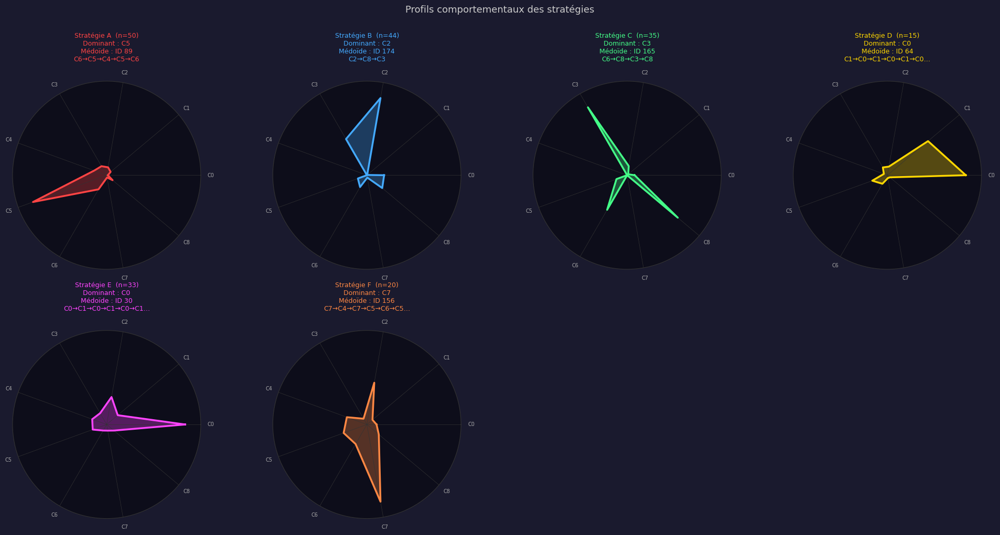

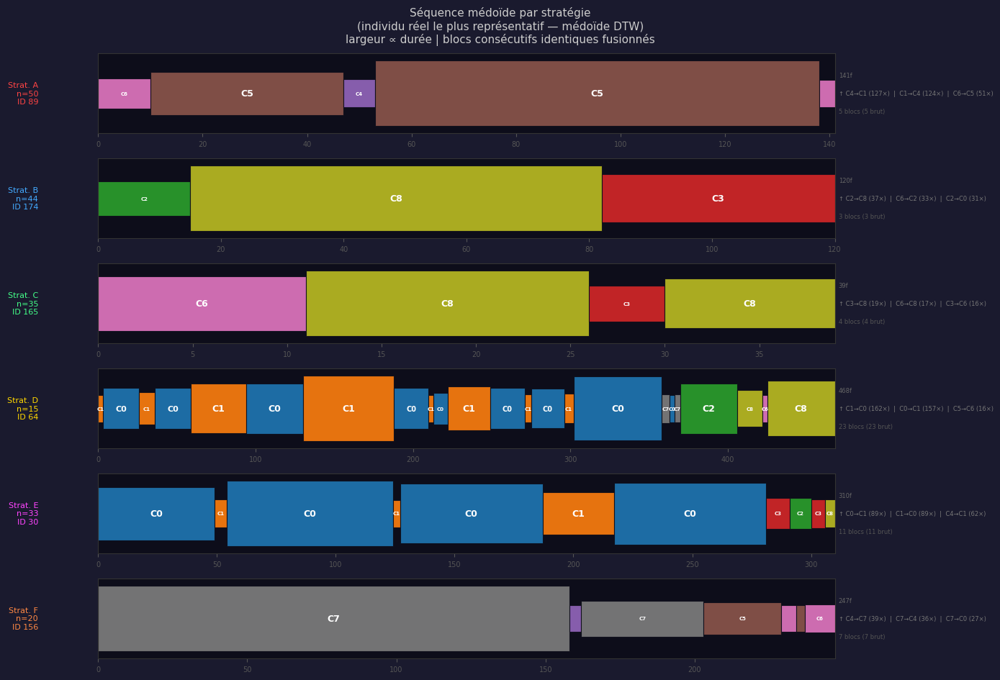

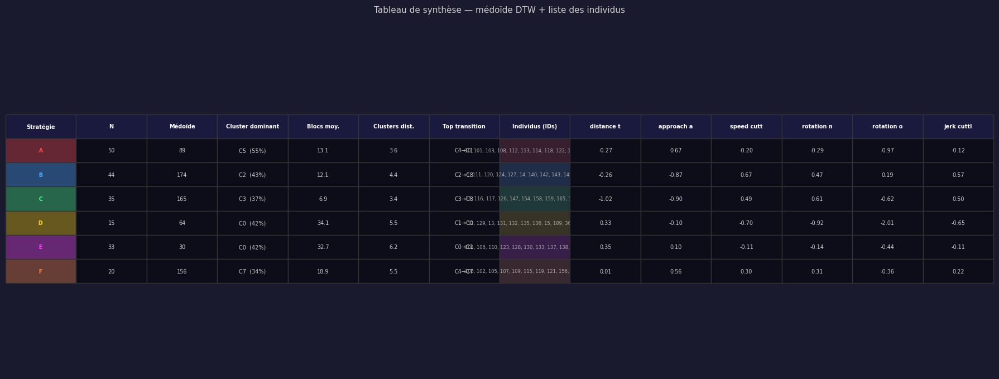

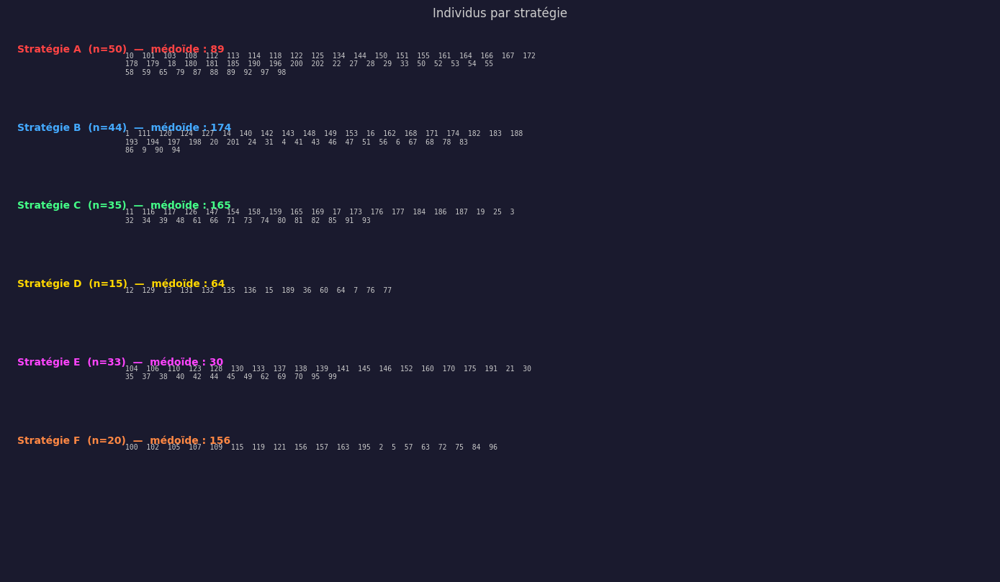


PROFILS (6 groupes) — médoïdes DTW

Stratégie A  (n=50)  —  médoïde : ID 89
  Individus : 10, 101, 103, 108, 112, 113, 114, 118, 122, 125, 134, 144, 150, 151, 155, 161, 164, 166, 167, 172, 178, 179, 18, 180, 181, 185, 190, 196, 200, 202, 22, 27, 28, 29, 33, 50, 52, 53, 54, 55, 58, 59, 65, 79, 87, 88, 89, 92, 97, 98
  Dominant  : C5 (55%)
  Blocs moy : 13.1 | Clusters dist. : 3.6
  Top trans : C4→C1(127×), C1→C4(124×), C6→C5(51×)

Stratégie B  (n=44)  —  médoïde : ID 174
  Individus : 1, 111, 120, 124, 127, 14, 140, 142, 143, 148, 149, 153, 16, 162, 168, 171, 174, 182, 183, 188, 193, 194, 197, 198, 20, 201, 24, 31, 4, 41, 43, 46, 47, 51, 56, 6, 67, 68, 78, 83, 86, 9, 90, 94
  Dominant  : C2 (43%)
  Blocs moy : 12.1 | Clusters dist. : 4.4
  Top trans : C2→C8(37×), C6→C2(33×), C2→C0(31×)

Stratégie C  (n=35)  —  médoïde : ID 165
  Individus : 11, 116, 117, 126, 147, 154, 158, 159, 165, 169, 17, 173, 176, 177, 184, 186, 187, 19, 25, 3, 32, 34, 39, 48, 61, 66, 71, 73, 74, 80, 81, 82, 85, 9

In [27]:
# Cellule 19 — doit être exécutée AVANT la cellule 30
profiles, mapping_letters = plot_strategy_profiles(
    mapping_optimal,
    final_state,
    df,
    features = FEATURES,
)

strat groupes    : ['A', 'B', 'C', 'D', 'E', 'F']
mapping_letters  : ['A', 'B', 'C', 'D', 'E', 'F', 'MONO']
n_individus      : 197
[BH] 15/15 paires significatives après correction Benjamini-Hochberg


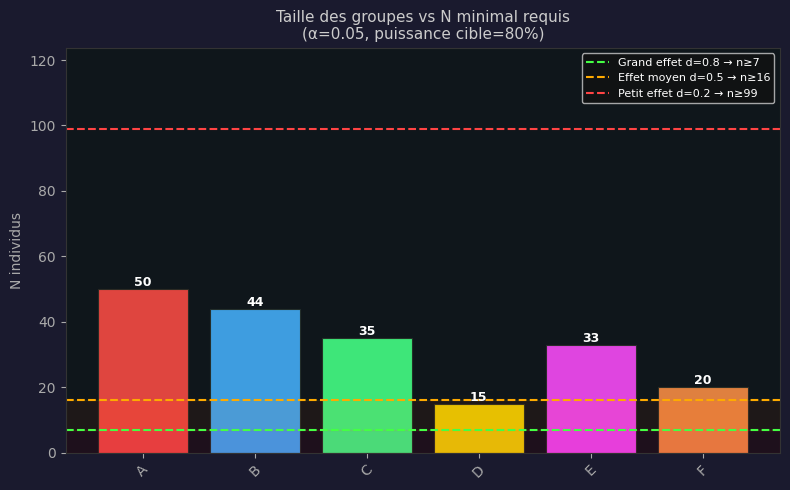

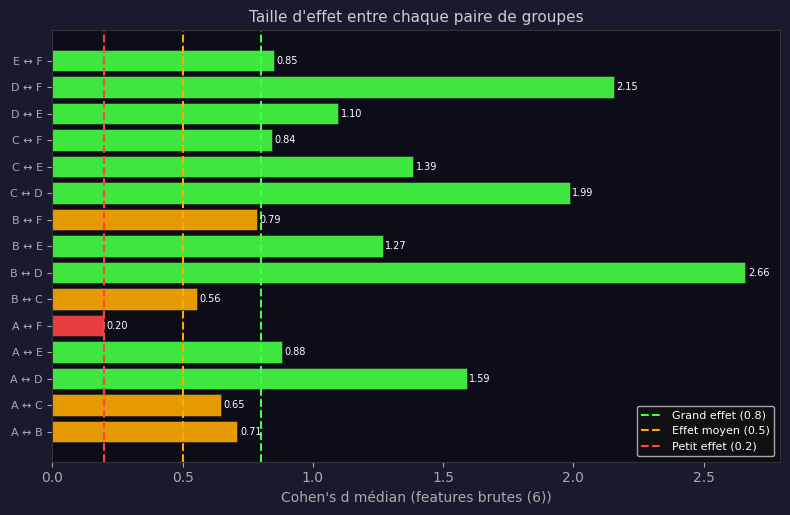

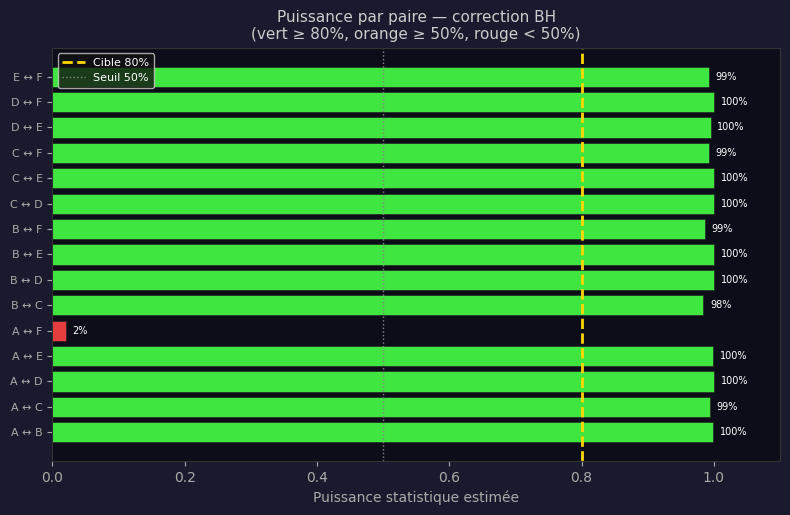

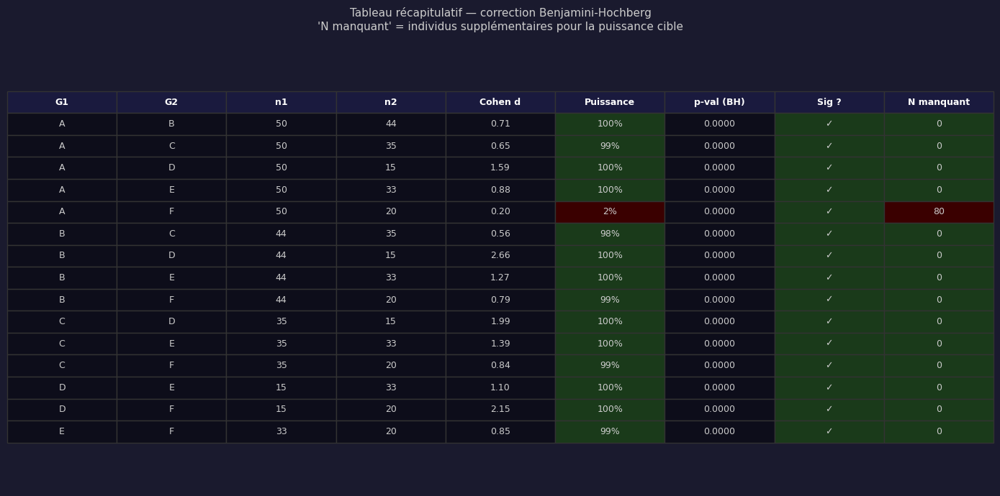

C:\Users\nonoh\AppData\Local\Temp\ipykernel_28408\1134909822.py:503: UserWarning: Glyph 9989 (\N{WHITE HEAVY CHECK MARK}) missing from font(s) DejaVu Sans.
  plt.tight_layout(); plt.show()
c:\Users\nonoh\anaconda3\envs\cuttlestrike\Lib\site-packages\IPython\core\pylabtools.py:170: UserWarning: Glyph 9989 (\N{WHITE HEAVY CHECK MARK}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)


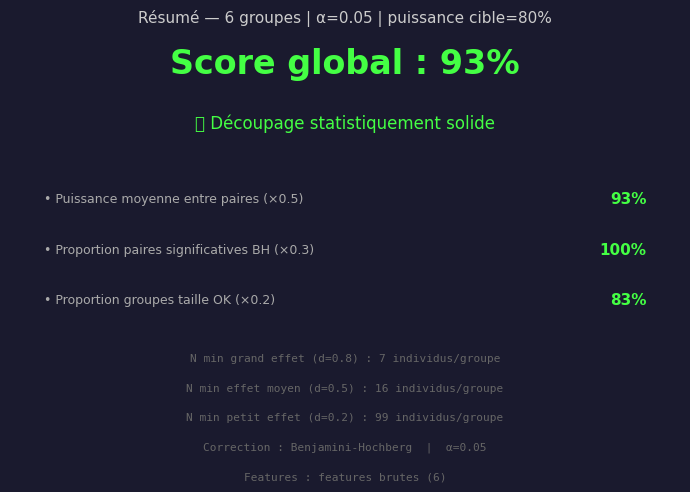


PUISSANCE — 6 groupes | α=0.05 | cible=80%
  Features  : features brutes (6)
  Correction: Benjamini-Hochberg (FDR)
  N min (d=0.8): 7 | (d=0.5): 16 | (d=0.2): 99
  Tailles   : {'A': 50, 'B': 44, 'C': 35, 'D': 15, 'E': 33, 'F': 20, 'MONO': 5}
  Score     : 93%  (✅ Découpage statistiquement solide)


In [28]:
# ── Créer final_state_optimal avec les LETTRES de mapping_optimal ──
# ── Créer final_state_optimal avec les LETTRES de mapping_optimal ──
final_state_optimal = dict(final_state)

final_state_optimal["strat"] = {
    aid: g
    for aid, g in mapping_optimal.items()
    if g != "MONO"
}
final_state_optimal["mono"] = [
    aid for aid, g in mapping_optimal.items()
    if g == "MONO"
]

# ── AJOUTER mapping_letters ────────────────────────────────────
# mapping_optimal contient déjà des lettres (A, B, C...)
# donc mapping_letters = mapping_optimal directement
final_state_optimal["mapping_letters"] = dict(mapping_optimal)

# Vérification
print("strat groupes    :", sorted(set(final_state_optimal["strat"].values())))
print("mapping_letters  :", sorted(set(final_state_optimal["mapping_letters"].values())))
print("n_individus      :", len(final_state_optimal["strat"]))
# ── Appels ────────────────────────────────────────────────────

# Option A — features brutes (recommandé pour la puissance)
df_pairs = show_power_analysis(
    final_state_optimal, df,
    features         = FEATURES,
    use_raw_features = True,
    top_pct_features = 1.0,
    alpha            = 0.05,
    power_target     = 0.80,
)

# # Option B — SeqVec top 20% features discriminantes
# df_pairs = show_power_analysis(
#     final_state_optimal, df,
#     use_raw_features = False,
#     top_pct_features = 0.20,
#     alpha            = 0.05,
#     power_target     = 0.80,
# )


[AUTO] Colonnes position : TopMantle_x / TopMantle_y
Individus par groupe :

  Groupe A (n=50) → exemples : ['122', '144', '28', '53']
  Groupe B (n=44) → exemples : ['124', '198', '120', '149']
  Groupe C (n=35) → exemples : ['184', '32', '61', '71']
  Groupe D (n=15) → exemples : ['131', '12', '15', '135']
  Groupe E (n=33) → exemples : ['170', '44', '141', '145']
  Groupe F (n=20) → exemples : ['109', '63', '163', '5']
  Groupe MONO (n=5) → exemples : ['192', '199', '23', '26']

[OK] → C:\Users\nonoh\Documents\01Travail\02_CREC\cuttle_strike\analysis_results\exemples_trajectoires_par_groupe.png


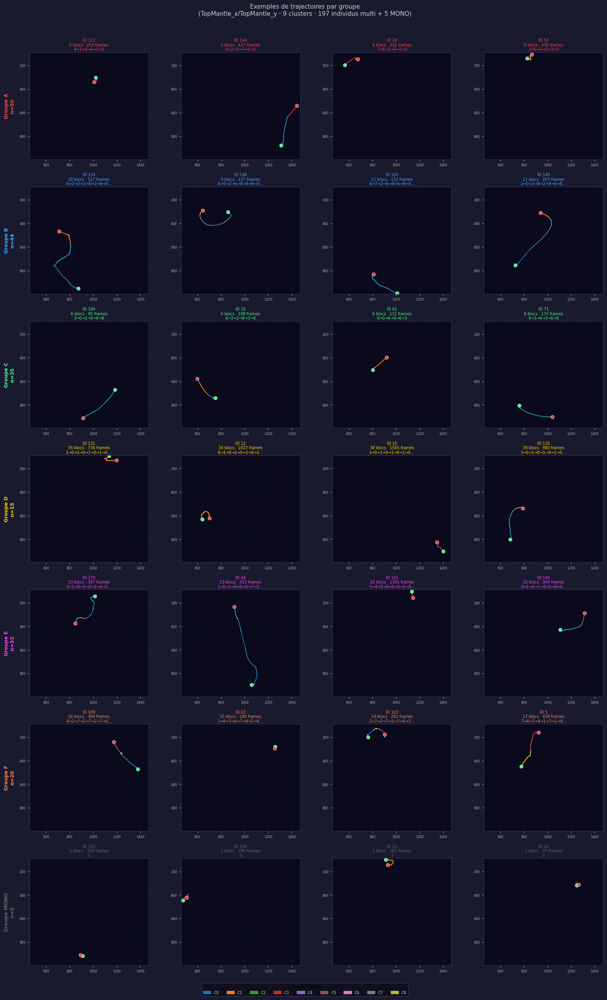


IDs PAR GROUPE — dict

  Groupe A  (n=50)
    Exemples affichés : ['122', '144', '28', '53']
    Tous les IDs      : ['10', '18', '22', '27', '28', '29', '33', '50', '52', '53', '54', '55', '58', '59', '65', '79', '87', '88', '89', '92', '97', '98', '101', '103', '108', '112', '113', '114', '118', '122', '125', '134', '144', '150', '151', '155', '161', '164', '166', '167', '172', '178', '179', '180', '181', '185', '190', '196', '200', '202']

  Groupe B  (n=44)
    Exemples affichés : ['124', '198', '120', '149']
    Tous les IDs      : ['1', '4', '6', '9', '14', '16', '20', '24', '31', '41', '43', '46', '47', '51', '56', '67', '68', '78', '83', '86', '90', '94', '111', '120', '124', '127', '140', '142', '143', '148', '149', '153', '162', '168', '171', '174', '182', '183', '188', '193', '194', '197', '198', '201']

  Groupe C  (n=35)
    Exemples affichés : ['184', '32', '61', '71']
    Tous les IDs      : ['3', '11', '17', '19', '25', '32', '34', '39', '48', '61', '66', '71', '73', '

In [29]:
# ══════════════════════════════════════════════════════════════
#  EXEMPLES DE TRAJECTOIRES PAR GROUPE — version configurable
# ══════════════════════════════════════════════════════════════

# ── Paramètres à changer ici ──────────────────────────────────
FINAL_STATE_TO_USE = final_state_optimal  # ← final_state | final_state_optimal
DF_TO_USE          = df                   # ← df | df_shrimp | autre
N_EXEMPLES         = 4                    # ← entre 2 et 5

# Colonnes de position à utiliser pour tracer la trajectoire
# Seiche  : "body_cx" / "body_cy"  ou  "TopMantle_x" / "TopMantle_y"
# Crevette: "HeadShrimp_x" / "HeadShrimp_y"
X_COL = "body_cx"        # ← changer selon le df
Y_COL = "body_cy"        # ← changer selon le df

# Fichier de sortie
OUT_PATH = OUT_DIR / "exemples_trajectoires_par_groupe.png"


# ══════════════════════════════════════════════════════════════
#  CODE — ne pas modifier en dessous
# ══════════════════════════════════════════════════════════════

strat_final     = FINAL_STATE_TO_USE["strat"]
mono_final      = FINAL_STATE_TO_USE["mono"]
seqs            = FINAL_STATE_TO_USE["seqs"]
n_cl            = FINAL_STATE_TO_USE["n_cl"]
mapping_letters = FINAL_STATE_TO_USE["mapping_letters"]

df_plot = DF_TO_USE.copy()
df_plot["animal_id"] = df_plot["animal_id"].astype(str)

# Fallback si la colonne X/Y n'existe pas
if X_COL not in df_plot.columns:
    fallbacks_x = ["body_cx", "TopMantle_x", "HeadShrimp_x"]
    fallbacks_y = ["body_cy", "TopMantle_y", "HeadShrimp_y"]
    X_COL = next((c for c in fallbacks_x if c in df_plot.columns), None)
    Y_COL = next((c for c in fallbacks_y if c in df_plot.columns), None)
    print(f"[AUTO] Colonnes position : {X_COL} / {Y_COL}")

# ── Grouper les individus ─────────────────────────────────────
groups = {}
for aid, letter in mapping_letters.items():
    groups.setdefault(letter, []).append(str(aid))
groups_sorted = sorted(g for g in groups if g != "MONO")
if "MONO" in groups:
    groups_sorted.append("MONO")

print("Individus par groupe :\n")
for g in groups_sorted:
    ids    = groups[g]
    n_show = min(N_EXEMPLES, len(ids))
    ids_sorted = sorted(
        ids,
        key=lambda a: abs(len(seqs.get(a, {}).get("seq", [])) -
                          np.median([len(seqs.get(x, {}).get("seq", []))
                                     for x in ids])))
    print(f"  Groupe {g} (n={len(ids)}) → exemples : {ids_sorted[:n_show]}")

# ── Limites globales ──────────────────────────────────────────
x_all = df_plot[X_COL].dropna()
y_all = df_plot[Y_COL].dropna()
x_min, x_max = x_all.quantile(0.01), x_all.quantile(0.99)
y_min, y_max = y_all.quantile(0.01), y_all.quantile(0.99)

# ── Palette groupes ───────────────────────────────────────────
pal_strat = {g: STRATEGY_PALETTE[i % len(STRATEGY_PALETTE)]
             for i, g in enumerate(groups_sorted)}
pal_strat["MONO"] = "#666666"

# ── Figure ────────────────────────────────────────────────────
n_groups = len(groups_sorted)
fig, axes = plt.subplots(
    n_groups, N_EXEMPLES,
    figsize=(N_EXEMPLES * 4, n_groups * 3.5),
    squeeze=False)   # squeeze=False → axes toujours 2D
fig.patch.set_facecolor("#1a1a2e")
fig.suptitle(
    f"Exemples de trajectoires par groupe\n"
    f"({X_COL}/{Y_COL} · {n_cl} clusters · "
    f"{len(strat_final)} individus multi + {len(mono_final)} MONO)",
    color="#cccccc", fontsize=11, y=1.01)

for row_i, grp in enumerate(groups_sorted):
    ids      = groups[grp]
    col_grp  = pal_strat[grp]
    n_show   = min(N_EXEMPLES, len(ids))

    # Trier par représentativité (proches de la médiane)
    ids_sorted = sorted(
        ids,
        key=lambda a: abs(len(seqs.get(a, {}).get("seq", [])) -
                          np.median([len(seqs.get(x, {}).get("seq", []))
                                     for x in ids])))
    exemples = ids_sorted[:n_show]

    for col_i in range(N_EXEMPLES):
        ax = axes[row_i, col_i]
        ax.set_facecolor("#0a0a1c")
        for sp in ax.spines.values():
            sp.set_edgecolor("#333366")
        ax.tick_params(colors="#aaaaaa", labelsize=6)

        if col_i >= n_show:
            ax.set_visible(False)
            continue

        aid = exemples[col_i]
        sub = df_plot[df_plot["animal_id"] == aid]

        if len(sub) == 0:
            ax.text(0.5, 0.5, f"ID {aid}\nnon trouvé",
                    ha="center", va="center", color="#ff4444",
                    transform=ax.transAxes, fontsize=8)
            continue

        x = sub[X_COL].values.astype(float)
        y = sub[Y_COL].values.astype(float)

        # Filtre sauts aberrants DLC
        dist = np.sqrt(np.diff(x)**2 + np.diff(y)**2)
        jump = dist > 100
        x_clean = x.copy(); y_clean = y.copy()
        x_clean[1:][jump] = np.nan
        y_clean[1:][jump] = np.nan

        # Colorier par cluster si disponible
        clusters = (sub["cluster"].values
                    if "cluster" in sub.columns else None)

        if clusters is not None:
            for i in range(len(x_clean) - 1):
                if np.isnan(x_clean[i]) or np.isnan(x_clean[i+1]):
                    continue
                c_idx = int(clusters[i]) % len(PALETTE)
                ax.plot(x_clean[i:i+2], y_clean[i:i+2],
                        color=PALETTE[c_idx],
                        alpha=0.7, linewidth=1.2, zorder=2)
        else:
            # Pas de cluster → couleur du groupe
            ax.plot(x_clean, y_clean, color=col_grp,
                    alpha=0.7, linewidth=1.2, zorder=2)

        # Points début / fin
        x_valid = x_clean[~np.isnan(x_clean)]
        y_valid = y_clean[~np.isnan(y_clean)]
        if len(x_valid) > 0:
            ax.scatter(x_valid[0],  y_valid[0],
                       color="#44ff88", s=40, zorder=5,
                       edgecolors="white", linewidths=0.5)
            ax.scatter(x_valid[-1], y_valid[-1],
                       color="#ff4444", s=40, zorder=5,
                       edgecolors="white", linewidths=0.5)

        # Résumé séquence
        sq  = seqs.get(aid, {}).get("seq", [])
        lng = seqs.get(aid, {}).get("lengths", [])
        seq_str = "→".join(str(c) for c in sq[:8])
        if len(sq) > 8: seq_str += "…"

        ax.set_xlim(x_min, x_max)
        ax.set_ylim(y_max, y_min)
        ax.set_aspect("equal")
        ax.grid(alpha=0.1, color="#334466")
        ax.set_title(
            f"ID {aid}\n"
            f"{len(sq)} blocs · {sum(lng)} frames\n"
            f"{seq_str}",
            color=col_grp, fontsize=7, pad=3)

        if col_i == 0:
            ax.set_ylabel(
                f"Groupe {grp}\nn={len(ids)}",
                color=col_grp, fontsize=9,
                fontweight="bold", labelpad=8)

# Légende clusters
patches = [mpatches.Patch(color=PALETTE[c % len(PALETTE)], label=f"C{c}")
           for c in range(n_cl)]
fig.legend(handles=patches, loc="lower center",
           ncol=min(n_cl, 12), fontsize=7,
           facecolor="#0d0d1a", edgecolor="#334466",
           labelcolor="#cccccc",
           title="Clusters Leiden", title_fontsize=8,
           bbox_to_anchor=(0.5, -0.02))

plt.tight_layout()
plt.savefig(OUT_PATH, dpi=150, bbox_inches="tight", facecolor="#1a1a2e")
print(f"\n[OK] → {OUT_PATH}")
plt.show()

# ── Résumé texte ──────────────────────────────────────────────
print(f"\n{'='*55}")
print(f"IDs PAR GROUPE — {type(FINAL_STATE_TO_USE).__name__}")
print(f"{'='*55}")
for grp in groups_sorted:
    ids = groups[grp]
    ids_sorted = sorted(
        ids,
        key=lambda a: abs(len(seqs.get(a, {}).get("seq", [])) -
                          np.median([len(seqs.get(x, {}).get("seq", []))
                                     for x in ids])))
    tous = sorted(ids, key=lambda x: int(x) if str(x).isdigit() else 0)
    print(f"\n  Groupe {grp}  (n={len(ids)})")
    print(f"    Exemples affichés : {ids_sorted[:N_EXEMPLES]}")
    print(f"    Tous les IDs      : {tous}")

##########################################################################################################
######### Analyse des strategies et de leur composition ###################################################
#######################################################################################

In [30]:
#def plot_cluster_probability_over_time

import matplotlib as mpl

def plot_cluster_probability_over_time(profiles, seqs, n_cl,
                                        strategy_letters, pal,cmap_cl, norm_cl,
                                        n_bins=100, smooth_sigma=3,
                                        min_prob_threshold=0.05):
    """
    Deux figures par exécution :

    Figure 1 — tous les clusters (area chart empilé complet)
    Figure 2 — clusters filtrés : à chaque bin, les clusters dont
               la probabilité < min_prob_threshold sont mis à 0
               puis renormalisés → ne montre que les clusters
               significatifs à chaque moment temporel

    min_prob_threshold : seuil de probabilité minimum (défaut 0.05 = 5%)
                         les clusters en dessous sont masqués dans la fig 2
    """
    from scipy.ndimage import gaussian_filter1d

    n_strat = len(strategy_letters)
    t_axis  = np.linspace(0, 1, n_bins)

    # ── Calcul des probabilités pour toutes les stratégies ────
    # On calcule une seule fois et on dessine deux figures
    all_probs = {}   # {stratégie: array (n_cl, n_bins)}

    for s in strategy_letters:
        if s not in profiles: continue
        p       = profiles[s]
        members = [m for m in p["members"] if m in seqs]
        if not members: continue

        cluster_matrix = np.full((len(members), n_bins), -1, dtype=int)

        for mi, aid in enumerate(members):
            seq     = seqs[aid]["seq"]
            lengths = seqs[aid]["lengths"]
            total   = sum(lengths)
            if total == 0: continue

            # Timeline frame par frame depuis les blocs
            timeline = []
            for c, l in zip(seq, lengths):
                timeline.extend([c] * int(l))
            timeline = np.array(timeline)
            n_frames = len(timeline)

            for b in range(n_bins):
                i_start = int(b * n_frames / n_bins)
                i_end   = int((b + 1) * n_frames / n_bins)
                chunk   = timeline[i_start:i_end]
                if len(chunk) > 0:
                    cluster_matrix[mi, b] = int(
                        np.bincount(chunk, minlength=n_cl).argmax()
                    )

        # Probabilités brutes
        prob = np.zeros((n_cl, n_bins))
        for b in range(n_bins):
            col_b = cluster_matrix[:, b]
            valid = col_b[col_b >= 0]
            if len(valid) == 0: continue
            for c in range(n_cl):
                prob[c, b] = np.sum(valid == c) / len(valid)

        # Lissage
        if smooth_sigma > 0:
            for c in range(n_cl):
                prob[c] = gaussian_filter1d(prob[c], sigma=smooth_sigma,
                                             mode='nearest')
            col_sums = prob.sum(axis=0)
            col_sums[col_sums == 0] = 1
            prob /= col_sums

        all_probs[s] = prob

    # ══════════════════════════════════════════════════════════
    # Fonction de dessin commune aux deux figures
    # ══════════════════════════════════════════════════════════
    def _draw_prob_fig(prob_dict, title_suffix, filter_label=""):

        fig, axes = plt.subplots(n_strat, 1,
                                  figsize=(14, max(3, n_strat * 2.2)))
        fig.patch.set_facecolor("#1a1a2e")
        fig.suptitle(
            f"Probabilité d'être dans chaque cluster au cours du temps\n"
            f"{title_suffix}",
            color="#cccccc", fontsize=12
        )
        if n_strat == 1: axes_list = [axes]
        else:            axes_list = list(axes)

        for si, (s, ax) in enumerate(zip(strategy_letters, axes_list)):
            if s not in profiles or s not in prob_dict: continue
            p   = profiles[s]
            col = pal[s]

            members = [m for m in p["members"] if m in seqs]
            prob    = prob_dict[s]

            # Dessin area chart empilé
            ax.set_facecolor("#0d0d1a")
            for sp in ax.spines.values(): sp.set_edgecolor("#333333")
            ax.tick_params(colors="#aaaaaa", labelsize=8)

            bottom = np.zeros(n_bins)
            for c in range(n_cl):
                c_color = cmap_cl(norm_cl(c))
                vals    = prob[c]

                ax.fill_between(t_axis, bottom, bottom + vals,
                                color=c_color, alpha=0.85,
                                label=f"C{c}", zorder=2)
                ax.plot(t_axis, bottom + vals,
                        color="#0d0d1a", lw=0.4, alpha=0.6, zorder=3)
                bottom += vals

            # Ligne médiane
            ax.axvline(0.5, color="#ffffff", lw=0.8, ls=":",
                       alpha=0.3, zorder=4)

            # Annotations clusters dominants
            dominant  = np.argmax(prob, axis=0)
            prev_c    = dominant[0]
            run_start = 0
            for b in range(1, n_bins):
                if dominant[b] != prev_c or b == n_bins - 1:
                    run_len = b - run_start
                    if run_len >= n_bins * 0.05:
                        mid_b = (run_start + b) // 2
                        mid_x = t_axis[mid_b]
                        bot_c = prob[:prev_c, mid_b].sum()
                        top_c = bot_c + prob[prev_c, mid_b]
                        mid_y = (bot_c + top_c) / 2
                        if prob[prev_c, mid_b] > 0.08:
                            ax.text(mid_x, mid_y, f"C{prev_c}",
                                    ha="center", va="center",
                                    fontsize=7, color="white",
                                    fontweight="bold", zorder=5,
                                    alpha=0.9)
                    run_start = b
                    prev_c    = dominant[b]

            ax.set_xlim(0, 1)
            ax.set_ylim(0, 1)
            ax.set_ylabel(
                f"Strat. {s}\nn={len(members)}",
                color=col, fontsize=9, rotation=0,
                ha="right", va="center", labelpad=55
            )
            ax.set_yticks([0, 0.25, 0.5, 0.75, 1.0])
            ax.set_yticklabels(["0%","25%","50%","75%","100%"],
                                color="#aaaaaa", fontsize=7)
            ax.grid(axis="x", color="#222233", alpha=0.5, lw=0.5)

            if si == n_strat - 1:
                ax.set_xlabel(
                    "Position temporelle normalisée  (0=début  1=fin)",
                    color="#aaaaaa", fontsize=10)
            else:
                ax.set_xticklabels([])

            # Barre couleur stratégie à gauche
            ax.barh(0.5, 0.008, left=-0.02, height=1.0,
                    color=col, alpha=0.9, transform=ax.transData,
                    clip_on=False, zorder=5)

            # Annotation du seuil dans la fig filtrée
            if filter_label:
                ax.text(0.01, 0.97,
                        f"seuil = {int(min_prob_threshold*100)}%",
                        transform=ax.transAxes,
                        color="#777788", fontsize=7,
                        va="top", ha="left")

        # Légende
        legend_patches = [
            mpatches.Patch(color=cmap_cl(norm_cl(c)), label=f"C{c}")
            for c in range(n_cl)
        ]
        leg = axes_list[0].legend(
            handles=legend_patches,
            loc="upper right", ncol=min(n_cl, 6),
            facecolor="#0d0d1a", labelcolor="#cccccc",
            fontsize=8, title="Clusters", title_fontsize=8,
        )
        leg.get_frame().set_edgecolor("#444444")
        leg.get_title().set_color("#aaaaaa")

        plt.tight_layout()
        plt.show()

    # ══════════════════════════════════════════════════════════
    # FIGURE 1 — Tous les clusters
    # ══════════════════════════════════════════════════════════
    _draw_prob_fig(
        prob_dict    = all_probs,
        title_suffix = "(tous les clusters — position temporelle normalisée)"
    )

    # ══════════════════════════════════════════════════════════
    # FIGURE 2 — Clusters filtrés (prob < seuil → masqués)
    # À chaque bin : les clusters dont prob < min_prob_threshold
    # sont mis à 0 puis les probabilités restantes sont renormalisées
    # → on ne voit que les clusters "actifs" à chaque moment
    # ══════════════════════════════════════════════════════════
    all_probs_filtered = {}

    for s, prob in all_probs.items():
        prob_f = prob.copy()

        # Masque : met à 0 les clusters sous le seuil bin par bin
        prob_f[prob_f < min_prob_threshold] = 0

        # Renormalise bin par bin pour que la somme reste = 1
        # → l'espace libéré est redistribué proportionnellement
        col_sums = prob_f.sum(axis=0)
        col_sums[col_sums == 0] = 1
        prob_f /= col_sums

        all_probs_filtered[s] = prob_f

    _draw_prob_fig(
        prob_dict    = all_probs_filtered,
        title_suffix = (f"clusters filtrés — seuil {int(min_prob_threshold*100)}% "
                        f"(clusters < {int(min_prob_threshold*100)}% masqués "
                        f"et redistribués)"),
        filter_label = True
    )


# ── Appel ─────────────────────────────────────────────────────
# Prérequis : profiles vient de plot_strategy_profiles
# profiles, mapping_letters = plot_strategy_profiles(...)

seqs             = final_state["seqs"]
n_cl             = final_state["n_cl"]
strategy_letters = sorted(profiles.keys())   # A, B, C... depuis profiles

pal         = {s: STRATEGY_PALETTE[i % len(STRATEGY_PALETTE)]
               for i, s in enumerate(strategy_letters)}
pal["MONO"] = "#666666"

# Couleurs clusters — même palette que partout ailleurs
cmap_cl = mpl.colors.ListedColormap(PALETTE)
norm_cl = mpl.colors.BoundaryNorm(range(len(PALETTE) + 1),
                                   ncolors=len(PALETTE))



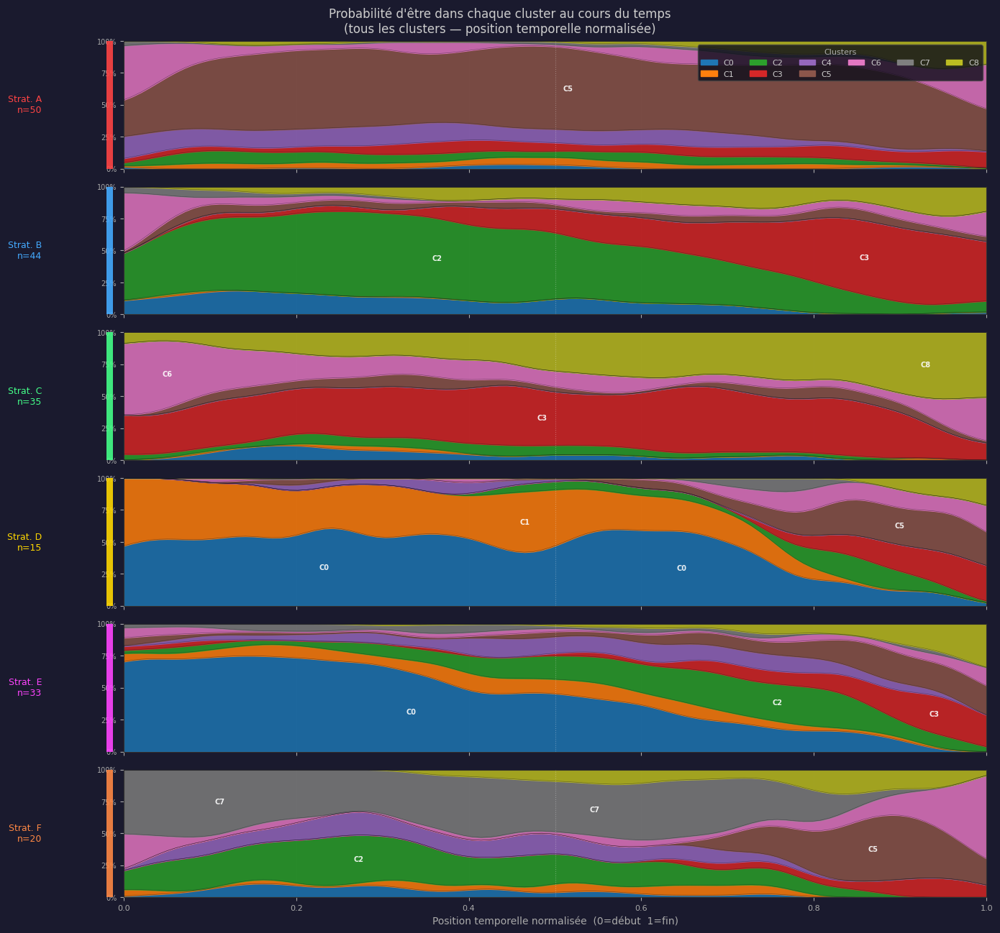

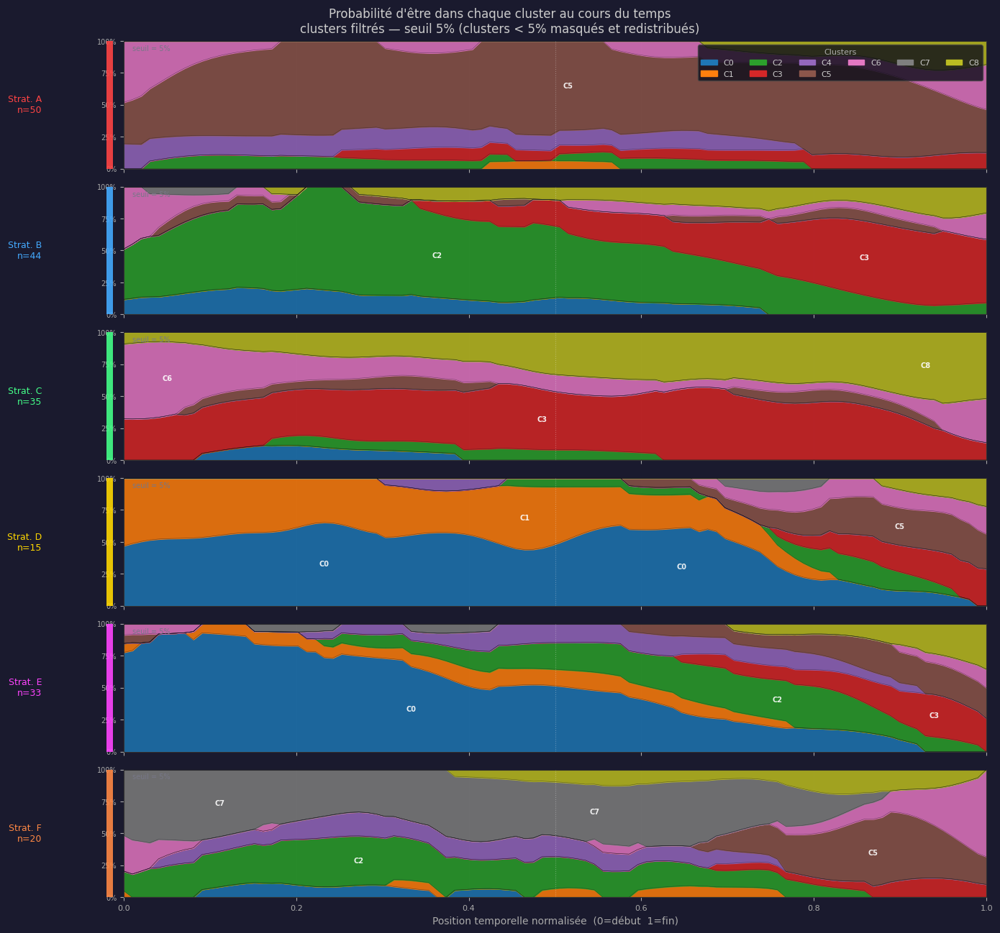

In [31]:
plot_cluster_probability_over_time(
    profiles          = profiles,
    seqs              = seqs,
    n_cl              = n_cl,
    strategy_letters  = strategy_letters,
    pal               = pal,
    cmap_cl           = cmap_cl,
    norm_cl           = norm_cl,
    n_bins            = 100,
    smooth_sigma      = 3,
    min_prob_threshold= 0.05,
)


In [32]:
def plot_strategy_features_over_time(
    profiles, final_state, df,
    features      = None,
    n_bins        = 50,
    smooth_sigma  = 2,
    show_variance = True,
):
    """
    Pour chaque stratégie : moyenne (± écart-type) de chaque feature
    au cours du temps normalisé [0=début, 1=fin].

    Principe :
      1. Pour chaque individu, on découpe ses frames en n_bins
         égaux selon sa position temporelle normalisée
      2. On calcule la moyenne de chaque feature dans chaque bin
      3. On moyenne sur tous les individus de la stratégie
      4. On affiche la courbe + zone de variance

    features      : liste des colonnes à tracer (défaut = FEATURES)
    n_bins        : résolution temporelle (50 = assez lisse)
    smooth_sigma  : lissage gaussien sur les courbes (0 = désactivé)
    show_variance : afficher l'écart-type en zone ombrée
    """
    from scipy.ndimage import gaussian_filter1d

    if features is None:
        features = FEATURES

    seqs             = final_state["seqs"]
    strategy_letters = sorted(profiles.keys())
    n_strat          = len(strategy_letters)
    n_feat           = len(features)
    t_axis           = np.linspace(0, 1, n_bins)

    pal         = {s: STRATEGY_PALETTE[i % len(STRATEGY_PALETTE)]
                   for i, s in enumerate(strategy_letters)}
    pal["MONO"] = "#666666"

    df_w = df.copy()
    df_w["animal_id"] = df_w["animal_id"].astype(str)

    # ── Calcul des profils temporels ──────────────────────────
    # Pour chaque stratégie et chaque feature :
    #   all_curves[s][feat] = array (n_members, n_bins)
    all_means = {}   # {s: array (n_feat, n_bins)}
    all_stds  = {}   # {s: array (n_feat, n_bins)}

    for s in strategy_letters:
        if s not in profiles: continue
        members = [m for m in profiles[s]["members"] if m in seqs]
        if not members: continue

        # Matrice (n_members, n_feat, n_bins)
        feat_matrix = np.full((len(members), n_feat, n_bins), np.nan)

        for mi, aid in enumerate(members):
            # Récupérer les frames de cet individu dans df
            mask_ind = df_w["animal_id"] == str(aid)
            df_ind   = df_w[mask_ind].copy()

            if "frame" in df_ind.columns:
                df_ind = df_ind.sort_values("frame")

            n_frames = len(df_ind)
            if n_frames == 0: continue

            # Vérifier que toutes les features sont présentes
            feats_ok = [f for f in features if f in df_ind.columns]
            if not feats_ok: continue

            # Découper en n_bins selon la position temporelle
            for b in range(n_bins):
                i_start = int(b * n_frames / n_bins)
                i_end   = int((b + 1) * n_frames / n_bins)
                if i_end <= i_start:
                    i_end = i_start + 1
                i_end = min(i_end, n_frames)

                chunk = df_ind.iloc[i_start:i_end]
                if len(chunk) == 0: continue

                for fi, feat in enumerate(features):
                    if feat in chunk.columns:
                        feat_matrix[mi, fi, b] = chunk[feat].mean()

        # Moyenne et écart-type sur les individus
        # nanmean/nanstd ignore les bins sans données
        mean_mat = np.nanmean(feat_matrix, axis=0)   # (n_feat, n_bins)
        std_mat  = np.nanstd(feat_matrix,  axis=0)   # (n_feat, n_bins)

        # Lissage gaussien sur les courbes
        if smooth_sigma > 0:
            for fi in range(n_feat):
                mean_mat[fi] = gaussian_filter1d(
                    mean_mat[fi], sigma=smooth_sigma, mode='nearest')
                std_mat[fi]  = gaussian_filter1d(
                    std_mat[fi],  sigma=smooth_sigma, mode='nearest')

        all_means[s] = mean_mat
        all_stds[s]  = std_mat

        print(f"[FEATURES/TEMPS] Stratégie {s} : "
              f"{len(members)} individus × {n_feat} features × {n_bins} bins")

    if not all_means:
        print("[ERREUR] Aucune donnée calculée.")
        return

    # ════════════════════════════════════════════════════════
    # FIGURE — une ligne par stratégie, une colonne par feature
    # ════════════════════════════════════════════════════════
    fig, axes = plt.subplots(
        n_strat, n_feat,
        figsize=(n_feat * 3.5, n_strat * 2.5),
        sharex=True
    )
    fig.patch.set_facecolor("#1a1a2e")
    fig.suptitle(
        "Features comportementales au cours du temps normalisé\n"
        "par stratégie  (moyenne ± écart-type sur les individus)",
        color="#cccccc", fontsize=13, y=1.01
    )

    # Normaliser axes en array 2D même si 1 seule ligne/colonne
    if n_strat == 1 and n_feat == 1:
        axes = np.array([[axes]])
    elif n_strat == 1:
        axes = axes[np.newaxis, :]
    elif n_feat == 1:
        axes = axes[:, np.newaxis]

    # Calculer les limites globales par feature
    # → même échelle Y pour toutes les stratégies d'une feature
    ylims = {}
    for fi, feat in enumerate(features):
        all_vals = []
        for s in strategy_letters:
            if s not in all_means: continue
            m = all_means[s][fi]
            e = all_stds[s][fi]
            all_vals.extend((m - e).tolist())
            all_vals.extend((m + e).tolist())
        if all_vals:
            vmin = np.nanmin(all_vals)
            vmax = np.nanmax(all_vals)
            margin = (vmax - vmin) * 0.1
            ylims[fi] = (vmin - margin, vmax + margin)
        else:
            ylims[fi] = (0, 1)

    for si, s in enumerate(strategy_letters):
        if s not in all_means: continue
        col      = pal[s]
        mean_mat = all_means[s]
        std_mat  = all_stds[s]
        n_ind    = len(profiles[s]["members"])

        for fi, feat in enumerate(features):
            ax = axes[si, fi]
            ax.set_facecolor("#0d0d1a")
            for sp in ax.spines.values():
                sp.set_edgecolor("#333333")
            ax.tick_params(colors="#555555", labelsize=7)

            mean_v = mean_mat[fi]
            std_v  = std_mat[fi]

            # Courbe moyenne
            ax.plot(t_axis, mean_v,
                    color=col, lw=2.0, alpha=0.95, zorder=3)

            # Zone ± 1 écart-type
            if show_variance:
                ax.fill_between(
                    t_axis,
                    mean_v - std_v,
                    mean_v + std_v,
                    color=col, alpha=0.20, zorder=2
                )

            # Ligne verticale au milieu
            ax.axvline(0.5, color="#ffffff", lw=0.6,
                       ls=":", alpha=0.25, zorder=4)

            # Ligne horizontale à 0 si pertinent
            if ylims[fi][0] < 0 < ylims[fi][1]:
                ax.axhline(0, color="#444455", lw=0.5,
                           ls="-", alpha=0.5, zorder=1)

            ax.set_xlim(0, 1)
            ax.set_ylim(ylims[fi])
            ax.grid(axis="x", color="#222233", alpha=0.4, lw=0.5)

            # Titre colonne (feature) — seulement sur la 1ère ligne
            if si == 0:
                ax.set_title(
                    feat.replace("_", "\n"),
                    color="#aaaaaa", fontsize=9, pad=4
                )

            # Label ligne (stratégie) — seulement sur la 1ère colonne
            if fi == 0:
                ax.set_ylabel(
                    f"Strat. {s}\nn={n_ind}",
                    color=col, fontsize=9,
                    rotation=0, ha="right",
                    va="center", labelpad=55
                )
            else:
                ax.set_ylabel("")

            # Axe X — seulement sur la dernière ligne
            if si == n_strat - 1:
                ax.set_xlabel("t normalisé",
                              color="#555555", fontsize=7)
            else:
                ax.set_xticklabels([])

    plt.tight_layout()
    plt.show()


    # FIGURE 2 — Toutes les stratégies superposées par feature
    # ════════════════════════════════════════════════════════
    n_cols = min(3, n_feat)
    n_rows = (n_feat + n_cols - 1) // n_cols

    fig2, axes2 = plt.subplots(
        n_rows, n_cols,
        figsize=(n_cols * 4.5, n_rows * 3.5),
        sharex=True
    )
    fig2.patch.set_facecolor("#1a1a2e")
    fig2.suptitle(
        "Features comportementales — toutes stratégies superposées\n"
        "(moyenne ± écart-type  |  position temporelle normalisée)",
        color="#cccccc", fontsize=13, y=1.01
    )

    # Normaliser axes en array 2D
    if n_rows == 1 and n_cols == 1:
        axes2 = np.array([[axes2]])
    elif n_rows == 1:
        axes2 = axes2[np.newaxis, :]
    elif n_cols == 1:
        axes2 = axes2[:, np.newaxis]

    for fi, feat in enumerate(features):
        ri = fi // n_cols
        ci = fi % n_cols
        ax = axes2[ri, ci]
        ax.set_facecolor("#0d0d1a")
        for sp in ax.spines.values(): sp.set_edgecolor("#333333")
        ax.tick_params(colors="#555555", labelsize=7)

        for s in strategy_letters:
            if s not in all_means: continue
            col      = pal[s]
            mean_v   = all_means[s][fi]
            std_v    = all_stds[s][fi]
            n_ind    = len(profiles[s]["members"])

            ax.plot(t_axis, mean_v,
                    color=col, lw=2.0, alpha=0.95,
                    label=f"{s} (n={n_ind})", zorder=3)

            if show_variance:
                ax.fill_between(
                    t_axis,
                    mean_v - std_v,
                    mean_v + std_v,
                    color=col, alpha=0.12, zorder=2
                )

        ax.axvline(0.5, color="#ffffff", lw=0.6,
                   ls=":", alpha=0.25, zorder=4)

        if ylims[fi][0] < 0 < ylims[fi][1]:
            ax.axhline(0, color="#444455", lw=0.5,
                       ls="-", alpha=0.5, zorder=1)

        ax.set_xlim(0, 1)
        ax.set_ylim(ylims[fi])
        ax.grid(axis="x", color="#222233", alpha=0.4, lw=0.5)
        ax.set_title(feat.replace("_", "\n"),
                     color="#aaaaaa", fontsize=10, pad=4)

        if ri == n_rows - 1:
            ax.set_xlabel("t normalisé", color="#555555", fontsize=8)

        # Légende sur le premier subplot seulement
        if fi == 0:
            leg = ax.legend(
                fontsize=8, loc="upper right",
                facecolor="#111122", labelcolor="#cccccc",
                framealpha=0.8
            )
            leg.get_frame().set_edgecolor("#444444")

    # Masquer les axes vides si n_feat < n_rows * n_cols
    for fi in range(n_feat, n_rows * n_cols):
        axes2[fi // n_cols, fi % n_cols].set_visible(False)

    plt.tight_layout()
    plt.show()

  [MÉDOÏDE] Stratégie A (40 ind)... -> ID 166
  [MÉDOÏDE] Stratégie B (44 ind)... -> ID 174
  [MÉDOÏDE] Stratégie C (35 ind)... -> ID 165
  [MÉDOÏDE] Stratégie D (15 ind)... -> ID 64
  [MÉDOÏDE] Stratégie E (21 ind)... -> ID 30
  [MÉDOÏDE] Stratégie F (20 ind)... -> ID 156
  [MÉDOÏDE] Stratégie G (9 ind)... -> ID 103
  [MÉDOÏDE] Stratégie H (11 ind)... -> ID 139
[DEBUG] mapping_optimal sample : [('1', '1'), ('10', '0'), ('100', '5'), ('101', '0'), ('102', '5')]
[DEBUG] mapping_letters sample : [('1', 'B'), ('10', 'A'), ('100', 'F'), ('101', 'A'), ('102', 'F')]
[DEBUG] strategy_letters : ['A', 'B', 'C', 'D', 'E', 'F', 'G', 'H']
[DEBUG] seqs keys sample : ['1', '10', '100', '101', '102']
  A : 40 membres, 40 dans seqs
  B : 44 membres, 44 dans seqs
  C : 35 membres, 35 dans seqs
  D : 15 membres, 15 dans seqs
  E : 21 membres, 21 dans seqs
  F : 20 membres, 20 dans seqs
  G : 9 membres, 9 dans seqs
  H : 11 membres, 11 dans seqs


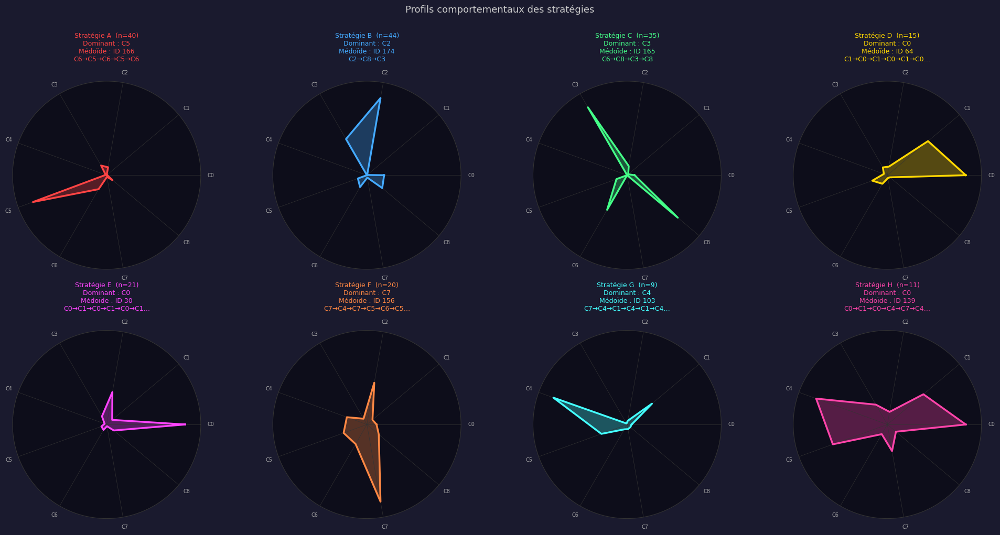

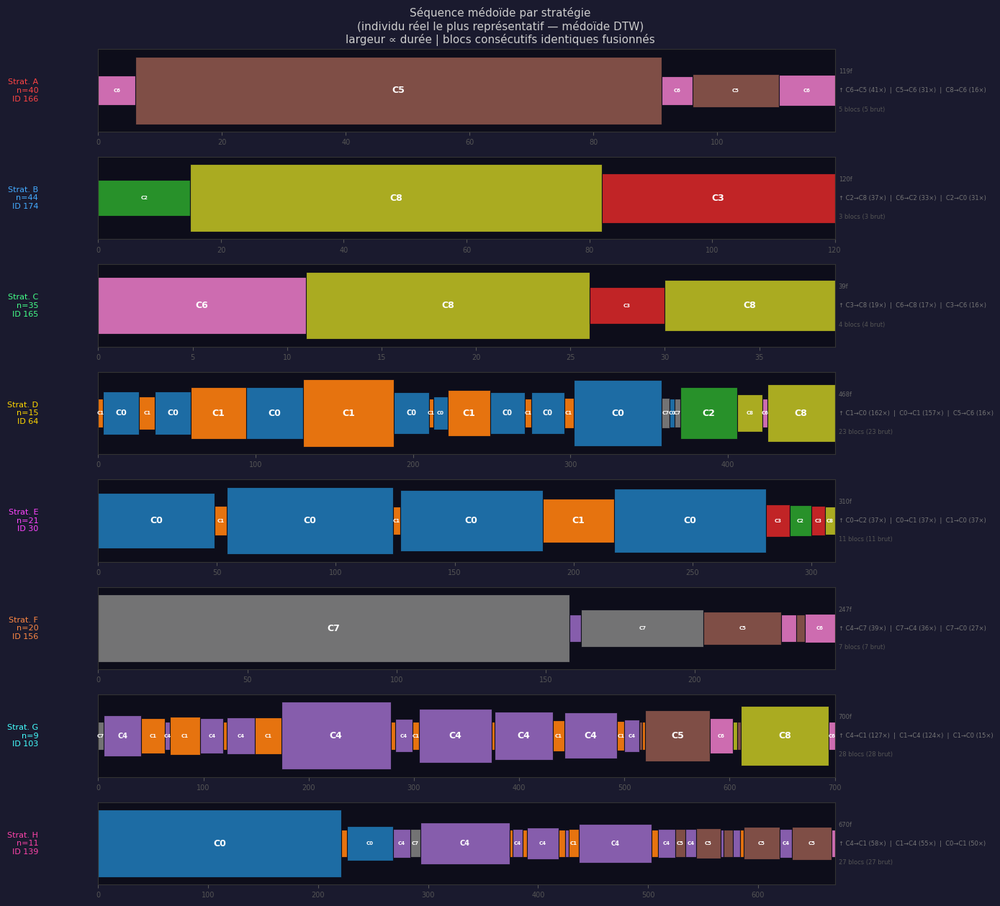

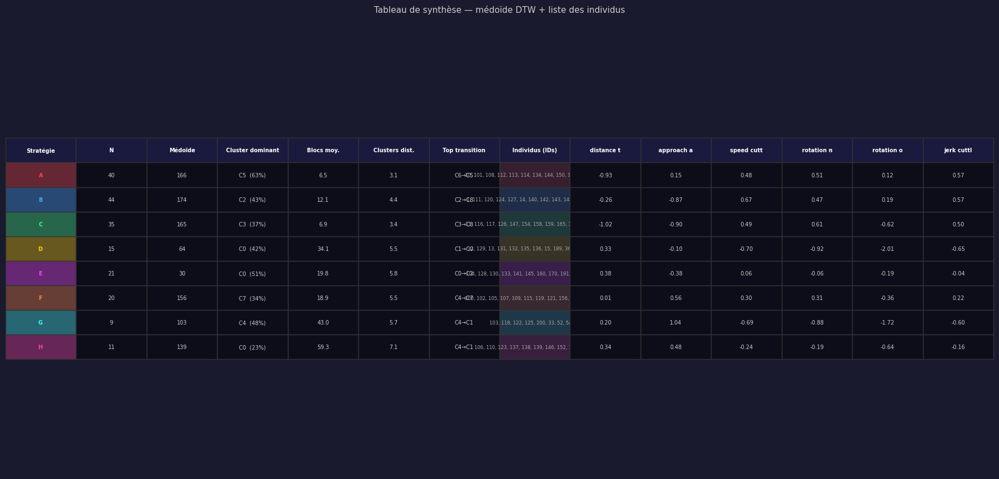

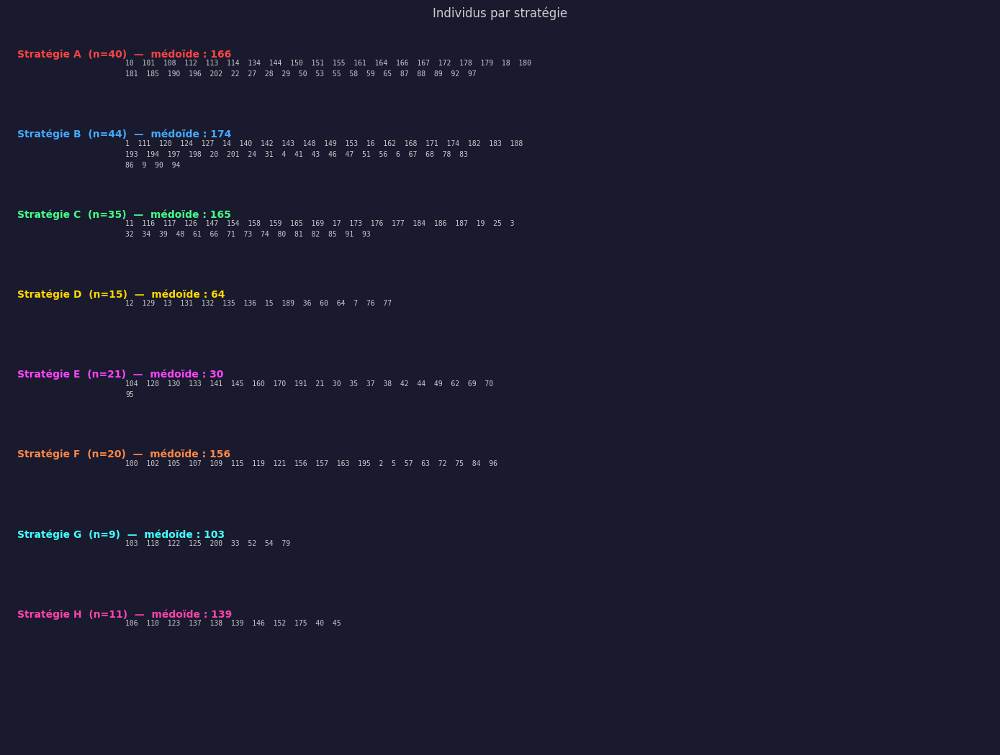


PROFILS (8 groupes) — médoïdes DTW

Stratégie A  (n=40)  —  médoïde : ID 166
  Individus : 10, 101, 108, 112, 113, 114, 134, 144, 150, 151, 155, 161, 164, 166, 167, 172, 178, 179, 18, 180, 181, 185, 190, 196, 202, 22, 27, 28, 29, 50, 53, 55, 58, 59, 65, 87, 88, 89, 92, 97
  Dominant  : C5 (63%)
  Blocs moy : 6.5 | Clusters dist. : 3.1
  Top trans : C6→C5(41×), C5→C6(31×), C8→C6(16×)

Stratégie B  (n=44)  —  médoïde : ID 174
  Individus : 1, 111, 120, 124, 127, 14, 140, 142, 143, 148, 149, 153, 16, 162, 168, 171, 174, 182, 183, 188, 193, 194, 197, 198, 20, 201, 24, 31, 4, 41, 43, 46, 47, 51, 56, 6, 67, 68, 78, 83, 86, 9, 90, 94
  Dominant  : C2 (43%)
  Blocs moy : 12.1 | Clusters dist. : 4.4
  Top trans : C2→C8(37×), C6→C2(33×), C2→C0(31×)

Stratégie C  (n=35)  —  médoïde : ID 165
  Individus : 11, 116, 117, 126, 147, 154, 158, 159, 165, 169, 17, 173, 176, 177, 184, 186, 187, 19, 25, 3, 32, 34, 39, 48, 61, 66, 71, 73, 74, 80, 81, 82, 85, 91, 93
  Dominant  : C3 (37%)
  Blocs moy : 6.9 

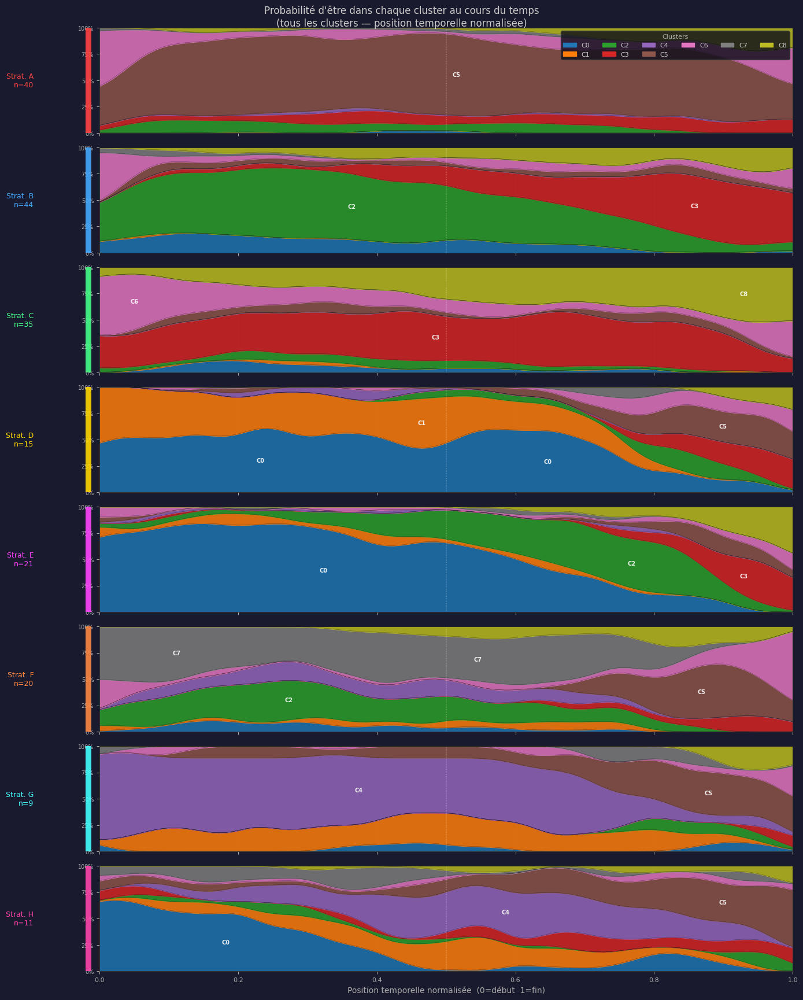

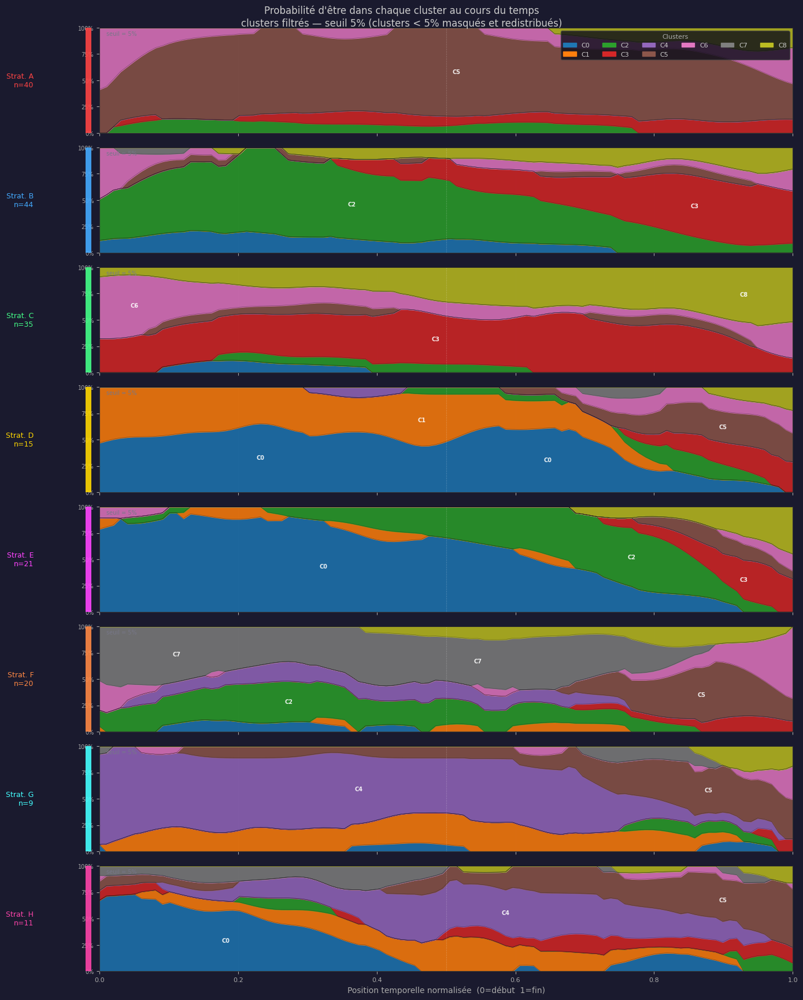

In [33]:
#tableau des different strategies par indiv

global_strategies = pd.DataFrame() 
global_strategies["strat_base"] = final_state["strat"]
global_strategies["strat_opti"] = final_state_optimal["strat"]
global_strategies = global_strategies.iloc[:-2].copy()

counts      = global_strategies["strat_base"].value_counts()
counts_true = counts[counts >= 7].index          # Index : isin l'accepte
mask        = global_strategies["strat_base"].isin(counts_true)
mapping_base = global_strategies.loc[mask, "strat_base"].to_dict()

profiles_base, mapping_letters = plot_strategy_profiles(
    mapping_base,
    final_state,
    df,
    features = FEATURES,
)


seqs             = final_state["seqs"]
n_cl             = final_state["n_cl"]
strategy_letters = sorted(profiles_base.keys())   # A, B, C... depuis profiles

pal         = {s: STRATEGY_PALETTE[i % len(STRATEGY_PALETTE)]
               for i, s in enumerate(strategy_letters)}
pal["MONO"] = "#666666"

# Couleurs clusters — même palette que partout ailleurs
cmap_cl = mpl.colors.ListedColormap(PALETTE)
norm_cl = mpl.colors.BoundaryNorm(range(len(PALETTE) + 1),
                                   ncolors=len(PALETTE))

plot_cluster_probability_over_time(
    profiles          = profiles_base,
    seqs              = seqs,
    n_cl              = n_cl,
    strategy_letters  = strategy_letters,
    pal               = pal,
    cmap_cl           = cmap_cl,
    norm_cl           = norm_cl,
    n_bins            = 100,
    smooth_sigma      = 3,
    min_prob_threshold= 0.05,
)

In [34]:
counts 


strat_base
1    44
0    40
2    35
4    21
5    20
3    15
7    11
6     9
Name: count, dtype: int64

[FEATURES/TEMPS] Stratégie A : 50 individus × 6 features × 50 bins
[FEATURES/TEMPS] Stratégie B : 44 individus × 6 features × 50 bins
[FEATURES/TEMPS] Stratégie C : 35 individus × 6 features × 50 bins
[FEATURES/TEMPS] Stratégie D : 15 individus × 6 features × 50 bins
[FEATURES/TEMPS] Stratégie E : 33 individus × 6 features × 50 bins
[FEATURES/TEMPS] Stratégie F : 20 individus × 6 features × 50 bins


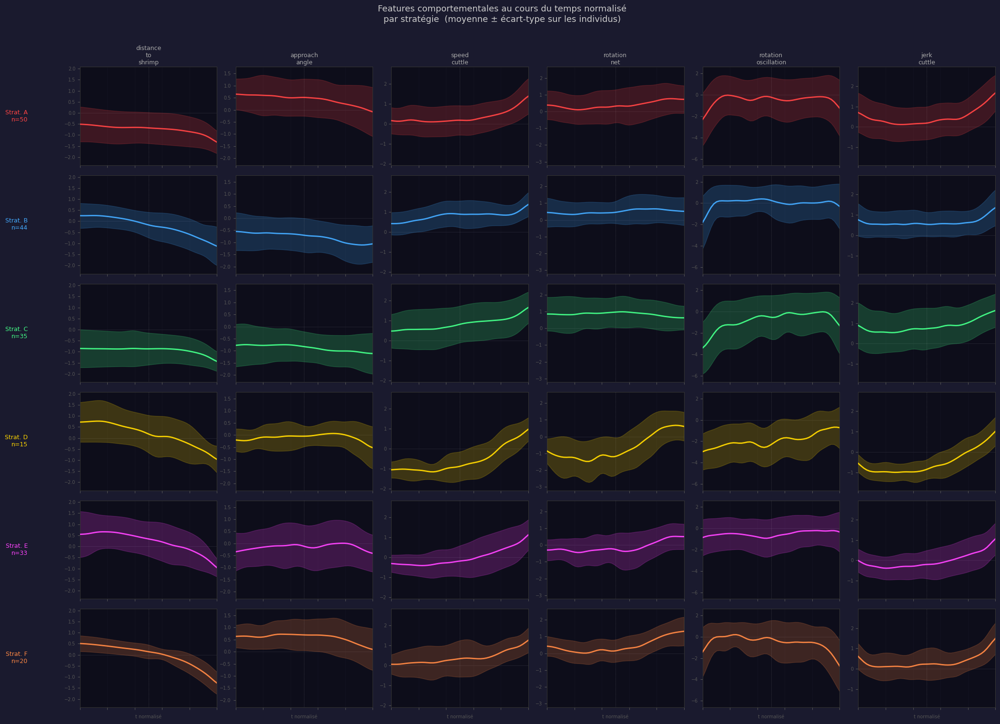

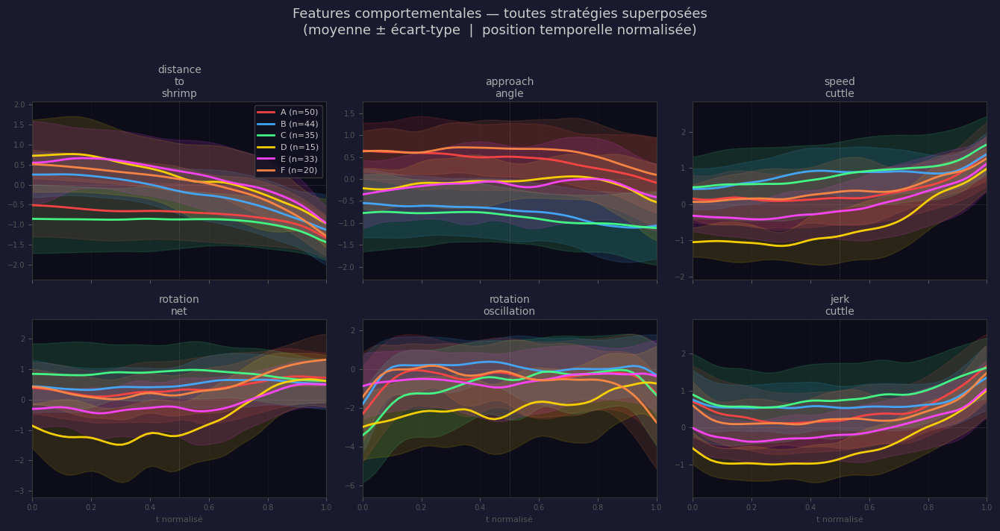

In [35]:
# ── Appel ─────────────────────────────────────────────────────
plot_strategy_features_over_time(
    profiles      = profiles,
    final_state   = final_state,
    df            = df,
    features      = FEATURES,
    n_bins        = 50,
    smooth_sigma  = 2,
    show_variance = True,
)

[OK] 202 individus | 8 stratégies
     Répartition : Counter({'B': 44, 'A': 40, 'C': 35, 'E': 21, 'F': 20, 'D': 15, 'H': 11, 'G': 9, 'MONO': 7})


C:\Users\nonoh\AppData\Local\Temp\ipykernel_28408\3236129426.py:70: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  bp = ax.boxplot(
C:\Users\nonoh\AppData\Local\Temp\ipykernel_28408\3236129426.py:70: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  bp = ax.boxplot(
C:\Users\nonoh\AppData\Local\Temp\ipykernel_28408\3236129426.py:70: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  bp = ax.boxplot(
C:\Users\nonoh\AppData\Local\Temp\ipykernel_28408\3236129426.py:70: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3

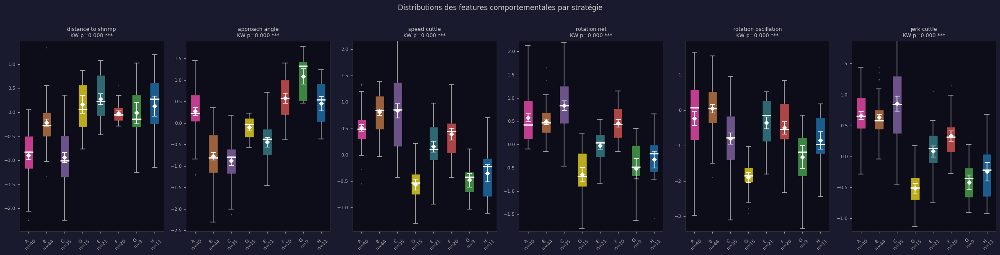

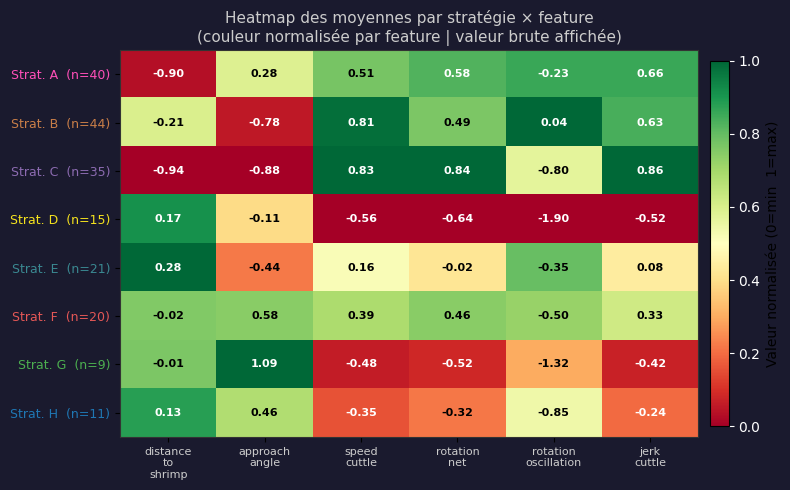

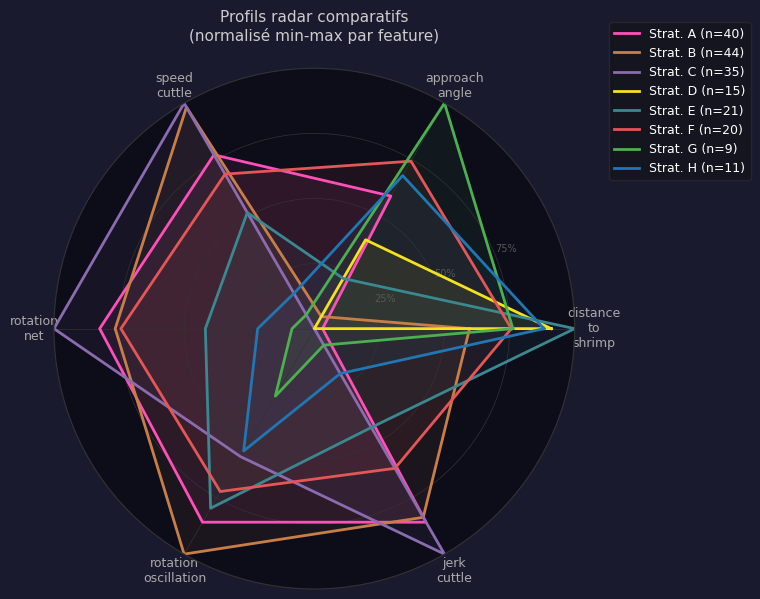

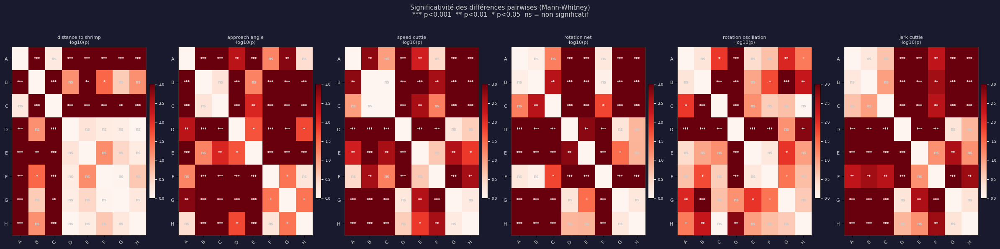

In [36]:
#  CELLULE — Plots comparatifs entre stratégies
#  Basé sur df (features comportementales) + mapping_letters
#  (stratégies issues du regroupement optimal)
# ══════════════════════════════════════════════════════════════

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import matplotlib as mpl
from scipy import stats
from scipy.stats import mannwhitneyu, kruskal
from itertools import combinations
from collections import Counter

# ── Palette stratégies ────────────────────────────────────────
strategy_letters_plot = sorted(
    set(v for v in mapping_letters.values() if v != "MONO")
)
all_groups_plot = strategy_letters_plot + (
    ["MONO"] if "MONO" in set(mapping_letters.values()) else []
)
STRAT_PAL = [
    "#FF4FB8","#C97E48","#8C6BB1","#F5E21E","#3A8891",
    "#E45756","#4CAF50","#1F77B4","#FF9F1C","#A05195",
    "#2CB1BC","#D62728","#9467BD","#8C564B","#E377C2",
]
pal_strat = {s: STRAT_PAL[i % len(STRAT_PAL)]
             for i, s in enumerate(all_groups_plot)}
pal_strat["MONO"] = "#666666"

n_strat = len(strategy_letters_plot)

# ── Construire df individu × features + stratégie ─────────────
df_w = df.copy()
df_w["animal_id"] = df_w["animal_id"].astype(str)

df_indiv = df_w.groupby("animal_id")[FEATURES].mean()
df_indiv["strategie"] = [
    mapping_letters.get(str(aid), "MONO")
    for aid in df_indiv.index
]
df_indiv = df_indiv.dropna(subset=FEATURES)

print(f"[OK] {len(df_indiv)} individus | {n_strat} stratégies")
print(f"     Répartition : {Counter(df_indiv['strategie'].values)}")


# ════════════════════════════════════════════════════════════
# FIGURE 1 — Boxplots par feature × stratégie
# ════════════════════════════════════════════════════════════

n_feats = len(FEATURES)
fig, axes = plt.subplots(1, n_feats, figsize=(4 * n_feats, 6))
fig.patch.set_facecolor("#1a1a2e")
if n_feats == 1: axes = [axes]

for ax, feat in zip(axes, FEATURES):
    ax.set_facecolor("#0d0d1a")
    for sp in ax.spines.values(): sp.set_edgecolor("#333333")
    ax.tick_params(colors="#aaaaaa", labelsize=8)

    data_per_strat = [
        df_indiv.loc[df_indiv["strategie"] == s, feat].dropna().values
        for s in strategy_letters_plot
    ]
    labels = [f"{s}\nn={len(d)}" for s, d in zip(strategy_letters_plot, data_per_strat)]
    colors_bp = [pal_strat[s] for s in strategy_letters_plot]

    bp = ax.boxplot(
        data_per_strat, labels=labels, patch_artist=True,
        medianprops=dict(color="white", linewidth=2),
        whiskerprops=dict(linewidth=1.2, color="#aaaaaa"),
        capprops=dict(linewidth=1.2, color="#aaaaaa"),
        flierprops=dict(marker="o", markersize=2, alpha=0.4,
                        markerfacecolor="#aaaaaa", markeredgecolor="none"),
    )
    for patch, col in zip(bp["boxes"], colors_bp):
        patch.set_facecolor(col); patch.set_alpha(0.75)

    # Moyenne ± SEM superposée
    for i, (vals, s) in enumerate(zip(data_per_strat, strategy_letters_plot), 1):
        if len(vals) == 0: continue
        mean = vals.mean()
        sem  = vals.std(ddof=1) / np.sqrt(len(vals)) if len(vals) > 1 else 0
        ax.errorbar(i, mean, yerr=sem, fmt="D", color="white",
                    markersize=5, capsize=4, linewidth=1.5, zorder=5)

    # Limites Y robustes
    all_vals = np.concatenate([v for v in data_per_strat if len(v)])
    if len(all_vals):
        lo, hi = np.percentile(all_vals, [2, 98])
        margin = (hi - lo) * 0.15 or abs(hi) * 0.1 or 1
        ax.set_ylim(lo - margin, hi + margin)

    # Test Kruskal-Wallis global
    valid = [d for d in data_per_strat if len(d) >= 3]
    if len(valid) >= 2:
        try:
            _, p_kw = kruskal(*valid)
            sig = "***" if p_kw < 0.001 else "**" if p_kw < 0.01 else \
                  "*" if p_kw < 0.05 else "ns"
            ax.set_title(f"{feat.replace('_',' ')}\nKW p={p_kw:.3f} {sig}",
                         color="#cccccc", fontsize=9)
        except Exception:
            ax.set_title(feat.replace('_',' '), color="#cccccc", fontsize=9)
    else:
        ax.set_title(feat.replace('_',' '), color="#cccccc", fontsize=9)

    ax.tick_params(axis="x", rotation=45)

fig.suptitle("Distributions des features comportementales par stratégie",
             color="#cccccc", fontsize=12, y=1.01)
plt.tight_layout()
plt.show()


# ════════════════════════════════════════════════════════════
# FIGURE 2 — Heatmap des moyennes normalisées par stratégie
# ════════════════════════════════════════════════════════════

fig, ax = plt.subplots(figsize=(max(8, n_strat * 0.8), 5))
fig.patch.set_facecolor("#1a1a2e")
ax.set_facecolor("#0d0d1a")

# Matrice stratégie × feature (moyennes normalisées 0-1)
mat = np.zeros((n_strat, n_feats))
for i, s in enumerate(strategy_letters_plot):
    for j, feat in enumerate(FEATURES):
        vals = df_indiv.loc[df_indiv["strategie"] == s, feat].dropna().values
        mat[i, j] = vals.mean() if len(vals) > 0 else np.nan

# Normalisation min-max par feature
mat_norm = mat.copy()
for j in range(n_feats):
    col = mat[:, j]
    valid = col[~np.isnan(col)]
    if len(valid) > 0 and valid.max() != valid.min():
        mat_norm[:, j] = (col - valid.min()) / (valid.max() - valid.min())
    else:
        mat_norm[:, j] = 0.5

im = ax.imshow(mat_norm, cmap="RdYlGn", aspect="auto", vmin=0, vmax=1)

# Labels et annotations
ax.set_xticks(range(n_feats))
ax.set_xticklabels([f.replace("_","\n") for f in FEATURES],
                    color="#cccccc", fontsize=8)
ax.set_yticks(range(n_strat))
ax.set_yticklabels(
    [f"Strat. {s}  (n={int((df_indiv['strategie']==s).sum())})"
     for s in strategy_letters_plot],
    color="#cccccc", fontsize=9
)
# Colorier les labels Y selon la stratégie
for ytick, s in zip(ax.get_yticklabels(), strategy_letters_plot):
    ytick.set_color(pal_strat[s])

# Valeurs brutes dans les cellules
for i in range(n_strat):
    for j in range(n_feats):
        v = mat[i, j]
        if not np.isnan(v):
            ax.text(j, i, f"{v:.2f}", ha="center", va="center",
                    fontsize=8, color="black" if 0.2 < mat_norm[i,j] < 0.8 else "white",
                    fontweight="bold")

plt.colorbar(im, ax=ax, label="Valeur normalisée (0=min  1=max)",
             fraction=0.03, pad=0.02).ax.tick_params(colors="white")
ax.set_title("Heatmap des moyennes par stratégie × feature\n"
             "(couleur normalisée par feature | valeur brute affichée)",
             color="#cccccc", fontsize=11)
for sp in ax.spines.values(): sp.set_edgecolor("#333333")
plt.tight_layout()
plt.show()


# ════════════════════════════════════════════════════════════
# FIGURE 3 — Radars comparatifs superposés
# ════════════════════════════════════════════════════════════

angles   = np.linspace(0, 2*np.pi, n_feats, endpoint=False)
ang_full = np.concatenate([angles, [angles[0]]])

fig, ax = plt.subplots(figsize=(8, 8), subplot_kw=dict(polar=True))
fig.patch.set_facecolor("#1a1a2e")
ax.set_facecolor("#0d0d1a")

global_min = np.nanmin(mat, axis=0)
global_max = np.nanmax(mat, axis=0)

for i, s in enumerate(strategy_letters_plot):
    row = mat[i]
    norm_row = np.where(
        global_max != global_min,
        (row - global_min) / (global_max - global_min + 1e-9),
        0.5
    )
    vals_f = np.concatenate([norm_row, [norm_row[0]]])
    col    = pal_strat[s]
    n_s    = int((df_indiv["strategie"] == s).sum())
    ax.plot(ang_full, vals_f, lw=2, color=col, label=f"Strat. {s} (n={n_s})")
    ax.fill(ang_full, vals_f, alpha=0.08, color=col)

ax.set_xticks(angles)
ax.set_xticklabels([f.replace("_","\n") for f in FEATURES],
                    color="#aaaaaa", fontsize=9)
ax.set_ylim(0, 1)
ax.set_yticks([0.25, 0.5, 0.75])
ax.set_yticklabels(["25%", "50%", "75%"], color="#555555", fontsize=7)
ax.grid(color="#333333", lw=0.5)
ax.spines["polar"].set_color("#333333")
ax.set_title("Profils radar comparatifs\n(normalisé min-max par feature)",
             color="#cccccc", fontsize=11, pad=20)

leg = ax.legend(loc="upper right", bbox_to_anchor=(1.35, 1.1),
                fontsize=9, framealpha=0.5)
leg.get_frame().set_facecolor("#111111")
leg.get_frame().set_edgecolor("#333333")
for t in leg.get_texts(): t.set_color("white")

plt.tight_layout()
plt.show()


# ════════════════════════════════════════════════════════════
# FIGURE 4 — Matrice de p-valeurs (Mann-Whitney pairwise)
# ════════════════════════════════════════════════════════════

n_s   = len(strategy_letters_plot)
fig, axes = plt.subplots(1, n_feats, figsize=(4 * n_feats, max(4, n_s * 0.6 + 1)))
fig.patch.set_facecolor("#1a1a2e")
if n_feats == 1: axes = [axes]

for ax, feat in zip(axes, FEATURES):
    ax.set_facecolor("#0d0d1a")
    for sp in ax.spines.values(): sp.set_edgecolor("#333333")

    # Matrice p-valeurs
    p_mat = np.ones((n_s, n_s))
    for i, s1 in enumerate(strategy_letters_plot):
        for j, s2 in enumerate(strategy_letters_plot):
            if i >= j: continue
            x1 = df_indiv.loc[df_indiv["strategie"]==s1, feat].dropna().values
            x2 = df_indiv.loc[df_indiv["strategie"]==s2, feat].dropna().values
            if len(x1) >= 3 and len(x2) >= 3:
                try:
                    _, p = mannwhitneyu(x1, x2, alternative="two-sided")
                    p_mat[i, j] = p
                    p_mat[j, i] = p
                except Exception:
                    pass

    # Log-transform pour la lisibilité
    p_log = -np.log10(np.clip(p_mat, 1e-10, 1))
    np.fill_diagonal(p_log, 0)

    im = ax.imshow(p_log, cmap="Reds", aspect="auto", vmin=0, vmax=3)

    ax.set_xticks(range(n_s))
    ax.set_yticks(range(n_s))
    ax.set_xticklabels(strategy_letters_plot, color="#cccccc",
                        fontsize=8, rotation=45)
    ax.set_yticklabels(strategy_letters_plot, color="#cccccc", fontsize=8)

    for i in range(n_s):
        for j in range(n_s):
            if i == j: continue
            p_val = p_mat[i, j]
            sig   = "***" if p_val < 0.001 else "**" if p_val < 0.01 else \
                    "*"   if p_val < 0.05  else "ns"
            col_t = "white" if p_log[i,j] > 1.5 else "#cccccc"
            ax.text(j, i, sig, ha="center", va="center",
                    fontsize=7, color=col_t, fontweight="bold")

    ax.set_title(f"{feat.replace('_',' ')}\n-log10(p)",
                 color="#cccccc", fontsize=8)
    plt.colorbar(im, ax=ax, fraction=0.04, pad=0.02
                 ).ax.tick_params(colors="white", labelsize=6)

fig.suptitle("Significativité des différences pairwises (Mann-Whitney)\n"
             "*** p<0.001  ** p<0.01  * p<0.05  ns = non significatif",
             color="#cccccc", fontsize=11, y=1.02)
plt.tight_layout()
plt.show()


In [37]:
#  Imports complémentaires pour l'analyse de trajectoires 
import ast
from scipy.fft import fft
from scipy.spatial.distance import cdist
from sklearn.decomposition import PCA
from sklearn.metrics import adjusted_rand_score

# FEATURES et PALETTE déjÃ  définis en cellule 0
N_CLUSTERS = final_state["n_cl"]
print(f" Imports OK | N_CLUSTERS={N_CLUSTERS} | FEATURES={FEATURES}")

 Imports OK | N_CLUSTERS=9 | FEATURES=['distance_to_shrimp', 'approach_angle', 'speed_cuttle', 'rotation_net', 'rotation_oscillation', 'jerk_cuttle']


In [38]:
#  Centres des clusters dans l'espace des features 
# Calculé directement depuis df (déjÃ  chargé en mémoire)
cluster_col = final_state["col"]   # "supercluster" ou "cluster"
n_cl        = final_state["n_cl"]

cluster_ids        = sorted(df[cluster_col].unique())
cluster_stats_rows = []
for k in cluster_ids:
    mask = df[cluster_col] == k
    cluster_stats_rows.append(df.loc[mask, FEATURES].mean().values)

cluster_stats = pd.DataFrame(cluster_stats_rows, columns=FEATURES,
                              index=cluster_ids)
final_state["cluster_stats"] = cluster_stats

seqs_dict = final_state["seqs"]
n_mono    = sum(1 for s in seqs_dict.values() if len(s["seq"]) <= 1)

print(f"âœ… cluster_stats : {cluster_stats.shape}")
print(cluster_stats.round(4))
print(f"\nâœ… {len(seqs_dict)} individus dont {n_mono} MONO")
# mapping_letters est déjÃ  défini (retour de plot_strategy_profiles)
print(f"âœ… mapping_letters : {len(mapping_letters)} entrées")

âœ… cluster_stats : (9, 6)
   distance_to_shrimp  approach_angle  speed_cuttle  rotation_net  \
0              0.6731         -0.3016       -0.5862       -0.5242   
1              0.6184          0.3957       -1.1993       -1.8071   
2              0.3948         -0.3574        0.9473        0.2941   
3             -1.2372         -1.1818        0.3583        0.4002   
4              0.3562          1.3634       -0.8658       -0.7493   
5             -0.9650          0.4977        0.3470        0.5075   
6             -0.5027         -0.1946        0.7431        1.4035   
7              0.2535          0.8234        0.1086        0.1429   
8             -0.4931         -0.7428        1.6513        1.2075   

   rotation_oscillation  jerk_cuttle  
0               -0.0349      -0.5843  
1               -5.1107      -1.0339  
2                0.8803       0.6664  
3                0.5446       0.3347  
4               -0.2081      -0.7954  
5                0.4733       0.4828  
6        

In [39]:
#def plot 3D
from scipy.ndimage import gaussian_filter
from scipy.interpolate import griddata

def _compute_temporal_grid(df_w, resolution=100, smoothing=5,
                            normalize_by_individual=True):
    # ── Fix : réinitialiser l'index pour éviter les IndexError ──
    # Quand df_w est un sous-DataFrame filtré, les index pandas
    # ne correspondent plus aux positions 0..n-1
    # → reset_index() garantit que idx va de 0 à len(df_w)-1
    df_w = df_w.reset_index(drop=True)

    xg = df_w["umap_x"].values
    yg = df_w["umap_y"].values

    if normalize_by_individual:
        zg = np.zeros(len(df_w))
        for aid, grp in df_w.groupby("animal_id"):
            idx = grp.index   # ← maintenant ces index sont bien 0..n-1
            n   = len(grp)
            if n == 1:
                zg[idx] = 1.0
            else:
                zg[idx] = 1.0 - np.arange(n) / (n - 1)
    else:
        n  = len(df_w)
        zg = 1.0 - np.arange(n) / max(n - 1, 1)

    # reste identique...
    x_min, x_max = xg.min(), xg.max()
    y_min, y_max = yg.min(), yg.max()
    margin_x = (x_max - x_min) * 0.05
    margin_y = (y_max - y_min) * 0.05

    xi = np.linspace(x_min - margin_x, x_max + margin_x, resolution)
    yi = np.linspace(y_min - margin_y, y_max + margin_y, resolution)
    Xi, Yi = np.meshgrid(xi, yi)

    pts = np.column_stack([xg, yg])
    Zi  = griddata(pts, zg, (Xi, Yi), method='linear')

    mask_nan = np.isnan(Zi)
    if mask_nan.any():
        Zi_near      = griddata(pts, zg, (Xi, Yi), method='nearest')
        Zi[mask_nan] = Zi_near[mask_nan]

    if smoothing > 0:
        Zi = gaussian_filter(Zi, sigma=smoothing)

    Zi = np.clip(Zi, 0, 1)

    return Zi, Xi, Yi, xg, yg, zg

def plot_temporal_group_overlay(Z, df, mapping_letters,
                                 groupe,
                                 smoothing=5,
                                 resolution=100,
                                 normalize_by_individual=True,
                                 colormap="RdYlGn_r",
                                 stride=2):

    df_w = df.copy()
    df_w["animal_id"] = df_w["animal_id"].astype(str)
    df_w["umap_x"]    = Z[:, 0]
    df_w["umap_y"]    = Z[:, 1]
    df_w["groupe"]    = df_w["animal_id"].map(
        lambda a: mapping_letters.get(a, "MONO")
    )

    group_list = sorted(set(v for v in mapping_letters.values() if v != "MONO"))
    pal        = {g: PALETTE[i % len(PALETTE)] for i, g in enumerate(group_list)}
    col        = pal.get(groupe, "#4CAF50")
    n_ind      = df_w[df_w["groupe"] == groupe]["animal_id"].nunique()

    if groupe not in group_list:
        print(f"❌ Groupe '{groupe}' introuvable. Disponibles : {group_list}")
        return

    cluster_col = ("supercluster" if "supercluster" in df_w.columns
                   else "cluster"  if "cluster"      in df_w.columns
                   else None)

    print(f"[OVERLAY] Calcul grille globale...")
    Zi_global, Xi, Yi, xg, yg, zg = _compute_temporal_grid(
        df_w, resolution, smoothing, normalize_by_individual
    )

    print(f"[OVERLAY] Calcul grille groupe {groupe} (n={n_ind})...")
    df_g = df_w[df_w["groupe"] == groupe]
    Zi_g, Xi_g, Yi_g, xg_, yg_, zg_ = _compute_temporal_grid(
        df_g, resolution, smoothing, normalize_by_individual
    )

    x_min, x_max = Xi.min(), Xi.max()
    y_min, y_max = Yi.min(), Yi.max()

    # ════════════════════════════════════════════════════════
    # FIGURE 1 — 3D
    # ════════════════════════════════════════════════════════
    fig1 = plt.figure(figsize=(12, 9))
    fig1.patch.set_facecolor("#1a1a2e")
    ax3d = fig1.add_subplot(111, projection='3d')
    ax3d.set_facecolor("#0d0d1a")

    ax3d.plot_surface(
        Xi[::stride*2, ::stride*2],
        Yi[::stride*2, ::stride*2],
        Zi_global[::stride*2, ::stride*2],
        cmap='gray', alpha=0.15,
        linewidth=0, antialiased=False, vmin=0, vmax=1,
    )
    surf = ax3d.plot_surface(
        Xi_g[::stride, ::stride],
        Yi_g[::stride, ::stride],
        Zi_g[::stride, ::stride],
        cmap=colormap, alpha=0.88,
        linewidth=0, antialiased=False, vmin=0, vmax=1,
    )
    ax3d.contourf(Xi_g, Yi_g, Zi_g, zdir='z', offset=-0.05,
                  cmap=colormap, alpha=0.25, levels=10)
    ax3d.set_zlim(-0.1, 1.1)
    ax3d.set_xlabel("UMAP D1",           color="#aaaaaa", labelpad=8)
    ax3d.set_ylabel("UMAP D2",           color="#aaaaaa", labelpad=8)
    ax3d.set_zlabel("Position temporelle", color="#aaaaaa", labelpad=8)
    ax3d.tick_params(colors="#555555", labelsize=6)
    ax3d.xaxis.pane.fill = False
    ax3d.yaxis.pane.fill = False
    ax3d.zaxis.pane.fill = False
    ax3d.xaxis.pane.set_edgecolor("#333333")
    ax3d.yaxis.pane.set_edgecolor("#333333")
    ax3d.zaxis.pane.set_edgecolor("#333333")
    ax3d.grid(True, color="#333333", alpha=0.2)
    ax3d.set_title(f"3D — Groupe {groupe} (n={n_ind}) sur fond global\n"
                   f"σ={smoothing} | res={resolution}",
                   color=col, fontsize=11, pad=10)
    fig1.colorbar(surf, ax=ax3d, fraction=0.015, pad=0.05,
                  shrink=0.5, label="1=début  0=fin"
                  ).ax.tick_params(colors="#aaaaaa", labelsize=7)
    fig1.suptitle(f"Topographie temporelle 3D — Stratégie {groupe}",
                  color=col, fontsize=13)
    plt.tight_layout(); plt.show()

    # ════════════════════════════════════════════════════════
    # FIGURE 2 — 2D temporelle overlay
    # ════════════════════════════════════════════════════════
    fig2, ax2d = plt.subplots(figsize=(11, 9))
    fig2.patch.set_facecolor("#1a1a2e")
    ax2d.set_facecolor("#0d0d1a"); ax2d.axis("off")

    ax2d.imshow(Zi_global, origin='lower',
                extent=[x_min, x_max, y_min, y_max],
                cmap='gray', vmin=0, vmax=1,
                aspect='auto', alpha=0.35, zorder=1)
    ax2d.imshow(Zi_g, origin='lower',
                extent=[Xi_g.min(), Xi_g.max(),
                        Yi_g.min(), Yi_g.max()],
                cmap=colormap, vmin=0, vmax=1,
                aspect='auto', alpha=0.80, zorder=2)
    ax2d.contour(Xi_g, Yi_g,
                 gaussian_filter(np.nan_to_num(Zi_g), sigma=2),
                 levels=8, colors=col, alpha=0.4,
                 linewidths=0.8, zorder=3)
    ax2d.scatter(xg_, yg_, c=zg_, cmap=colormap,
                 vmin=0, vmax=1, s=2, alpha=0.2, zorder=4)
    ax2d.contour(Xi, Yi,
                 gaussian_filter(np.nan_to_num(Zi_global), sigma=2),
                 levels=6, colors='white', alpha=0.10,
                 linewidths=0.5, zorder=3)

    im_p = plt.cm.ScalarMappable(cmap=colormap, norm=plt.Normalize(0,1))
    im_p.set_array([])
    fig2.colorbar(im_p, ax=ax2d, fraction=0.025, pad=0.01,
                  label="1=début  0=fin"
                  ).ax.tick_params(colors="#aaaaaa", labelsize=7)
    ax2d.set_title(f"Topographie temporelle 2D — Groupe {groupe} / fond global\n"
                   f"{'normalisé/individu' if normalize_by_individual else 'brut'} "
                   f"| σ={smoothing}",
                   color=col, fontsize=11)
    fig2.suptitle(f"Carte temporelle — Stratégie {groupe}", color=col, fontsize=13)
    plt.tight_layout(); plt.show()

    # ════════════════════════════════════════════════════════
    # FIGURE 3 — Clusters comportementaux
    # ════════════════════════════════════════════════════════
    fig3, ax3 = plt.subplots(figsize=(11, 9))
    fig3.patch.set_facecolor("#1a1a2e")
    ax3.set_facecolor("#0d0d1a"); ax3.axis("off")

    if cluster_col:
        n_cl   = int(df_w[cluster_col].nunique())
        norm_c = plt.Normalize(vmin=0, vmax=n_cl-1)
        cmap_c = plt.cm.tab20

        # Fond : tous les points grisés
        ax3.scatter(df_w["umap_x"], df_w["umap_y"],
                    color="#222233", s=1.5, alpha=0.2, zorder=1)

        # Points du groupe colorés par cluster
        ax3.scatter(df_g["umap_x"], df_g["umap_y"],
                    c=df_g[cluster_col].values,
                    cmap=cmap_c, norm=norm_c,
                    s=5, alpha=0.65, zorder=2)

        # Labels des clusters au centroïde global
        for c in range(n_cl):
            mask_c = df_w[cluster_col] == c
            if not mask_c.any(): continue
            cx = df_w.loc[mask_c, "umap_x"].mean()
            cy = df_w.loc[mask_c, "umap_y"].mean()
            ax3.text(cx, cy, f"C{c}",
                     fontsize=7, fontweight="bold",
                     ha="center", va="center", color="white", zorder=3,
                     bbox=dict(facecolor=cmap_c(norm_c(c)),
                               alpha=0.75, edgecolor="none", pad=1))

        # Colorbar clusters
        sm_c = plt.cm.ScalarMappable(cmap=cmap_c, norm=norm_c)
        sm_c.set_array([])
        fig3.colorbar(sm_c, ax=ax3, fraction=0.025, pad=0.01,
                      label=cluster_col
                      ).ax.tick_params(colors="#aaaaaa", labelsize=7)

        # Légende groupes
        patches = [mpatches.Patch(color=col, label=f"Groupe {groupe} (n={n_ind})"),
                   mpatches.Patch(color="#222233", label="Autres (fond)")]
        leg = ax3.legend(handles=patches, facecolor="#0d0d1a",
                         labelcolor="#cccccc", fontsize=9, loc="upper right")
        leg.get_frame().set_edgecolor("#444444")

    else:
        ax3.text(0.5, 0.5, "Colonne 'cluster' ou 'supercluster'\nnon trouvée",
                 ha="center", va="center", color="#ff4444",
                 transform=ax3.transAxes, fontsize=12)

    ax3.set_title(f"Clusters comportementaux — Groupe {groupe}\n"
                  f"(points du groupe colorés par {cluster_col or 'N/A'} "
                  f"sur fond global grisé)",
                  color=col, fontsize=11)
    fig3.suptitle(f"Distribution dans les clusters — Stratégie {groupe}",
                  color=col, fontsize=13)
    plt.tight_layout(); plt.show()


# ══════════════════════════════════════════════════════════════

def plot_temporal_individual(Z, df, mapping_letters,
                              animal_id,
                              smoothing_global=5,
                              resolution=100,
                              normalize_by_individual=True,
                              colormap="RdYlGn_r",
                              stride=2):

    df_w = df.copy()
    df_w["animal_id"] = df_w["animal_id"].astype(str)
    df_w["umap_x"]    = Z[:, 0]
    df_w["umap_y"]    = Z[:, 1]

    aid    = str(animal_id)
    df_ind = df_w[df_w["animal_id"] == aid]

    if len(df_ind) == 0:
        print(f"❌ Individu '{aid}' introuvable.")
        return

    groupe = mapping_letters.get(aid, "MONO") if mapping_letters else "?"
    group_list = sorted(set(v for v in mapping_letters.values()
                            if v != "MONO")) if mapping_letters else []
    pal    = {g: PALETTE[i % len(PALETTE)] for i, g in enumerate(group_list)}
    col    = pal.get(groupe, "#4CAF50")
    n_frames = len(df_ind)

    cluster_col = ("supercluster" if "supercluster" in df_w.columns
                   else "cluster"  if "cluster"      in df_w.columns
                   else None)

    if "frame" in df_ind.columns:
        df_ind = df_ind.sort_values("frame")

    x_ind  = df_ind["umap_x"].values
    y_ind  = df_ind["umap_y"].values
    t_inv  = 1.0 - np.arange(n_frames) / max(n_frames-1, 1)
    cmap_obj = plt.cm.get_cmap(colormap)

    print(f"[INDIV] ID={aid} | Groupe={groupe} | {n_frames} frames")
    print(f"[INDIV] Calcul grille globale...")
    Zi_global, Xi, Yi, xg, yg, zg = _compute_temporal_grid(
        df_w, resolution, smoothing_global, normalize_by_individual
    )

    x_min, x_max = Xi.min(), Xi.max()
    y_min, y_max = Yi.min(), Yi.max()

    # ════════════════════════════════════════════════════════
    # FIGURE 1 — 3D
    # ════════════════════════════════════════════════════════
    fig1 = plt.figure(figsize=(12, 9))
    fig1.patch.set_facecolor("#1a1a2e")
    ax3d = fig1.add_subplot(111, projection='3d')
    ax3d.set_facecolor("#0d0d1a")

    ax3d.plot_surface(
        Xi[::stride*2, ::stride*2],
        Yi[::stride*2, ::stride*2],
        Zi_global[::stride*2, ::stride*2],
        cmap='gray', alpha=0.15,
        linewidth=0, antialiased=False, vmin=0, vmax=1,
    )
    for i in range(n_frames - 1):
        rgba = cmap_obj(t_inv[i])
        ax3d.plot(x_ind[i:i+2], y_ind[i:i+2], t_inv[i:i+2],
                  color=rgba, lw=2.0, alpha=0.85, zorder=6)
        ax3d.plot(x_ind[i:i+2], y_ind[i:i+2], [-0.05, -0.05],
                  color=rgba, lw=0.8, alpha=0.2, zorder=3)

    ax3d.scatter(x_ind[0],  y_ind[0],  t_inv[0],
                 color='lime',    s=100, zorder=8,
                 marker='o', edgecolors='white', linewidths=1.5,
                 depthshade=False)
    ax3d.scatter(x_ind[-1], y_ind[-1], t_inv[-1],
                 color='#ff4444', s=100, zorder=8,
                 marker='s', edgecolors='white', linewidths=1.5,
                 depthshade=False)

    ax3d.set_zlim(-0.1, 1.1)
    ax3d.set_xlabel("UMAP D1",           color="#aaaaaa", labelpad=8)
    ax3d.set_ylabel("UMAP D2",           color="#aaaaaa", labelpad=8)
    ax3d.set_zlabel("Position temporelle", color="#aaaaaa", labelpad=8)
    ax3d.tick_params(colors="#555555", labelsize=6)
    ax3d.xaxis.pane.fill = False
    ax3d.yaxis.pane.fill = False
    ax3d.zaxis.pane.fill = False
    ax3d.xaxis.pane.set_edgecolor("#333333")
    ax3d.yaxis.pane.set_edgecolor("#333333")
    ax3d.zaxis.pane.set_edgecolor("#333333")
    ax3d.grid(True, color="#333333", alpha=0.2)
    ax3d.set_title(f"3D — Individu {aid} (Stratégie {groupe})\n"
                   f"{n_frames} frames | sur fond global",
                   color=col, fontsize=11, pad=10)
    sm = plt.cm.ScalarMappable(cmap=colormap, norm=plt.Normalize(0,1))
    sm.set_array([])
    fig1.colorbar(sm, ax=ax3d, fraction=0.015, pad=0.05,
                  shrink=0.5, label="1=début  0=fin"
                  ).ax.tick_params(colors="#aaaaaa", labelsize=7)
    fig1.suptitle(f"Trajectoire 3D — Individu {aid} | Stratégie {groupe}",
                  color=col, fontsize=13)
    plt.tight_layout(); plt.show()

    # ════════════════════════════════════════════════════════
    # FIGURE 2 — 2D temporelle
    # ════════════════════════════════════════════════════════
    fig2, ax2d = plt.subplots(figsize=(11, 9))
    fig2.patch.set_facecolor("#1a1a2e")
    ax2d.set_facecolor("#0d0d1a"); ax2d.axis("off")

    ax2d.imshow(Zi_global, origin='lower',
                extent=[x_min, x_max, y_min, y_max],
                cmap='gray', vmin=0, vmax=1,
                aspect='auto', alpha=0.4, zorder=1)
    ax2d.contour(Xi, Yi,
                 gaussian_filter(np.nan_to_num(Zi_global), sigma=2),
                 levels=8, colors='white', alpha=0.12,
                 linewidths=0.5, zorder=2)

    for i in range(n_frames - 1):
        rgba = cmap_obj(t_inv[i])
        ax2d.plot(x_ind[i:i+2], y_ind[i:i+2],
                  color=rgba, lw=2.0, alpha=0.85, zorder=4)

    ax2d.scatter(x_ind[1:-1], y_ind[1:-1],
                 c=t_inv[1:-1], cmap=colormap,
                 vmin=0, vmax=1, s=8, alpha=0.5, zorder=5)
    ax2d.scatter(x_ind[0],  y_ind[0],
                 color='lime',    s=120, zorder=7,
                 marker='o', edgecolors='white', linewidths=1.5)
    ax2d.scatter(x_ind[-1], y_ind[-1],
                 color='#ff4444', s=120, zorder=7,
                 marker='s', edgecolors='white', linewidths=1.5)

    mid = n_frames // 2
    if mid + 1 < n_frames:
        ax2d.annotate("",
            xy=(x_ind[mid+1], y_ind[mid+1]),
            xytext=(x_ind[mid], y_ind[mid]),
            arrowprops=dict(arrowstyle="-|>", color=col,
                            lw=2.0, mutation_scale=18), zorder=6)

    im_p = plt.cm.ScalarMappable(cmap=colormap, norm=plt.Normalize(0,1))
    im_p.set_array([])
    fig2.colorbar(im_p, ax=ax2d, fraction=0.025, pad=0.01,
                  label="1=début  0=fin"
                  ).ax.tick_params(colors="#aaaaaa", labelsize=7)
    ax2d.set_title(f"Trajectoire temporelle 2D — Individu {aid}\n"
                   f"{n_frames} frames | vert=début | rouge=fin",
                   color=col, fontsize=11)
    fig2.suptitle(f"Carte temporelle — Individu {aid} | Stratégie {groupe}",
                  color=col, fontsize=13)
    plt.tight_layout(); plt.show()

    # ════════════════════════════════════════════════════════
    # FIGURE 3 — Clusters comportementaux
    # ════════════════════════════════════════════════════════
    fig3, ax3 = plt.subplots(figsize=(11, 9))
    fig3.patch.set_facecolor("#1a1a2e")
    ax3.set_facecolor("#0d0d1a"); ax3.axis("off")

    if cluster_col:
        n_cl   = int(df_w[cluster_col].nunique())
        norm_c = plt.Normalize(vmin=0, vmax=n_cl-1)
        cmap_c = plt.cm.tab20

        # Fond : tous les points grisés
        ax3.scatter(df_w["umap_x"], df_w["umap_y"],
                    color="#222233", s=1.5, alpha=0.2, zorder=1)

        # Trajectoire colorée par cluster
        if cluster_col in df_ind.columns:
            ax3.scatter(df_ind["umap_x"], df_ind["umap_y"],
                        c=df_ind[cluster_col].values,
                        cmap=cmap_c, norm=norm_c,
                        s=8, alpha=0.7, zorder=2)

        # Ligne de trajectoire en blanc pour montrer le chemin
        ax3.plot(x_ind, y_ind,
                 color='white', lw=0.8, alpha=0.3, zorder=3)

        # Labels des clusters au centroïde global
        for c in range(n_cl):
            mask_c = df_w[cluster_col] == c
            if not mask_c.any(): continue
            cx = df_w.loc[mask_c, "umap_x"].mean()
            cy = df_w.loc[mask_c, "umap_y"].mean()
            ax3.text(cx, cy, f"C{c}",
                     fontsize=7, fontweight="bold",
                     ha="center", va="center", color="white", zorder=4,
                     bbox=dict(facecolor=cmap_c(norm_c(c)),
                               alpha=0.75, edgecolor="none", pad=1))

        # Début et fin
        ax3.scatter(x_ind[0],  y_ind[0],
                    color='lime',    s=120, zorder=6,
                    marker='o', edgecolors='white', linewidths=1.5,
                    label="Début")
        ax3.scatter(x_ind[-1], y_ind[-1],
                    color='#ff4444', s=120, zorder=6,
                    marker='s', edgecolors='white', linewidths=1.5,
                    label="Fin")

        # Flèche direction
        if mid + 1 < n_frames:
            ax3.annotate("",
                xy=(x_ind[mid+1], y_ind[mid+1]),
                xytext=(x_ind[mid], y_ind[mid]),
                arrowprops=dict(arrowstyle="-|>", color='white',
                                lw=1.5, mutation_scale=15), zorder=5)

        sm_c = plt.cm.ScalarMappable(cmap=cmap_c, norm=norm_c)
        sm_c.set_array([])
        fig3.colorbar(sm_c, ax=ax3, fraction=0.025, pad=0.01,
                      label=cluster_col
                      ).ax.tick_params(colors="#aaaaaa", labelsize=7)

        leg = ax3.legend(facecolor="#0d0d1a", labelcolor="#cccccc",
                         fontsize=8, loc="upper right")
        leg.get_frame().set_edgecolor("#444444")

    else:
        ax3.text(0.5, 0.5, "Colonne 'cluster' ou 'supercluster'\nnon trouvée",
                 ha="center", va="center", color="#ff4444",
                 transform=ax3.transAxes, fontsize=12)

    ax3.set_title(f"Clusters comportementaux — Individu {aid}\n"
                  f"(points colorés par {cluster_col or 'N/A'} "
                  f"sur fond global grisé)",
                  color=col, fontsize=11)
    fig3.suptitle(f"Distribution dans les clusters — Individu {aid} "
                  f"| Stratégie {groupe}",
                  color=col, fontsize=13)
    plt.tight_layout(); plt.show()
def plot_3d_clusters(Z, df, mapping_letters=None,
                     resolution=100,
                     smoothing=5,
                     normalize_by_individual=True,
                     stride=2):
    """
    Map 3D colorée par cluster comportemental.
    Couleurs identiques à plot_umap (tab20 + norm 0 à n-1).
    Hauteur = position temporelle (pic=début, creux=fin).
    """
    df_w = df.copy()
    df_w["animal_id"] = df_w["animal_id"].astype(str)
    df_w["umap_x"]    = Z[:, 0]
    df_w["umap_y"]    = Z[:, 1]

    cluster_col = ("supercluster" if "supercluster" in df_w.columns
                   else "cluster"  if "cluster"      in df_w.columns
                   else None)
    if cluster_col is None:
        print("❌ Colonne 'cluster' ou 'supercluster' introuvable.")
        return

    # ── Mêmes couleurs que plot_umap ──────────────────────────
    n_cl   = int(df_w[cluster_col].nunique())
    norm_c = plt.Normalize(vmin=0, vmax=n_cl - 1)
    cmap_c = plt.cm.tab20

    x_pts  = df_w["umap_x"].values
    y_pts  = df_w["umap_y"].values
    c_pts  = df_w[cluster_col].values.astype(float)

    # ── Grille temporelle pour la HAUTEUR ─────────────────────
    print(f"[3D CLUSTERS] Calcul grille hauteur temporelle...")
    Zi_height, Xi, Yi, _, _, _ = _compute_temporal_grid(
        df_w, resolution, smoothing, normalize_by_individual
    )

    x_min, x_max = Xi.min(), Xi.max()
    y_min, y_max = Yi.min(), Yi.max()

    # ── Grille cluster pour la COULEUR ────────────────────────
    # nearest → chaque cellule prend la couleur du cluster
    # le plus proche → frontières nettes entre clusters
    print(f"[3D CLUSTERS] Calcul grille couleur cluster...")
    pts = np.column_stack([x_pts, y_pts])
    Ci  = griddata(pts, c_pts, (Xi, Yi), method='nearest')

    # Masque zones sans données
    density = griddata(pts, np.ones(len(x_pts)),
                       (Xi, Yi), method='linear')
    mask_vide = np.isnan(density)

    # ── Conversion cluster → RGBA ──────────────────────────────
    # plot_surface avec facecolors attend un array (n, m, 4)
    Ci_norm    = norm_c(Ci)
    colors_rgb = cmap_c(Ci_norm)         # (res, res, 4)
    colors_rgb[mask_vide, 3] = 0.0       # transparent là où pas de données

    # ── Figure ────────────────────────────────────────────────
    fig = plt.figure(figsize=(13, 10))
    fig.patch.set_facecolor("#1a1a2e")
    ax  = fig.add_subplot(111, projection='3d')
    ax.set_facecolor("#0d0d1a")

    # Surface : hauteur temporelle + couleur cluster
    ax.plot_surface(
        Xi[::stride, ::stride],
        Yi[::stride, ::stride],
        Zi_height[::stride, ::stride],
        facecolors  = colors_rgb[::stride, ::stride],
        shade       = True,
        linewidth   = 0,
        antialiased = False,
    )

    # Contour projeté au sol coloré par cluster
    ax.contourf(
        Xi, Yi, Ci,
        zdir   = 'z',
        offset = -0.05,
        cmap   = cmap_c,
        norm   = norm_c,
        alpha  = 0.30,
        levels = n_cl,
    )

    # Labels des clusters au centroïde
    # Position X, Y = centroïde du cluster dans l'espace UMAP
    # Position Z    = hauteur moyenne de ce cluster sur la surface
    for c in range(n_cl):
        mask_c = df_w[cluster_col] == c
        if not mask_c.any(): continue
        cx = df_w.loc[mask_c, "umap_x"].mean()
        cy = df_w.loc[mask_c, "umap_y"].mean()

        # Hauteur correspondante sur la grille lissée
        dist   = (Xi - cx)**2 + (Yi - cy)**2
        i_near = np.unravel_index(np.nanargmin(dist), dist.shape)
        cz     = float(Zi_height[i_near]) if not np.isnan(Zi_height[i_near]) \
                 else 0.5

        ax.text(cx, cy, cz + 0.08,
                f"C{c}",
                color='white', fontsize=7, fontweight='bold',
                ha='center', va='bottom', zorder=10,
                bbox=dict(facecolor=cmap_c(norm_c(c)),
                          alpha=0.85, edgecolor='none', pad=1.5))

    # ── Style ─────────────────────────────────────────────────
    ax.set_zlim(-0.1, 1.1)
    ax.set_xlabel("UMAP D1",             color="#aaaaaa", labelpad=8)
    ax.set_ylabel("UMAP D2",             color="#aaaaaa", labelpad=8)
    ax.set_zlabel("Position temporelle", color="#aaaaaa", labelpad=8)
    ax.tick_params(colors="#555555", labelsize=6)
    ax.xaxis.pane.fill = False
    ax.yaxis.pane.fill = False
    ax.zaxis.pane.fill = False
    ax.xaxis.pane.set_edgecolor("#333333")
    ax.yaxis.pane.set_edgecolor("#333333")
    ax.zaxis.pane.set_edgecolor("#333333")
    ax.grid(True, color="#333333", alpha=0.2)

    # Colorbar clusters — mêmes ticks que plot_umap
    sm_c = plt.cm.ScalarMappable(cmap=cmap_c, norm=norm_c)
    sm_c.set_array([])
    cbar = fig.colorbar(sm_c, ax=ax, fraction=0.015, pad=0.05,
                        shrink=0.6, label=cluster_col)
    cbar.set_ticks(np.arange(n_cl))
    cbar.set_ticklabels([f"C{c}" for c in range(n_cl)])
    cbar.ax.tick_params(colors="#aaaaaa", labelsize=7)

    ax.set_title(
        f"Surface UMAP 3D — couleur = {cluster_col} "
        f"(tab20, identique à plot_umap)\n"
        f"hauteur = position temporelle | "
        f"σ={smoothing} | res={resolution}",
        color="#cccccc", fontsize=11, pad=15
    )
    fig.suptitle(
        "Topographie temporelle colorée par cluster comportemental",
        color="#cccccc", fontsize=13
    )
    plt.tight_layout()
    plt.show()


def plot_individual_on_3d(Z, df, mapping_letters,
                           animal_id,
                           resolution=100,
                           smoothing=5,
                           normalize_by_individual=True,
                           colormap="RdYlGn_r",
                           stride=2):
    """
    Trajectoire d'UN individu en 3D sur la surface globale.
    Surface globale colorée par cluster (tab20, identique à plot_umap).
    Trajectoire colorée par position temporelle.
    """
    df_w = df.copy()
    df_w["animal_id"] = df_w["animal_id"].astype(str)
    df_w["umap_x"]    = Z[:, 0]
    df_w["umap_y"]    = Z[:, 1]

    aid    = str(animal_id)
    df_ind = df_w[df_w["animal_id"] == aid]

    if len(df_ind) == 0:
        print(f"❌ Individu '{aid}' introuvable.")
        print(f"   Exemples : {df_w['animal_id'].unique()[:8].tolist()}")
        return

    if "frame" in df_ind.columns:
        df_ind = df_ind.sort_values("frame")

    groupe     = mapping_letters.get(aid, "MONO") if mapping_letters else "?"
    group_list = sorted(set(v for v in mapping_letters.values()
                            if v != "MONO")) if mapping_letters else []
    pal        = {g: PALETTE[i % len(PALETTE)] for i, g in enumerate(group_list)}
    col        = pal.get(groupe, "#4CAF50")
    n_frames   = len(df_ind)
    cmap_obj   = plt.cm.get_cmap(colormap)

    cluster_col = ("supercluster" if "supercluster" in df_w.columns
                   else "cluster"  if "cluster"      in df_w.columns
                   else None)

    # ── Mêmes couleurs que plot_umap ──────────────────────────
    if cluster_col:
        n_cl   = int(df_w[cluster_col].nunique())
        norm_c = plt.Normalize(vmin=0, vmax=n_cl - 1)
        cmap_c = plt.cm.tab20

    x_ind  = df_ind["umap_x"].values
    y_ind  = df_ind["umap_y"].values
    t_inv  = 1.0 - np.arange(n_frames) / max(n_frames-1, 1)
    mid    = n_frames // 2

    # ── Grille hauteur globale ────────────────────────────────
    print(f"[INDIV 3D] Calcul grille globale...")
    Zi_global, Xi, Yi, xg, yg, zg = _compute_temporal_grid(
        df_w, resolution, smoothing, normalize_by_individual
    )

    # ── Grille couleur cluster ────────────────────────────────
    if cluster_col:
        pts   = np.column_stack([xg, yg])
        c_pts = df_w[cluster_col].values.astype(float)
        Ci    = griddata(np.column_stack([df_w["umap_x"].values,
                                          df_w["umap_y"].values]),
                         c_pts, (Xi, Yi), method='nearest')
        density    = griddata(np.column_stack([df_w["umap_x"].values,
                                               df_w["umap_y"].values]),
                              np.ones(len(df_w)),
                              (Xi, Yi), method='linear')
        mask_vide  = np.isnan(density)
        Ci_norm    = norm_c(Ci)
        colors_rgb = cmap_c(Ci_norm)
        colors_rgb[mask_vide, 3] = 0.0

    # ── Figure ────────────────────────────────────────────────
    fig = plt.figure(figsize=(13, 10))
    fig.patch.set_facecolor("#1a1a2e")
    ax  = fig.add_subplot(111, projection='3d')
    ax.set_facecolor("#0d0d1a")

    # Surface globale colorée par cluster (fond)
    if cluster_col:
        ax.plot_surface(
            Xi[::stride*2, ::stride*2],
            Yi[::stride*2, ::stride*2],
            Zi_global[::stride*2, ::stride*2],
            facecolors  = colors_rgb[::stride*2, ::stride*2],
            shade       = True,
            alpha       = 0.30,
            linewidth   = 0,
            antialiased = False,
        )
    else:
        ax.plot_surface(
            Xi[::stride*2, ::stride*2],
            Yi[::stride*2, ::stride*2],
            Zi_global[::stride*2, ::stride*2],
            cmap='gray', alpha=0.20,
            linewidth=0, antialiased=False,
            vmin=0, vmax=1,
        )

    # Labels clusters sur la surface
    if cluster_col:
        for c in range(n_cl):
            mask_c = df_w[cluster_col] == c
            if not mask_c.any(): continue
            cx = df_w.loc[mask_c, "umap_x"].mean()
            cy = df_w.loc[mask_c, "umap_y"].mean()
            dist   = (Xi - cx)**2 + (Yi - cy)**2
            i_near = np.unravel_index(np.nanargmin(dist), dist.shape)
            cz     = float(Zi_global[i_near]) \
                     if not np.isnan(Zi_global[i_near]) else 0.5
            ax.text(cx, cy, cz + 0.06,
                    f"C{c}",
                    color='white', fontsize=6, fontweight='bold',
                    ha='center', va='bottom', zorder=5,
                    bbox=dict(facecolor=cmap_c(norm_c(c)),
                              alpha=0.75, edgecolor='none', pad=1))

    # Trajectoire de l'individu colorée par temps
    for i in range(n_frames - 1):
        rgba = cmap_obj(t_inv[i])
        ax.plot(x_ind[i:i+2], y_ind[i:i+2],
                t_inv[i:i+2],
                color=rgba, lw=2.5, alpha=0.95, zorder=8,
                solid_capstyle='round')

    # Projection au sol
    for i in range(n_frames - 1):
        rgba = cmap_obj(t_inv[i])
        ax.plot(x_ind[i:i+2], y_ind[i:i+2],
                [-0.05, -0.05],
                color=rgba, lw=0.8, alpha=0.2, zorder=4)

    # Fils à plomb début / fin
    ax.plot([x_ind[0],  x_ind[0]],
            [y_ind[0],  y_ind[0]],
            [-0.05, t_inv[0]],
            color='lime', lw=0.8, alpha=0.4, ls=':', zorder=4)
    ax.plot([x_ind[-1], x_ind[-1]],
            [y_ind[-1], y_ind[-1]],
            [-0.05, t_inv[-1]],
            color='#ff4444', lw=0.8, alpha=0.4, ls=':', zorder=4)

    # Début et fin
    ax.scatter(x_ind[0],  y_ind[0],  t_inv[0],
               color='lime',    s=120, zorder=10,
               marker='o', edgecolors='white', linewidths=1.5,
               depthshade=False)
    ax.scatter(x_ind[-1], y_ind[-1], t_inv[-1],
               color='#ff4444', s=120, zorder=10,
               marker='s', edgecolors='white', linewidths=1.5,
               depthshade=False)

    # Flèche direction
    if mid + 1 < n_frames:
        ax.quiver(x_ind[mid], y_ind[mid], t_inv[mid],
                  x_ind[mid+1]-x_ind[mid],
                  y_ind[mid+1]-y_ind[mid],
                  t_inv[mid+1]-t_inv[mid],
                  color=col, lw=2, arrow_length_ratio=0.4,
                  zorder=9)

    # ── Style ─────────────────────────────────────────────────
    ax.set_zlim(-0.1, 1.1)
    ax.set_xlabel("UMAP D1",             color="#aaaaaa", labelpad=8)
    ax.set_ylabel("UMAP D2",             color="#aaaaaa", labelpad=8)
    ax.set_zlabel("Position temporelle", color="#aaaaaa", labelpad=8)
    ax.tick_params(colors="#555555", labelsize=6)
    ax.xaxis.pane.fill = False
    ax.yaxis.pane.fill = False
    ax.zaxis.pane.fill = False
    ax.xaxis.pane.set_edgecolor("#333333")
    ax.yaxis.pane.set_edgecolor("#333333")
    ax.zaxis.pane.set_edgecolor("#333333")
    ax.grid(True, color="#333333", alpha=0.2)

    # Légende stratégie + début/fin
    leg_els = [
        mpatches.Patch(color='lime',    label='○ Début'),
        mpatches.Patch(color='#ff4444', label='□ Fin'),
        mpatches.Patch(color=col,       label=f'Stratégie {groupe}'),
    ]
    leg = ax.legend(handles=leg_els, facecolor="#0d0d1a",
                    labelcolor="#cccccc", fontsize=8, loc="upper left")
    leg.get_frame().set_edgecolor("#444444")

    # Colorbar trajectoire temporelle
    sm = plt.cm.ScalarMappable(cmap=colormap, norm=plt.Normalize(0,1))
    sm.set_array([])
    fig.colorbar(sm, ax=ax, fraction=0.015, pad=0.05,
                 shrink=0.5, label="Trajectoire : 1=début  0=fin"
                 ).ax.tick_params(colors="#aaaaaa", labelsize=7)

    # Colorbar clusters
    if cluster_col:
        sm_c = plt.cm.ScalarMappable(cmap=cmap_c, norm=norm_c)
        sm_c.set_array([])
        cb2 = fig.colorbar(sm_c, ax=ax, fraction=0.012, pad=0.10,
                           shrink=0.5, label=cluster_col)
        cb2.set_ticks(np.arange(n_cl))
        cb2.set_ticklabels([f"C{c}" for c in range(n_cl)])
        cb2.ax.tick_params(colors="#aaaaaa", labelsize=6)

    ax.set_title(
        f"Individu {aid} — Stratégie {groupe} | {n_frames} frames\n"
        f"surface = {cluster_col} (tab20) | "
        f"trajectoire = position temporelle",
        color=col, fontsize=11, pad=15
    )
    fig.suptitle(
        f"Trajectoire 3D — Individu {aid} | Stratégie {groupe}",
        color=col, fontsize=13
    )
    plt.tight_layout()
    plt.show()

In [40]:
# ── Appels ────────────────────────────────────────────────────
%matplotlib qt

# Map 3D clusters
plot_3d_clusters(
    Z                       = Z,
    df                      = df,
    resolution              = 100,
    smoothing               = 5,
    normalize_by_individual = True,
    stride                  = 2,
)

# Individu sur map 3D clusters
plot_individual_on_3d(
    Z                       = Z,
    df                      = df,
    mapping_letters         = mapping_letters,
    animal_id               = 116,        # ← ton ID
    resolution              = 100,
    smoothing               = 5,
    normalize_by_individual = True,
    colormap                = "RdYlGn_r",
    stride                  = 2,
)

# ── Appels ────────────────────────────────────────────────────
plot_temporal_group_overlay(
    Z                       = Z,
    df                      = df,
    mapping_letters         = mapping_letters,
    groupe                  = "A",
    smoothing               = 5,
    resolution              = 100,
    normalize_by_individual = True,
    colormap                = "RdYlGn_r",
    stride                  = 2,
)

plot_temporal_individual(
    Z                       = Z,
    df                      = df,
    mapping_letters         = mapping_letters,
    animal_id               = 42,
    smoothing_global        = 5,
    resolution              = 100,
    normalize_by_individual = True,
    colormap                = "RdYlGn_r",
    stride                  = 2,
)

[3D CLUSTERS] Calcul grille hauteur temporelle...
[3D CLUSTERS] Calcul grille couleur cluster...


C:\Users\nonoh\AppData\Local\Temp\ipykernel_28408\996532709.py:660: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed in 3.11. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap()`` or ``pyplot.get_cmap()`` instead.
  cmap_obj   = plt.cm.get_cmap(colormap)


[INDIV 3D] Calcul grille globale...
[OVERLAY] Calcul grille globale...
[OVERLAY] Calcul grille groupe A (n=40)...


C:\Users\nonoh\AppData\Local\Temp\ipykernel_28408\996532709.py:283: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed in 3.11. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap()`` or ``pyplot.get_cmap()`` instead.
  cmap_obj = plt.cm.get_cmap(colormap)


[INDIV] ID=42 | Groupe=E | 795 frames
[INDIV] Calcul grille globale...


In [41]:
%matplotlib inline

In [42]:
def plot_strategy_trajectories_arena(df, mapping_letters,
                                      strategies_to_plot=None,
                                      arena_size=1500,
                                      smooth_mean=True,
                                      sigma_mean=15,
                                      align_on="shrimp"):
    """
    Pour chaque stratégie : une figure avec toutes les trajectoires
    dans l'arène réelle + trajectoires alignées + superposition finale.

    align_on : "shrimp"  → axe X = direction seiche→crevette au début
                           (biologiquement le plus pertinent)
               "motion"  → axe X = direction du mouvement initial (10 frames)
               "end"     → axe X = direction début→fin (ancienne méthode)
    """
    from scipy.ndimage import gaussian_filter1d

    df_w = df.copy()
    df_w["animal_id"] = df_w["animal_id"].astype(int)

    has_shrimp  = (
        "HeadShrimp_x" in df_w.columns and
        "HeadShrimp_y" in df_w.columns
    )

    has_cluster = "cluster" in df_w.columns

    # ── Palette clusters ───────────────────────────────
    if has_cluster:

        valid_clusters = df_w["cluster"].dropna()

        if len(valid_clusters) > 0:
            n_clusters = int(valid_clusters.max()) + 1
        else:
            n_clusters = 1

        cmap_clusters = plt.cm.tab20(
            np.linspace(0, 1, max(n_clusters, 1))
        )

        clr_hex = [
            matplotlib.colors.to_hex(c)
            for c in cmap_clusters
        ]
    # ── Palette ───────────────────────────────────────────────
    strat_list  = sorted([s for s in set(mapping_letters.values())
                          if s != "MONO"])
    pal_s       = plt.cm.tab10(np.linspace(0, 0.8, max(len(strat_list), 1)))
    strat_color = {s: tuple(pal_s[i]) for i, s in enumerate(strat_list)}

    if strategies_to_plot is None:
        strategies_to_plot = strat_list

    N_RESAMPLE = 300
    t_common   = np.linspace(0, 1, N_RESAMPLE)

    # Stockage des trajectoires moyennes pour la figure de superposition
    all_mean_trajs = {}

    # ════════════════════════════════════════════════════════
    # BOUCLE PAR STRATÉGIE
    # ════════════════════════════════════════════════════════
    for strat in strategies_to_plot:

        members = [int(aid) for aid, g in mapping_letters.items()
                   if g == strat]
        if not members:
            print(f"[SKIP] Stratégie {strat} — aucun membre")
            continue

        col = strat_color.get(strat, "#4CAF50")

        # ── Alignement ────────────────────────────────────────
        trajs_aligned = []

        for aid in members:
            sub = df_w[df_w["animal_id"] == aid].copy()
            if len(sub) < 2: continue
            if "frame" in sub.columns:
                sub = sub.sort_values("frame")

            x = sub["TopMantle_x"].values.astype(float)
            y = sub["TopMantle_y"].values.astype(float)

            # ── Axe de référence selon align_on ───────────────
            if align_on == "shrimp" and has_shrimp:
                # Direction seiche → crevette au début
                # Biologiquement : toutes les seiches partent
                # "face à" la crevette → axe X commun
                sx0 = sub["HeadShrimp_x"].values[0]
                sy0 = sub["HeadShrimp_y"].values[0]
                dx  = sx0 - x[0]
                dy  = sy0 - y[0]

            elif align_on == "motion":
                # Direction du mouvement initial (10 premières frames)
                # Moins sensible aux rotations sur place qu'avec début→fin
                n_init = min(10, len(x) - 1)
                dx = x[n_init] - x[0]
                dy = y[n_init] - y[0]

            else:
                # Ancienne méthode : début→fin
                dx = x[-1] - x[0]
                dy = y[-1] - y[0]

            dist_ref = np.sqrt(dx**2 + dy**2)
            if dist_ref < 1e-6: continue

            # Repère aligné
            ux =  dx / dist_ref   # axe X = vers crevette
            uy =  dy / dist_ref
            px = -uy              # axe Y = perpendiculaire
            py =  ux

            # Translation : origine = position initiale seiche
            tx = x - x[0]
            ty = y - y[0]

            # Projection (coordonnées en pixels)
            proj_x = tx * ux + ty * uy
            proj_y = tx * px + ty * py

            # Distance cumulée pour resample par distance
            # (évite de déformer les trajectoires lentes/rapides)
            diffs    = np.sqrt(np.diff(proj_x)**2 + np.diff(proj_y)**2)
            cum_dist = np.concatenate([[0], np.cumsum(diffs)])
            total_d  = cum_dist[-1]
            if total_d < 1e-6: continue
            t_orig = cum_dist / total_d

            trajs_aligned.append({
                "aid"   : aid,
                "sub"   : sub,
                "traj"  : np.column_stack([proj_x, proj_y]),
                "t_orig": t_orig,
                "dist"  : np.sqrt((x[-1]-x[0])**2 + (y[-1]-y[0])**2),
            })

        if not trajs_aligned:
            print(f"[SKIP] Stratégie {strat} — aucune trajectoire valide")
            continue

        n_ind = len(trajs_aligned)
        print(f"[STRAT {strat}] {n_ind} individus | "
              f"distance moy = "
              f"{np.mean([t['dist'] for t in trajs_aligned]):.0f} px")

        # ── Trajectoire moyenne (resample par distance) ───────
        trajs_rs = []
        for t in trajs_aligned:
            rx = np.interp(t_common, t["t_orig"], t["traj"][:, 0])
            ry = np.interp(t_common, t["t_orig"], t["traj"][:, 1])
            trajs_rs.append(np.column_stack([rx, ry]))

        mean_traj = np.mean(trajs_rs, axis=0)
        std_y     = np.std([t[:, 1] for t in trajs_rs], axis=0)

        if smooth_mean:
            mean_traj[:, 0] = gaussian_filter1d(mean_traj[:, 0],
                                sigma=sigma_mean, mode='nearest')
            mean_traj[:, 1] = gaussian_filter1d(mean_traj[:, 1],
                                sigma=sigma_mean, mode='nearest')
            std_y = gaussian_filter1d(std_y, sigma=sigma_mean, mode='nearest')

        all_mean_trajs[strat] = {"mean": mean_traj, "std": std_y,
                                  "color": col, "n": n_ind}

        # ── Limites axes alignés ──────────────────────────────
        all_x    = np.concatenate([t["traj"][:, 0] for t in trajs_aligned])
        all_y    = np.concatenate([t["traj"][:, 1] for t in trajs_aligned])
        x_min, x_max = all_x.min(), all_x.max()
        y_min, y_max = all_y.min(), all_y.max()
        margin_x = (x_max - x_min) * 0.08 + 20
        margin_y = (y_max - y_min) * 0.08 + 20

        # ════════════════════════════════════════════════════
        # FIGURE 1 — Arène réelle (gauche) + Alignée (droite)
        # ════════════════════════════════════════════════════
        fig, axes_fig = plt.subplots(1, 2, figsize=(18, 8),
                                      gridspec_kw={"width_ratios": [1, 1.6]})
        fig.patch.set_facecolor("#1a1a2e")

        # ── AXE GAUCHE : arène réelle ─────────────────────────
        ax_arena = axes_fig[0]
        ax_arena.set_facecolor("#0d0d1a")
        for sp in ax_arena.spines.values(): sp.set_edgecolor("#333333")
        ax_arena.tick_params(colors="#aaaaaa")
        ax_arena.set_xlim(0, arena_size)
        ax_arena.set_ylim(arena_size, 0)
        ax_arena.set_aspect("equal")
        ax_arena.add_patch(plt.Rectangle(
            (0, 0), arena_size, arena_size,
            fill=False, edgecolor="#334455", lw=1.5, ls="--"))

        for t in trajs_aligned:
            sub  = t["sub"]
            x_r  = sub["TopMantle_x"].values
            y_r  = sub["TopMantle_y"].values

            if has_cluster:
                # Colorier par cluster comportemental
                cl_seq = (
                    sub["cluster"]
                    .fillna(-1)
                    .astype(int)
                    .values
                )

                for i in range(len(x_r) - 1):

                    cluster_id = cl_seq[i]

                    if cluster_id < 0:
                        color_seg = "#888888"
                    else:
                        color_seg = clr_hex[cluster_id % len(clr_hex)]

                    ax_arena.plot(
                        x_r[i:i+2],
                        y_r[i:i+2],
                        color=color_seg,
                        lw=0.8,
                        alpha=0.45,
                        zorder=2
                    )
            else:
                ax_arena.plot(x_r, y_r, color=col,
                              lw=0.7, alpha=0.25, zorder=2)

            ax_arena.scatter(x_r[0],  y_r[0],
                             color='lime',    s=15, alpha=0.5,
                             zorder=3, marker='o')
            ax_arena.scatter(x_r[-1], y_r[-1],
                             color='#ff4444', s=15, alpha=0.5,
                             zorder=3, marker='s')

            # Crevette au début
            if has_shrimp:
                sx = sub["HeadShrimp_x"].values
                sy = sub["HeadShrimp_y"].values
                ax_arena.scatter(sx[0], sy[0],
                                 color="yellow", s=30, marker="*",
                                 alpha=0.6, zorder=4)
                ax_arena.plot([x_r[0], sx[0]], [y_r[0], sy[0]],
                              color="yellow", lw=0.4, alpha=0.2,
                              ls=":", zorder=2)

        # Légende clusters si dispo
        if has_cluster:
            n_cl_plot = min(n_clusters, 10)
            patches_cl = [mpatches.Patch(color=clr_hex[c],
                           label=f"C{c}") for c in range(n_cl_plot)]
            leg_cl = ax_arena.legend(handles=patches_cl,
                                      facecolor="#111", fontsize=6,
                                      loc="lower right", ncol=2)
            leg_cl.get_frame().set_edgecolor("#444")
            for t in leg_cl.get_texts(): t.set_color("white")

        ax_arena.set_title(
            f"Stratégie {strat} — positions réelles\n"
            f"(couleurs = clusters | ★ = crevette initiale)",
            color=col, fontsize=10)
        ax_arena.set_xlabel("X (px)", color="#aaaaaa")
        ax_arena.set_ylabel("Y (px)", color="#aaaaaa")
        ax_arena.grid(True, color="#1a2535", alpha=0.6)

        # ── AXE DROIT : trajectoires alignées ─────────────────
        ax_al = axes_fig[1]
        ax_al.set_facecolor("#0d0d1a")
        for sp in ax_al.spines.values(): sp.set_edgecolor("#333333")
        ax_al.tick_params(colors="#aaaaaa")
        ax_al.axhline(0, color="#334455", lw=1.0, ls="--", zorder=0)
        ax_al.axvline(0, color="#334455", lw=0.6, ls=":", zorder=0)

        # Crevette initiale alignée (toujours sur axe X)
        if align_on == "shrimp" and has_shrimp:
            dist_shrimp_mean = np.mean([
                np.sqrt((t["sub"]["HeadShrimp_x"].values[0] -
                         t["sub"]["TopMantle_x"].values[0])**2 +
                        (t["sub"]["HeadShrimp_y"].values[0] -
                         t["sub"]["TopMantle_y"].values[0])**2)
                for t in trajs_aligned
            ])
            ax_al.scatter(dist_shrimp_mean, 0,
                          color="yellow", s=200, marker="*",
                          zorder=6, label=f"Crevette moy ({dist_shrimp_mean:.0f}px)")

        # Trajectoires individuelles
        cmap_time = plt.cm.plasma
        for t in trajs_aligned:
            traj = t["traj"]
            n    = len(traj)
            for i in range(n - 1):
                alpha = 0.05 + 0.12 * (i / n)
                ax_al.plot(traj[i:i+2, 0], traj[i:i+2, 1],
                           color=col, lw=0.9, alpha=alpha,
                           zorder=2, solid_capstyle='round')
            ax_al.scatter(traj[0, 0],  traj[0, 1],
                          color='lime',    s=12, alpha=0.4,
                          zorder=3, marker='o')
            ax_al.scatter(traj[-1, 0], traj[-1, 1],
                          color='#ff4444', s=12, alpha=0.4,
                          zorder=3, marker='s')

        # Enveloppe ±1 std
        ax_al.fill_between(
            mean_traj[:, 0],
            mean_traj[:, 1] - std_y,
            mean_traj[:, 1] + std_y,
            color=col, alpha=0.12, zorder=3, label="±1 std")

        # Contour blanc
        ax_al.plot(mean_traj[:, 0], mean_traj[:, 1],
                   color='white', lw=6, alpha=0.12,
                   zorder=4, solid_capstyle='round')

        # Trajectoire moyenne colorée par temps
        for i in range(N_RESAMPLE - 1):
            rgba = cmap_time(i / N_RESAMPLE)
            ax_al.plot(mean_traj[i:i+2, 0], mean_traj[i:i+2, 1],
                       color=rgba, lw=3.5, alpha=0.95,
                       zorder=5, solid_capstyle='round')

        # Flèche direction
        mid = N_RESAMPLE // 2
        ax_al.annotate("",
            xy    =(mean_traj[mid+2, 0], mean_traj[mid+2, 1]),
            xytext=(mean_traj[mid,   0], mean_traj[mid,   1]),
            arrowprops=dict(arrowstyle="-|>", color="white",
                            lw=2.0, mutation_scale=20), zorder=6)

        # Points début/fin
        ax_al.scatter(mean_traj[0, 0],  mean_traj[0, 1],
                      color='lime',    s=180, zorder=8,
                      marker='o', edgecolors='white', lw=2,
                      label="Début moyen")
        ax_al.scatter(mean_traj[-1, 0], mean_traj[-1, 1],
                      color='#ff4444', s=180, zorder=8,
                      marker='s', edgecolors='white', lw=2,
                      label="Fin moyenne")

        dist_moyen = np.mean([t["dist"] for t in trajs_aligned])

        ax_al.set_xlim(x_min - margin_x, x_max + margin_x)
        ax_al.set_ylim(y_min - margin_y, y_max + margin_y)
        ax_al.set_aspect("equal")

        align_label = {"shrimp": "seiche→crevette",
                       "motion": "mouvement initial",
                       "end":    "début→fin"}[align_on]
        ax_al.set_xlabel(f"Axe {align_label} (px)",
                          color="#aaaaaa", fontsize=10)
        ax_al.set_ylabel("Axe perpendiculaire (px)",
                          color="#aaaaaa", fontsize=10)
        ax_al.set_title(
            f"Stratégie {strat} — trajectoires alignées\n"
            f"(axe X = {align_label} | resample par distance)",
            color=col, fontsize=10)
        ax_al.grid(True, color="#1a2535", alpha=0.5)

        # Colorbar temps
        sm = plt.cm.ScalarMappable(cmap=cmap_time,
                                    norm=plt.Normalize(0, 1))
        sm.set_array([])
        cb = fig.colorbar(sm, ax=ax_al, fraction=0.02, pad=0.02,
                          label="Progression temporelle (0=début 1=fin)")
        cb.ax.tick_params(colors="#aaaaaa", labelsize=8)
        cb.ax.yaxis.label.set_color("#aaaaaa")

        # Légende
        leg_els = [
            mpatches.Patch(color=col, alpha=0.35,
                           label=f"Individus (n={n_ind})"),
            mpatches.Patch(color=col, alpha=0.12,
                           label="±1 std"),
            mpatches.Patch(color='lime',    label="○ Début"),
            mpatches.Patch(color='#ff4444', label="□ Fin"),
        ]
        if align_on == "shrimp" and has_shrimp:
            leg_els.append(mpatches.Patch(color="yellow",
                           label="★ Crevette initiale moy."))
        leg = ax_al.legend(handles=leg_els, facecolor="#0d0d1a",
                            labelcolor="#cccccc", fontsize=8,
                            loc="upper left")
        leg.get_frame().set_edgecolor("#444444")

        fig.suptitle(
            f"Stratégie {strat}  |  {n_ind} individus  |  "
            f"distance moy = {dist_moyen:.0f} px",
            color=col, fontsize=13, y=1.01)
        plt.tight_layout()
        plt.show()

    # ════════════════════════════════════════════════════════
    # FIGURE FINALE — Superposition de toutes les stratégies
    # ════════════════════════════════════════════════════════
    if len(all_mean_trajs) > 1:
        fig, ax = plt.subplots(figsize=(12, 9))
        fig.patch.set_facecolor("#1a1a2e")
        ax.set_facecolor("#0d0d1a")
        for sp in ax.spines.values(): sp.set_edgecolor("#333333")
        ax.tick_params(colors="#aaaaaa")

        ax.axhline(0, color="#334455", lw=1.0, ls="--", zorder=0,
                   label="Axe de référence")
        ax.axvline(0, color="#334455", lw=0.6, ls=":", zorder=0)

        for strat, data in all_mean_trajs.items():
            mt  = data["mean"]
            std = data["std"]
            col = data["color"]
            n   = data["n"]

            # Enveloppe
            ax.fill_between(mt[:, 0],
                            mt[:, 1] - std,
                            mt[:, 1] + std,
                            color=col, alpha=0.10, zorder=2)
            # Trajectoire moyenne
            ax.plot(mt[:, 0], mt[:, 1],
                    color=col, lw=3, alpha=0.95,
                    zorder=3, label=f"Strat. {strat} (n={n})",
                    solid_capstyle='round')
            # Début et fin
            ax.scatter(mt[0, 0],  mt[0, 1],
                       color=col, s=120, zorder=5,
                       marker='o', edgecolors='white', lw=1.5)
            ax.scatter(mt[-1, 0], mt[-1, 1],
                       color=col, s=120, zorder=5,
                       marker='s', edgecolors='white', lw=1.5)
            # Flèche
            mid = N_RESAMPLE // 2
            ax.annotate("",
                xy    =(mt[mid+2, 0], mt[mid+2, 1]),
                xytext=(mt[mid,   0], mt[mid,   1]),
                arrowprops=dict(arrowstyle="-|>", color=col,
                                lw=1.5, mutation_scale=16), zorder=4)

        if align_on == "shrimp" and has_shrimp:
            ax.scatter(0, 0, color="yellow", s=300, marker="*",
                       zorder=6, label="Crevette initiale (axe)")

        ax.set_aspect("equal")
        align_label = {"shrimp": "seiche→crevette",
                       "motion": "mouvement initial",
                       "end":    "début→fin"}[align_on]
        ax.set_xlabel(f"Axe {align_label} (px)",
                       color="#aaaaaa", fontsize=11)
        ax.set_ylabel("Axe perpendiculaire (px)",
                       color="#aaaaaa", fontsize=11)
        ax.set_title(
            "Superposition — trajectoires moyennes par stratégie\n"
            f"(axe X = {align_label} | ±1 std en transparence)",
            color="#cccccc", fontsize=12)
        ax.grid(True, color="#1a2535", alpha=0.5)

        leg = ax.legend(facecolor="#0d0d1a", labelcolor="#cccccc",
                         fontsize=10, loc="upper left")
        leg.get_frame().set_edgecolor("#444444")

        fig.suptitle("Comparaison des trajectoires moyennes par stratégie",
                     color="#cccccc", fontsize=14)
        plt.tight_layout()
        plt.show()




In [43]:
import matplotlib

%matplotlib qt

plot_strategy_trajectories_arena(
    df=df,
    mapping_letters=mapping_letters,
    strategies_to_plot=None,
    arena_size=1500,
    smooth_mean=True,
    sigma_mean=15,
    align_on="shrimp"
)

[STRAT A] 40 individus | distance moy = 122 px
[STRAT B] 44 individus | distance moy = 327 px
[STRAT C] 35 individus | distance moy = 158 px
[STRAT D] 15 individus | distance moy = 232 px
[STRAT E] 21 individus | distance moy = 385 px
[STRAT F] 20 individus | distance moy = 258 px
[STRAT G] 9 individus | distance moy = 278 px
[STRAT H] 11 individus | distance moy = 243 px


In [44]:
%matplotlib inline


[OK] 197 individus | stratégies : ['A', 'B', 'C', 'D', 'E', 'F']
[OK] 188 individus après fusion | 6 stratégies : ['A', 'B', 'C', 'D', 'E', 'F']


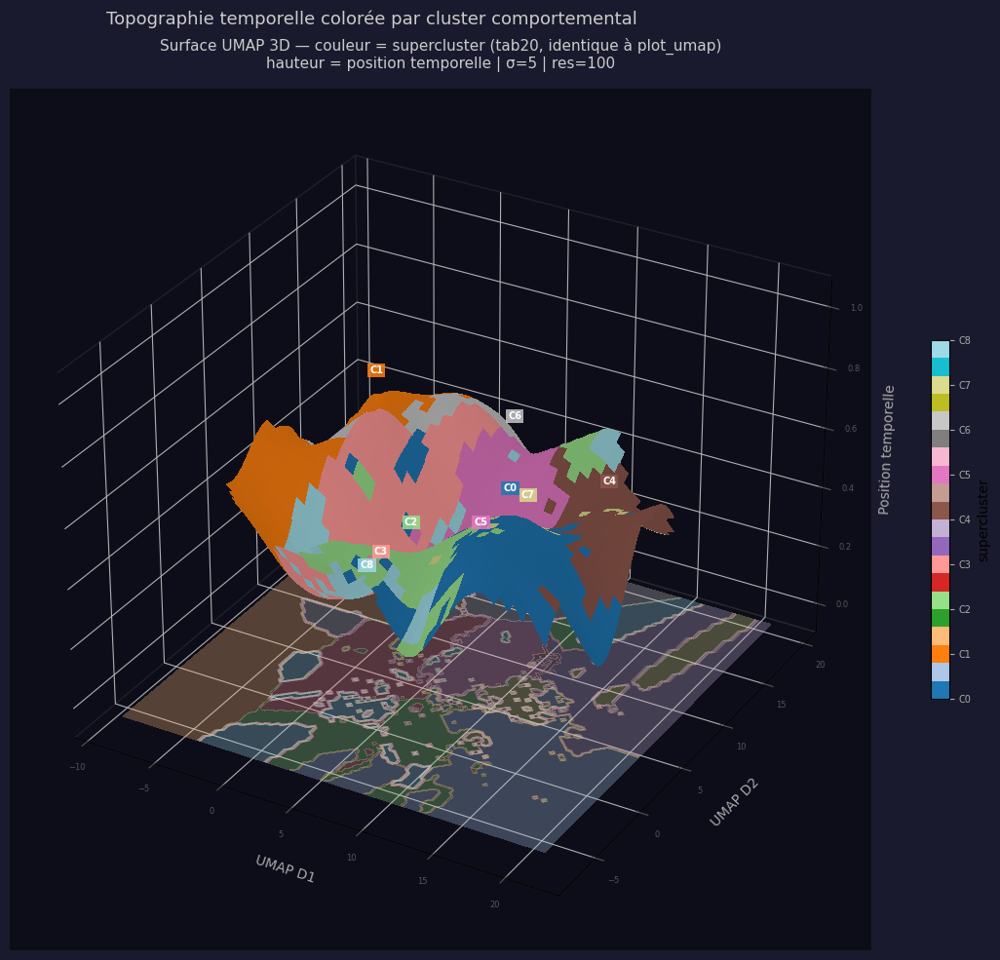

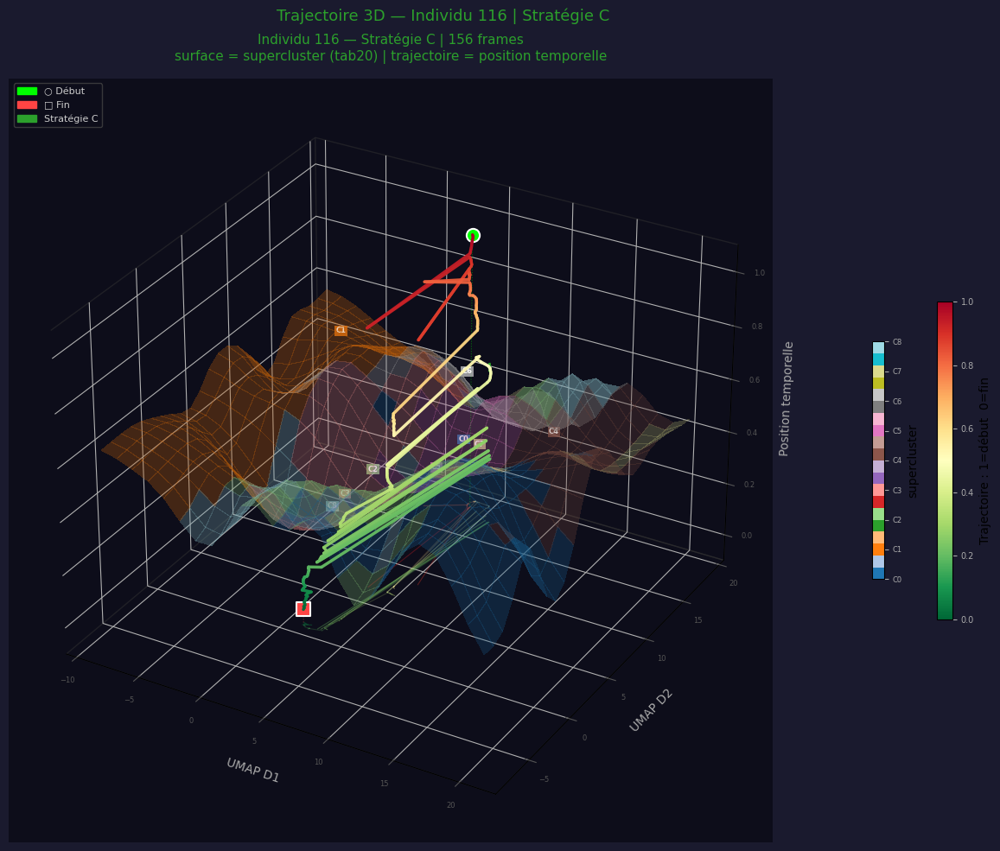

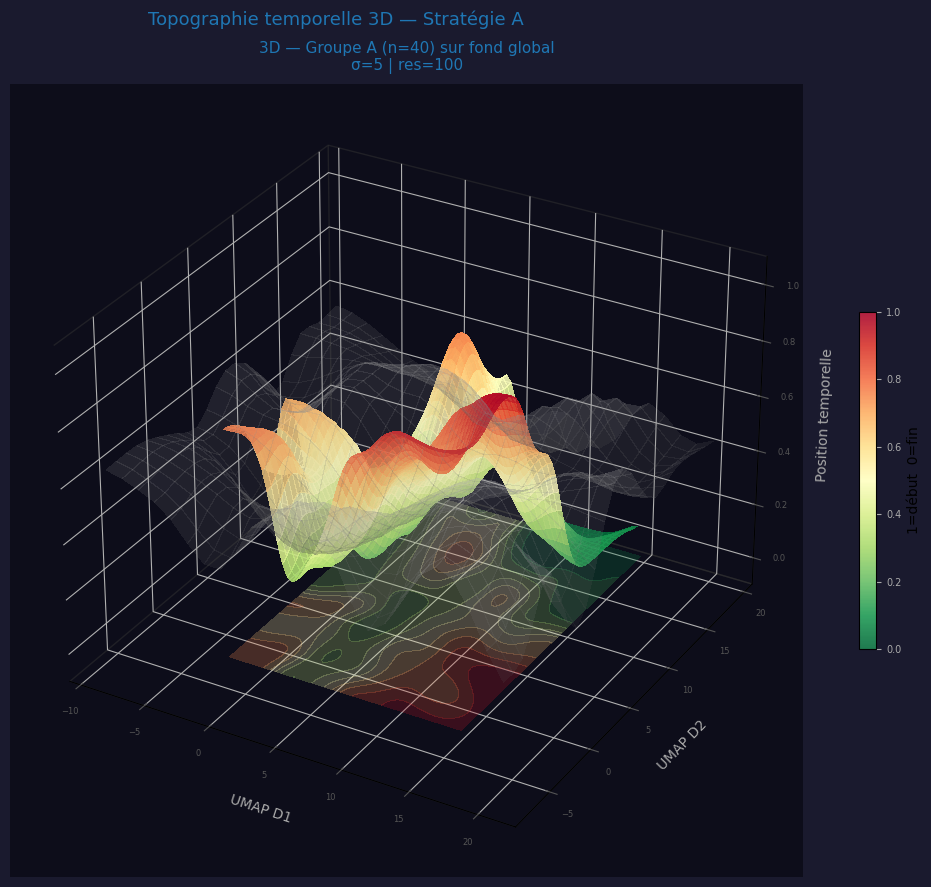

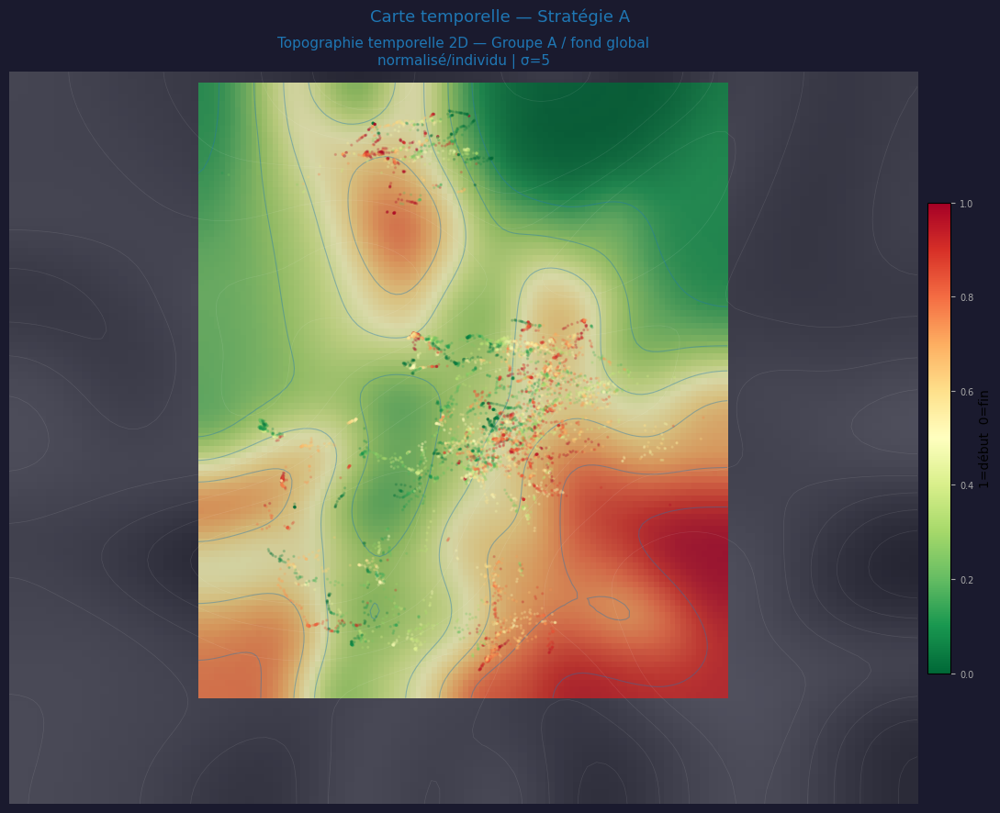

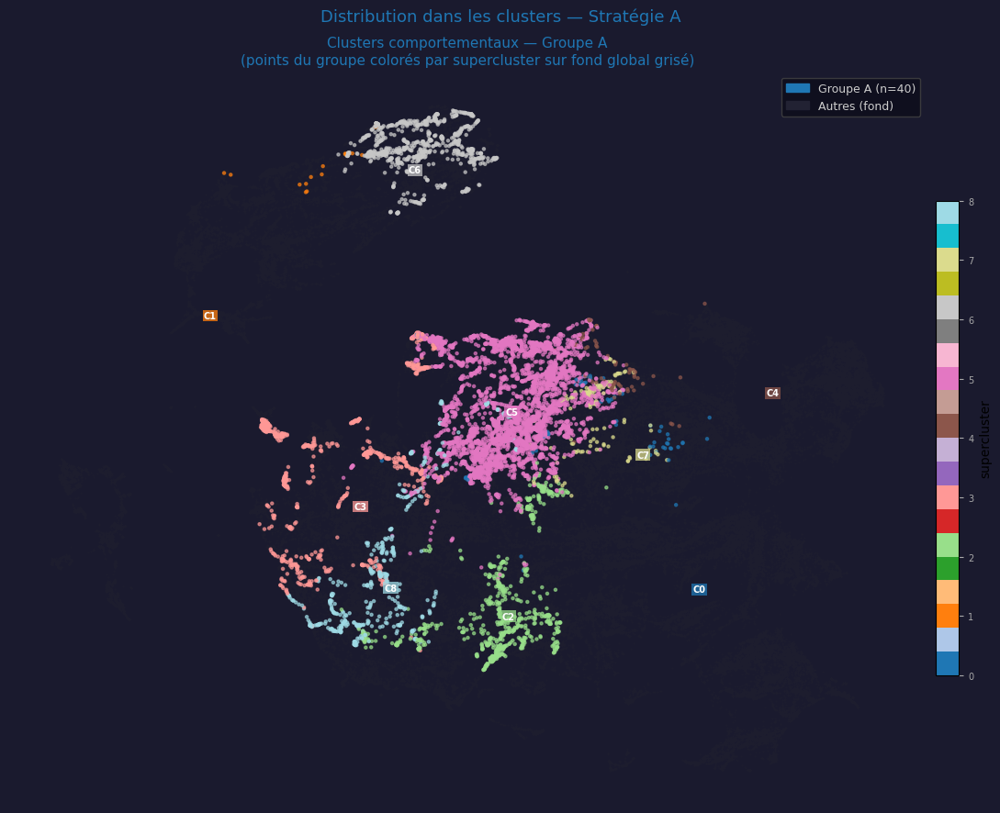

...

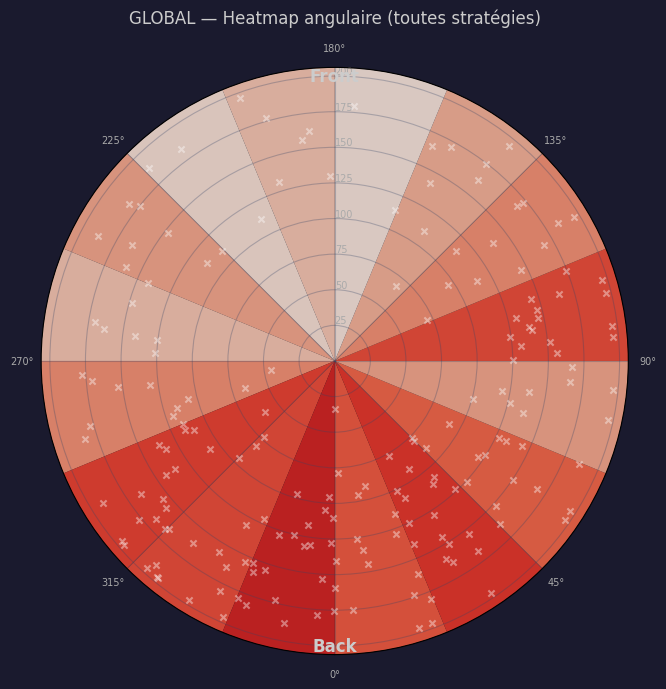

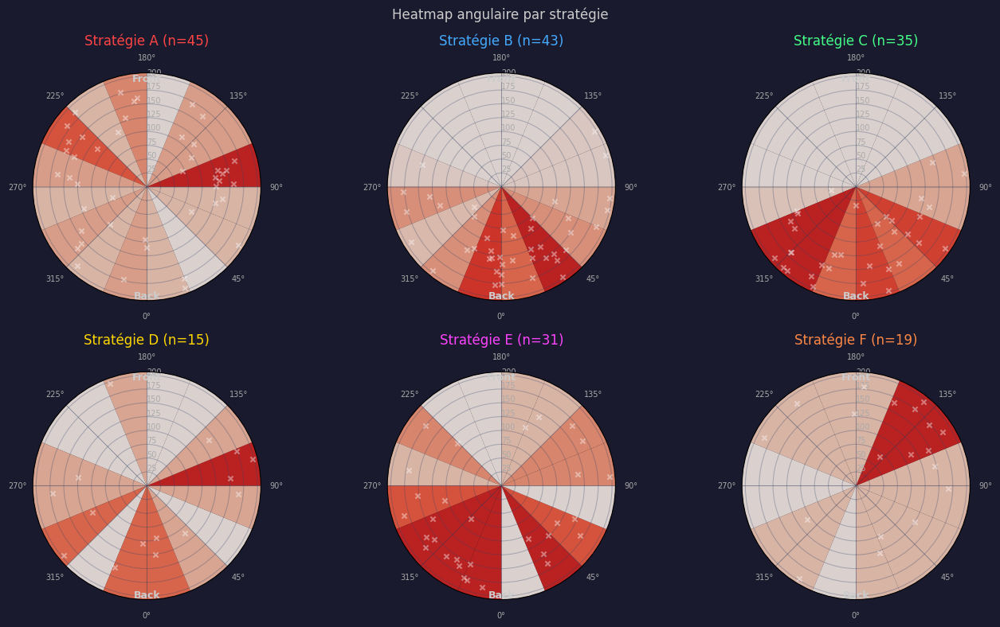

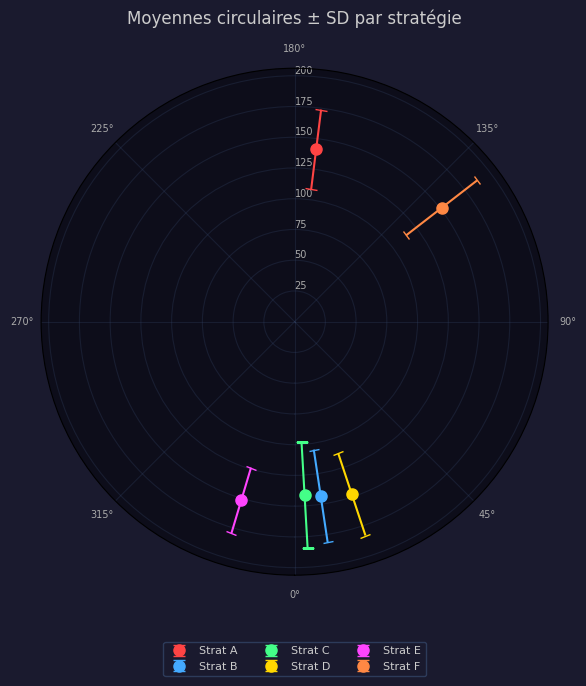

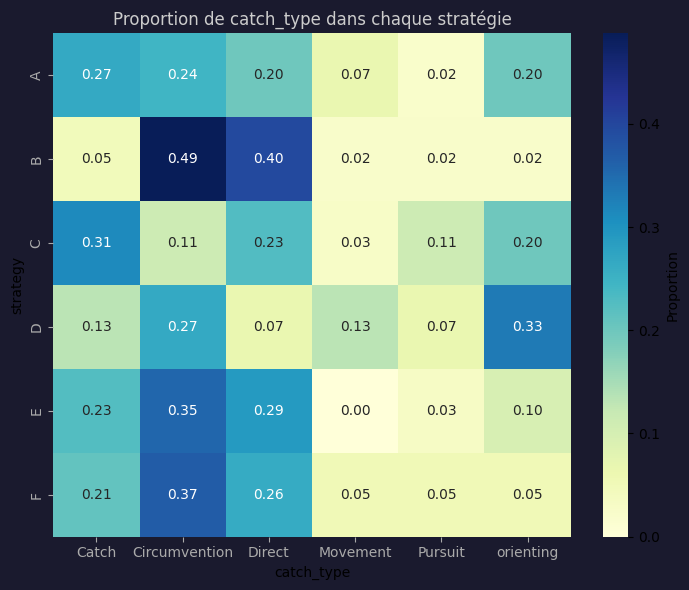

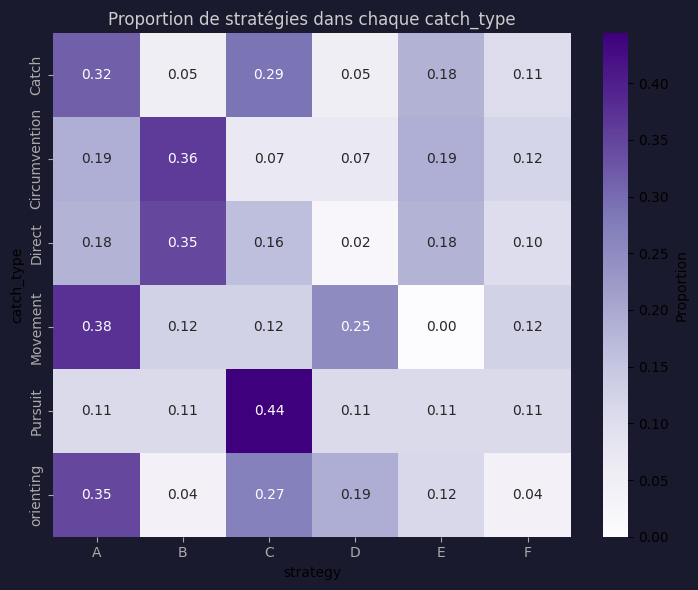


[OK] Graphes KDR...
  Après merge : 203 lignes
  Matchés avec strategy : 188
  187 individus valides | stratégies : ['A', 'B', 'C', 'D', 'E', 'F']


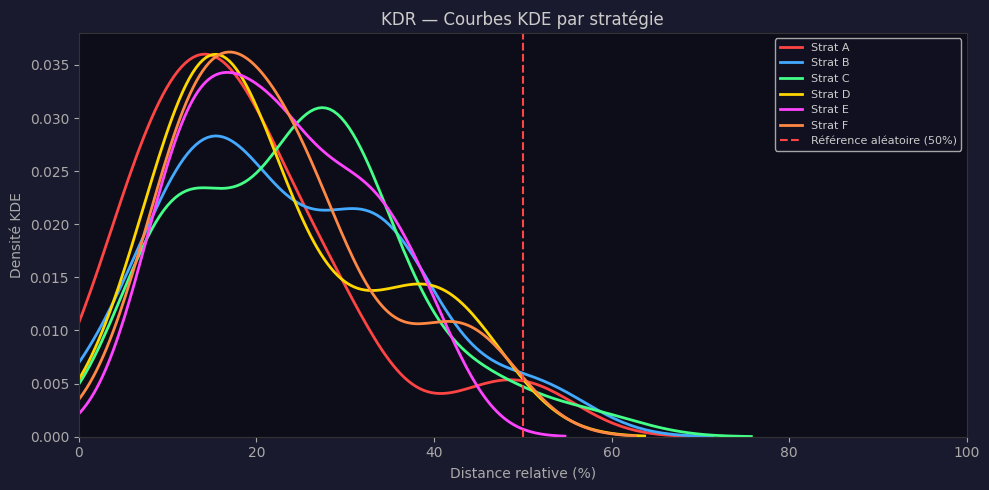

C:\Users\nonoh\AppData\Local\Temp\ipykernel_28408\3556605005.py:338: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x="strategy", y="distance_relative", data=df_hit,
C:\Users\nonoh\AppData\Local\Temp\ipykernel_28408\3556605005.py:345: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels([f"Strat {s}" for s in strats_hit], color="#aaaaaa")


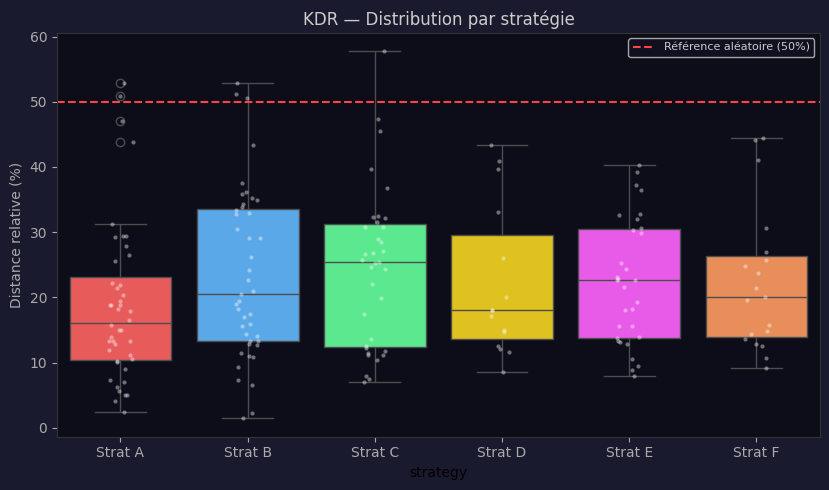

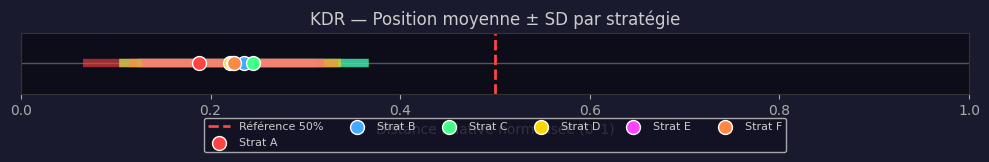

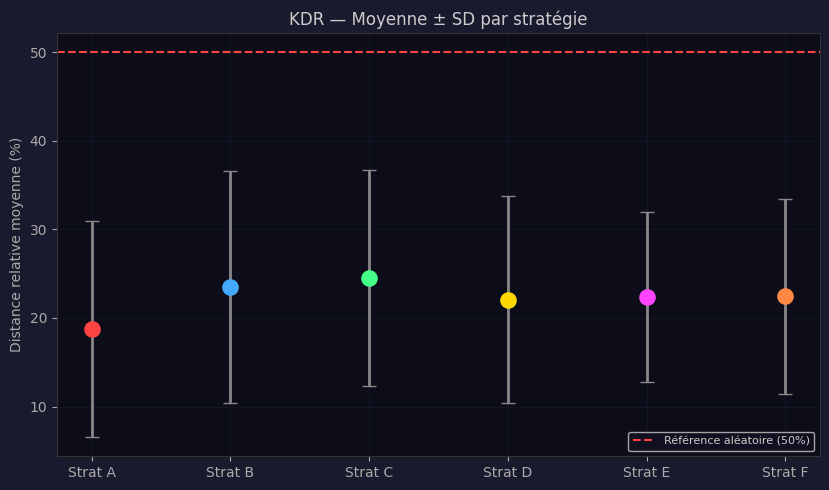

In [45]:
# ══════════════════════════════════════════════════════════════
#  GRAPHES POLAIRES + KDR — version notebook inline
# ══════════════════════════════════════════════════════════════

%matplotlib inline

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

# ── Paramètres ────────────────────────────────────────────────
COMPARATIVE_DATA_PATH = r"E:\01_Travail\CREC\First_Capture\analyse\Data_cuttlfish_strike_complet.xlsx"
HIT_DATA_PATH         = r""   # ← renseigner si fichier hit disponible

DIST_COL  = "Distance_strike_px"
ANGLE_COL = "angle_strike_360"
CATCH_COL = "catch_type"
NBINS     = 16
CAP_PCT   = 0.90

# ── Construire df_summary depuis mapping_optimal ──────────────
df_summary = pd.DataFrame([
    {"ID": int(aid), "strategy": g}
    for aid, g in mapping_optimal.items()
    if g != "MONO"
])
print(f"[OK] {len(df_summary)} individus | "
      f"stratégies : {sorted(df_summary['strategy'].unique())}")

# ── Chargement + fusion ───────────────────────────────────────
df_data   = pd.read_excel(COMPARATIVE_DATA_PATH)
df_merged = df_data.merge(
    df_summary[["ID","strategy"]],
    left_on="video_id", right_on="ID", how="inner"
).dropna(subset=["strategy"])

strategies = sorted(df_merged["strategy"].unique())
n_strat    = len(strategies)
print(f"[OK] {len(df_merged)} individus après fusion | "
      f"{n_strat} stratégies : {strategies}")

# Palette cohérente avec le notebook
pal_strat = {s: STRATEGY_PALETTE[i % len(STRATEGY_PALETTE)]
             for i, s in enumerate(strategies)}

def _hex_rgb(h):
    h = h.lstrip("#")
    return tuple(int(h[i:i+2],16)/255 for i in (0,2,4))

def _theta(series):
    return np.deg2rad(series % 360)

def _setup_polar(ax, r_lim):
    ax.set_theta_zero_location("S")
    ax.set_theta_direction(1)
    ax.set_ylim(0, r_lim)
    ax.grid(alpha=0.3, color="#334466")
    ax.set_rlabel_position(180)
    ax.tick_params(labelsize=7, colors="#aaaaaa")
    ax.set_facecolor("#0d0d1a")

def _draw_density(ax, theta_vals, nbins, r_lim):
    hist, edges = np.histogram(theta_vals, bins=nbins, range=(0, 2*np.pi))
    norm = hist / hist.max() if hist.max() > 0 else hist
    cmap = plt.cm.Reds
    for left, width, h in zip(edges[:-1], np.diff(edges), norm):
        ax.bar(left, r_lim, width=width, bottom=0.0,
               color=cmap(h*0.7), edgecolor="none",
               align="edge", alpha=0.85)

def _circular_mean(angles_rad):
    m = np.arctan2(np.sin(angles_rad).sum(), np.cos(angles_rad).sum())
    return m if m >= 0 else m + 2*np.pi


# ════════════════════════════════════════════════════════════
# FIGURE 1 — Polar global
# ════════════════════════════════════════════════════════════
if DIST_COL in df_merged.columns and ANGLE_COL in df_merged.columns:

    cap_val = df_merged[DIST_COL].quantile(CAP_PCT)
    df_merged["_dist_plot"] = np.minimum(
        df_merged[DIST_COL].astype(float), float(cap_val))
    r_lim_global = df_merged["_dist_plot"].max() * 1.05

    fig = plt.figure(figsize=(7,7))
    fig.patch.set_facecolor("#1a1a2e")
    ax  = fig.add_subplot(111, polar=True)
    _setup_polar(ax, r_lim_global)

    theta_all = _theta(df_merged[ANGLE_COL].dropna())
    dist_all  = df_merged.loc[df_merged[ANGLE_COL].notna(), "_dist_plot"]
    _draw_density(ax, theta_all, NBINS, r_lim_global)
    ax.scatter(theta_all, dist_all, marker="x", s=20,
               alpha=0.4, color="white", zorder=2)
    ax.set_title("GLOBAL — Heatmap angulaire (toutes stratégies)",
                 color="#cccccc", pad=14)
    ax.text(0,      r_lim_global, "Back",  fontsize=12,
            fontweight="bold", ha="center", va="bottom", color="#cccccc")
    ax.text(np.pi,  r_lim_global, "Front", fontsize=12,
            fontweight="bold", ha="center", va="top",   color="#cccccc")
    plt.tight_layout(); plt.show()


    # ════════════════════════════════════════════════════════
    # FIGURE 2 — Polar par stratégie
    # ════════════════════════════════════════════════════════
    nc   = min(3, n_strat)
    nr   = int(np.ceil(n_strat / nc))
    fig, axes = plt.subplots(nr, nc, subplot_kw=dict(polar=True),
                              figsize=(nc*4.5, nr*4))
    fig.patch.set_facecolor("#1a1a2e")
    fig.suptitle("Heatmap angulaire par stratégie",
                 color="#cccccc", fontsize=12)
    axes_flat = np.array(axes).flatten() if nr*nc > 1 else [axes]

    for i, strat in enumerate(strategies):
        ax  = axes_flat[i]
        sub = df_merged[df_merged["strategy"]==strat
                        ].dropna(subset=[ANGLE_COL])
        r_lim_s = sub["_dist_plot"].max()*1.05 if len(sub) else 1.0
        _setup_polar(ax, r_lim_s)
        if len(sub):
            th = _theta(sub[ANGLE_COL])
            _draw_density(ax, th, NBINS, r_lim_s)
            ax.scatter(th, sub["_dist_plot"], marker="x", s=20,
                       alpha=0.4, color="white", zorder=2)
            ax.text(0,     r_lim_s, "Back",  fontsize=9,
                    fontweight="bold", ha="center", va="bottom",
                    color="#cccccc")
            ax.text(np.pi, r_lim_s, "Front", fontsize=9,
                    fontweight="bold", ha="center", va="top",
                    color="#cccccc")
        ax.set_title(f"Stratégie {strat} (n={len(sub)})",
                     color=pal_strat.get(strat,"#ffffff"), pad=8)

    for j in range(n_strat, len(axes_flat)):
        axes_flat[j].set_visible(False)
    plt.tight_layout(); plt.show()


    # ════════════════════════════════════════════════════════
    # FIGURE 3 — Moyennes circulaires ± SD
    # ════════════════════════════════════════════════════════
    fig = plt.figure(figsize=(7,7))
    fig.patch.set_facecolor("#1a1a2e")
    ax  = fig.add_subplot(111, polar=True)
    _setup_polar(ax, r_lim_global)

    for strat in strategies:
        sub = df_merged[df_merged["strategy"]==strat
                        ].dropna(subset=[ANGLE_COL,"_dist_plot"])
        if len(sub) == 0: continue
        theta_mean = _circular_mean(np.deg2rad(sub[ANGLE_COL]))
        r_mean     = sub["_dist_plot"].mean()
        r_std      = sub["_dist_plot"].std()
        col_s      = _hex_rgb(pal_strat.get(strat,"#ffffff"))
        ax.errorbar(theta_mean, r_mean, yerr=r_std, fmt="o",
                    color=col_s, capsize=4, markersize=8,
                    label=f"Strat {strat}")

    ax.set_title("Moyennes circulaires ± SD par stratégie",
                 color="#cccccc", pad=14)
    leg = ax.legend(loc="upper center", bbox_to_anchor=(0.5,-0.12),
                    ncol=3, fontsize=8)
    leg.get_frame().set_facecolor("#1a1a2e")
    leg.get_frame().set_edgecolor("#334466")
    for t in leg.get_texts(): t.set_color("#cccccc")
    plt.tight_layout(); plt.show()

    df_merged.drop(columns=["_dist_plot"], inplace=True)


    # ════════════════════════════════════════════════════════
    # FIGURE 4 — Heatmaps catch_type × stratégie
    # ════════════════════════════════════════════════════════
    catch_col_found = None
    for c in ["catch_type", "catch_type_redefined", "catch_type_found",
               "Catch_type"]:
        if c in df_merged.columns:
            catch_col_found = c
            break

    if catch_col_found:
        df_counts = (
            df_merged.dropna(subset=[catch_col_found,"strategy"])
            .groupby(["strategy", catch_col_found])
            .size().reset_index(name="count")
        )

        # Proportion catch dans stratégie
        df_pc         = df_counts.copy()
        df_pc["prop"] = (df_pc["count"] /
                         df_pc.groupby("strategy")["count"].transform("sum"))
        pivot = df_pc.pivot(index="strategy", columns=catch_col_found,
                            values="prop").fillna(0)

        fig, ax = plt.subplots(
            figsize=(max(6, len(pivot.columns)*1.2), max(4, len(pivot))))
        fig.patch.set_facecolor("#1a1a2e")
        ax.set_facecolor("#0d0d1a")
        sns.heatmap(pivot, annot=True, fmt=".2f", cmap="YlGnBu", ax=ax,
                    cbar_kws={"label":"Proportion"})
        ax.set_title("Proportion de catch_type dans chaque stratégie",
                     color="#cccccc")
        ax.tick_params(colors="#aaaaaa")
        plt.tight_layout(); plt.show()

        # Proportion stratégie dans catch
        df_ps         = df_counts.copy()
        df_ps["prop"] = (df_ps["count"] /
                         df_ps.groupby(catch_col_found)["count"].transform("sum"))
        pivot2 = df_ps.pivot(index=catch_col_found, columns="strategy",
                             values="prop").fillna(0)

        fig, ax = plt.subplots(
            figsize=(max(6, len(pivot2.columns)*1.2), max(4, len(pivot2))))
        fig.patch.set_facecolor("#1a1a2e")
        ax.set_facecolor("#0d0d1a")
        sns.heatmap(pivot2, annot=True, fmt=".2f", cmap="Purples", ax=ax,
                    cbar_kws={"label":"Proportion"})
        ax.set_title("Proportion de stratégies dans chaque catch_type",
                     color="#cccccc")
        ax.tick_params(colors="#aaaaaa")
        plt.tight_layout(); plt.show()
    else:
        print("[SKIP] Aucune colonne catch_type trouvée")

else:
    print(f"[SKIP] Colonnes absentes : {DIST_COL} / {ANGLE_COL}")

# ════════════════════════════════════════════════════════
    # FIGURE 4 — Heatmaps pour chaque variante de catch_type
    # ════════════════════════════════════════════════════════
    for catch_col in ["catch_type", "catch_type_redefined", "catch_type_found"]:
        if catch_col not in df_merged.columns:
            print(f"[SKIP] {catch_col} absent")
            continue

        df_counts = (
            df_merged.dropna(subset=[catch_col, "strategy"])
            .groupby(["strategy", catch_col])
            .size().reset_index(name="count")
        )
        if len(df_counts) == 0:
            print(f"[SKIP] {catch_col} — aucune donnée")
            continue

        # Proportion catch dans stratégie
        df_pc         = df_counts.copy()
        df_pc["prop"] = (df_pc["count"] /
                         df_pc.groupby("strategy")["count"].transform("sum"))
        pivot = df_pc.pivot(index="strategy", columns=catch_col,
                            values="prop").fillna(0)

        fig, ax = plt.subplots(
            figsize=(max(6, len(pivot.columns)*1.2), max(4, len(pivot))))
        fig.patch.set_facecolor("#1a1a2e"); ax.set_facecolor("#0d0d1a")
        sns.heatmap(pivot, annot=True, fmt=".2f", cmap="YlGnBu", ax=ax,
                    cbar_kws={"label":"Proportion"})
        ax.set_title(f"Proportion de {catch_col} dans chaque stratégie",
                     color="#cccccc")
        ax.tick_params(colors="#aaaaaa")
        plt.tight_layout(); plt.show()

        # Proportion stratégie dans catch
        df_ps         = df_counts.copy()
        df_ps["prop"] = (df_ps["count"] /
                         df_ps.groupby(catch_col)["count"].transform("sum"))
        pivot2 = df_ps.pivot(index=catch_col, columns="strategy",
                             values="prop").fillna(0)

        fig, ax = plt.subplots(
            figsize=(max(6, len(pivot2.columns)*1.2), max(4, len(pivot2))))
        fig.patch.set_facecolor("#1a1a2e"); ax.set_facecolor("#0d0d1a")
        sns.heatmap(pivot2, annot=True, fmt=".2f", cmap="Purples", ax=ax,
                    cbar_kws={"label":"Proportion"})
        ax.set_title(f"Proportion de stratégies dans chaque {catch_col}",
                     color="#cccccc")
        ax.tick_params(colors="#aaaaaa")
        plt.tight_layout(); plt.show()

# ════════════════════════════════════════════════════════════
# FIGURE 5-8 — KDR (distance relative du point de frappe)
# ════════════════════════════════════════════════════════════
hit_path = Path(r"E:\01_Travail\CREC\First_Capture\analyse\Classeur1.xlsx")

if hit_path.exists():
    print("\n[OK] Graphes KDR...")
    df_hit = pd.read_excel(hit_path)

    # Merge sur video → video_id pour récupérer Length_Shrimp + strategy
    df_hit = df_hit.merge(
        df_merged[["video_id", "Length_Shrimp", "strategy"]],
        left_on="video", right_on="video_id", how="left"
    )

    print(f"  Après merge : {len(df_hit)} lignes")
    print(f"  Matchés avec strategy : {df_hit['strategy'].notna().sum()}")

    df_hit["distance_relative"] = (
        df_hit["distance_yeux_tentacule"].astype(float) /
        df_hit["Length_Shrimp"].astype(float)
    ) * 100

    df_hit     = df_hit.dropna(subset=["distance_relative","strategy"])
    strats_hit = sorted(df_hit["strategy"].unique())
    print(f"  {len(df_hit)} individus valides | stratégies : {strats_hit}")

    # ── KDE global ───────────────────────────────────────────
    fig, ax = plt.subplots(figsize=(10, 5))
    fig.patch.set_facecolor("#1a1a2e"); ax.set_facecolor("#0d0d1a")
    for sp in ax.spines.values(): sp.set_edgecolor("#333333")
    for strat in strats_hit:
        sub   = df_hit[df_hit["strategy"]==strat]["distance_relative"]
        col_s = _hex_rgb(pal_strat.get(strat,"#ffffff"))
        sns.kdeplot(sub, ax=ax, fill=False, lw=2,
                    color=col_s, label=f"Strat {strat}")
    ax.axvline(50, color="#ff4444", lw=1.5, ls="--",
               label="Référence aléatoire (50%)")
    ax.set_xlim(0, 100)
    ax.set_xlabel("Distance relative (%)", color="#aaaaaa")
    ax.set_ylabel("Densité KDE",           color="#aaaaaa")
    ax.set_title("KDR — Courbes KDE par stratégie", color="#cccccc")
    ax.tick_params(colors="#aaaaaa")
    leg = ax.legend(fontsize=8)
    leg.get_frame().set_facecolor("#111122")
    for t in leg.get_texts(): t.set_color("#cccccc")
    plt.tight_layout(); plt.show()

    # ── Boxplot KDR ───────────────────────────────────────────
    fig, ax = plt.subplots(figsize=(max(8, len(strats_hit)*1.4), 5))
    fig.patch.set_facecolor("#1a1a2e"); ax.set_facecolor("#0d0d1a")
    for sp in ax.spines.values(): sp.set_edgecolor("#333333")
    pal_hit = {s: pal_strat.get(s,"#888888") for s in strats_hit}
    sns.boxplot(x="strategy", y="distance_relative", data=df_hit,
                order=strats_hit, palette=pal_hit, ax=ax)
    sns.stripplot(x="strategy", y="distance_relative", data=df_hit,
                  order=strats_hit, color="white",
                  alpha=0.4, size=3, ax=ax)
    ax.axhline(50, color="#ff4444", ls="--", lw=1.5,
               label="Référence aléatoire (50%)")
    ax.set_xticklabels([f"Strat {s}" for s in strats_hit], color="#aaaaaa")
    ax.set_title("KDR — Distribution par stratégie", color="#cccccc")
    ax.set_ylabel("Distance relative (%)", color="#aaaaaa")
    ax.tick_params(colors="#aaaaaa")
    leg = ax.legend(fontsize=8)
    leg.get_frame().set_facecolor("#111122")
    for t in leg.get_texts(): t.set_color("#cccccc")
    plt.tight_layout(); plt.show()

    # ── Moyenne ± SD ligne horizontale ────────────────────────
    means      = [df_hit[df_hit["strategy"]==s]["distance_relative"].mean()
                  for s in strats_hit]
    stds       = [df_hit[df_hit["strategy"]==s]["distance_relative"].std()
                  for s in strats_hit]
    means_norm = np.array(means)/100
    stds_norm  = np.array(stds)/100

    fig, ax = plt.subplots(figsize=(10, 2))
    fig.patch.set_facecolor("#1a1a2e"); ax.set_facecolor("#0d0d1a")
    ax.plot([0,1],[0,0], color="#555555", lw=1)
    ax.axvline(0.5, color="#ff4444", ls="--", lw=2, label="Référence 50%")
    for i, strat in enumerate(strats_hit):
        m, s  = means_norm[i], stds_norm[i]
        col_s = _hex_rgb(pal_strat.get(strat,"#888888"))
        ax.hlines(0, m-s, m+s, color=col_s, lw=6, alpha=0.6)
        ax.scatter(m, 0, color=col_s, s=100,
                   edgecolor="white", zorder=3, label=f"Strat {strat}")
    ax.set_yticks([])
    ax.set_xlim(0, 1)
    ax.set_xlabel("Distance relative normalisée (0–1)", color="#aaaaaa")
    ax.set_title("KDR — Position moyenne ± SD par stratégie", color="#cccccc")
    ax.tick_params(colors="#aaaaaa")
    for sp in ax.spines.values(): sp.set_edgecolor("#333333")
    leg = ax.legend(loc="upper center", bbox_to_anchor=(0.5,-0.3),
                    ncol=len(strats_hit), fontsize=8)
    leg.get_frame().set_facecolor("#111122")
    for t in leg.get_texts(): t.set_color("#cccccc")
    plt.tight_layout(); plt.show()

    # ── Moyenne ± SD errorbar ─────────────────────────────────
    x   = np.arange(len(strats_hit))
    fig, ax = plt.subplots(figsize=(max(8, len(strats_hit)*1.4), 5))
    fig.patch.set_facecolor("#1a1a2e"); ax.set_facecolor("#0d0d1a")
    for sp in ax.spines.values(): sp.set_edgecolor("#333333")
    ax.errorbar(x, means, yerr=stds, fmt="o", markersize=8,
                capsize=5, color="white", ecolor="#888888", elinewidth=2)
    for i, strat in enumerate(strats_hit):
        col_s = _hex_rgb(pal_strat.get(strat,"#888888"))
        ax.scatter(x[i], means[i], color=col_s, s=120, zorder=3)
    ax.axhline(50, color="#ff4444", ls="--", lw=1.5,
               label="Référence aléatoire (50%)")
    ax.set_xticks(x)
    ax.set_xticklabels([f"Strat {s}" for s in strats_hit], color="#aaaaaa")
    ax.set_ylabel("Distance relative moyenne (%)", color="#aaaaaa")
    ax.set_title("KDR — Moyenne ± SD par stratégie", color="#cccccc")
    ax.tick_params(colors="#aaaaaa")
    ax.grid(alpha=0.15, color="#334455")
    leg = ax.legend(fontsize=8)
    leg.get_frame().set_facecolor("#111122")
    for t in leg.get_texts(): t.set_color("#cccccc")
    plt.tight_layout(); plt.show()

else:
    print(f"[SKIP] Fichier hit introuvable : {hit_path}")


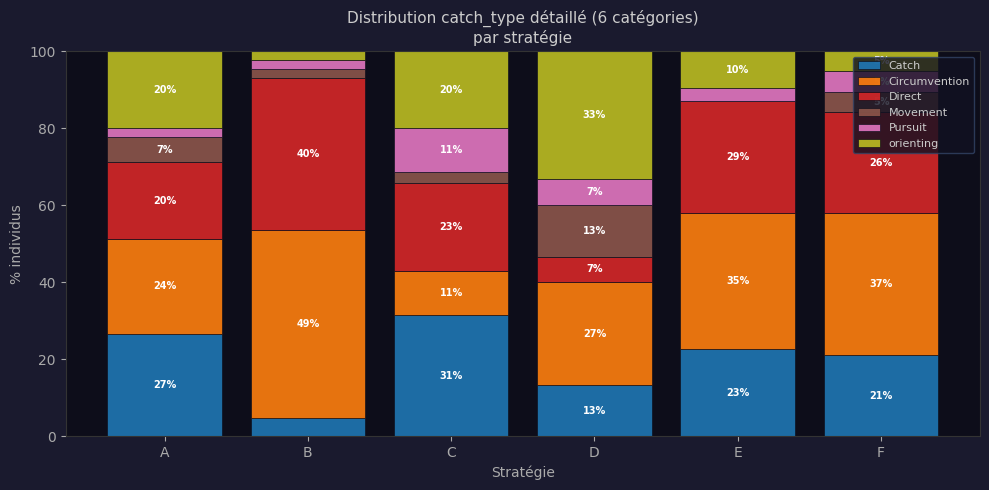

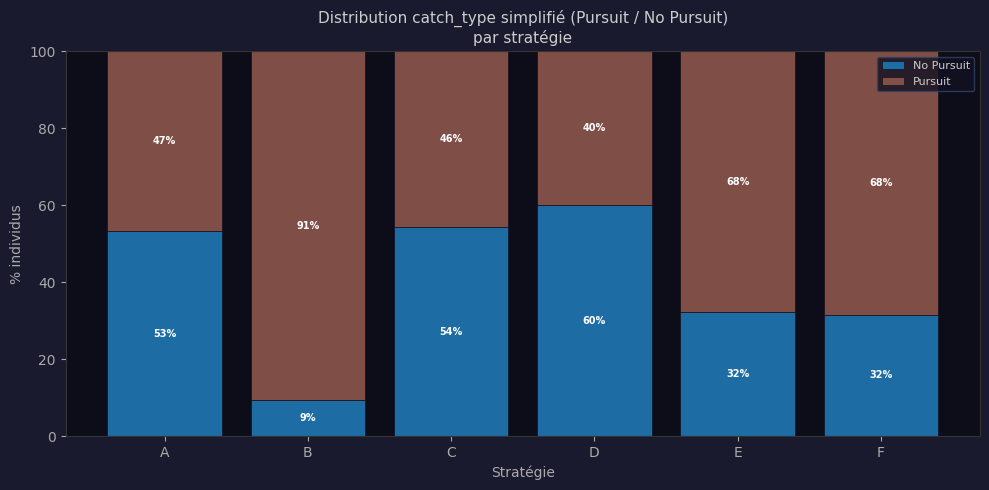

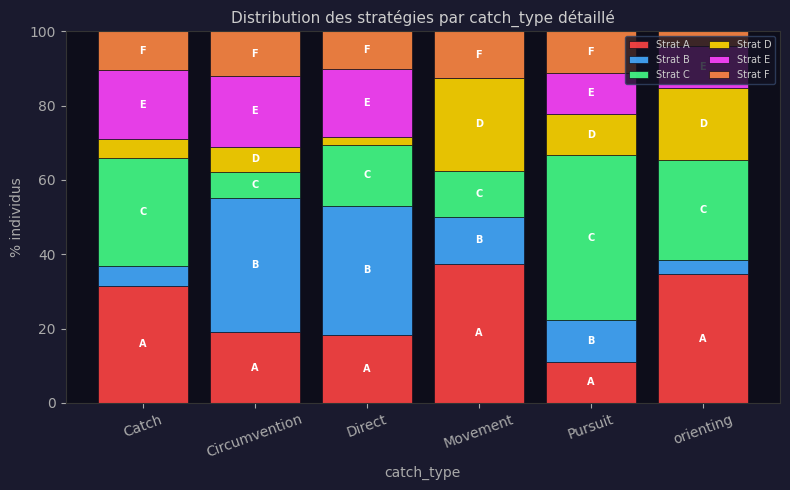

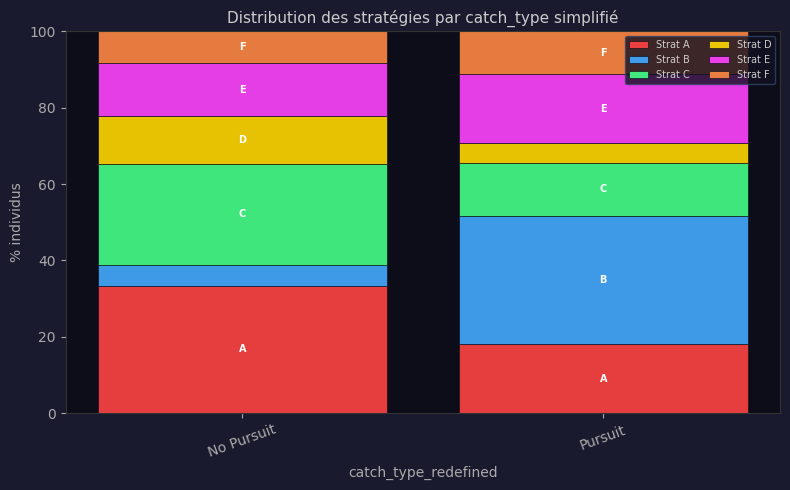

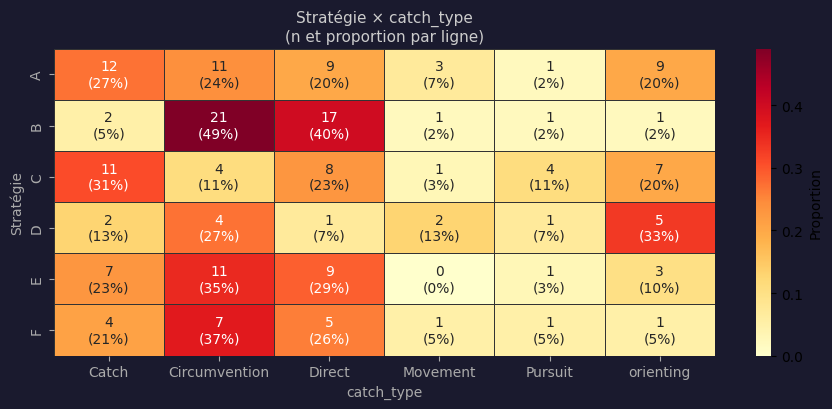

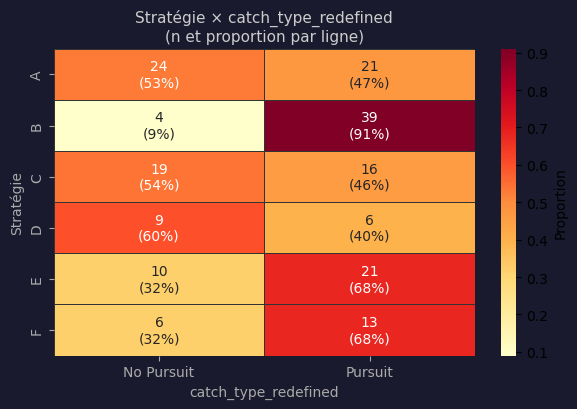


Chi² (catch détaillé) : χ²=46.57  p=0.0055  ddl=25
  **  p < 0.01  — association significative


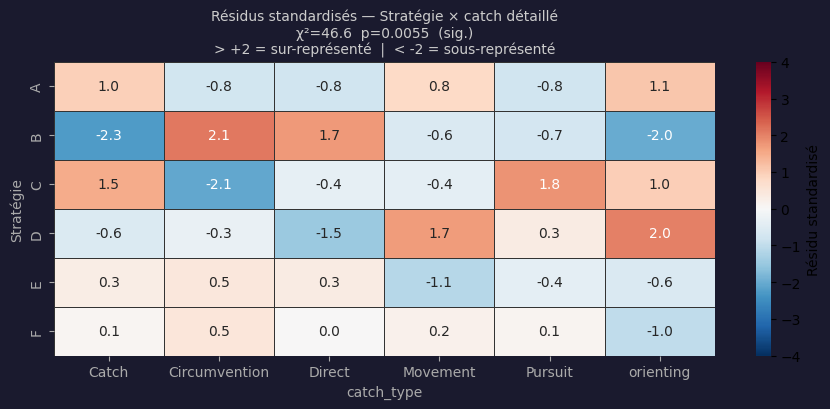


Chi² (Pursuit/No Pursuit) : χ²=27.22  p=0.0001  ddl=5
  *** p < 0.001 — association très significative


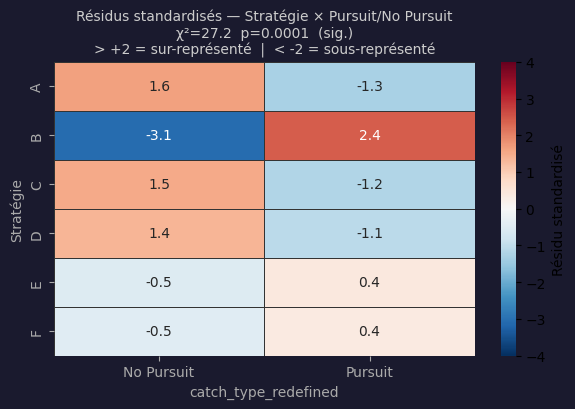

In [46]:
# ════════════════════════════════════════════════════════════
#  COMPARAISON CATCH TYPE × STRATÉGIE
# ════════════════════════════════════════════════════════════

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import chi2_contingency, fisher_exact
from itertools import combinations

fig_bg  = "#1a1a2e"
ax_bg   = "#0d0d1a"
txt_col = "#cccccc"

def _style(ax):
    ax.set_facecolor(ax_bg)
    for sp in ax.spines.values(): sp.set_edgecolor("#333333")
    ax.tick_params(colors="#aaaaaa")

# ════════════════════════════════════════════════════════════
# FIGURE 1 — Distribution des catch_type par stratégie
#            (barres empilées normalisées)
# ════════════════════════════════════════════════════════════
for catch_col, title_suffix in [
    ("catch_type",          "détaillé (6 catégories)"),
    ("catch_type_redefined","simplifié (Pursuit / No Pursuit)"),
]:
    ct = pd.crosstab(df_merged["strategy"], df_merged[catch_col],
                     normalize="index") * 100

    fig, ax = plt.subplots(figsize=(max(10, len(ct)*0.9), 5))
    fig.patch.set_facecolor(fig_bg); _style(ax)

    bottom = np.zeros(len(ct))
    cats   = ct.columns.tolist()
    cmap   = plt.cm.tab10

    for i, cat in enumerate(cats):
        vals = ct[cat].values
        bars = ax.bar(ct.index, vals, bottom=bottom,
                      color=cmap(i/len(cats)), label=cat,
                      edgecolor="#0d0d1a", lw=0.5, alpha=0.9)
        # Label si assez large
        for j, (v, b) in enumerate(zip(vals, bottom)):
            if v > 5:
                ax.text(j, b + v/2, f"{v:.0f}%",
                        ha="center", va="center",
                        fontsize=7, color="white", fontweight="bold")
        bottom += vals

    ax.set_ylim(0, 100)
    ax.set_ylabel("% individus", color="#aaaaaa")
    ax.set_xlabel("Stratégie",   color="#aaaaaa")
    ax.set_title(f"Distribution catch_type {title_suffix}\npar stratégie",
                 color=txt_col, fontsize=11)
    ax.tick_params(axis="x", colors="#aaaaaa")
    ax.tick_params(axis="y", colors="#aaaaaa")
    leg = ax.legend(loc="upper right", fontsize=8,
                    facecolor="#111122", edgecolor="#334466")
    for t in leg.get_texts(): t.set_color(txt_col)
    plt.tight_layout(); plt.show()


# ════════════════════════════════════════════════════════════
# FIGURE 2 — Distribution des stratégies par catch_type
#            (inverse : qui fait quoi ?)
# ════════════════════════════════════════════════════════════
for catch_col, title_suffix in [
    ("catch_type",          "détaillé"),
    ("catch_type_redefined","simplifié"),
]:
    ct = pd.crosstab(df_merged[catch_col], df_merged["strategy"],
                     normalize="index") * 100

    fig, ax = plt.subplots(figsize=(max(8, len(ct)*1.2), 5))
    fig.patch.set_facecolor(fig_bg); _style(ax)

    bottom = np.zeros(len(ct))
    for i, strat in enumerate(ct.columns):
        vals = ct[strat].values
        col_s = pal_strat.get(strat, "#888888")
        r,g,b = tuple(int(col_s.lstrip("#")[j:j+2],16)/255 for j in (0,2,4))
        ax.bar(ct.index, vals, bottom=bottom,
               color=(r,g,b), label=f"Strat {strat}",
               edgecolor="#0d0d1a", lw=0.5, alpha=0.9)
        for j, (v, b) in enumerate(zip(vals, bottom)):
            if v > 6:
                ax.text(j, b + v/2, strat,
                        ha="center", va="center",
                        fontsize=7, color="white", fontweight="bold")
        bottom += vals

    ax.set_ylim(0, 100)
    ax.set_ylabel("% individus", color="#aaaaaa")
    ax.set_xlabel(catch_col,     color="#aaaaaa")
    ax.set_title(f"Distribution des stratégies par catch_type {title_suffix}",
                 color=txt_col, fontsize=11)
    ax.tick_params(axis="x", colors="#aaaaaa", rotation=20)
    ax.tick_params(axis="y", colors="#aaaaaa")
    leg = ax.legend(loc="upper right", fontsize=7, ncol=2,
                    facecolor="#111122", edgecolor="#334466")
    for t in leg.get_texts(): t.set_color(txt_col)
    plt.tight_layout(); plt.show()


# ════════════════════════════════════════════════════════════
# FIGURE 3 — Heatmap comptages + proportions
# ════════════════════════════════════════════════════════════
for catch_col in ["catch_type", "catch_type_redefined"]:
    ct_count = pd.crosstab(df_merged["strategy"], df_merged[catch_col])
    ct_prop  = ct_count.div(ct_count.sum(axis=1), axis=0).round(2)

    # Annotations : "n (xx%)"
    annot = ct_count.astype(str) + "\n(" + (ct_prop*100).round(0).astype(int).astype(str) + "%)"

    fig, ax = plt.subplots(
        figsize=(max(6, len(ct_count.columns)*1.5),
                 max(4, len(ct_count)*0.7)))
    fig.patch.set_facecolor(fig_bg)
    sns.heatmap(ct_prop, annot=annot, fmt="", cmap="YlOrRd",
                ax=ax, linewidths=0.5, linecolor="#333333",
                cbar_kws={"label":"Proportion"})
    ax.set_title(f"Stratégie × {catch_col}\n(n et proportion par ligne)",
                 color=txt_col, fontsize=11)
    ax.set_xlabel(catch_col,   color="#aaaaaa")
    ax.set_ylabel("Stratégie", color="#aaaaaa")
    ax.tick_params(colors="#aaaaaa")
    plt.tight_layout(); plt.show()


# ════════════════════════════════════════════════════════════
# FIGURE 4 — Test Chi² + résidus standardisés
#            Quelles associations stratégie/catch sont
#            significativement sur- ou sous-représentées ?
# ════════════════════════════════════════════════════════════
for catch_col, label in [
    ("catch_type",          "catch détaillé"),
    ("catch_type_redefined","Pursuit/No Pursuit"),
]:
    ct_count = pd.crosstab(df_merged["strategy"], df_merged[catch_col])

    chi2, p, dof, expected = chi2_contingency(ct_count)
    print(f"\n{'='*50}")
    print(f"Chi² ({label}) : χ²={chi2:.2f}  p={p:.4f}  ddl={dof}")
    if p < 0.001:  print("  *** p < 0.001 — association très significative")
    elif p < 0.01: print("  **  p < 0.01  — association significative")
    elif p < 0.05: print("  *   p < 0.05  — association significative")
    else:          print("  ns  p ≥ 0.05  — pas d'association significative")

    # Résidus standardisés : (observé - attendu) / sqrt(attendu)
    # > +2 = sur-représentation  |  < -2 = sous-représentation
    resid = (ct_count.values - expected) / np.sqrt(expected)
    df_resid = pd.DataFrame(resid,
                            index=ct_count.index,
                            columns=ct_count.columns)

    fig, ax = plt.subplots(
        figsize=(max(6, len(ct_count.columns)*1.5),
                 max(4, len(ct_count)*0.7)))
    fig.patch.set_facecolor(fig_bg)
    sns.heatmap(df_resid, annot=True, fmt=".1f",
                cmap="RdBu_r", center=0, vmin=-4, vmax=4,
                ax=ax, linewidths=0.5, linecolor="#333333",
                cbar_kws={"label":"Résidu standardisé"})
    ax.set_title(
        f"Résidus standardisés — Stratégie × {label}\n"
        f"χ²={chi2:.1f}  p={p:.4f}  "
        f"{'(sig.)' if p < 0.05 else '(n.s.)'}\n"
        f"> +2 = sur-représenté  |  < -2 = sous-représenté",
        color=txt_col, fontsize=10)
    ax.set_xlabel(catch_col,   color="#aaaaaa")
    ax.set_ylabel("Stratégie", color="#aaaaaa")
    ax.tick_params(colors="#aaaaaa")
    plt.tight_layout(); plt.show()



[OK] 202 individus communs
     Seiche  : 202 individus | groupes = ['A', 'B', 'C', 'D', 'E', 'F', 'MONO']
     Crevette: 202 individus | groupes = ['A', 'B', 'C', 'D', 'E', 'F', 'MONO']
[OK] 156 individus (MONO exclus)
  animal_id strat_cuttle strat_shrimp
0         1            C            C
2       100            B            B
3       101            D            C
4       102            F            D
5       103            B            B

[CHI²] χ²=87.07  p=0.0000  ddl=25
       *** association très significative


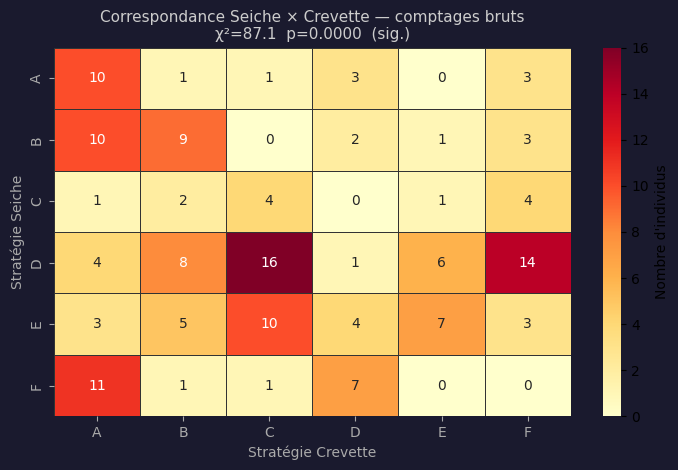

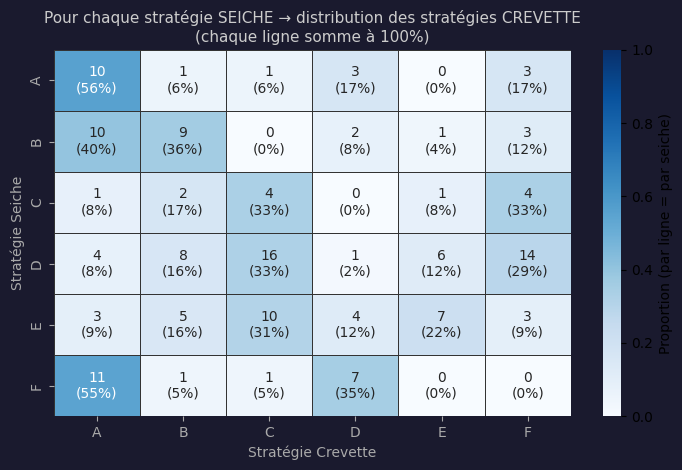

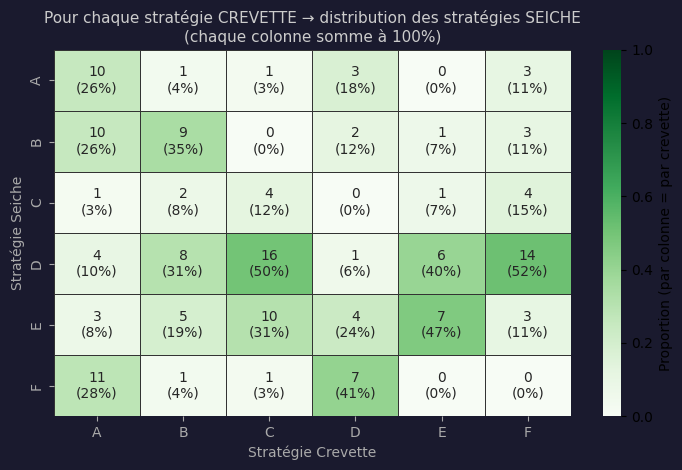

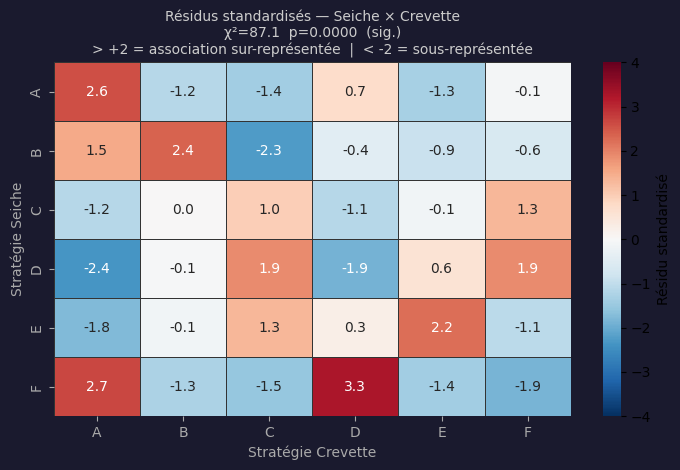


ASSOCIATIONS NOTABLES (résidu > +2 ou < -2)
  Seiche A × Crevette A : résidu=2.6  n=10  → SUR-représentée
  Seiche B × Crevette B : résidu=2.4  n=9  → SUR-représentée
  Seiche B × Crevette C : résidu=-2.3  n=0  → SOUS-représentée
  Seiche D × Crevette A : résidu=-2.4  n=4  → SOUS-représentée
  Seiche E × Crevette E : résidu=2.2  n=7  → SUR-représentée
  Seiche F × Crevette A : résidu=2.7  n=11  → SUR-représentée
  Seiche F × Crevette D : résidu=3.3  n=7  → SUR-représentée


In [47]:
# ══════════════════════════════════════════════════════════════
#  MATRICE DE CORRESPONDANCE — Stratégies Seiche × Crevette
# ══════════════════════════════════════════════════════════════

import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path
from scipy.stats import chi2_contingency

# ── Chemins vers les mappings sauvegardés ─────────────────────
PATH_CUTTLE  = Path(r"C:\Users\nonoh\Documents\01Travail\02_CREC\cuttle_strike\analysis_results\mapping_optimal_cuttle.json")
PATH_SHRIMP  = Path(r"C:\Users\nonoh\Documents\01Travail\02_CREC\cuttle_strike\analysis_results_shrimp\mapping_optimal_shrimp.json")

# ── Chargement ────────────────────────────────────────────────
map_cuttle = json.load(open(PATH_CUTTLE))   # {id: lettre seiche}
map_shrimp = json.load(open(PATH_SHRIMP))   # {id: lettre crevette}

# Normaliser les clés en string
map_cuttle = {str(k): v for k, v in map_cuttle.items()}
map_shrimp = {str(k): v for k, v in map_shrimp.items()}

# ── Individus communs ──────────────────────────────────────────
ids_communs = set(map_cuttle.keys()) & set(map_shrimp.keys())
print(f"[OK] {len(ids_communs)} individus communs")
print(f"     Seiche  : {len(map_cuttle)} individus | "
      f"groupes = {sorted(set(map_cuttle.values()))}")
print(f"     Crevette: {len(map_shrimp)} individus | "
      f"groupes = {sorted(set(map_shrimp.values()))}")

if len(ids_communs) == 0:
    raise ValueError("Aucun individu commun — vérifie que les animal_id sont identiques")

# ── DataFrame de correspondance ───────────────────────────────
df_match = pd.DataFrame([
    {"animal_id":      aid,
     "strat_cuttle":   map_cuttle[aid],
     "strat_shrimp":   map_shrimp[aid]}
    for aid in sorted(ids_communs)
])

# Exclure les MONO si besoin
df_match = df_match[
    (df_match["strat_cuttle"] != "MONO") &
    (df_match["strat_shrimp"] != "MONO")
]
print(f"[OK] {len(df_match)} individus (MONO exclus)")
print(df_match.head())

# ── Table de contingence : comptages ──────────────────────────
ct_count = pd.crosstab(
    df_match["strat_cuttle"],
    df_match["strat_shrimp"],
    margins=False)
ct_count.index.name   = "Stratégie Seiche"
ct_count.columns.name = "Stratégie Crevette"

# ── Normalisation ─────────────────────────────────────────────
# Par ligne = proportion de crevette pour chaque seiche
ct_row = ct_count.div(ct_count.sum(axis=1), axis=0).round(3)
# Par colonne = proportion de seiche pour chaque crevette
ct_col = ct_count.div(ct_count.sum(axis=0), axis=1).round(3)

# ── Test Chi² ─────────────────────────────────────────────────
chi2, p, dof, expected = chi2_contingency(ct_count)
print(f"\n[CHI²] χ²={chi2:.2f}  p={p:.4f}  ddl={dof}")
print(f"       {'*** association très significative' if p < 0.001 else '** significative' if p < 0.01 else '* significative' if p < 0.05 else 'n.s. — pas d association significative'}")

# Résidus standardisés
resid = (ct_count.values - expected) / np.sqrt(expected)
df_resid = pd.DataFrame(resid,
                         index=ct_count.index,
                         columns=ct_count.columns)

# ══════════════════════════════════════════════════════════════
# FIGURE 1 — Heatmap comptages bruts
# ══════════════════════════════════════════════════════════════
fig, ax = plt.subplots(
    figsize=(max(6, len(ct_count.columns)*1.2),
             max(4, len(ct_count)*0.8)))
fig.patch.set_facecolor("#1a1a2e")
sns.heatmap(ct_count, annot=True, fmt="d", cmap="YlOrRd",
            ax=ax, linewidths=0.5, linecolor="#333333",
            cbar_kws={"label": "Nombre d'individus"})
ax.set_title(f"Correspondance Seiche × Crevette — comptages bruts\n"
             f"χ²={chi2:.1f}  p={p:.4f}  "
             f"({'sig.' if p < 0.05 else 'n.s.'})",
             color="#cccccc", fontsize=11)
ax.set_xlabel("Stratégie Crevette", color="#aaaaaa")
ax.set_ylabel("Stratégie Seiche",   color="#aaaaaa")
ax.tick_params(colors="#aaaaaa")
plt.tight_layout(); plt.show()

# ══════════════════════════════════════════════════════════════
# FIGURE 2 — Heatmap proportion par seiche (ligne)
#            "Pour chaque stratégie seiche, quelle crevette ?"
# ══════════════════════════════════════════════════════════════
annot_row = ct_count.astype(str) + "\n(" + (ct_row*100).round(0).astype(int).astype(str) + "%)"

fig, ax = plt.subplots(
    figsize=(max(6, len(ct_count.columns)*1.2),
             max(4, len(ct_count)*0.8)))
fig.patch.set_facecolor("#1a1a2e")
sns.heatmap(ct_row, annot=annot_row, fmt="", cmap="Blues",
            ax=ax, linewidths=0.5, linecolor="#333333",
            vmin=0, vmax=1,
            cbar_kws={"label": "Proportion (par ligne = par seiche)"})
ax.set_title("Pour chaque stratégie SEICHE → distribution des stratégies CREVETTE\n"
             "(chaque ligne somme à 100%)",
             color="#cccccc", fontsize=11)
ax.set_xlabel("Stratégie Crevette", color="#aaaaaa")
ax.set_ylabel("Stratégie Seiche",   color="#aaaaaa")
ax.tick_params(colors="#aaaaaa")
plt.tight_layout(); plt.show()

# ══════════════════════════════════════════════════════════════
# FIGURE 3 — Heatmap proportion par crevette (colonne)
#            "Pour chaque stratégie crevette, quelle seiche ?"
# ══════════════════════════════════════════════════════════════
annot_col = ct_count.astype(str) + "\n(" + (ct_col*100).round(0).astype(int).astype(str) + "%)"

fig, ax = plt.subplots(
    figsize=(max(6, len(ct_count.columns)*1.2),
             max(4, len(ct_count)*0.8)))
fig.patch.set_facecolor("#1a1a2e")
sns.heatmap(ct_col, annot=annot_col, fmt="", cmap="Greens",
            ax=ax, linewidths=0.5, linecolor="#333333",
            vmin=0, vmax=1,
            cbar_kws={"label": "Proportion (par colonne = par crevette)"})
ax.set_title("Pour chaque stratégie CREVETTE → distribution des stratégies SEICHE\n"
             "(chaque colonne somme à 100%)",
             color="#cccccc", fontsize=11)
ax.set_xlabel("Stratégie Crevette", color="#aaaaaa")
ax.set_ylabel("Stratégie Seiche",   color="#aaaaaa")
ax.tick_params(colors="#aaaaaa")
plt.tight_layout(); plt.show()

# ══════════════════════════════════════════════════════════════
# FIGURE 4 — Résidus standardisés
#            Quelles associations sont sur/sous-représentées ?
# ══════════════════════════════════════════════════════════════
fig, ax = plt.subplots(
    figsize=(max(6, len(ct_count.columns)*1.2),
             max(4, len(ct_count)*0.8)))
fig.patch.set_facecolor("#1a1a2e")
sns.heatmap(df_resid, annot=True, fmt=".1f",
            cmap="RdBu_r", center=0, vmin=-4, vmax=4,
            ax=ax, linewidths=0.5, linecolor="#333333",
            cbar_kws={"label": "Résidu standardisé"})
ax.set_title(
    f"Résidus standardisés — Seiche × Crevette\n"
    f"χ²={chi2:.1f}  p={p:.4f}  "
    f"({'sig.' if p < 0.05 else 'n.s.'})\n"
    f"> +2 = association sur-représentée  |  < -2 = sous-représentée",
    color="#cccccc", fontsize=10)
ax.set_xlabel("Stratégie Crevette", color="#aaaaaa")
ax.set_ylabel("Stratégie Seiche",   color="#aaaaaa")
ax.tick_params(colors="#aaaaaa")
plt.tight_layout(); plt.show()

# ── Résumé texte ──────────────────────────────────────────────
print(f"\n{'='*55}")
print(f"ASSOCIATIONS NOTABLES (résidu > +2 ou < -2)")
print(f"{'='*55}")
for i in df_resid.index:
    for j in df_resid.columns:
        r = df_resid.loc[i, j]
        if abs(r) >= 2:
            n = ct_count.loc[i, j]
            direction = "SUR-représentée" if r > 0 else "SOUS-représentée"
            print(f"  Seiche {i} × Crevette {j} : "
                  f"résidu={r:.1f}  n={n}  → {direction}")

Interface plot indiv

In [48]:
# ══════════════════════════════════════════════════════════════
#  SIMULATEUR COMPORTEMENTAL — version notebook autonome
# ══════════════════════════════════════════════════════════════

%matplotlib tk

import io, math
import numpy as np
import pandas as pd
import tkinter as tk
from tkinter import ttk
from pathlib import Path
from collections import Counter
from itertools import groupby
from datetime import datetime

import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt
from matplotlib.figure import Figure
from matplotlib.colors import LinearSegmentedColormap
import matplotlib.patches as mpatches

try:
    from scipy.cluster.hierarchy import dendrogram as scipy_dendrogram, fcluster, linkage as sp_linkage
    from sklearn.preprocessing import StandardScaler
    HAS_SCIPY = True
except ImportError:
    HAS_SCIPY = False

try:
    from PIL import Image, ImageTk, ImageDraw
    HAS_PIL = True
except ImportError:
    HAS_PIL = False

# ── Constantes layout ─────────────────────────────────────────
BG         = "#0a0a1c"
BG2        = "#0d0d22"
SEQ_H      = 56
SEQ_CELL_W = 40
ARENA_W    = 480
ARENA_H    = 480
ARENA_R    = 210
DEFAULT_ARENA_REAL_RADIUS = 330


# ════════════════════════════════════════════════════════════════
#  HELPERS COULEURS
# ════════════════════════════════════════════════════════════════

def _hex_to_rgb01(h):
    h = h.lstrip("#")
    return tuple(int(h[i:i+2], 16)/255 for i in (0,2,4))

def _hex_to_rgb255(h):
    h = h.lstrip("#")
    return tuple(int(h[i:i+2], 16) for i in (0,2,4))

def _col_mpl(cid, pal):
    return _hex_to_rgb01(pal[cid % len(pal)])


# ════════════════════════════════════════════════════════════════
#  CHARGEMENT DONNÉES DEPUIS LE NOTEBOOK
# ════════════════════════════════════════════════════════════════

def _build_model_data(df, final_state, features, palette):
    """
    Construit le dict 'data' utilisé par le simulateur
    directement depuis les variables du notebook.

    df          : DataFrame avec colonnes 'cluster' + features
    final_state : résultat de show_strategy_explorer
    features    : liste de features (ex: FEATURES)
    palette     : liste de couleurs hex (ex: PALETTE)
    """
    K    = final_state["n_cl"]
    seqs = final_state["seqs"]

    df_w = df.copy()
    df_w["animal_id"] = df_w["animal_id"].astype(str)

    # ── Profils clusters : moyenne des features par cluster ───────────────
    cluster_profiles = np.zeros((K, len(features)))
    for c in range(K):
        mask = df_w["cluster"] == c
        if mask.any():
            cluster_profiles[c] = df_w.loc[mask, features].mean().values

    prof_min = cluster_profiles.min(axis=0)
    prof_max = cluster_profiles.max(axis=0)

    # ── Matrice de transition (K+2)×(K+2) depuis les séquences ───────────
    SIZE  = K + 2
    START = 0
    END   = K + 1
    trans_mat = np.zeros((SIZE, SIZE), dtype=float)

    n_built = 0
    for aid, info in seqs.items():
        seq = [int(c) for c in info["seq"] if 0 <= int(c) < K]
        if not seq:
            continue
        trans_mat[START, seq[0]+1] += 1
        for t in range(len(seq)-1):
            trans_mat[seq[t]+1, seq[t+1]+1] += 1
        trans_mat[seq[-1]+1, END] += 1
        n_built += 1

    print(f"[SIMU] Matrice depuis {n_built} séquences")

    # Normalisation
    for i in range(SIZE-1):
        s = trans_mat[i].sum()
        if s > 0:
            trans_mat[i] /= s

    p_start = trans_mat[START, 1:K+1]
    print(f"[SIMU] P(START) = {[f'C{c}:{p_start[c]:.2f}' for c in range(K)]}")

    return {
        "trans_mat":        trans_mat,
        "cluster_profiles": cluster_profiles,
        "prof_min":         prof_min,
        "prof_max":         prof_max,
        "K":                K,
        "START":            START,
        "END":              END,
        "features":         features,
        "palette":          palette[:K],
    }


def _build_dendro_data(final_state):
    """
    Construit les données du dendrogramme depuis final_state.
    Utilise Z (linkage) et seqs déjà calculés.
    """
    if not HAS_SCIPY:
        return None
    try:
        Z    = final_state.get("Z")
        seqs = final_state.get("seqs", {})
        n_cl = final_state.get("n_cl", 1)
        n_s  = final_state.get("n_s", 4)

        if Z is None:
            print("[SIMU] Z absent dans final_state")
            return None

        ids = list(seqs.keys())

        # Feature matrix simple : histogramme des clusters
        rows = []
        for aid in ids:
            sq = seqs[aid]["seq"]
            lg = seqs[aid]["lengths"]
            total = sum(lg)
            if total == 0:
                rows.append(np.zeros(n_cl)); continue
            hist = np.zeros(n_cl)
            for c, l in zip(sq, lg):
                if c < n_cl: hist[c] += l / total
            rows.append(hist)

        feature_matrix = pd.DataFrame(
            np.array(rows), index=ids,
            columns=[f"hist_C{c}" for c in range(n_cl)])

        scaler   = StandardScaler()
        X_scaled = scaler.fit_transform(feature_matrix.values.astype(float))

        h_min    = float(Z[:, 2].min()) * 0.5
        h_max    = float(Z[-1, 2])      * 1.05
        init_cut = float(Z[-1, 2])      * 0.5

        # Chercher la hauteur qui correspond à n_s groupes
        heights_desc = sorted(Z[:, 2], reverse=True)
        for k in range(2, 15):
            idx = k - 2
            if idx < len(heights_desc):
                h_above = heights_desc[idx]
                h_below = heights_desc[idx+1] if idx+1 < len(heights_desc) else 0.0
                h = (h_above + h_below) / 2.0
                try:
                    n = len(set(fcluster(Z, h, criterion="distance")))
                    if n == n_s:
                        init_cut = h
                        break
                except:
                    pass

        print(f"[SIMU] Dendro OK : {len(ids)} individus, init_cut={init_cut:.2f}")

        return {
            "Z_linkage":      Z,
            "feature_matrix": feature_matrix,
            "groupes":        final_state.get("strat", {}),
            "scaler":         scaler,
            "X_scaled":       X_scaled,
            "column_names":   list(feature_matrix.columns),
            "h_min":          h_min,
            "h_max":          h_max,
            "init_cut":       init_cut,
        }
    except Exception as e:
        import traceback
        print(f"[SIMU] Dendro : {e}")
        traceback.print_exc()
        return None


# ════════════════════════════════════════════════════════════════
#  MOTEUR DE SIMULATION
# ════════════════════════════════════════════════════════════════

def simulate_sequence(data, mode="random", start_cluster=None,
                      max_steps=100, allow_end=True, seed=None):
    rng   = np.random.default_rng(seed)
    mat   = data["trans_mat"]
    K     = data["K"]
    START = data["START"]
    END   = data["END"]

    if mode == "random" or start_cluster is None:
        probs = mat[START, 1:K+1].copy()
        s     = probs.sum()
        probs = probs / s if s > 0 else np.ones(K)/K
        current = int(rng.choice(K, p=probs))
    else:
        current = int(start_cluster)

    sequence = [current]
    for _ in range(max_steps - 1):
        row = mat[current+1].copy()
        if not allow_end:
            row[END] = 0.0
        s = row.sum()
        if s <= 0: break
        row /= s
        nxt = int(rng.choice(len(row), p=row))
        if nxt == END: break
        current = nxt - 1
        sequence.append(current)

    return sequence


def detect_cluster_from_position(cx, cy, cangle, px, py, data,
                                  prey_angle=0,
                                  arena_real_radius=DEFAULT_ARENA_REAL_RADIUS):
    dx = px - cx
    dy = py - cy
    dist_display  = math.sqrt(dx**2 + dy**2)
    scale         = arena_real_radius / ARENA_R
    distance_real = dist_display * scale

    dir_to_prey_rad = math.atan2(-dy, dx)
    diff_axes       = (cangle - prey_angle + 180) % 360 - 180
    approach_angle  = abs(diff_axes)

    features   = np.array([distance_real, approach_angle, 0., 0., 0.])
    profiles   = data["cluster_profiles"]
    pmin, pmax = data["prof_min"], data["prof_max"]

    if profiles is None:
        return 0, {}

    feat_norm  = np.clip((features - pmin) / (pmax - pmin + 1e-9), 0, 1)
    prof_norm  = np.clip((profiles  - pmin) / (pmax - pmin + 1e-9), 0, 1)
    dists      = np.linalg.norm(prof_norm - feat_norm, axis=1)
    best       = int(np.argmin(dists))

    return best, {
        "distance_real":  round(distance_real, 1),
        "approach_angle": round(approach_angle, 1),
        "cluster_detected": best,
        "dists":          dists.round(3).tolist(),
    }


# ════════════════════════════════════════════════════════════════
#  RENDUS PIL
# ════════════════════════════════════════════════════════════════

def _render_seq_bar(sequence, palette, current_idx=None):
    n   = len(sequence)
    w   = max(n * SEQ_CELL_W, 100)
    img = Image.new("RGB", (w, SEQ_H), (6, 6, 20))
    drw = ImageDraw.Draw(img)
    for i, lab in enumerate(sequence):
        x0 = i * SEQ_CELL_W + 2
        x1 = (i+1) * SEQ_CELL_W - 2
        r, g, b = _hex_to_rgb255(palette[lab % len(palette)])
        outline = (255,255,255) if i == current_idx else (34,51,68)
        lw = 3 if i == current_idx else 1
        drw.rectangle([x0,4,x1,SEQ_H-4], fill=(r,g,b), outline=outline, width=lw)
        drw.text((x0+(x1-x0)//2-3, SEQ_H//2-6), str(lab), fill=(255,255,255))
    return img


def _render_radar(vals_norm, feature_names, color, title, size_in=2.8, dpi=90):
    SHORT = {"distance_to_shrimp":"dist","approach_angle":"angle",
             "orientation_variation":"orient.","speed_cuttle_smooth":"speed",
             "jerk_cuttle":"jerk","accel_cuttle":"accel"}
    fig = Figure(figsize=(size_in, size_in), facecolor=BG)
    ax  = fig.add_subplot(111, polar=True, facecolor="#0a0a1c")
    n   = len(feature_names)
    ang = np.linspace(0, 2*np.pi, n, endpoint=False).tolist()
    ang += ang[:1]
    vals = list(vals_norm) + [vals_norm[0]]
    ax.plot(ang, vals, lw=2, color=color, zorder=3)
    ax.fill(ang, vals, alpha=0.25, color=color, zorder=2)
    ax.set_xticks(ang[:-1])
    ax.set_xticklabels([SHORT.get(f,f) for f in feature_names],
                       fontsize=5.5, color="#cccccc")
    ax.set_yticks([0.25, 0.5, 0.75]); ax.set_yticklabels(["","",""])
    ax.set_ylim(0, 1)
    ax.set_title(title, fontsize=7, pad=4, color="#dddddd", fontweight="bold")
    ax.spines["polar"].set_color("#334466")
    ax.grid(color="#334466", linewidth=0.5)
    fig.tight_layout(pad=0.2)
    buf = io.BytesIO()
    fig.savefig(buf, format="png", dpi=dpi, facecolor=BG)
    buf.seek(0)
    img = Image.open(buf).copy()
    plt.close(fig); buf.close()
    return img


def _render_cluster_grid(data, active_cluster=None, ncols=4, dpi=80):
    K       = data["K"]
    feats   = data["features"]
    palette = data["palette"]
    profs   = data["cluster_profiles"]
    pmin    = data["prof_min"]
    pmax    = data["prof_max"]

    nrows = math.ceil(K / ncols)
    fig   = Figure(figsize=(ncols*1.1, nrows*1.1+0.2), facecolor=BG)
    fig.text(0.5, 0.98, "Clusters", ha="center", va="top",
             fontsize=6, color="#aaaacc", fontweight="bold")
    SHORT = {"distance_to_shrimp":"dist","approach_angle":"angle",
             "orientation_variation":"orient.","speed_cuttle_smooth":"speed",
             "jerk_cuttle":"jerk","accel_cuttle":"accel"}
    n   = len(feats)
    ang = np.linspace(0, 2*np.pi, n, endpoint=False).tolist() + [0]

    for c in range(K):
        row, col = divmod(c, ncols)
        ax = fig.add_axes([
            col/ncols+0.01, (nrows-row-1)/nrows*0.93+0.01,
            1/ncols-0.02,   1/nrows*0.93-0.04], polar=True)
        is_active = (active_cluster is not None and c == active_cluster)
        ax.set_facecolor("#1a1a3a" if is_active else "#0a0a1c")
        color = _col_mpl(c, palette)
        v = (np.clip((profs[c]-pmin)/(pmax-pmin+1e-9),0,1)
             if profs is not None else np.full(n, 0.5))
        vals = list(v)+[v[0]]
        ax.plot(ang, vals, lw=2.0 if is_active else 1.4, color=color, zorder=3)
        ax.fill(ang, vals, alpha=0.30 if is_active else 0.20, color=color, zorder=2)
        ax.set_xticks(ang[:-1])
        ax.set_xticklabels([SHORT.get(f,f) for f in feats], fontsize=3.5, color="#aaaacc")
        ax.set_yticks([]); ax.set_ylim(0,1)
        ax.spines["polar"].set_color("#ffffff" if is_active else "#334466")
        ax.spines["polar"].set_linewidth(1.6 if is_active else 0.7)
        ax.grid(color="#334466", linewidth=0.4)
        ax.set_title(f"C{c}", fontsize=5.5, pad=2,
                     color="#ffffff" if is_active else "#cccccc",
                     fontweight="bold")

    buf = io.BytesIO()
    fig.savefig(buf, format="png", dpi=dpi, facecolor=BG, bbox_inches="tight")
    buf.seek(0)
    img = Image.open(buf).copy()
    plt.close(fig); buf.close()
    return img


def _render_transition_matrix(data, dpi=90):
    mat    = data["trans_mat"]
    K      = data["K"]
    pal    = data["palette"]
    SIZE   = K + 2
    START  = data["START"]
    END    = data["END"]
    labels = ["START"] + [f"C{c}" for c in range(K)] + ["END"]

    cmap  = LinearSegmentedColormap.from_list(
        "trans", ["#0a0a2e","#1a3a6e","#2266aa","#55aadd",
                  "#ffffff","#ffcc88","#ff8844","#cc3311"], N=256)
    fig_s = max(5, SIZE*0.75)
    fig   = Figure(figsize=(fig_s+1.2, fig_s), facecolor=BG)
    ax    = fig.add_subplot(111, facecolor=BG2)
    im    = ax.imshow(mat, cmap=cmap, vmin=0, vmax=1, aspect="auto")

    for j in range(SIZE):
        ax.add_patch(plt.Rectangle((j-.5,START-.5),1,1,fill=True,
                                    color="#00aa44",alpha=0.12,zorder=0))
    for i in range(SIZE):
        ax.add_patch(plt.Rectangle((END-.5,i-.5),1,1,fill=True,
                                    color="#cc2222",alpha=0.12,zorder=0))
    for k in range(1,K+1):
        ax.add_patch(plt.Rectangle((k-.5,k-.5),1,1,fill=False,
                                    edgecolor="white",linewidth=1.5,
                                    linestyle="--",zorder=3))
    ax.axhline(0.5, color="#44ff88",lw=1.3,alpha=0.7)
    ax.axvline(K+0.5,color="#ff6644",lw=1.3,alpha=0.7)
    for i in range(SIZE):
        for j in range(SIZE):
            v = mat[i,j]
            if v < 0.005: continue
            ax.text(j,i,f"{v:.2f}",ha="center",va="center",
                    fontsize=7,color="black" if v>0.55 else "white",
                    fontweight="bold",zorder=4)
    ax.set_xticks(range(SIZE)); ax.set_yticks(range(SIZE))
    ax.set_xticklabels(labels,fontsize=8,rotation=45,ha="right")
    ax.set_yticklabels(labels,fontsize=8)
    for k in range(K):
        ax.get_xticklabels()[k+1].set_color(pal[k%len(pal)])
        ax.get_yticklabels()[k+1].set_color(pal[k%len(pal)])
    ax.get_xticklabels()[0].set_color("#44ff88")
    ax.get_yticklabels()[0].set_color("#44ff88")
    ax.get_xticklabels()[-1].set_color("#ff6644")
    ax.get_yticklabels()[-1].set_color("#ff6644")
    ax.set_xlabel("Vers →",fontsize=9,color="#aaaacc",labelpad=6)
    ax.set_ylabel("Depuis ↓",fontsize=9,color="#aaaacc",labelpad=6)
    ax.set_title("Matrice de transition enrichie",fontsize=8,color="#dddddd",pad=8)
    ax.tick_params(colors="#aaaacc")
    for sp in ax.spines.values(): sp.set_edgecolor("#334466")
    fig.colorbar(im,ax=ax,fraction=0.028,pad=0.02
                 ).ax.yaxis.set_tick_params(color="#aaaacc",labelcolor="#aaaacc")
    fig.tight_layout(pad=0.8)
    buf = io.BytesIO()
    fig.savefig(buf,format="png",dpi=dpi,facecolor=BG,bbox_inches="tight")
    buf.seek(0)
    img = Image.open(buf).copy()
    plt.close(fig); buf.close()
    return img


def _render_arena(cx, cy, cangle, px, py, sequence, current_idx, palette,
                  prey_angle=0):
    img = Image.new("RGB", (ARENA_W, ARENA_H), (15,15,35))
    drw = ImageDraw.Draw(img)
    acx, acy = ARENA_W//2, ARENA_H//2
    drw.ellipse([acx-ARENA_R,acy-ARENA_R,acx+ARENA_R,acy+ARENA_R],
                fill=(28,28,48),outline=(80,80,120),width=3)
    for r in [ARENA_R//3, 2*ARENA_R//3]:
        drw.ellipse([acx-r,acy-r,acx+r,acy+r],outline=(40,40,70),width=1)
    drw.line([(acx-ARENA_R,acy),(acx+ARENA_R,acy)],fill=(40,40,70),width=1)
    drw.line([(acx,acy-ARENA_R),(acx,acy+ARENA_R)],fill=(40,40,70),width=1)

    if px is not None:
        ipx, ipy = int(px), int(py)
        drw.ellipse([ipx-7,ipy-7,ipx+7,ipy+7],
                    fill=(255,180,50),outline=(255,255,255),width=1)
        prad = math.radians(prey_angle)
        epx  = int(ipx+18*math.cos(prad))
        epy  = int(ipy-18*math.sin(prad))
        drw.line([(ipx,ipy),(epx,epy)],fill=(255,210,80),width=2)
        drw.text((ipx+10,ipy-6),"proie",fill=(255,210,80))

    if cx is not None:
        isx, isy = int(cx), int(cy)
        lab = (sequence[current_idx]
               if sequence and current_idx is not None
               and current_idx < len(sequence) else -1)
        col = (_hex_to_rgb255(palette[lab%len(palette)]) if lab>=0
               else (100,200,255))
        drw.ellipse([isx-11,isy-11,isx+11,isy+11],
                    fill=col,outline=(255,255,255),width=2)
        crad = math.radians(cangle)
        ecx  = int(isx+28*math.cos(crad))
        ecy  = int(isy-28*math.sin(crad))
        drw.line([(isx,isy),(ecx,ecy)],fill=(255,255,255),width=3)
        drw.text((isx+13,isy-17),"seiche",fill=(200,220,255))

    if cx is not None and px is not None:
        isx,isy = int(cx),int(cy)
        ipx,ipy = int(px),int(py)
        drw.line([(isx,isy),(ipx,ipy)],fill=(200,200,100),width=1)
        crad = math.radians(cangle)
        prad = math.radians(prey_angle)
        arc_len = 44
        diff_signed = (cangle - prey_angle + 180) % 360 - 180
        ap_display  = abs(diff_signed)
        ax1 = int(isx+arc_len*math.cos(crad))
        ay1 = int(isy-arc_len*math.sin(crad))
        drw.line([(isx,isy),(ax1,ay1)],fill=(120,210,120),width=1)
        ax2 = int(isx+arc_len*math.cos(prad))
        ay2 = int(isy-arc_len*math.sin(prad))
        drw.line([(isx,isy),(ax2,ay2)],fill=(255,190,60),width=1)
        mid_rad = crad + math.radians(-diff_signed/2)
        lx = int(isx+(arc_len+14)*math.cos(mid_rad))
        ly = int(isy-(arc_len+14)*math.sin(mid_rad))
        drw.text((lx-12,ly-6),f"{ap_display:.0f}°",fill=(150,230,150))
    return img


def _render_stats(sequence, data):
    if not sequence:
        return Image.new("RGB", (420, 220), (10,10,28))
    K = data["K"]; pal = data["palette"]
    counts = np.zeros(K, dtype=int)
    for c in sequence:
        if 0 <= c < K: counts[c] += 1
    total = max(counts.sum(), 1)
    props = counts / total
    p     = props[props > 0]
    ent   = float(-np.sum(p * np.log2(p)))
    comp  = [sequence[0]]
    for v in sequence[1:]:
        if v != comp[-1]: comp.append(v)
    fig = Figure(figsize=(4.4, 2.8), facecolor=BG)
    ax  = fig.add_subplot(111, facecolor="#0a0a1c")
    ax.bar(range(K), props,
           color=[_col_mpl(c,pal) for c in range(K)],
           edgecolor="white",linewidth=0.5)
    for c, pv in enumerate(props):
        if pv > 0.01:
            ax.text(c, pv+0.01, f"{pv:.0%}",
                    ha="center",fontsize=7,color="white")
    ax.set_xticks(range(K))
    ax.set_xticklabels([f"C{c}" for c in range(K)],color="#cccccc",fontsize=8)
    ax.set_ylabel("Proportion",color="#cccccc",fontsize=8)
    ax.set_ylim(0, max(props.max()*1.3, 0.1))
    ax.tick_params(colors="#cccccc")
    ax.set_title(f"{len(sequence)} fen.  ·  {len(comp)} blocs  ·  H={ent:.2f}b",
                 fontsize=7,color="#dddddd",pad=4)
    for sp in ax.spines.values(): sp.set_edgecolor("#334466")
    ax.grid(axis="y",alpha=0.2,color="#334466")
    fig.tight_layout(pad=0.4)
    buf = io.BytesIO()
    fig.savefig(buf,format="png",dpi=90,facecolor=BG)
    buf.seek(0)
    img = Image.open(buf).copy()
    plt.close(fig); buf.close()
    return img


# ════════════════════════════════════════════════════════════════
#  APPLICATION TKINTER
# ════════════════════════════════════════════════════════════════

class SimulatorApp:

    def __init__(self, root, data, dendro_data, out_dir):
        self.root        = root
        self.data        = data
        self.dendro_data = dendro_data
        self.out_dir     = Path(out_dir)

        self.sequence      = []
        self.all_sequences = []
        self.current_idx   = 0

        self.cuttle_x     = ARENA_W//2 - 70
        self.cuttle_y     = ARENA_H//2
        self.cuttle_angle = 0
        self.prey_x       = ARENA_W//2 + 90
        self.prey_y       = ARENA_H//2
        self.prey_angle   = 180
        self.dragging     = None

        self._cluster_grid_imgs = {}
        self._trans_matrix_img  = None
        self._dendro_after_id   = None

        self._build_ui()
        self._init_data()

    # ── Init ─────────────────────────────────────────────────────────────────

    def _init_data(self):
        K = self.data["K"]
        self.start_spin.configure(to=K-1)

        self._set_status("Pré-calcul grille clusters...")
        self.root.update_idletasks()
        for active in [None] + list(range(K)):
            self._cluster_grid_imgs[active] = _render_cluster_grid(
                self.data, active_cluster=active)

        self._set_status("Pré-calcul matrice...")
        self.root.update_idletasks()
        self._trans_matrix_img = _render_transition_matrix(self.data)

        self._refresh_cluster_grid(None)
        self._refresh_matrix()

        # Dendrogramme
        if self.dendro_data:
            Z      = self.dendro_data["Z_linkage"]
            h_min  = self.dendro_data["h_min"]
            h_max  = self.dendro_data["h_max"]
            init_h = self.dendro_data["init_cut"]
            self.dendro_slider.configure(
                from_=h_min, to=h_max,
                resolution=round((h_max-h_min)/500, 4))
            self.dendro_cut_var.set(init_h)
            n_init = len(set(fcluster(Z, init_h, criterion="distance")))
            self.dendro_cut_lbl.configure(text=f"h={init_h:.2f}")
            self.dendro_nstrat_lbl.configure(text=f"→ {n_init} strats")

        self._set_status(
            f"Prêt — {K} clusters  ·  "
            f"P(START)={self.data['trans_mat'][0,1:K+1].round(2).tolist()}")
        self._redraw_arena()

    # ── UI ───────────────────────────────────────────────────────────────────

    def _build_ui(self):
        self.root.title("Simulateur comportemental — Notebook")
        self.root.configure(bg=BG)
        self.root.resizable(True, True)

        tk.Label(self.root, text="Simulateur comportemental",
                 font=("Helvetica",14,"bold"), fg="#f0c040", bg=BG
                 ).pack(side="top", pady=(8,2))

        main = tk.Frame(self.root, bg=BG)
        main.pack(side="top", fill="both", expand=True, padx=8, pady=4)

        left = tk.Frame(main, bg=BG)
        left.pack(side="left", fill="y")
        self._build_params(left)
        self._build_arena_panel(left)

        right = tk.Frame(main, bg=BG)
        right.pack(side="left", fill="both", expand=True, padx=(10,0))
        self._build_tabs(right)

        self.status_lbl = tk.Label(
            self.root, text="Chargement...",
            font=("Helvetica",8), fg="#888899", bg=BG, anchor="w")
        self.status_lbl.pack(side="bottom", fill="x", padx=8, pady=2)

    def _build_params(self, parent):
        pf = tk.LabelFrame(parent, text="Paramètres",
                            bg=BG, fg="#9999bb", font=("Helvetica",9,"bold"))
        pf.pack(side="top", fill="x", pady=(0,6))

        mf = tk.Frame(pf, bg=BG)
        mf.pack(fill="x", padx=6, pady=4)
        tk.Label(mf, text="Mode :", font=("Helvetica",9),
                 fg="#cccccc", bg=BG).pack(side="left")
        self.mode_var = tk.StringVar(value="random")
        for val, txt in [("random","Aléatoire"),
                          ("fixed_start","Cluster fixe"),
                          ("positional","Positionnel")]:
            tk.Radiobutton(mf, text=txt, variable=self.mode_var, value=val,
                           font=("Helvetica",9), fg="#cccccc", bg=BG,
                           selectcolor="#1a1a40", activebackground=BG,
                           activeforeground="#cccccc",
                           command=self._on_mode_change
                           ).pack(side="left", padx=3)

        sf = tk.Frame(pf, bg=BG)
        sf.pack(fill="x", padx=6, pady=2)
        tk.Label(sf, text="Cluster départ :", font=("Helvetica",9),
                 fg="#cccccc", bg=BG).pack(side="left")
        self.start_cluster_var = tk.IntVar(value=0)
        self.start_spin = tk.Spinbox(
            sf, from_=0, to=20, textvariable=self.start_cluster_var,
            width=4, bg="#1a1a40", fg="#e0e0e0",
            insertbackground="white", state="disabled")
        self.start_spin.pack(side="left", padx=4)

        df = tk.Frame(pf, bg=BG)
        df.pack(fill="x", padx=6, pady=2)
        self.fixed_len_var = tk.BooleanVar(value=True)
        tk.Checkbutton(df, text="Durée fixe :",
                       variable=self.fixed_len_var,
                       font=("Helvetica",9), fg="#cccccc", bg=BG,
                       selectcolor="#1a1a40", activebackground=BG,
                       activeforeground="#cccccc"
                       ).pack(side="left")
        self.n_steps_var = tk.IntVar(value=30)
        tk.Spinbox(df, from_=1, to=500, textvariable=self.n_steps_var,
                   width=5, bg="#1a1a40", fg="#e0e0e0",
                   insertbackground="white").pack(side="left", padx=4)
        tk.Label(df, text="fenêtres", font=("Helvetica",8),
                 fg="#667788", bg=BG).pack(side="left")

        nf = tk.Frame(pf, bg=BG)
        nf.pack(fill="x", padx=6, pady=2)
        tk.Label(nf, text="Nb simulations :", font=("Helvetica",9),
                 fg="#cccccc", bg=BG).pack(side="left")
        self.n_simu_var = tk.IntVar(value=1)
        tk.Spinbox(nf, from_=1, to=200, textvariable=self.n_simu_var,
                   width=5, bg="#1a1a40", fg="#e0e0e0",
                   insertbackground="white").pack(side="left", padx=4)

        seedf = tk.Frame(pf, bg=BG)
        seedf.pack(fill="x", padx=6, pady=2)
        self.use_seed_var = tk.BooleanVar(value=False)
        tk.Checkbutton(seedf, text="Seed :",
                       variable=self.use_seed_var,
                       font=("Helvetica",9), fg="#cccccc", bg=BG,
                       selectcolor="#1a1a40", activebackground=BG,
                       activeforeground="#cccccc").pack(side="left")
        self.seed_var = tk.IntVar(value=42)
        tk.Spinbox(seedf, from_=0, to=9999, textvariable=self.seed_var,
                   width=6, bg="#1a1a40", fg="#e0e0e0",
                   insertbackground="white").pack(side="left", padx=4)

        bf = tk.Frame(pf, bg=BG)
        bf.pack(fill="x", padx=6, pady=6)
        bk = dict(font=("Helvetica",10,"bold"), bg="#1e1e5a",
                  fg="#e0e0e0", relief="flat",
                  activebackground="#3333aa", activeforeground="white",
                  padx=10, pady=5)
        tk.Button(bf, text="Simuler",  command=self._run, **bk
                  ).pack(side="left", padx=4)
        tk.Button(bf, text="Reset",    command=self._reset,
                  **{**bk,"bg":"#2a2a2a"}).pack(side="left", padx=4)
        tk.Button(bf, text="Sauver",   command=self._save,
                  **{**bk,"bg":"#1a3a1a"}).pack(side="left", padx=4)

    def _build_arena_panel(self, parent):
        af = tk.LabelFrame(parent, text="Arène (clic=déplacer, clic droit=orienter)",
                            bg=BG, fg="#9999bb", font=("Helvetica",8,"bold"))
        af.pack(side="top", fill="x", pady=(0,6))

        self.arena_canvas = tk.Canvas(
            af, width=ARENA_W, height=ARENA_H,
            bg="#0a0a1c", highlightthickness=1,
            highlightbackground="#223366")
        self.arena_canvas.pack(padx=6, pady=4)
        self.arena_canvas.bind("<Button-1>",       self._arena_click)
        self.arena_canvas.bind("<B1-Motion>",       self._arena_drag)
        self.arena_canvas.bind("<ButtonRelease-1>", self._arena_release)
        self.arena_canvas.bind("<Button-3>",        self._arena_right_click)

        af2 = tk.Frame(af, bg=BG); af2.pack(fill="x", padx=6, pady=(0,1))
        tk.Label(af2, text="Seiche (°) :",
                 font=("Helvetica",8), fg="#cccccc", bg=BG).pack(side="left")
        self.angle_var = tk.IntVar(value=0)
        tk.Spinbox(af2, from_=0, to=359, textvariable=self.angle_var,
                   width=5, bg="#1a1a40", fg="#e0e0e0",
                   insertbackground="white",
                   command=self._redraw_arena).pack(side="left", padx=4)

        af3 = tk.Frame(af, bg=BG); af3.pack(fill="x", padx=6, pady=(0,2))
        tk.Label(af3, text="Proie   (°) :",
                 font=("Helvetica",8), fg="#e0c060", bg=BG).pack(side="left")
        self.prey_angle_var = tk.IntVar(value=180)
        tk.Spinbox(af3, from_=0, to=359, textvariable=self.prey_angle_var,
                   width=5, bg="#2a1a00", fg="#ffe080",
                   insertbackground="white",
                   command=self._redraw_arena).pack(side="left", padx=4)

        self.detected_lbl = tk.Label(
            af, text="Cluster détecté : —",
            font=("Helvetica",9,"bold"), fg="#f0c040", bg=BG)
        self.detected_lbl.pack(pady=(0,4))
        self._redraw_arena()

    def _build_tabs(self, parent):
        style = ttk.Style()
        style.theme_use("default")
        style.configure("Dark.TNotebook", background=BG, borderwidth=0)
        style.configure("Dark.TNotebook.Tab",
                        background="#1a1a40", foreground="#cccccc",
                        padding=[10,4], font=("Helvetica",9))
        style.map("Dark.TNotebook.Tab",
                  background=[("selected","#334488")],
                  foreground=[("selected","#ffffff")])

        nb = ttk.Notebook(parent, style="Dark.TNotebook")
        nb.pack(fill="both", expand=True)
        self.notebook = nb

        # Onglet Simulation
        t1 = tk.Frame(nb, bg=BG); nb.add(t1, text="  Simulation  ")
        self._build_simu_tab(t1)

        # Onglet Clusters
        t2 = tk.Frame(nb, bg=BG); nb.add(t2, text="  Clusters  ")
        tk.Label(t2, text="Profils des clusters (actif surligné)",
                 font=("Helvetica",8), fg="#9999bb", bg=BG).pack(pady=(6,2))
        self.lbl_cluster_grid = tk.Label(t2, bg=BG)
        self.lbl_cluster_grid.pack(pady=4)

        # Onglet Matrice
        t3 = tk.Frame(nb, bg=BG); nb.add(t3, text="  Matrice  ")
        tk.Label(t3, text="Matrice de transition enrichie",
                 font=("Helvetica",8), fg="#9999bb", bg=BG).pack(pady=(6,2))
        self.lbl_trans_matrix = tk.Label(t3, bg=BG)
        self.lbl_trans_matrix.pack(pady=4)

        # Onglet Dendrogramme
        t4 = tk.Frame(nb, bg=BG); nb.add(t4, text="  Dendrogramme  ")
        self._build_dendro_tab(t4)

    def _build_simu_tab(self, parent):
        tk.Label(parent, text="Séquence simulée",
                 font=("Helvetica",9,"bold"), fg="#9999bb", bg=BG
                 ).pack(anchor="w", padx=4)
        seqf = tk.Frame(parent, bg=BG)
        seqf.pack(fill="x", pady=(2,6), padx=4)
        self.seq_canvas = tk.Canvas(
            seqf, height=SEQ_H, width=480,
            bg="#060614", highlightthickness=1, highlightbackground="#223366")
        self.seq_canvas.pack(side="top", fill="x", expand=True)
        hsb = ttk.Scrollbar(seqf, orient="horizontal",
                            command=self.seq_canvas.xview)
        hsb.pack(side="bottom", fill="x")
        self.seq_canvas.configure(xscrollcommand=hsb.set)
        self.seq_canvas.bind("<Button-1>", self._on_seq_click)

        rf = tk.Frame(parent, bg=BG)
        rf.pack(fill="x", pady=(0,2), padx=4)
        tk.Label(rf, text="Départ :", font=("Helvetica",7),
                 fg="#888888", bg=BG).pack(side="left")
        self.lbl_rs = tk.Label(rf, bg=BG); self.lbl_rs.pack(side="left",padx=2)
        tk.Label(rf, text="  Fin :", font=("Helvetica",7),
                 fg="#888888", bg=BG).pack(side="left")
        self.lbl_re = tk.Label(rf, bg=BG); self.lbl_re.pack(side="left",padx=2)

        self.lbl_rc    = tk.Label(parent, bg=BG); self.lbl_rc.pack(pady=(0,4))
        self.lbl_stats = tk.Label(parent, bg=BG); self.lbl_stats.pack(pady=(0,4))

        tk.Label(parent, text="Simulations (clic = afficher)",
                 font=("Helvetica",8,"bold"), fg="#9999bb", bg=BG
                 ).pack(anchor="w", padx=4)
        listf = tk.Frame(parent, bg=BG)
        listf.pack(fill="both", expand=True, padx=4)
        self.seq_listbox = tk.Listbox(
            listf, bg="#060614", fg="#e0e0e0",
            selectbackground="#2233aa", font=("Courier",8), height=6)
        self.seq_listbox.pack(side="left", fill="both", expand=True)
        vsb = ttk.Scrollbar(listf, orient="vertical",
                            command=self.seq_listbox.yview)
        vsb.pack(side="right", fill="y")
        self.seq_listbox.configure(yscrollcommand=vsb.set)
        self.seq_listbox.bind("<<ListboxSelect>>", self._on_list_select)

    def _build_dendro_tab(self, parent):
        self.dendro_strategy_lbl = tk.Label(
            parent, text="— simuler d'abord —",
            font=("Helvetica",10,"bold"), fg="#f0c040", bg=BG)
        self.dendro_strategy_lbl.pack(pady=(6,2))

        ctrl = tk.Frame(parent, bg=BG)
        ctrl.pack(fill="x", padx=10, pady=(0,4))
        tk.Label(ctrl, text="Hauteur de coupure :",
                 font=("Helvetica",9), fg="#cccccc", bg=BG).pack(side="left")

        self.dendro_cut_var = tk.DoubleVar(value=0.0)
        self.dendro_slider  = tk.Scale(
            ctrl, variable=self.dendro_cut_var,
            from_=0.0, to=1.0, resolution=0.001,
            orient="horizontal", length=340,
            bg=BG, fg="#e0e0e0", troughcolor="#1a1a40",
            activebackground="#3333aa", highlightthickness=0,
            showvalue=False,
            command=self._on_dendro_slider_move)
        self.dendro_slider.pack(side="left", padx=6)

        self.dendro_cut_lbl = tk.Label(
            ctrl, text="h=—", width=10,
            font=("Helvetica",9,"bold"), fg="#ff7777", bg=BG)
        self.dendro_cut_lbl.pack(side="left")
        self.dendro_nstrat_lbl = tk.Label(
            ctrl, text="", font=("Helvetica",9), fg="#aaaacc", bg=BG)
        self.dendro_nstrat_lbl.pack(side="left", padx=(4,0))

        self.lbl_dendro = tk.Label(parent, bg=BG)
        self.lbl_dendro.pack(pady=2, fill="both", expand=True)

    # ── Callbacks ────────────────────────────────────────────────────────────

    def _on_mode_change(self):
        mode = self.mode_var.get()
        self.start_spin.configure(
            state="normal" if mode == "fixed_start" else "disabled")

    def _redraw_arena(self):
        if not HAS_PIL: return
        self.cuttle_angle = self.angle_var.get()
        self.prey_angle   = self.prey_angle_var.get()
        img = _render_arena(
            self.cuttle_x, self.cuttle_y, self.cuttle_angle,
            self.prey_x,   self.prey_y,
            self.sequence if self.sequence else None,
            self.current_idx if self.sequence else None,
            self.data["palette"],
            prey_angle=self.prey_angle)
        self._arena_tk = ImageTk.PhotoImage(image=img)
        self.arena_canvas.delete("all")
        self.arena_canvas.create_image(0,0,anchor="nw",image=self._arena_tk)
        if self.mode_var.get() == "positional":
            self._update_detected()

    def _arena_click(self, event):
        ds = math.hypot(event.x-self.cuttle_x, event.y-self.cuttle_y)
        dp = math.hypot(event.x-self.prey_x,   event.y-self.prey_y)
        self.dragging = "cuttle" if ds < 20 else ("prey" if dp < 18 else None)

    def _arena_drag(self, event):
        if self.dragging == "cuttle":
            self.cuttle_x = max(0, min(ARENA_W, event.x))
            self.cuttle_y = max(0, min(ARENA_H, event.y))
            self._redraw_arena()
        elif self.dragging == "prey":
            self.prey_x = max(0, min(ARENA_W, event.x))
            self.prey_y = max(0, min(ARENA_H, event.y))
            self._redraw_arena()

    def _arena_release(self, event): self.dragging = None

    def _arena_right_click(self, event):
        ds = math.hypot(event.x-self.cuttle_x, event.y-self.cuttle_y)
        dp = math.hypot(event.x-self.prey_x,   event.y-self.prey_y)
        if dp < ds:
            dx = event.x-self.prey_x; dy = self.prey_y-event.y
            self.prey_angle_var.set(int(math.degrees(math.atan2(dy,dx))%360))
        else:
            dx = event.x-self.cuttle_x; dy = self.cuttle_y-event.y
            self.angle_var.set(int(math.degrees(math.atan2(dy,dx))%360))
        self._redraw_arena()

    def _update_detected(self):
        cl, fd = detect_cluster_from_position(
            self.cuttle_x, self.cuttle_y, self.angle_var.get(),
            self.prey_x,   self.prey_y,   self.data,
            prey_angle=self.prey_angle_var.get())
        pal = self.data["palette"]
        self.detected_lbl.configure(
            text=f"Cluster détecté : {cl}  ·  "
                 f"dist={fd.get('distance_real','?')}px  ·  "
                 f"approche={fd.get('approach_angle','?')}°",
            fg=pal[cl % len(pal)])
        self._refresh_cluster_grid(cl)

    def _refresh_cluster_grid(self, active):
        if not self._cluster_grid_imgs: return
        img = self._cluster_grid_imgs.get(active,
                                           self._cluster_grid_imgs.get(None))
        if img:
            self._tk_grid = ImageTk.PhotoImage(image=img)
            self.lbl_cluster_grid.configure(image=self._tk_grid)

    def _refresh_matrix(self):
        if self._trans_matrix_img:
            self._tk_mat = ImageTk.PhotoImage(image=self._trans_matrix_img)
            self.lbl_trans_matrix.configure(image=self._tk_mat)

    def _on_dendro_slider_move(self, val):
        if self.dendro_data is None: return
        cut_h = float(val)
        try:
            n = len(set(fcluster(self.dendro_data["Z_linkage"],
                                 cut_h, criterion="distance")))
        except: n = "?"
        self.dendro_cut_lbl.configure(text=f"h={cut_h:.2f}")
        self.dendro_nstrat_lbl.configure(text=f"→ {n} strats")
        if self._dendro_after_id:
            self.root.after_cancel(self._dendro_after_id)
        if self.sequence:
            self._dendro_after_id = self.root.after(
                350, lambda: self._update_dendro(self.sequence))

    def _update_dendro(self, sequence):
        if not HAS_SCIPY or self.dendro_data is None or not sequence:
            return
        try:
            K      = self.data["K"]
            Z      = self.dendro_data["Z_linkage"]
            cut_h  = float(self.dendro_cut_var.get())
            scaler = self.dendro_data["scaler"]
            Xs     = self.dendro_data["X_scaled"]
            cols   = self.dendro_data["column_names"]

            # Vecteur histogramme de la simulation
            counts = Counter(sequence)
            total  = len(sequence)
            hist   = np.array([counts.get(c,0)/total for c in range(K)])
            # Aligner sur les colonnes de feature_matrix
            n_cols = len(cols)
            vec    = np.zeros(n_cols)
            for i, col in enumerate(cols):
                try:
                    c = int(col.split("_C")[1])
                    if c < K: vec[i] = hist[c]
                except: pass

            vec_sc  = scaler.transform(vec.reshape(1,-1))[0]
            dists   = np.linalg.norm(Xs - vec_sc, axis=1)
            nn_idx  = int(np.argmin(dists))
            nn_id   = self.dendro_data["feature_matrix"].index[nn_idx]
            labels  = fcluster(Z, cut_h, criterion="distance")
            grp     = int(labels[nn_idx])
            n_strat = len(set(labels))

            # Dendrogramme simple
            n_ind = self.dendro_data["feature_matrix"].shape[0]
            fig, ax = plt.subplots(figsize=(13, 5), facecolor=BG)
            ax.set_facecolor(BG2)
            dend = scipy_dendrogram(Z, ax=ax, no_labels=True,
                                    color_threshold=cut_h,
                                    above_threshold_color="lightgray")
            leaves   = dend["leaves"]
            leaf_xs  = {li: (pos*10+5) for pos, li in enumerate(leaves)}
            ax.axhline(cut_h, color="crimson", lw=2.5, ls="--", alpha=0.9,
                       label=f"h={cut_h:.2f} → {n_strat} groupes")
            if nn_idx in leaf_xs:
                nx = leaf_xs[nn_idx]
                ax.plot(nx, 0, "o", color="red", markersize=11,
                        markeredgecolor="white", markeredgewidth=1.2, zorder=6)
                ax.annotate(f"Groupe {grp}",
                            xy=(nx,0), xytext=(nx, ax.get_ylim()[1]*0.08),
                            fontsize=8, color="red", fontweight="bold",
                            ha="center",
                            arrowprops=dict(arrowstyle="->",color="red",lw=1.5))
            ax.legend(fontsize=8, loc="upper left",
                      facecolor="#111133", edgecolor="#334466", labelcolor="white")
            ax.set_title(f"Dendrogramme — {n_strat} groupes",
                         fontsize=10, color="#e0e0ff", pad=6)
            ax.set_ylabel("Distance (Ward)", fontsize=9, color="#9999bb")
            ax.tick_params(colors="#9999bb", labelsize=7)
            for sp in ax.spines.values(): sp.set_color("#334466")
            ax.set_xlim(-5, n_ind*10+5)
            fig.tight_layout(pad=0.6)

            buf = io.BytesIO()
            fig.savefig(buf, format="png", dpi=90, facecolor=BG,
                        bbox_inches="tight")
            buf.seek(0)
            img = Image.open(buf).copy()
            plt.close(fig); buf.close()

            self._tk_dendro = ImageTk.PhotoImage(image=img)
            self.lbl_dendro.configure(image=self._tk_dendro)
            self.dendro_strategy_lbl.configure(
                text=f"Groupe {grp} / {n_strat}  "
                     f"(voisin : {nn_id}, dist={dists[nn_idx]:.2f})",
                fg="#ff8888")
        except Exception as e:
            import traceback
            print(f"[SIMU] Dendro : {e}")
            traceback.print_exc()

    # ── Simulation ───────────────────────────────────────────────────────────

    def _run(self):
        mode      = self.mode_var.get()
        n_simu    = self.n_simu_var.get()
        max_steps = self.n_steps_var.get() if self.fixed_len_var.get() else 500
        allow_end = not self.fixed_len_var.get()
        seed      = self.seed_var.get() if self.use_seed_var.get() else None

        self.all_sequences = []
        self.seq_listbox.delete(0, "end")
        self._set_status("Simulation...")
        self.root.update_idletasks()

        for i in range(n_simu):
            s = (seed + i) if seed is not None else None
            if mode == "positional":
                sc, _ = detect_cluster_from_position(
                    self.cuttle_x, self.cuttle_y, self.angle_var.get(),
                    self.prey_x,   self.prey_y,   self.data,
                    prey_angle=self.prey_angle_var.get())
                seq = simulate_sequence(
                    self.data, mode="fixed", start_cluster=sc,
                    max_steps=max_steps, allow_end=allow_end, seed=s)
            elif mode == "fixed_start":
                sc  = self.start_cluster_var.get()
                seq = simulate_sequence(
                    self.data, mode="fixed", start_cluster=sc,
                    max_steps=max_steps, allow_end=allow_end, seed=s)
            else:
                seq = simulate_sequence(
                    self.data, mode="random",
                    max_steps=max_steps, allow_end=allow_end, seed=s)

            self.all_sequences.append(seq)
            comp = [seq[0]]
            for v in seq[1:]:
                if v != comp[-1]: comp.append(v)
            self.seq_listbox.insert(
                "end",
                f"#{i+1:3d}  {len(seq):3d}fen  "
                f"{'→'.join(str(c) for c in comp[:14])}"
                f"{'…' if len(comp)>14 else ''}")

        if self.all_sequences:
            self._display(0)
        mean_len = np.mean([len(s) for s in self.all_sequences])
        self._set_status(f"{n_simu} simulation(s) — durée moy. {mean_len:.1f} fen.")

    def _display(self, idx):
        if not self.all_sequences or idx >= len(self.all_sequences): return
        self.sequence    = self.all_sequences[idx]
        self.current_idx = 0
        K = self.data["K"]; pal = self.data["palette"]
        feats = self.data["features"]; profs = self.data["cluster_profiles"]
        pmin  = self.data["prof_min"];  pmax  = self.data["prof_max"]

        def _pnorm(c):
            if profs is None: return np.full(len(feats), 0.5)
            return np.clip((profs[c]-pmin)/(pmax-pmin+1e-9), 0, 1)

        seq_img = _render_seq_bar(self.sequence, pal, 0)
        tw = len(self.sequence) * SEQ_CELL_W
        self._seq_tk = ImageTk.PhotoImage(image=seq_img)
        self.seq_canvas.delete("all")
        self.seq_canvas.create_image(0,0,anchor="nw",image=self._seq_tk)
        self.seq_canvas.configure(scrollregion=(0,0,tw,SEQ_H))

        cs = self.sequence[0]
        self._tk_rs = ImageTk.PhotoImage(
            image=_render_radar(_pnorm(cs), feats, _col_mpl(cs,pal),
                                f"Départ C{cs}", size_in=1.8, dpi=85))
        self.lbl_rs.configure(image=self._tk_rs)

        ce = self.sequence[-1]
        self._tk_re = ImageTk.PhotoImage(
            image=_render_radar(_pnorm(ce), feats, _col_mpl(ce,pal),
                                f"Fin C{ce}", size_in=1.8, dpi=85))
        self.lbl_re.configure(image=self._tk_re)

        self._update_radar_cur()
        self._tk_stats = ImageTk.PhotoImage(
            image=_render_stats(self.sequence, self.data))
        self.lbl_stats.configure(image=self._tk_stats)
        self._refresh_cluster_grid(self.sequence[0])
        self._redraw_arena()
        self._update_dendro(self.sequence)

    def _update_radar_cur(self):
        if not self.sequence: return
        feats = self.data["features"]; profs = self.data["cluster_profiles"]
        pmin  = self.data["prof_min"];  pmax  = self.data["prof_max"]
        pal   = self.data["palette"]
        c     = self.sequence[self.current_idx]
        ref   = (np.clip((profs[c]-pmin)/(pmax-pmin+1e-9), 0, 1)
                 if profs is not None else np.full(len(feats), 0.5))
        img   = _render_radar(ref, feats, _col_mpl(c,pal),
                              f"Actuel C{c} (fen.{self.current_idx+1}/"
                              f"{len(self.sequence)})",
                              size_in=2.8, dpi=90)
        self._tk_rc = ImageTk.PhotoImage(image=img)
        self.lbl_rc.configure(image=self._tk_rc)
        self._refresh_cluster_grid(c)

    def _on_seq_click(self, event):
        idx = max(0, min(event.x//SEQ_CELL_W, len(self.sequence)-1))
        self.current_idx = idx
        self._seq_tk = ImageTk.PhotoImage(
            image=_render_seq_bar(self.sequence, self.data["palette"], idx))
        self.seq_canvas.delete("all")
        self.seq_canvas.create_image(0,0,anchor="nw",image=self._seq_tk)
        self._update_radar_cur()

    def _on_list_select(self, event):
        sel = self.seq_listbox.curselection()
        if sel: self._display(sel[0])

    def _save(self):
        if not self.all_sequences:
            self._set_status("Rien à sauvegarder"); return
        out = self.out_dir / "simulations"
        out.mkdir(parents=True, exist_ok=True)
        stamp = datetime.now().strftime("%Y%m%d_%H%M%S")
        rows = []
        for i, seq in enumerate(self.all_sequences):
            comp = [seq[0]]
            for v in seq[1:]:
                if v != comp[-1]: comp.append(v)
            p = np.zeros(self.data["K"])
            for c in seq:
                if 0 <= c < self.data["K"]: p[c] += 1
            p /= max(p.sum(), 1)
            ent = float(-np.sum(p[p>0]*np.log2(p[p>0])))
            rows.append({"simulation":i+1,"n_windows":len(seq),
                         "n_blocks":len(comp),"entropy":round(ent,4),
                         "sequence":str(comp)})
        path = out / f"simulated_{stamp}.csv"
        pd.DataFrame(rows).to_csv(path, index=False)
        self._set_status(f"Sauvegardé → {path}")

    def _reset(self):
        self.sequence = []; self.all_sequences = []; self.current_idx = 0
        self.seq_canvas.delete("all"); self.seq_listbox.delete(0,"end")
        for lbl in [self.lbl_rs,self.lbl_re,self.lbl_rc,self.lbl_stats]:
            lbl.configure(image="")
        self._refresh_cluster_grid(None)
        self.lbl_dendro.configure(image="")
        self.dendro_strategy_lbl.configure(text="— simuler d'abord —",fg="#f0c040")
        self._set_status("Reset")

    def _set_status(self, msg):
        self.status_lbl.configure(text=msg)
        self.root.update_idletasks()




In [49]:
# ════════════════════════════════════════════════════════════════
#  LANCEMENT
# ════════════════════════════════════════════════════════════════

print(f"[SIMU] Préparation...")
print(f"  Clusters  : {final_state['n_cl']}")
print(f"  Individus : {len(final_state['seqs'])}")
print(f"  Features  : {FEATURES}")

# Construire les données
simu_data    = _build_model_data(df, final_state, FEATURES, PALETTE)
simu_dendro  = _build_dendro_data(final_state)

# Lancer
root = tk.Tk()
app  = SimulatorApp(root, simu_data, simu_dendro, str(OUT_DIR))
root.protocol("WM_DELETE_WINDOW", root.destroy)
root.mainloop()

[SIMU] Préparation...
  Clusters  : 9
  Individus : 202
  Features  : ['distance_to_shrimp', 'approach_angle', 'speed_cuttle', 'rotation_net', 'rotation_oscillation', 'jerk_cuttle']
[SIMU] Matrice depuis 202 séquences
[SIMU] P(START) = ['C0:0.11', 'C1:0.09', 'C2:0.10', 'C3:0.06', 'C4:0.03', 'C5:0.09', 'C6:0.43', 'C7:0.07', 'C8:0.01']
[SIMU] Dendro OK : 202 individus, init_cut=37.85


In [50]:
%matplotlib inline

sauvgarde global et restoration

In [51]:
import json
from pathlib import Path

json.dump(
    mapping_optimal,
    open(OUT_DIR / "mapping_optimal_cuttle.json", "w"),
    indent=2)
print("[OK] mapping_optimal_cuttle.json sauvegardé")

[OK] mapping_optimal_cuttle.json sauvegardé


In [52]:
# ══════════════════════════════════════════════════════════════
#  SAUVEGARDE COMPLÈTE — version robuste
#  Sauvegarde uniquement ce qui est défini en mémoire
# ══════════════════════════════════════════════════════════════

import pickle, json, numpy as np, pandas as pd
from pathlib import Path
from datetime import datetime

stamp    = datetime.now().strftime("%Y%m%d_%H%M%S")
SAVE_DIR = OUT_DIR / "session_save" / stamp
SAVE_DIR.mkdir(parents=True, exist_ok=True)
print(f"[SAVE] Dossier → {SAVE_DIR}\n")

def _exists(name):
    """Vérifie si une variable est définie et non None dans le kernel."""
    try:
        val = eval(name)
        return val is not None
    except NameError:
        return False

def _save(label, fn):
    """Lance fn(), affiche OK ou SKIP selon résultat."""
    try:
        fn()
        print(f"  [OK]   {label}")
    except NameError as e:
        print(f"  [SKIP] {label}  ({e})")
    except Exception as e:
        print(f"  [ERR]  {label}  ({e})")

# ── Config ────────────────────────────────────────────────────
def _save_config():
    config = {
        "stamp":           stamp,
        "SELECTED_WINDOW": int(SELECTED_WINDOW),
        "FEATURES":        FEATURES,
        "FEATURE_WEIGHTS": FEATURE_WEIGHTS,
        "LEIDEN_K":        int(LEIDEN_K),
        "LEIDEN_RES":      float(LEIDEN_RES),
        "LEIDEN_K2":       int(LEIDEN_K2),
        "LEIDEN_RES2":     float(LEIDEN_RES2),
    }
    with open(SAVE_DIR / "config.json", "w") as f:
        json.dump(config, f, indent=2)
_save("config.json", _save_config)

# ── df principal ──────────────────────────────────────────────
_save("df_main.csv",
      lambda: df.to_csv(SAVE_DIR / "df_main.csv", index=False))

# ── results (tous les windows) ────────────────────────────────
def _save_results():
    meta = {}
    for window, res in results.items():
        res["df"].to_csv(SAVE_DIR / f"df_window_{window}.csv", index=False)
        np.save(SAVE_DIR / f"X_window_{window}.npy", res["X"])
        np.save(SAVE_DIR / f"Z_umap_{window}.npy",   res["Z"])
        meta[str(window)] = {"n_cl": int(res["n_cl"]), "n_su": int(res["n_su"])}
    with open(SAVE_DIR / "results_meta.json", "w") as f:
        json.dump(meta, f, indent=2)
_save(f"results ({len(results)} windows)", _save_results)

# ── final_state ───────────────────────────────────────────────
_save("final_state.pkl",
      lambda: pickle.dump(final_state,
                          open(SAVE_DIR / "final_state.pkl", "wb")))

# ── mapping_optimal ───────────────────────────────────────────
_save("mapping_optimal.json",
      lambda: json.dump(mapping_optimal,
                        open(SAVE_DIR / "mapping_optimal.json", "w"),
                        indent=2))

# ── final_state_optimal ───────────────────────────────────────
_save("final_state_optimal.pkl",
      lambda: pickle.dump(final_state_optimal,
                          open(SAVE_DIR / "final_state_optimal.pkl", "wb")))

# ── D SeqVec ──────────────────────────────────────────────────
_save("D_seqvec.npy",
      lambda: np.save(SAVE_DIR / "D_seqvec.npy", final_state["D"]))

# ── df_pairs (power analysis) ─────────────────────────────────
_save("df_pairs_power.csv",
      lambda: df_pairs.to_csv(SAVE_DIR / "df_pairs_power.csv", index=False))

# ── df_merged (comparatif Excel) ──────────────────────────────
_save("df_merged_comparative.csv",
      lambda: df_merged.to_csv(SAVE_DIR / "df_merged_comparative.csv",
                               index=False))

# ── profiles (médoïdes DTW) ───────────────────────────────────
_save("profiles.pkl",
      lambda: pickle.dump(profiles,
                          open(SAVE_DIR / "profiles.pkl", "wb")))

# ── mapping_letters ───────────────────────────────────────────
_save("mapping_letters.json",
      lambda: json.dump(mapping_letters,
                        open(SAVE_DIR / "mapping_letters.json", "w"),
                        indent=2))

# ── Résumé ────────────────────────────────────────────────────
saved = list(SAVE_DIR.glob("*"))
print(f"\n{'='*55}")
print(f"  {len(saved)} fichiers sauvegardés → {SAVE_DIR}")
for f in sorted(saved):
    print(f"    {f.name:<45} {f.stat().st_size/1024:>7.1f} Ko")
print(f"{'='*55}")

[SAVE] Dossier → C:\Users\nonoh\Documents\01Travail\02_CREC\cuttle_strike\analysis_results\session_save\20260724_153653

  [OK]   config.json
  [OK]   df_main.csv
  [ERR]  results (1 windows)  ('n_cl')
  [OK]   final_state.pkl
  [OK]   mapping_optimal.json
  [OK]   final_state_optimal.pkl
  [OK]   D_seqvec.npy
  [OK]   df_pairs_power.csv
  [OK]   df_merged_comparative.csv
  [OK]   profiles.pkl
  [OK]   mapping_letters.json

  13 fichiers sauvegardés → C:\Users\nonoh\Documents\01Travail\02_CREC\cuttle_strike\analysis_results\session_save\20260724_153653
    config.json                                       0.4 Ko
    D_seqvec.npy                                    303.3 Ko
    df_main.csv                                   71341.2 Ko
    df_merged_comparative.csv                       112.1 Ko
    df_pairs_power.csv                                0.6 Ko
    df_window_1.csv                               71341.2 Ko
    final_state.pkl                                 332.8 Ko
    final_stat

In [53]:
# ══════════════════════════════════════════════════════════════
#  RECHARGEMENT D'UNE SESSION SAUVEGARDÉE
#  Sélectionne la session dans le dossier session_save
# ══════════════════════════════════════════════════════════════

import pickle, json, numpy as np, pandas as pd
from pathlib import Path

SESSION_ROOT = OUT_DIR / "session_save"

# ── Lister les sessions disponibles ───────────────────────────
sessions = sorted([d for d in SESSION_ROOT.iterdir() if d.is_dir()])

if not sessions:
    raise FileNotFoundError(f"Aucune session dans {SESSION_ROOT}")

print("Sessions disponibles :\n")
for i, s in enumerate(sessions):
    # Lire le config pour afficher un résumé
    cfg_path = s / "config.json"
    if cfg_path.exists():
        cfg = json.load(open(cfg_path))
        print(f"  [{i}]  {s.name}")
        print(f"        Window={cfg.get('SELECTED_WINDOW')} | "
              f"Features={cfg.get('FEATURES')} | "
              f"Weights={cfg.get('FEATURE_WEIGHTS')}")
        # Lister les fichiers disponibles
        files = [f.name for f in sorted(s.glob("*"))]
        print(f"        Fichiers : {', '.join(files)}")
    else:
        print(f"  [{i}]  {s.name}  (pas de config.json)")
    print()

# ── Choisir la session ────────────────────────────────────────
# Change le numéro ici ou mets le timestamp exact
SESSION_IDX = -1   # -1 = la plus récente | 0 = la plus ancienne | etc.
# SESSION_NAME = "20250610_143022"  # ← ou par nom exact

LOAD_DIR = sessions[SESSION_IDX]
print(f"\n[LOAD] Session sélectionnée : {LOAD_DIR.name}")
print(f"       Chemin : {LOAD_DIR}\n")


# ── Chargement ────────────────────────────────────────────────
loaded = []
skipped = []

def _load(label, fn):
    try:
        fn()
        loaded.append(label)
        print(f"  [OK]   {label}")
    except FileNotFoundError:
        skipped.append(label)
        print(f"  [SKIP] {label}  (fichier absent)")
    except Exception as e:
        skipped.append(label)
        print(f"  [ERR]  {label}  ({e})")


# Config
def _load_config():
    global SELECTED_WINDOW, FEATURES, FEATURE_WEIGHTS
    global LEIDEN_K, LEIDEN_RES, LEIDEN_K2, LEIDEN_RES2
    cfg = json.load(open(LOAD_DIR / "config.json"))
    SELECTED_WINDOW = cfg["SELECTED_WINDOW"]
    FEATURES        = cfg["FEATURES"]
    FEATURE_WEIGHTS = cfg["FEATURE_WEIGHTS"]
    LEIDEN_K        = cfg["LEIDEN_K"]
    LEIDEN_RES      = cfg["LEIDEN_RES"]
    LEIDEN_K2       = cfg["LEIDEN_K2"]
    LEIDEN_RES2     = cfg["LEIDEN_RES2"]
_load("config.json", _load_config)

# df principal
def _load_df():
    global df
    df = pd.read_csv(LOAD_DIR / "df_main.csv")
_load(f"df_main.csv", _load_df)

# results (tous les windows)
def _load_results():
    global results, X, Z, n_cl, n_su
    meta    = json.load(open(LOAD_DIR / "results_meta.json"))
    results = {}
    for window_str, m in meta.items():
        window = int(window_str)
        results[window] = {
            "df":  pd.read_csv(LOAD_DIR / f"df_window_{window}.csv"),
            "X":   np.load(LOAD_DIR / f"X_window_{window}.npy"),
            "Z":   np.load(LOAD_DIR / f"Z_umap_{window}.npy"),
            "n_cl": m["n_cl"],
            "n_su": m["n_su"],
            # Alias pour compatibilité avec les cellules existantes
            "n_clusters":      m["n_cl"],
            "n_superclusters": m["n_su"],
        }
    # Variables courantes du window sélectionné
    X    = results[SELECTED_WINDOW]["X"]
    Z    = results[SELECTED_WINDOW]["Z"]
    n_cl = results[SELECTED_WINDOW]["n_cl"]
    n_su = results[SELECTED_WINDOW]["n_su"]
    # df du window sélectionné (écrase df_main si différent)
    df   = results[SELECTED_WINDOW]["df"]
_load(f"results (tous windows)", _load_results)

# final_state
def _load_final_state():
    global final_state
    with open(LOAD_DIR / "final_state.pkl", "rb") as f:
        final_state = pickle.load(f)
_load("final_state.pkl", _load_final_state)

# mapping_optimal
def _load_mapping():
    global mapping_optimal
    mapping_optimal = json.load(open(LOAD_DIR / "mapping_optimal.json"))
_load("mapping_optimal.json", _load_mapping)

# final_state_optimal
def _load_fso():
    global final_state_optimal
    with open(LOAD_DIR / "final_state_optimal.pkl", "rb") as f:
        final_state_optimal = pickle.load(f)
_load("final_state_optimal.pkl", _load_fso)

# D SeqVec
def _load_D():
    global D_seqvec
    D_seqvec = np.load(LOAD_DIR / "D_seqvec.npy")
_load("D_seqvec.npy", _load_D)

# df_pairs
def _load_pairs():
    global df_pairs
    df_pairs = pd.read_csv(LOAD_DIR / "df_pairs_power.csv")
_load("df_pairs_power.csv", _load_pairs)

# df_merged
def _load_merged():
    global df_merged
    df_merged = pd.read_csv(LOAD_DIR / "df_merged_comparative.csv")
_load("df_merged_comparative.csv", _load_merged)

# profiles
def _load_profiles():
    global profiles
    with open(LOAD_DIR / "profiles.pkl", "rb") as f:
        profiles = pickle.load(f)
_load("profiles.pkl", _load_profiles)

# mapping_letters
def _load_letters():
    global mapping_letters
    mapping_letters = json.load(open(LOAD_DIR / "mapping_letters.json"))
_load("mapping_letters.json", _load_letters)


# ── Résumé corrigé ────────────────────────────────────────────
print(f"\n{'='*55}")
print(f"SESSION RECHARGÉE — {LOAD_DIR.name}")
print(f"  {len(loaded)} éléments chargés | {len(skipped)} absents")
print(f"\n  Variables disponibles :")

checks = {
    "df":               lambda: f"{df.shape}",
    "X":                lambda: f"{X.shape}",
    "Z":                lambda: f"{Z.shape}",
    "results":          lambda: f"windows={list(results.keys())}",
    "n_cl":             lambda: f"{n_cl}",
    "n_su":             lambda: f"{n_su}",
    "final_state":      lambda: f"{final_state['n_cl']} clusters | {final_state['n_s']} stratégies",
    "mapping_optimal":  lambda: f"{len(mapping_optimal)} individus | groupes={sorted(set(mapping_optimal.values()))}",
    "final_state_optimal": lambda: f"OK",
    "D_seqvec":         lambda: f"{D_seqvec.shape}",
    "df_pairs":         lambda: f"{df_pairs.shape}",
    "df_merged":        lambda: f"{df_merged.shape}",
    "profiles":         lambda: f"{len(profiles)} stratégies",
    "mapping_letters":  lambda: f"{len(mapping_letters)} individus",
    "FEATURES":         lambda: f"{FEATURES}",
    "FEATURE_WEIGHTS":  lambda: f"{FEATURE_WEIGHTS}",
    "SELECTED_WINDOW":  lambda: f"{SELECTED_WINDOW}",
}

for name, fn in checks.items():
    try:
        desc = fn()
        print(f"    ✅  {name:<25} {desc}")
    except NameError:
        print(f"    ❌  {name:<25} non défini")
    except Exception as e:
        print(f"    ⚠️  {name:<25} {e}")

print(f"\n  Pour changer de window :")
print(f"    df   = results[10]['df']")
print(f"    X    = results[10]['X']")
print(f"    Z    = results[10]['Z']")
print(f"    n_cl = results[10]['n_cl']")
print(f"{'='*55}")

Sessions disponibles :

  [0]  20260610_001821  (pas de config.json)

  [1]  20260610_001828  (pas de config.json)

  [2]  20260610_214657
        Window=1 | Features=['distance_to_shrimp', 'approach_angle', 'orientation_variation', 'speed_cuttle_smooth', 'jerk_cuttle'] | Weights={'orientation_variation': 8.0, 'jerk_cuttle': 1.0}
        Fichiers : config.json, D_seqvec.npy, df_main.csv, df_merged_comparative.csv, df_pairs_power.csv, df_window_1.csv, final_state.pkl, final_state_optimal.pkl, mapping_letters.json, mapping_optimal.json, profiles.pkl, X_window_1.npy, Z_umap_1.npy

  [3]  20260610_220814
        Window=1 | Features=['distance_to_shrimp', 'approach_angle', 'orientation_variation', 'speed_cuttle_smooth', 'jerk_cuttle'] | Weights={'orientation_variation': 8.0, 'jerk_cuttle': 1.0}
        Fichiers : config.json, D_seqvec.npy, df_main.csv, df_merged_comparative.csv, df_pairs_power.csv, df_window_1.csv, final_state.pkl, final_state_optimal.pkl, mapping_letters.json, mapping_opti

In [54]:
# ===============================================================
#  CELLULE — Viewer interactif par individu
#  Vidéo + traînée seiche colorée par groupe + TRAÎNÉE CREVETTE
#  + lien seiche/crevette + courbe de distance + légende
#
#  PRÉREQUIS : CELLULE 0 (référentiel couleurs).
#
#  Correctifs et ajouts :
#   [1]  Résolution robuste de animal_id (str/int, zéros de tête)
#   [2]  Callbacks enveloppés : exceptions visibles
#   [3]  Message d'état affiché DANS la figure
#   [4]  Radio construit depuis les colonnes présentes
#   [5]  Widgets stockés dans `state` -> pas de garbage collection
#   [6]  Verrou de chargement -> pas de réentrance
#   [7]  Touche Entrée + boutons ◀ ▶
#   [8]  Couleurs déléguées au référentiel unique
#   [9]  Traînées via LineCollection (1 artiste, pas N)
#  [10]  Légende dynamique
#  [11]  CREVETTE : traînée noire lisérée, marqueurs, lien à la frame
#  [12]  Courbe de distance seiche–crevette + étoile au minimum
#  [13]  Filtrage des NaN : plus de trait fantôme quand le tracking saute
#  [14]  Cases à cocher pour afficher/masquer chaque calque
# ===============================================================

import re
import traceback
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors
import matplotlib.patheffects as mpe
from matplotlib.widgets import Slider, Button, TextBox, RadioButtons, CheckButtons
from matplotlib.collections import LineCollection
from matplotlib.lines import Line2D

try:
    import cv2
    _HAS_CV2 = True
except ImportError:
    _HAS_CV2 = False
    print("[VIEWER] opencv-python non installé -> pip install opencv-python "
          "(mode dégradé sans vidéo)")


# ── Points de tracking ─────────────────────────────────────────────────
_CUTTLE_CANDS = ["TopMantle", "MidCuttleHead", "MidMantle", "MidBody"]
_PREY_CANDS   = ["MidShrimp", "HeadShrimp", "Prey"]

_CHECK_LABELS = ["crevette", "lien", "traînée"]


def _cf_pick_key(cands, cols):
    xset = {c[:-2] for c in cols if c.endswith("_x")}
    for c in cands:
        if c in xset:
            return c
    return None


def _segments_valides(x, y):
    """
    [13] Segments entre points consécutifs TOUS DEUX valides.
    Une LineCollection ne sait pas sauter un NaN : sans ce masque, une
    frame non trackée relie deux positions éloignées par un trait qui
    n'a jamais existé.

    Retourne (segments_COMPLETS, masque_points, masque_paires).
    On garde les segments complets (non filtrés) pour pouvoir découper
    la traînée frame par frame : segs[:i][mask[:i]].
    """
    x = np.asarray(x, float)
    y = np.asarray(y, float)
    ok = np.isfinite(x) & np.isfinite(y)
    if len(x) < 2:
        return np.empty((0, 2, 2)), ok, np.zeros(0, bool)
    pairs = ok[:-1] & ok[1:]
    pts   = np.column_stack([x, y]).reshape(-1, 1, 2)
    segs  = np.concatenate([pts[:-1], pts[1:]], axis=1)
    return segs, ok, pairs


def _cf_find_video(video_dir, animal_id):
    """Retourne (Path|None, message_erreur|None) — ne print rien."""
    video_dir = Path(video_dir)
    if not video_dir.exists():
        return None, f"Dossier vidéo introuvable : {video_dir}"

    exts  = {".mp4", ".avi", ".mov", ".mkv", ".MP4", ".AVI", ".MOV", ".MKV"}
    all_v = [f for f in video_dir.iterdir() if f.is_file() and f.suffix in exts]
    digits = "".join(filter(str.isdigit, str(animal_id)))

    def _exact(stem, num):
        return bool(re.search(r"(?<![0-9])" + re.escape(num) + r"(?![0-9])", stem))

    cands = [str(animal_id)]
    if digits:
        n = int(digits)
        cands += [str(n), f"{n:02d}", f"{n:03d}"]

    for num in dict.fromkeys(cands):
        for f in all_v:
            if _exact(f.stem, num):
                return f, None

    if digits:
        for f in all_v:
            d = "".join(filter(str.isdigit, f.stem))
            if d and int(d) == int(digits):
                return f, None

    return None, f"Aucune vidéo pour animal_id={animal_id}"


# ═══════════════════════════════════════════════════════════════
#  [1] Résolution d'ID
# ═══════════════════════════════════════════════════════════════
def _build_id_resolver(df, id_col="animal_id"):
    ids       = df[id_col].dropna().unique()
    par_texte = {str(v).strip(): v for v in ids}

    par_nombre = {}
    for v in ids:
        try:
            par_nombre[float(str(v).strip())] = v
        except (TypeError, ValueError):
            pass

    def cle(a):
        s = str(a).strip()
        try:
            return (0, float(s), "")
        except ValueError:
            return (1, 0.0, s)

    def resolve(raw):
        s = str(raw).strip()
        if s in par_texte:
            return par_texte[s]
        try:
            return par_nombre.get(float(s))
        except (TypeError, ValueError):
            return None

    return resolve, sorted(par_texte.keys(), key=cle)


# ═══════════════════════════════════════════════════════════════
#  VIEWER
# ═══════════════════════════════════════════════════════════════
def open_cuttlefish_viewer(df, animal_id, video_dir,
                           cluster_col="supercluster",
                           id_col="animal_id",
                           label_cols=("cluster", "supercluster"),
                           trail_lw=1.8,
                           prey_color="black", prey_halo="#ffffff",
                           prey_lw=1.6):
    """
    Vidéo + traînée seiche (couleur du groupe) + traînée crevette
    + lien instantané + courbe de distance.

    prey_color : couleur du trait de la crevette. "black" est lisible
                 grâce au liseré `prey_halo` ; mets "#ffb300" pour
                 l'ambre de plot_animal_trajectory.

    Retourne `state`. GARDE-LE :  vw = open_cuttlefish_viewer(...)
    sinon le ramasse-miettes détruit les widgets.
    """
    if "group_color" not in globals():
        raise RuntimeError("Exécute d'abord la CELLULE 0 (référentiel couleurs).")
    _col = group_color
    _pfx = group_prefix

    dispo = [c for c in label_cols if c in df.columns]
    if not dispo:
        raise KeyError(f"Aucune colonne parmi {list(label_cols)} dans df.")
    if cluster_col not in dispo:
        print(f"[VIEWER] '{cluster_col}' absente -> bascule sur '{dispo[0]}'")
        cluster_col = dispo[0]
    if id_col not in df.columns:
        raise KeyError(f"Colonne '{id_col}' absente de df.")
    if "frame" not in df.columns:
        raise KeyError("Colonne 'frame' absente de df.")

    resolve_id, ids_dispo = _build_id_resolver(df, id_col)

    state = {"df_i": None, "xs": None, "ys": None, "pxs": None, "pys": None,
             "labels": None, "frame_nums": None,
             "csegs": None, "cmask": None, "ccols": None,
             "psegs": None, "pmask": None, "pok": None,
             "dist": None, "i_min": None, "d_min": None,
             "cap": None, "col": cluster_col, "aid": None,
             "playing": False, "loading": False, "legend": None,
             "show": {"crevette": True, "lien": True, "traînée": True},
             "widgets": {}}

    # ── Mise en page ────────────────────────────────────────────────────
    fig     = plt.figure(figsize=(9.8, 10.2), facecolor="#0d0d1a")
    ax_vid  = fig.add_axes([0.06, 0.44,  0.88, 0.51])
    ax_seq  = fig.add_axes([0.06, 0.375, 0.88, 0.045])
    ax_dist = fig.add_axes([0.06, 0.275, 0.88, 0.085])
    for a in (ax_vid, ax_seq, ax_dist):
        a.set_facecolor("#0d0d1a")
        for sp in a.spines.values():
            sp.set_edgecolor("#333333")

    ax_vid.set_axis_off()
    im_artist = ax_vid.imshow(np.zeros((10, 10, 3), dtype=np.uint8))

    # [9] Traînée seiche — un seul artiste
    traj_lc = LineCollection([], linewidths=trail_lw, capstyle="round",
                             zorder=3, alpha=0.95)
    ax_vid.add_collection(traj_lc)

    # [11] Traînée crevette — noire, lisérée pour rester lisible sur
    #      fond sombre comme sur vidéo claire.
    prey_lc = LineCollection([], linewidths=prey_lw, colors=prey_color,
                             linestyles=(0, (5, 2)), zorder=2, alpha=0.95)
    prey_lc.set_path_effects([mpe.Stroke(linewidth=prey_lw + 1.8,
                                         foreground=prey_halo, alpha=0.85),
                              mpe.Normal()])
    ax_vid.add_collection(prey_lc)

    link_line, = ax_vid.plot([], [], color="#cccccc", lw=0.9, ls=":",
                             alpha=0.8, zorder=4)

    start_dot  = ax_vid.scatter([], [], marker="o", s=70, facecolor="#00e676",
                                edgecolor="black", linewidth=1.2, zorder=6)
    prey_start = ax_vid.scatter([], [], marker="^", s=70, facecolor=prey_color,
                                edgecolor=prey_halo, linewidth=1.2, zorder=6)
    min_star   = ax_vid.scatter([], [], marker="*", s=260, facecolor="white",
                                edgecolor="black", linewidth=1.2, zorder=7)
    pos_dot    = ax_vid.scatter([], [], s=75, c="white",
                                edgecolor="black", linewidth=1.2, zorder=9)
    prey_dot   = ax_vid.scatter([], [], marker="D", s=40, c=prey_color,
                                edgecolor=prey_halo, linewidth=1.0, zorder=9)
    title_txt  = ax_vid.set_title("", color="white", fontsize=11)

    # Bande de séquence
    ax_seq.set_yticks([]); ax_seq.set_xticks([])
    seq_im      = ax_seq.imshow(np.zeros((1, 10, 3)), aspect="auto",
                                interpolation="nearest")
    cursor_line = ax_seq.axvline(0, color="red", lw=1.5)

    # [12] Courbe de distance
    ax_dist.tick_params(colors="#666666", labelsize=6)
    ax_dist.set_xticks([])
    dist_line,   = ax_dist.plot([], [], color="#e0e0e0", lw=1.2, zorder=2)
    dist_cursor  = ax_dist.axvline(0, color="red", lw=1.2, zorder=3)
    dist_minmark, = ax_dist.plot([], [], ls="none", marker="*", ms=11,
                                 color="white", mec="black", mew=0.8, zorder=4)
    dist_txt = ax_dist.text(0.005, 0.92, "", transform=ax_dist.transAxes,
                            color="#888888", fontsize=6.5, va="top",
                            family="monospace")

    status_txt = fig.text(0.06, 0.252, "", color="#888888", fontsize=8,
                          va="top", ha="left", family="monospace")

    def _status(msg, ok=True):
        status_txt.set_text(msg)
        status_txt.set_color("#7fbf7f" if ok else "#ff7676")
        fig.canvas.draw_idle()
        print(f"[VIEWER] {msg}")

    # ── Contrôles ───────────────────────────────────────────────────────
    ax_slider = fig.add_axes([0.06, 0.175, 0.62, 0.028], facecolor="#141428")
    slider    = Slider(ax_slider, "Frame", 0, 1, valinit=0, valstep=1, color="#4fc3f7")
    slider.label.set_color("white"); slider.valtext.set_color("white")

    ax_play  = fig.add_axes([0.72, 0.165, 0.08, 0.048])
    btn_play = Button(ax_play, "▶ Play", color="#224422", hovercolor="#336633")
    btn_play.label.set_color("white")

    ax_tb   = fig.add_axes([0.06, 0.090, 0.14, 0.048])
    textbox = TextBox(ax_tb, "Animal ID: ", initial=str(animal_id),
                      color="#111122", hovercolor="#1a1a2e")
    textbox.label.set_color("#aaaaaa"); textbox.text_disp.set_color("white")

    ax_go  = fig.add_axes([0.21, 0.090, 0.08, 0.048])
    btn_go = Button(ax_go, "Aller", color="#224422", hovercolor="#336633")
    btn_go.label.set_color("white")

    ax_prev  = fig.add_axes([0.300, 0.090, 0.030, 0.048])
    ax_next  = fig.add_axes([0.335, 0.090, 0.030, 0.048])
    btn_prev = Button(ax_prev, "◀", color="#222244", hovercolor="#333366")
    btn_next = Button(ax_next, "▶", color="#222244", hovercolor="#333366")
    for b in (btn_prev, btn_next):
        b.label.set_color("white")

    ax_radio = fig.add_axes([0.40, 0.055, 0.17, 0.095], facecolor="#141428")
    radio    = RadioButtons(ax_radio, dispo, active=dispo.index(cluster_col),
                            activecolor="#4fc3f7")
    for lbl in radio.labels:
        lbl.set_color("white"); lbl.set_fontsize(8)

    # [14] Calques activables
    ax_check = fig.add_axes([0.60, 0.055, 0.20, 0.095], facecolor="#141428")
    check    = CheckButtons(ax_check, _CHECK_LABELS, [True, True, True])
    for lbl in check.labels:
        lbl.set_color("white"); lbl.set_fontsize(8)

    state["widgets"] = {"slider": slider, "btn_play": btn_play,
                        "textbox": textbox, "btn_go": btn_go,
                        "btn_prev": btn_prev, "btn_next": btn_next,
                        "radio": radio, "check": check, "fig": fig}

    # ── [2] Décorateur d'exceptions ─────────────────────────────────────
    def safe(fn):
        def wrapper(*a, **kw):
            try:
                return fn(*a, **kw)
            except Exception as exc:
                _status(f"ERREUR {type(exc).__name__}: {exc}", ok=False)
                traceback.print_exc()
        wrapper.__name__ = getattr(fn, "__name__", "callback")
        return wrapper

    # ── [10] Légende dynamique ──────────────────────────────────────────
    def _build_legend(labels, col, has_prey, couverture):
        if state["legend"] is not None:
            state["legend"].remove()
            state["legend"] = None

        uniq = sorted({int(l) for l in labels})
        h = [Line2D([0], [0], color=_col(l, col), lw=3.5, label=f"{_pfx(col)}{l}")
             for l in uniq]
        h += [Line2D([0], [0], marker="o", color="none", markerfacecolor="white",
                     markeredgecolor="black", markersize=8, label="seiche"),
              Line2D([0], [0], marker="o", color="none", markerfacecolor="#00e676",
                     markeredgecolor="black", markersize=8, label="départ")]
        if has_prey:
            h += [Line2D([0], [0], color=prey_color, lw=2, ls="--",
                         path_effects=[mpe.Stroke(linewidth=3.5,
                                                  foreground=prey_halo, alpha=0.85),
                                       mpe.Normal()],
                         label=f"crevette ({couverture:.0f}%)"),
                  Line2D([0], [0], marker="*", color="none", markerfacecolor="white",
                         markeredgecolor="black", markersize=12, label="dist. min")]

        leg = ax_vid.legend(handles=h, loc="upper right", fontsize=7,
                            ncol=2 if len(uniq) > 6 else 1,
                            framealpha=0.85, facecolor="#141428",
                            edgecolor="#444444", labelcolor="white",
                            title=col, title_fontsize=7.5, borderpad=0.6)
        leg.get_title().set_color("#aaaaaa")
        leg.set_zorder(12)
        state["legend"] = leg

    # ── Chargement d'un individu ────────────────────────────────────────
    def _load_animal(raw_id, col):
        aid = resolve_id(raw_id)                       # [1]
        if aid is None:
            _status(f"ID '{raw_id}' introuvable. Dispo : "
                    f"{', '.join(ids_dispo[:12])}…", ok=False)
            return False
        if col not in df.columns:
            _status(f"Colonne '{col}' absente de df.", ok=False)
            return False

        df_i = df[df[id_col] == aid].sort_values("frame").reset_index(drop=True)
        if df_i.empty:
            _status(f"animal_id={aid!r} : aucune ligne.", ok=False)
            return False

        cols = set(df_i.columns)
        ckey = _cf_pick_key(_CUTTLE_CANDS, cols)
        pkey = _cf_pick_key(_PREY_CANDS, cols)
        if ckey is None:
            _status("Aucun point de tracking seiche trouvé.", ok=False)
            return False

        labs  = pd.to_numeric(df_i[col], errors="coerce")
        n_bad = int(labs.isna().sum())
        if n_bad:
            _status(f"{n_bad} label(s) '{col}' non numériques -> 0.", ok=False)
            labs = labs.fillna(0)

        verr, couverture = None, 0.0
        state["loading"] = True                        # [6]
        try:
            state["df_i"]   = df_i
            state["aid"]    = aid
            state["col"]    = col
            state["xs"]     = df_i[f"{ckey}_x"].to_numpy(float)
            state["ys"]     = df_i[f"{ckey}_y"].to_numpy(float)
            state["labels"] = labs.to_numpy(int)
            state["frame_nums"] = pd.to_numeric(df_i["frame"], errors="coerce") \
                                    .fillna(0).to_numpy(int)

            # [13] Seiche : segments complets + masque de validité
            csegs, cok, cmask = _segments_valides(state["xs"], state["ys"])
            state["csegs"] = csegs
            state["cmask"] = cmask
            # tableau objet -> l'indexation booléenne fonctionne dessus
            state["ccols"] = np.array(
                [_col(l, col) for l in state["labels"][:-1]], dtype=object) \
                if len(state["labels"]) > 1 else np.empty(0, dtype=object)
            state["cok"] = cok

            # [11] Crevette
            has_prey = pkey is not None
            if has_prey:
                state["pxs"] = df_i[f"{pkey}_x"].to_numpy(float)
                state["pys"] = df_i[f"{pkey}_y"].to_numpy(float)
                psegs, pok, pmask = _segments_valides(state["pxs"], state["pys"])
                state["psegs"], state["pok"], state["pmask"] = psegs, pok, pmask
                couverture = 100 * pok.mean()
                has_prey = bool(pok.any())
            else:
                state["pxs"] = state["pys"] = None
                state["psegs"] = state["pok"] = state["pmask"] = None

            # [12] Distance seiche–crevette
            if has_prey:
                d = np.hypot(state["xs"] - state["pxs"],
                             state["ys"] - state["pys"])
                state["dist"] = d
                if np.isfinite(d).any():
                    state["i_min"] = int(np.nanargmin(d))
                    state["d_min"] = float(d[state["i_min"]])
                    n = len(d)
                    ax_dist.set_visible(True)
                    dist_line.set_data(np.arange(n), d)
                    ax_dist.set_xlim(0, n)
                    lo, hi = np.nanmin(d), np.nanmax(d)
                    ax_dist.set_ylim(lo - 0.05 * (hi - lo + 1),
                                     hi + 0.10 * (hi - lo + 1))
                    dist_minmark.set_data([state["i_min"]], [state["d_min"]])
                    dist_txt.set_text(f"distance seiche–crevette (px) — "
                                      f"min {state['d_min']:.0f} @ f{state['i_min']}")
                    min_star.set_offsets([[state["xs"][state["i_min"]],
                                           state["ys"][state["i_min"]]]])
                    min_star.set_visible(True)
                else:
                    has_prey = False
            if not has_prey:
                state["dist"] = state["i_min"] = state["d_min"] = None
                dist_line.set_data([], [])
                dist_minmark.set_data([], [])
                dist_txt.set_text("crevette non trackée — pas de distance")
                min_star.set_visible(False)

            # Bande de séquence — MÊME source de couleur
            seq_img = np.array([mcolors.to_rgb(_col(l, col))
                                for l in state["labels"]])[np.newaxis, :, :]
            seq_im.set_data(seq_img)
            seq_im.set_extent([0, len(df_i), 0, 1])
            ax_seq.set_xlim(0, len(df_i))

            _build_legend(state["labels"], col, has_prey, couverture)   # [10]

            # Vidéo
            if state["cap"] is not None:
                state["cap"].release()
                state["cap"] = None
            vpath, verr = _cf_find_video(video_dir, aid)
            state["cap"] = cv2.VideoCapture(str(vpath)) if (vpath and _HAS_CV2) else None

            n = len(df_i)
            slider.valmin = 0
            slider.valmax = max(1, n - 1)
            slider.ax.set_xlim(0, slider.valmax)
            slider.val = 0
        finally:
            state["loading"] = False

        _display_frame(0)
        n_grp = len(set(state["labels"]))
        msg = f"animal {aid} — {len(df_i)} f, {n_grp} {col}s"
        msg += f", crevette {couverture:.0f}%" if state["pxs"] is not None else ", sans crevette"
        if state["cap"] is None:
            msg += f"  ({verr or 'sans vidéo'})"
        _status(msg, ok=True)
        return True

    # ── Affichage d'une frame ───────────────────────────────────────────
    def _display_frame(i):
        df_i = state["df_i"]
        if df_i is None or len(df_i) == 0:
            return
        i = int(max(0, min(i, len(df_i) - 1)))
        show = state["show"]

        # Fond : vidéo ou cadrage sur les deux trajectoires
        if state["cap"] is not None:
            fn = int(state["frame_nums"][i])
            state["cap"].set(cv2.CAP_PROP_POS_FRAMES, fn)
            ret, frame = state["cap"].read()
            if ret:
                rgb = cv2.cvtColor(frame, cv2.COLOR_BGR2RGB)
                im_artist.set_data(rgb)
                im_artist.set_extent([0, rgb.shape[1], rgb.shape[0], 0])
                ax_vid.set_xlim(0, rgb.shape[1])
                ax_vid.set_ylim(rgb.shape[0], 0)
        else:
            h, w = 480, 640
            im_artist.set_data(np.full((h, w, 3), 15, dtype=np.uint8))
            im_artist.set_extent([0, w, h, 0])
            xa = [state["xs"][state["cok"]]]
            ya = [state["ys"][state["cok"]]]
            if state["pxs"] is not None and state["pok"].any():
                xa.append(state["pxs"][state["pok"]])
                ya.append(state["pys"][state["pok"]])
            xa, ya = np.concatenate(xa), np.concatenate(ya)
            if len(xa):
                m = 0.06 * max(np.ptp(xa), np.ptp(ya), 1.0)
                ax_vid.set_xlim(xa.min() - m, xa.max() + m)
                ax_vid.set_ylim(ya.max() + m, ya.min() - m)

        # [9][13] Traînée seiche : découpe à i PUIS filtrage des trous
        if i > 0 and show["traînée"]:
            m = state["cmask"][:i]
            traj_lc.set_segments(state["csegs"][:i][m])
            traj_lc.set_color(list(state["ccols"][:i][m]))
        else:
            traj_lc.set_segments([])
        traj_lc.set_visible(show["traînée"])

        # [11] Traînée crevette, même logique
        has_p = state["pxs"] is not None
        if has_p and i > 0 and show["crevette"]:
            mp = state["pmask"][:i]
            prey_lc.set_segments(state["psegs"][:i][mp])
        else:
            prey_lc.set_segments([])
        prey_lc.set_visible(has_p and show["crevette"])

        # Marqueurs
        start_dot.set_offsets([[state["xs"][0], state["ys"][0]]])
        pos_dot.set_offsets([[state["xs"][i], state["ys"][i]]])

        if has_p:
            idx_ok = np.flatnonzero(state["pok"])
            if len(idx_ok):
                prey_start.set_offsets([[state["pxs"][idx_ok[0]],
                                         state["pys"][idx_ok[0]]]])
            prey_start.set_visible(show["crevette"] and len(idx_ok) > 0)
            vis_now = show["crevette"] and np.isfinite(state["pxs"][i])
            if vis_now:
                prey_dot.set_offsets([[state["pxs"][i], state["pys"][i]]])
            prey_dot.set_visible(bool(vis_now))

            # Lien instantané seiche <-> crevette
            if show["lien"] and vis_now:
                link_line.set_data([state["xs"][i], state["pxs"][i]],
                                   [state["ys"][i], state["pys"][i]])
                link_line.set_visible(True)
            else:
                link_line.set_visible(False)
        else:
            prey_start.set_visible(False)
            prey_dot.set_visible(False)
            link_line.set_visible(False)

        min_star.set_visible(state["i_min"] is not None and show["crevette"])

        # Titre
        lab     = int(state["labels"][i])
        col_hex = _col(lab, state["col"])
        pos_dot.set_facecolor(col_hex)
        txt = (f"Animal {state['aid']}  |  frame {state['frame_nums'][i]} "
               f"({i+1}/{len(df_i)})  |  {state['col']} = "
               f"{_pfx(state['col'])}{lab}")
        if state["dist"] is not None and np.isfinite(state["dist"][i]):
            txt += f"  |  d = {state['dist'][i]:.0f} px"
        title_txt.set_text(txt)
        title_txt.set_color(col_hex)

        # Curseurs
        cursor_line.set_xdata([i, i])
        dist_cursor.set_xdata([i, i])
        slider.eventson = False
        slider.set_val(i)
        slider.eventson = True
        fig.canvas.draw_idle()

    # ── Callbacks ───────────────────────────────────────────────────────
    def _stop_playback():
        state["playing"] = False
        btn_play.label.set_text("▶ Play")
        timer.stop()

    @safe
    def on_slider(val):
        if state["loading"]:
            return
        _display_frame(int(val))

    @safe
    def on_go(event=None):
        _stop_playback()
        _load_animal(textbox.text, state["col"])

    @safe
    def on_submit(text):
        on_go()

    @safe
    def on_radio(label):
        _stop_playback()
        cur = state["aid"] if state["aid"] is not None else textbox.text
        _load_animal(cur, label)

    @safe
    def on_check(label):
        state["show"] = dict(zip(_CHECK_LABELS, check.get_status()))
        _display_frame(int(slider.val))

    @safe
    def _step_animal(delta):
        cur = str(state["aid"]) if state["aid"] is not None else textbox.text.strip()
        try:
            k = ids_dispo.index(cur)
        except ValueError:
            k = 0
        textbox.set_val(ids_dispo[(k + delta) % len(ids_dispo)])

    @safe
    def _tick():
        if not state["playing"]:
            return
        df_i = state["df_i"]
        i = int(slider.val)
        if df_i is None or i >= len(df_i) - 1:
            _stop_playback()
            return
        _display_frame(i + 1)

    timer = fig.canvas.new_timer(interval=40)
    timer.add_callback(_tick)
    state["widgets"]["timer"] = timer

    @safe
    def on_play(event):
        state["playing"] = not state["playing"]
        btn_play.label.set_text("⏸ Pause" if state["playing"] else "▶ Play")
        timer.start() if state["playing"] else timer.stop()

    @safe
    def on_close(event):
        timer.stop()
        if state["cap"] is not None:
            state["cap"].release()
            state["cap"] = None

    slider.on_changed(on_slider)
    btn_go.on_clicked(on_go)
    textbox.on_submit(on_submit)
    btn_prev.on_clicked(lambda e: _step_animal(-1))
    btn_next.on_clicked(lambda e: _step_animal(+1))
    btn_play.on_clicked(on_play)
    radio.on_clicked(on_radio)
    check.on_clicked(on_check)
    fig.canvas.mpl_connect("close_event", on_close)

    _load_animal(animal_id, cluster_col)
    plt.show()
    return state


# ═══════════════════════════════════════════════════════════════
#  DIAGNOSTIC
# ═══════════════════════════════════════════════════════════════
def diagnostiquer_viewer(df, animal_id, video_dir, id_col="animal_id"):
    print("=" * 64)
    print("DIAGNOSTIC VIEWER")
    print("=" * 64)

    print(f"df[{id_col!r}].dtype        : {df[id_col].dtype}")
    ex = df[id_col].dropna().unique()[:8]
    print(f"exemples de valeurs        : {list(ex)}")
    print(f"animal_id demandé          : {animal_id!r} ({type(animal_id).__name__})")

    brut = df[df[id_col] == animal_id]
    print(f"correspondance BRUTE       : {len(brut)} ligne(s)"
          f"{'   <-- CASSÉ' if brut.empty else '   OK'}")
    resolve, _ = _build_id_resolver(df, id_col)
    aid = resolve(animal_id)
    print(f"correspondance RÉSOLUE     : {aid!r}")

    cols = set(df.columns)
    ckey = _cf_pick_key(_CUTTLE_CANDS, cols)
    pkey = _cf_pick_key(_PREY_CANDS, cols)
    print(f"point seiche               : {ckey or 'AUCUN parmi ' + str(_CUTTLE_CANDS)}")
    print(f"point crevette             : {pkey or 'AUCUN parmi ' + str(_PREY_CANDS)}")

    if aid is not None and pkey:
        sub = df[df[id_col] == aid]
        ok = np.isfinite(sub[f"{pkey}_x"].to_numpy(float)) & \
             np.isfinite(sub[f"{pkey}_y"].to_numpy(float))
        print(f"couverture crevette        : {100*ok.mean():.1f}% "
              f"({int(ok.sum())}/{len(ok)} frames)")

    for c in ("cluster", "supercluster", "frame"):
        print(f"colonne {c!r:<15} : {'présente' if c in cols else 'ABSENTE'}")
    print(f"référentiel couleurs       : "
          f"{'OK' if 'group_color' in globals() else 'ABSENT — lance la CELLULE 0'}")
    print(f"opencv (cv2)               : {'oui' if _HAS_CV2 else 'NON'}")
    v, err = _cf_find_video(video_dir, animal_id)
    print(f"vidéo                      : {v.name if v else err}")
    print(f"backend matplotlib         : {plt.get_backend()}")
    if "inline" in plt.get_backend().lower():
        print("   ⚠ backend 'inline' -> AUCUN widget ne répondra. "
              "Utilise %matplotlib widget")
    print("=" * 64)


print("[OK] Viewer défini — usage :")
print("     diagnostiquer_viewer(df, 12, VIDEO_DIR)")
print("     vw = open_cuttlefish_viewer(df, 12, VIDEO_DIR, cluster_col='supercluster')")
print("     vw = open_cuttlefish_viewer(..., prey_color='#ffb300')  # ambre")

[OK] Viewer défini — usage :
     diagnostiquer_viewer(df, 12, VIDEO_DIR)
     vw = open_cuttlefish_viewer(df, 12, VIDEO_DIR, cluster_col='supercluster')
     vw = open_cuttlefish_viewer(..., prey_color='#ffb300')  # ambre


In [57]:
VIDEO_DIR = r"E:\01_Travail\CREC\First_Capture\VIDEO\capture\videos_catch"  # dossier vidéos brutes — ajuste si besoin (config.py a la même valeur)

%matplotlib qt

viewer_state = open_cuttlefish_viewer(
    df,
    animal_id=animal_ids[0],      # ID de départ — change ensuite via la zone de texte + "Aller"
    video_dir=VIDEO_DIR,
    cluster_col="supercluster",   # ou "cluster"
)


[VIEWER] animal 1 — 889 f, 7 superclusters, crevette 100%
